# Projektbeschreibung


## **Projekttitel: Analyse optimaler Preisstrategien für Airbnb-Gastgeber**

## Projektübersicht:
Dieses Projekt zielt darauf ab, optimale Preisstrategien für Airbnb-Gastgeber oder ähnliche Partner zu analysieren und vorherzusagen. Durch die Untersuchung, wie sich die Preise bei verschiedenen Immobilien, Standorten und zu unterschiedlichen Jahreszeiten ändern, wollen wir wertvolle Einblicke und Empfehlungen zu Preisstrategien geben. Diese Analyse ermöglicht es Gastgebern, ihre Einnahmen zu maximieren und gleichzeitig wettbewerbsfähige und attraktive Angebote für potenzielle Gäste zu bieten.

## Ziele:
1. **Wichtige Preisfaktoren identifizieren**: Bestimmen, welche Faktoren (z. B. Standort, Immobilientyp, Saison) den Preis am meisten beeinflussen.
2. **Saisonale Preistrends verstehen**: Analysieren, wie sich die Preise zu verschiedenen Jahreszeiten ändern, einschließlich der Hauptreisezeiten und Nebensaison.
3. **Geografische Preisunterschiede analysieren**: Untersuchen, wie Preisstrategien in verschiedenen Städten oder Regionen variieren.
4. **Vorhersagemodelle für Preise entwickeln**: Modelle erstellen, die optimale Preisstrategien für Gastgeber basierend auf verschiedenen Faktoren vorhersagen können.
5. **Strategische Empfehlungen geben**: Handlungsempfehlungen für Preisstrategien für Gastgeber oder Partnerunternehmen bereitstellen.

## Wichtige zu analysierende Datenpunkte:
- **Eigenschaftsmerkmale**: Größe, Typ, Ausstattung und Zustand der Immobilie.
- **Standortdaten**: Geografische Lage, Nähe zu wichtigen Sehenswürdigkeiten oder Verkehrsknotenpunkten.
- **Zeitliche Daten**: Jahreszeit, besondere Ereignisse und Feiertage.
- **Gastgeberinformationen**: Antwortquote des Gastgebers, Bewertungen und Bewertungen.
- **Historische Preisdaten**: Frühere Preisstrategien und deren Ergebnisse.

## Potenzielle Vorhersagen:
1. **Optimale Preispunkte**: Vorhersage der effektivsten Preise für verschiedene Arten von Immobilien an verschiedenen Standorten.
2. **Einnahmenmaximierung**: Prognose der Einnahmen basierend auf verschiedenen Preisstrategien.
3. **Nachfrageschwankungen**: Vorhersage von Änderungen der Buchungsnachfrage in Abhängigkeit von Preisänderungen.
4. **Einfluss von Annehmlichkeiten und Standort**: Schätzung, wie verschiedene Annehmlichkeiten und Standortfaktoren den optimalen Preis beeinflussen.

## Projektbedeutung:
Dieses Projekt wird als umfassender Leitfaden für Airbnb-Gastgeber oder ähnliche Akteure dienen, der ihnen hilft, ihre Angebote strategisch zu bepreisen. Es wird nicht nur ihre Rentabilität erhöhen, sondern auch ihre Wettbewerbsfähigkeit in einem dynamischen Markt sicherstellen.

# EDA

The first step is to upload all the libraries we are going to need during this process.

In [ ]:
import pandas as pd
import os
import ast
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import folium
import re
import statsmodels.api as sm
from google.colab import drive
from collections import Counter
from folium import plugins
from geopy.distance import great_circle
from scipy.stats import ttest_ind, mannwhitneyu
from datetime import datetime
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, train_test_split, cross_val_score, cross_validate, GridSearchCV
from sklearn.svm import SVR
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error, r2_score, explained_variance_score

The folder with all cities is uploaded to Google Drive, where we are creating dataframes that contains only the essential files for our analysis from all the Spanish regions in the database to achieve the optimal results for our predictions. Finally, we mount this folder onto our notebook for seamless data access and manipulation.

In [ ]:
# Importing the drive module from Google Colab and mounting the Google Drive to access files stored there
drive.mount('/content/drive')
file_path = '/content/drive/My Drive/home_rental_data'

my_cities = ['Barcelona','Euskadi', 'Madrid', 'Malaga', 'Mallorca', 'Menorca', 'Valencia']
my_cities2 = ['Barcelona2','Euskadi2', 'Madrid2', 'Malaga2', 'Mallorca2', 'Menorca2', 'Valencia2']

dataframes = {}
for each_city in my_cities:
    dataframes[each_city] = pd.read_csv(file_path + '/' + each_city + '/listings.csv')
for each_city2 in my_cities2:
    try:
        dataframes[each_city2] = pd.read_csv(file_path + '/' + each_city2[:-1] + '/listings.csv.gz', compression='gzip')
    except FileNotFoundError:
        dataframes[each_city2] = pd.read_csv(file_path + '/' + each_city2[:-1] + '/listings.csv..tar.gz', compression='gzip')

barcelona_df = dataframes['Barcelona']
barcelona2_df = dataframes['Barcelona2']
malaga_df = dataframes['Malaga']
malaga2_df = dataframes['Malaga2']
euskadi_df = dataframes['Euskadi']
euskadi2_df = dataframes['Euskadi2']
madrid_df = dataframes['Madrid']
madrid2_df = dataframes['Madrid2']
mallorca_df = dataframes['Mallorca']
mallorca2_df = dataframes['Mallorca2']
menorca_df = dataframes['Menorca']
menorca2_df = dataframes['Menorca2']
valencia_df = dataframes['Valencia']
valencia2_df = dataframes['Valencia2']

Mounted at /content/drive


We will now analyse each city individually and thus adopt a structured approach avoiding that the amount of data becomes too confusing and overwhelming.

## Barcelona

### Initial Data Exploration

In [ ]:
# Analyzing the DataFrame barcelona_df

df = barcelona_df  # Replace df with barcelona_df for the analysis

# Number of variables (columns)
num_variables = len(df.columns)
print(f"Number of variables (columns) in barcelona_df: {num_variables}")

# Number of observations (rows)
num_observations = len(df)
print(f"Number of observations (rows) in barcelona_df: {num_observations}")

# Missing cells per variable (column)
missing_cells = df.isnull().sum()
print("Missing cells per variable (column) in barcelona_df:")
print(missing_cells)

# Number of duplicated rows
duplicate_rows = df[df.duplicated(keep='first')]
num_duplicate_rows = len(duplicate_rows)
print(f"Number of duplicate rows in barcelona_df: {num_duplicate_rows}")

# Check for missing values in the entire dataset
has_missing_values = df.isnull().values.any()
print(f"Missing values in the entire barcelona_df dataset: {has_missing_values}")

Number of variables (columns) in barcelona_df: 18
Number of observations (rows) in barcelona_df: 16920
Missing cells per variable (column) in barcelona_df:
id                                   0
name                                10
host_id                              0
host_name                            2
neighbourhood_group                  0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                       3614
reviews_per_month                 3614
calculated_host_listings_count       0
availability_365                     0
number_of_reviews_ltm                0
license                           5328
dtype: int64
Number of duplicate rows in barcelona_df: 0
Missing values in the entire barcelona_df dataset: True


* The barcelona_df dataset consists of 18 variables (columns) and 16,920 observations (rows). There are no duplicate rows, indicating unique entries across the dataset. However, it contains missing values in several columns. Notably, the 'license' column has a significant number of missing values (5,328 out of 16,920), which could affect analyses related to regulatory compliance. The columns 'last_review' and 'reviews_per_month' also have a substantial number of missing entries (3,614 each), suggesting that many listings haven't been reviewed recently or at all. This could impact the reliability of customer satisfaction or popularity metrics derived from these data. For our project, these gaps might necessitate imputation strategies or a focused analysis on listings with complete data to ensure accuracy.



In [ ]:
# Analyzing the DataFrame barcelona2_df

df = barcelona2_df  # Replace df with barcelona2_df for the analysis

# Number of variables (columns)
num_variables = len(df.columns)
print(f"Number of variables (columns) in barcelona2_df: {num_variables}")

# Number of observations (rows)
num_observations = len(df)
print(f"Number of observations (rows) in barcelona2_df: {num_observations}")

# Missing cells per variable (column)
missing_cells = df.isnull().sum()
print("Missing cells per variable (column) in barcelona2_df:")
print(missing_cells)

# Number of duplicated rows
duplicate_rows = df[df.duplicated(keep='first')]
num_duplicate_rows = len(duplicate_rows)
print(f"Number of duplicate rows in barcelona2_df: {num_duplicate_rows}")

# Check for missing values in the entire dataset
has_missing_values = df.isnull().values.any()
print(f"Missing values in the entire barcelona2_df dataset: {has_missing_values}")


Number of variables (columns) in barcelona2_df: 75
Number of observations (rows) in barcelona2_df: 16920
Missing cells per variable (column) in barcelona2_df:
id                                                 0
listing_url                                        0
scrape_id                                          0
last_scraped                                       0
source                                             0
                                                ... 
calculated_host_listings_count                     0
calculated_host_listings_count_entire_homes        0
calculated_host_listings_count_private_rooms       0
calculated_host_listings_count_shared_rooms        0
reviews_per_month                               3614
Length: 75, dtype: int64
Number of duplicate rows in barcelona2_df: 0
Missing values in the entire barcelona2_df dataset: True


* The barcelona2_df dataset is more extensive, with 75 variables and 16,920 observations. Like barcelona_df, this dataset also has no duplicate rows, ensuring the uniqueness of the listings. The dataset's complexity is increased due to a higher number of variables, leading to a more comprehensive range of missing values across different columns. The 'reviews_per_month' column again shows a significant number of missing values (3,614), indicating a similar trend as observed in barcelona_df. The large number of variables offers a richer dataset for analysis but also introduces more complexity in handling missing data. For our project, the decision to either simplify the dataset by removing less relevant variables or to address these missing values through imputation or exclusion will be crucial in shaping our analysis approach.

In [ ]:
# Identify duplicate and unique listings in Barcelona datasets
set1, set2 = set(barcelona_df['id']), set(barcelona2_df['id'])
duplicates = set1.intersection(set2)
unique_in_df1 = set1.difference(set2)
unique_in_df2 = set2.difference(set1)

# Display information about duplicates and unique IDs
print("Duplicates:", duplicates)
print("Unique in DataFrame 1:", unique_in_df1)
print("Unique in DataFrame 2:", unique_in_df2)

Duplicates: {2588674, 16449540, 679578059074273284, 36667398, 659929009333207046, 551351199711920138, 11862028, 13795340, 19726349, 31162382, 43155470, 2293777, 32571410, 680887402426368017, 40894482, 52068372, 25002006, 16810008, 33292312, 9306147, 917540, 701229786942767142, 635402271255199784, 26247209, 704128165223596075, 11042861, 52461615, 45776944, 45973552, 11337778, 5275701, 43614261, 7929911, 48857141, 1114170, 13598779, 2555964, 23494716, 33423422, 41975871, 52691008, 16449601, 52822078, 10846280, 2424905, 22970446, 32637007, 40665168, 17039441, 35782737, 707341421579698264, 23887963, 23658589, 30638174, 19955807, 42369117, 19726433, 29360225, 36896868, 671495826349490277, 45875302, 11075687, 20480105, 32931946, 630113123198107756, 691281655193829485, 34340974, 5046383, 19169392, 689721148339748979, 640980698049446005, 618030535956004982, 13697145, 51314814, 33030278, 20807818, 24346762, 39747728, 43942033, 523855765357953170, 665062304841760915, 706565303858036881, 50299027

* The output indicates that there are all duplicate listings between barcelona_df and barcelona2_df, as evidenced by the empty Unique in Dataframe sets. This suggests that each dataset contains the same listings, which is valuable for a comprehensive analysis meaning that by only using one of them, it this case the barcelona2_df we would not only have more data, but the number of properties listed are the same.

In [ ]:
# Define the Barcelona DataFrames
barcelona_dataframes = {'barcelona_df': barcelona_df, 'barcelona2_df': barcelona2_df}

# Print column names for each Barcelona DataFrame
for key, df in barcelona_dataframes.items():
    print(f"\nThe columns in the dataframe {key} are:\n", df.columns)


The columns in the dataframe barcelona_df are:
 Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365', 'number_of_reviews_ltm', 'license'],
      dtype='object')

The columns in the dataframe barcelona2_df are:
 Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name',
       'description', 'neighborhood_overview', 'picture_url', 'host_id',
       'host_url', 'host_name', 'host_since', 'host_location', 'host_about',
       'host_response_time', 'host_response_rate', 'host_acceptance_rate',
       'host_is_superhost', 'host_thumbnail_url', 'host_picture_url',
       'host_neighbourhood', 'host_listings_count',
       'host_total_listings_count', 'host_verifications',
       'host_has_profile_pic', 'host_identity_verified', 'neighbourhood',

* The barcelona_df dataset provides a concise overview of the listings, including basic details like location, type, price, and review metrics. It's ideal for a high-level analysis focusing on geographical distribution, pricing strategies, and general host information. In contrast, barcelona2_df offers a more comprehensive dataset with detailed information such as host response rates, property type, amenities, and detailed review scores. This dataset is more suitable for an in-depth analysis that requires understanding the specifics of each listing, host engagement, and customer satisfaction metrics.

* For our project we are using barcelona2_df, because our analysis will benefit from a more detailed understanding of each listing. The addidional data will provide more depth and context for our analysis, which could be crucial for developing accurate pricing strategies. We are opting for a streamlined and efficient model by dropping columns such as URLs, detailed host information, and extensive review texts from our Airbnb datasets. This approach reduces computational complexity and time, focusing on clear and direct factors affecting pricing. This way, we maintain high efficiency in our analysis while ensuring the model remains manageable and effective. This is why we decided to drop those columns first and then continue with the EDA.

In [ ]:
# Initialize the dictionary to store the modified DataFrame
new_dfs = {}

# Define the key for the modified DataFrame of Barcelona
df_key = 'df_barcelona_new'

# Specify the columns to drop from the barcelona2_df
columns_to_drop = [
   'id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview',
   'picture_url', 'host_id', 'host_url', 'host_name', 'host_location', 'host_about',
   'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood', 'amenities',
   'calendar_updated', 'has_availability', 'availability_30', 'availability_60',
   'availability_90', 'calendar_last_scraped'
]

# Drop the specified columns from barcelona2_df and store it in the new_dfs dictionary
new_dfs[df_key] = barcelona2_df.drop(columns=columns_to_drop)
pre_df_barcelona = new_dfs['df_barcelona_new']

# Print the remaining columns in the modified DataFrame
print(f"\nRemaining columns in {df_key}: {new_dfs[df_key].columns.tolist()}")


Remaining columns in df_barcelona_new: ['host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'first_review', 'last_review', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'license', 'instant_bookabl

In [ ]:
# Descriptive analysis of the dataset
print("Summary Statistics:\n")
print(new_dfs[df_key].describe())

Summary Statistics:

       host_listings_count  host_total_listings_count      latitude  \
count         16918.000000               16918.000000  16920.000000   
mean             28.257004                 163.317236     41.391507   
std              62.670485                1468.452194      0.016357   
min               1.000000                   1.000000     41.319310   
25%               1.000000                   2.000000     41.379995   
50%               5.000000                   7.000000     41.389200   
75%              23.000000                  34.000000     41.401580   
max             810.000000               20000.000000     41.479980   

          longitude  accommodates  bathrooms      bedrooms          beds  \
count  16920.000000   16920.00000        0.0  16349.000000  16621.000000   
mean       2.165119       3.48682        NaN      1.741758      2.443475   
std        0.022847       2.20731        NaN      1.052677      1.902246   
min        2.045080       0.00000  

* The dataset consists of 16,918 listings with a wide range of host listings count (1 to 16,918), indicating a diverse set of hosts from individuals to possibly commercial entities.
* The majority of properties accommodate between 2 to 5 people, suggesting a focus on small to medium-sized groups.
* The review scores are generally high (above 4.5 on average), which implies a good overall guest satisfaction.
* The bathrooms column lacks data (all values are NaN), which might require imputation or dropping the column for further analysis.
* The high standard deviations in host listings count and review scores suggest variability in host activity and guest experiences.

In [ ]:
# Data types of columns
print("\nData Types of Each Column:\n")
print(new_dfs[df_key].dtypes)


Data Types of Each Column:

host_since                                       object
host_response_time                               object
host_response_rate                               object
host_acceptance_rate                             object
host_is_superhost                                object
host_listings_count                             float64
host_total_listings_count                       float64
host_verifications                               object
host_has_profile_pic                             object
host_identity_verified                           object
neighbourhood                                    object
neighbourhood_cleansed                           object
neighbourhood_group_cleansed                     object
latitude                                        float64
longitude                                       float64
property_type                                    object
room_type                                        object
accommodates       

* The dataset contains a mix of numerical (int64, float64) and categorical/object (string) data types, which is typical for accommodation listings.
* Some columns that appear to be numeric (like price) are actually stored as objects, indicating the presence of non-numeric characters (e.g., currency symbols) and a need for data cleaning.

In [ ]:
# Check uniqueness
print("\nUniqueness of Each Column:\n")
print(new_dfs[df_key].nunique())


Uniqueness of Each Column:

host_since                                      3153
host_response_time                                 4
host_response_rate                                65
host_acceptance_rate                              98
host_is_superhost                                  2
host_listings_count                               85
host_total_listings_count                        117
host_verifications                                 8
host_has_profile_pic                               2
host_identity_verified                             2
neighbourhood                                    106
neighbourhood_cleansed                            73
neighbourhood_group_cleansed                      10
latitude                                        7540
longitude                                       8758
property_type                                     64
room_type                                          4
accommodates                                      17
bathrooms        

* There's a diverse range of amenities, with 6,674 unique entries, suggesting a wide variety of features offered across listings.
* The significant variety in license, host_verifications, and review_per_month can offer insights into the regulation compliance, host verification process, and popularity of listings.

In [ ]:
# Show first 10 rows
print("\nFirst 10 rows:\n")
print(new_dfs[df_key].head(10))


First 10 rows:

   host_since  host_response_time host_response_rate host_acceptance_rate  \
0  2015-12-15      within an hour               100%                 100%   
1  2018-07-08      within an hour               100%                 100%   
2  2017-02-01  within a few hours               100%                  97%   
3  2010-01-19      within an hour                98%                  93%   
4  2022-01-31      within an hour               100%                 100%   
5  2017-02-10  within a few hours                96%                  84%   
6  2010-03-09      within an hour               100%                 100%   
7  2010-05-31      within an hour               100%                 100%   
8  2017-05-05      within an hour               100%                  99%   
9  2014-05-06      within an hour                96%                  97%   

  host_is_superhost  host_listings_count  host_total_listings_count  \
0                 f                  1.0                        

* The first 10 rows provide a glimpse into the dataset's structure, showing details like host response time, room type, amenities, and review scores.
* Some fields such as license and reviews_per_month contain NaN values, indicating missing data that may need addressing.
* The variety in instant_bookable, property_type, and room_type reflects the diversity of the listings.
* In the next few sections we will be analyzing in more detail the more relevant columns for our analysis.

Further observations:

1. **Variability in Host Listings**: There's a wide range in the number of listings per host, with some having just one and others managing thousands. This indicates a diversity in host types, from individuals to large-scale operators.

2. **Geographical Spread**: The latitude and longitude data points to a geographical spread of properties. The location is a crucial factor in pricing, as different areas have different demand and price points.

3. **Accommodation Capacity**: The accommodates, bedrooms, and beds columns show a range of property sizes. Larger properties (more beds and bedrooms) likely command higher prices.

4. **Minimum Nights and Availability**: The minimum_nights and availability_365 columns suggest varied booking and availability patterns. This can impact pricing strategy, especially considering peak and off-peak seasons.

5. **Review Scores**: High average scores across various review categories indicate generally positive guest experiences. Higher-rated properties might be able to charge more.

6. **Recent Reviews and Review Frequency**: The number_of_reviews_l30d and reviews_per_month indicate recent activity and overall review frequency. Properties with more frequent reviews may be more popular and could potentially price higher.

7. **Missing Data in Bathrooms**: The consistent absence of data in the bathrooms column across datasets might require data imputation or a decision to exclude this variable from pricing models.

These insights are crucial for developing a dynamic pricing model. They highlight the importance of considering a range of factors - from property size and type, host's portfolio size, geographical location, to guest satisfaction and booking patterns - for setting optimal prices.

### Detailed Analysis of Pricing Variable

**Analyze the Distribution of Listing Prices**

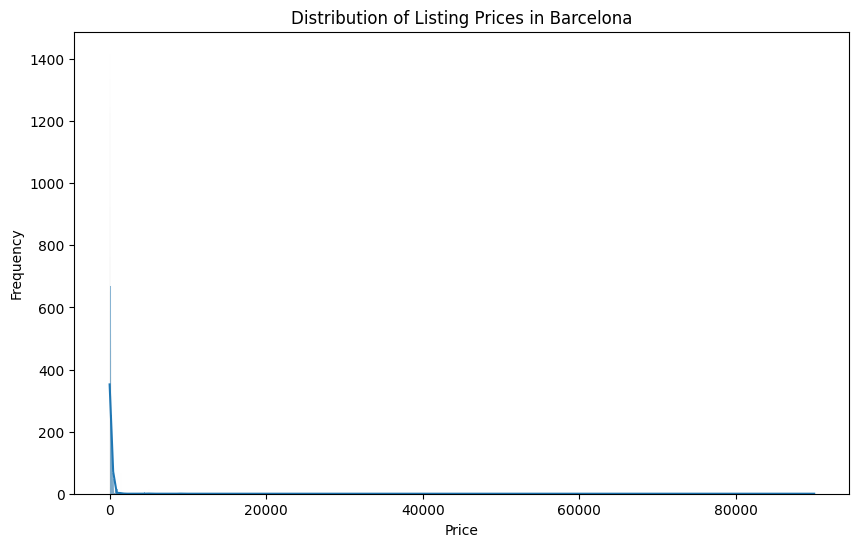

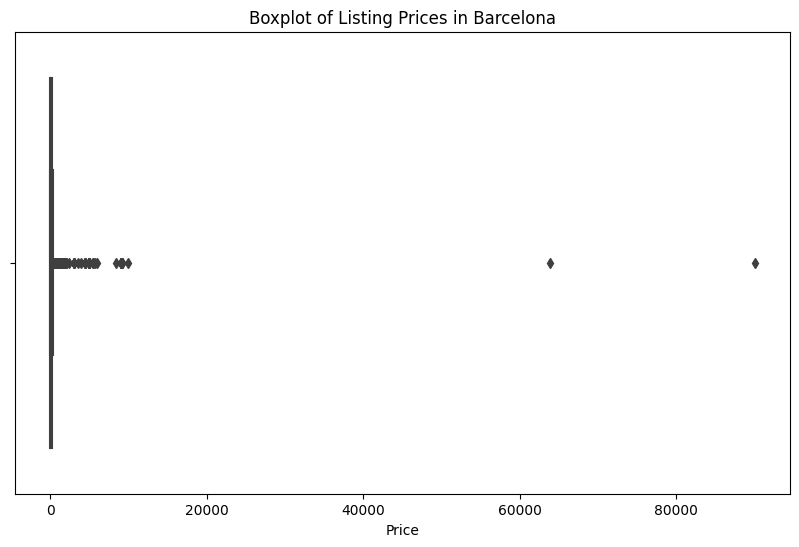

In [ ]:
# Convert 'price' to a numeric value, removing any non-numeric characters like '$'
new_dfs[df_key]['price'] = pd.to_numeric(new_dfs[df_key]['price'].replace('[\$,]', '', regex=True), errors='coerce')

# Histogram of listing prices
plt.figure(figsize=(10, 6))
sns.histplot(new_dfs[df_key]['price'], kde=True)
plt.title('Distribution of Listing Prices in Barcelona')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

# Boxplot of listing prices
plt.figure(figsize=(10, 6))
sns.boxplot(x=new_dfs[df_key]['price'])
plt.title('Boxplot of Listing Prices in Barcelona')
plt.xlabel('Price')
plt.show()

* The histogram of listing prices in Barcelona shows that the vast majority of listings are priced at the lower end of the scale, with a sharp peak close to zero. This indicates that affordable listings dominate the market. However, there are a few listings with extremely high prices, which are likely outliers.

* The boxplot reveals that while the central range of prices (the box) is quite narrow, indicating that most prices are clustered within a small range, there are several outliers far above the upper whisker. These outliers could represent luxury accommodations or could be due to data entry errors.

* For our project, these visuals suggest a skewed distribution of listing prices, with a concentration on the lower end and a few extremely high-value listings. It is important to investigate the outliers to determine whether they are genuine luxury listings or anomalies that should be cleaned from the dataset. Understanding this distribution will be crucial for developing predictive pricing models and making strategic recommendations for pricing strategies. It's also important to normalize or transform the price variable for any modelling to mitigate the skewness and potential influence of outliers.

**Investigate Any Outliers in the Price Data**

In [ ]:
# Calculating IQR to identify outliers
Q1 = new_dfs[df_key]['price'].quantile(0.25)
Q3 = new_dfs[df_key]['price'].quantile(0.75)
IQR = Q3 - Q1
outlier_threshold = Q3 + 1.5 * IQR

# Counting number of outliers
outliers = new_dfs[df_key][new_dfs[df_key]['price'] > outlier_threshold]
print(f"Number of Outliers: {len(outliers)}")
print(f"Outlier Threshold: {outlier_threshold}")

Number of Outliers: 731
Outlier Threshold: 402.5


* After visualizing the price column, and considereing dropping the outliers, since we don't really know what to do with them yet and there quite a few, we at least decided to get rid of the highest ones that are making it difficult to read most of our grapghs properly.

In [ ]:
# Sort the DataFrame by the 'price' column in descending order
sorted_df = new_dfs[df_key].sort_values(by='price', ascending=False)

# Drop the top two rows (the highest price values)
new_dfs[df_key] = sorted_df.iloc[2:]

# Optionally, reset the index if you want a clean, sequential index
new_dfs[df_key].reset_index(drop=True, inplace=True)

**Examine the Relationship Between Price and Other Numerical Variables**

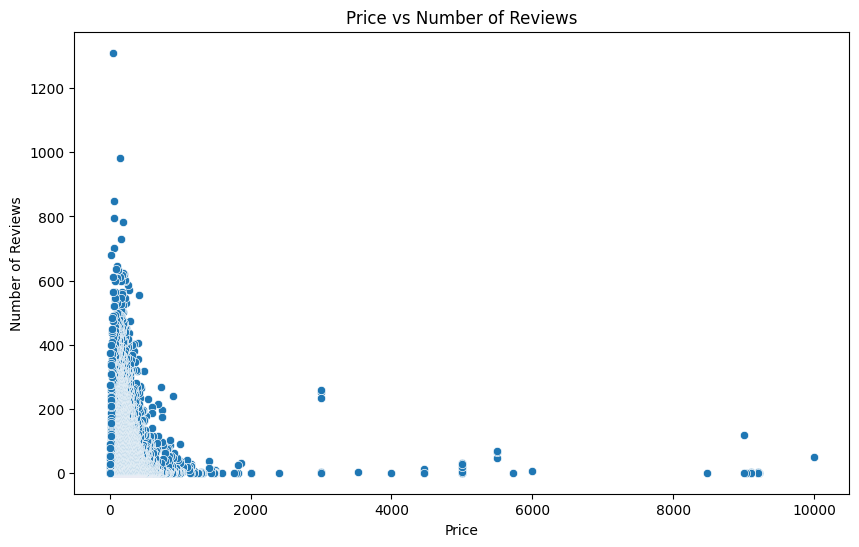

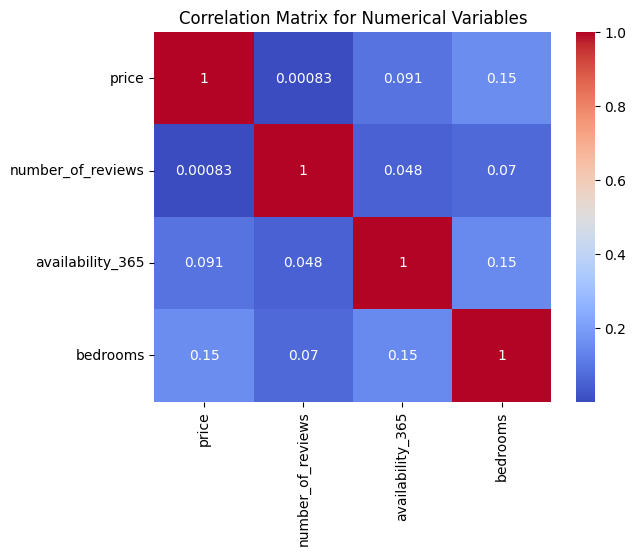

In [ ]:
# Scatter plot between price and numerical variables like 'number_of_reviews'
plt.figure(figsize=(10, 6))
sns.scatterplot(x='price', y='number_of_reviews', data=new_dfs[df_key])
plt.title('Price vs Number of Reviews')
plt.xlabel('Price')
plt.ylabel('Number of Reviews')
plt.show()

# Correlation analysis
numerical_vars = ['price', 'number_of_reviews', 'availability_365', 'bedrooms']  # Include other relevant numerical variables
correlation_matrix = new_dfs[df_key][numerical_vars].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix for Numerical Variables')
plt.show()

* The scatter plot and correlation matrix show a weak relationship between price and the number of reviews, suggesting that higher prices don't necessarily equate to a higher number of reviews. It's also noteworthy that there is a slight positive correlation between price and the number of bedrooms, which is intuitive, as larger properties with more bedrooms are likely to be priced higher. The slight correlation with the number of bedrooms could be used to help determine pricing strategies based on property size.

### Analysis of Location-Based Pricing

**Group the data by neighborhood and calculate average, median, and range of prices**

In [ ]:
# Group the data by neighbourhood and calculate average, median, and range of prices.

neighbourhood_pricing = new_dfs[df_key].groupby('neighbourhood_cleansed')['price'].agg(['mean', 'median', 'max', 'min'])
neighbourhood_pricing['range'] = neighbourhood_pricing['max'] - neighbourhood_pricing['min']
print(neighbourhood_pricing)

                                     mean  median     max    min   range
neighbourhood_cleansed                                                  
Baró de Viver                   53.600000    47.0    86.0   42.0    44.0
Can Baró                       109.428571    67.5   690.0   16.0   674.0
Can Peguera                     39.500000    39.5    49.0   30.0    19.0
Canyelles                      100.000000   100.0   100.0  100.0     0.0
Ciutat Meridiana                49.000000    49.0    49.0   49.0     0.0
...                                   ...     ...     ...    ...     ...
la Vila Olímpica del Poblenou  228.088435   190.0  1494.0   10.0  1484.0
la Vila de Gràcia              141.375000   120.0  4000.0    8.0  3992.0
les Corts                      207.794444   117.5  4455.0   15.0  4440.0
les Roquetes                    48.388889    42.5   133.0   14.0   119.0
les Tres Torres                123.171429   100.0   760.0   18.0   742.0

[73 rows x 5 columns]


* These statistics indicate that some neighborhoods have a wide range of listing prices, which could reflect a diverse housing market with both budget and luxury accommodations. For our project, neighborhoods with large ranges could be of particular interest as they may offer opportunities for price optimization based on various property features and market demand. Additionally, the neighborhoods' mean and median prices can help identify areas that could yield higher revenue potential or require competitive pricing strategies.

**Visualize geographical price variations using maps**

In [ ]:
# Visualize geographical price variations using maps.
# Create a map centered around Barcelona
barcelona_map = folium.Map(location=[new_dfs[df_key]['latitude'].mean(), new_dfs[df_key]['longitude'].mean()], zoom_start=13)

# Add points to the map
for idx, row in new_dfs[df_key].iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=1,
        popup=f"${row['price']}",
        color='blue' if row['price'] <= neighbourhood_pricing['median'][row['neighbourhood_cleansed']] else 'red',
        fill=True
    ).add_to(barcelona_map)

# Display the map
barcelona_map

Output hidden; open in https://colab.research.google.com to view.

* The map visualization indicates that listing prices vary across different neighborhoods. The use of blue and red markers to differentiate prices below and above the median suggests that there may be clusters of higher-priced and lower-priced listings, potentially reflecting the socio-economic diversity across neighborhoods. Proximity to central areas or popular tourist destinations could be influencing these price variations, a common trend in urban accommodation pricing.

* Blue CircleMarkers indicate locations where the price is less than or equal to the median price of that particular neighborhood.

* Red CircleMarkers indicate locations where the price is higher than the median price of the neighborhood.

**Investigate any noticeable trends in pricing based on proximity to key tourist attractions or transport hubs**

<ipython-input-18-9df9696a659b>:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['distance_to_central'] = new_dfs[df_key].apply(calculate_distance, axis=1)


                   neighbourhood_cleansed       price  distance_to_central
51                 la Dreta de l'Eixample  251.357143             0.803871
45                               el Raval  133.061678             0.833794
30                         el Barri Gòtic  157.082061             0.901743
19  Sant Pere, Santa Caterina i la Ribera  135.264737             1.030333
47        l'Antiga Esquerra de l'Eixample  174.220162             1.044364
..                                    ...         ...                  ...
56             la Marina del Prat Vermell   81.722892             7.988806
0                           Baró de Viver   53.600000             8.171961
26  Vallvidrera, el Tibidabo i les Planes  118.020833             8.237564
4                        Ciutat Meridiana   49.000000             8.370389
24                               Vallbona   88.000000             9.865876

[73 rows x 3 columns]


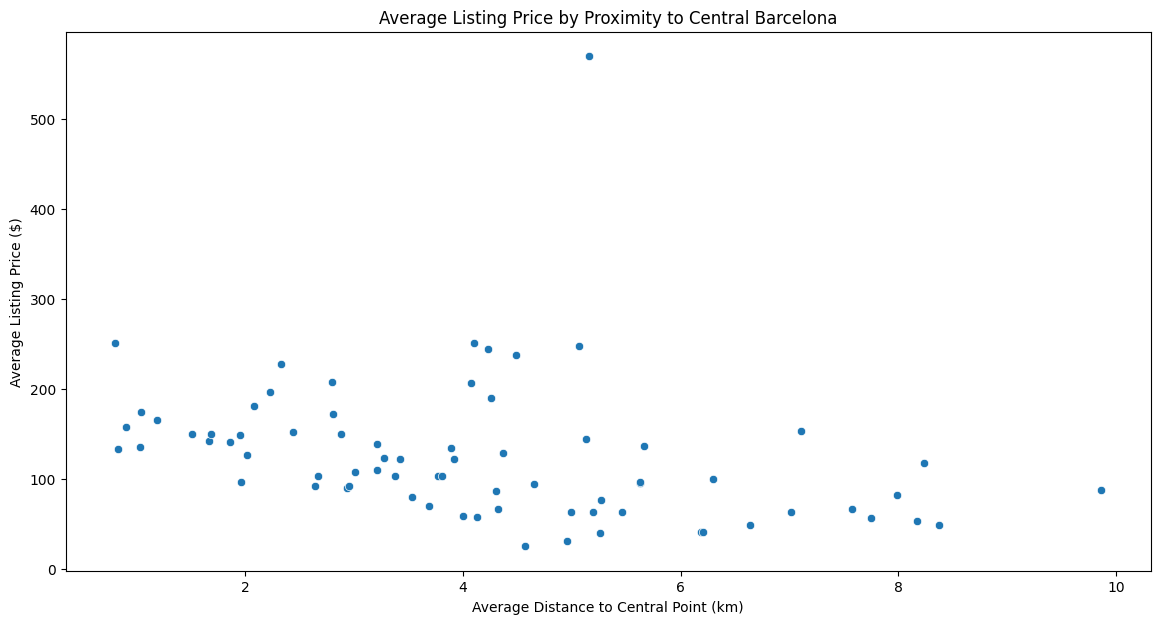

In [ ]:
# Assuming central points for key tourist attractions or transport hubs are the following:
# Let's say these are the coordinates for a central point in Barcelona (like Plaça de Catalunya)
central_point = {'latitude': 41.3874, 'longitude': 2.1686}

# Now, let's calculate the distance of each listing to this central point
def calculate_distance(row):
    listing_coords = (row['latitude'], row['longitude'])
    central_coords = (central_point['latitude'], central_point['longitude'])
    return great_circle(listing_coords, central_coords).km

new_dfs[df_key]['distance_to_central'] = new_dfs[df_key].apply(calculate_distance, axis=1)

# Group by neighborhood and calculate average price and average distance to the central point
pricing_by_proximity = new_dfs[df_key].groupby('neighbourhood_cleansed').agg({'price':'mean', 'distance_to_central':'mean'}).reset_index()

# Now, let's sort by average distance to central point and see the average prices
pricing_by_proximity.sort_values('distance_to_central', inplace=True)
print(pricing_by_proximity)

# Visualize the relationship between average price and average distance to central point
plt.figure(figsize=(14, 7))
sns.scatterplot(data=pricing_by_proximity, x='distance_to_central', y='price')
plt.title('Average Listing Price by Proximity to Central Barcelona')
plt.xlabel('Average Distance to Central Point (km)')
plt.ylabel('Average Listing Price ($)')
plt.show()


* The scatter plot and the output table together illustrate the relationship between the average listing price and the distance from a central point in Barcelona, which is a proxy for proximity to key attractions and transport hubs.

* From the table, it's apparent that there's variability in the average listing price at different distances from the central point. For instance, listings in RAFALELL-VISTABELLA, which are on average about 290 km from the center, have an average price of about 114.65 euros, while those in EL PALMAR at approximately 313 km away have an average price of 79 euros. This suggests that distance to the city center could have an influence on pricing, but it is not the sole determinant since other neighborhoods closer to the center, like BENIFARAIG at roughly 298 km, have lower average prices.

* The scatter plot visually confirms this finding, showing that while there is a general trend of decreasing prices with increasing distance from the central point, there are numerous exceptions. This indicates that while proximity to the center may be a factor in pricing, other neighborhood characteristics and amenities likely also play a significant role in determining the price. For our project, this analysis can help assess the importance of location in pricing strategy.

### Seasonal Analysis of Pricing

**Extract month or season information**

In [ ]:
# Convert 'last_review' to datetime
new_dfs['df_barcelona_new']['last_review'] = pd.to_datetime(new_dfs['df_barcelona_new']['last_review'])

# Extract month and year from 'last_review' to a new column
new_dfs['df_barcelona_new']['review_month'] = new_dfs['df_barcelona_new']['last_review'].dt.month
new_dfs['df_barcelona_new']['review_year'] = new_dfs['df_barcelona_new']['last_review'].dt.year

# Drop rows where review month/year is NaN
seasonal_df = new_dfs['df_barcelona_new'].dropna(subset=['review_month', 'review_year'])

<ipython-input-19-19ab6b43059e>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs['df_barcelona_new']['last_review'] = pd.to_datetime(new_dfs['df_barcelona_new']['last_review'])
<ipython-input-19-19ab6b43059e>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs['df_barcelona_new']['review_month'] = new_dfs['df_barcelona_new']['last_review'].dt.month
<ipython-input-19-19ab6b43059e>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_in

**Analyze average price variations by month or season/Explore any apparent relationships between special events/holidays and pricing**

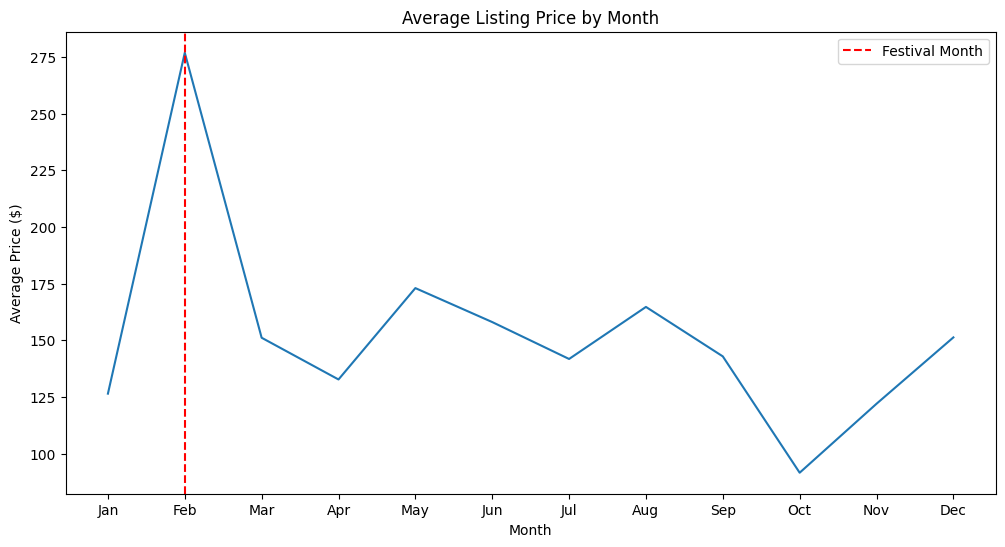

In [ ]:
# We now analyze specific events or holidays
# For example, we now explore February:
monthly_price = seasonal_df.groupby('review_month')['price'].mean().reset_index()
plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_price, x='review_month', y='price')
plt.axvline(x=2, color='red', linestyle='--', label='Festival Month')
plt.title('Average Listing Price by Month')
plt.xlabel('Month')
plt.ylabel('Average Price ($)')
plt.legend()
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.show()

The seasonal analysis graphs show a sharp peak in prices during the February, which could be associated with local festivals or events (as there are small peaks in May, August and December, which may be related to the Summer and Christmas periods), indicating a strong seasonal influence on pricing. This trend is crucial for hosts to consider when setting prices throughout the year to capitalize on high-demand periods.

### Property Characteristics Analysis

**Analyze the effect of property type and size on price**

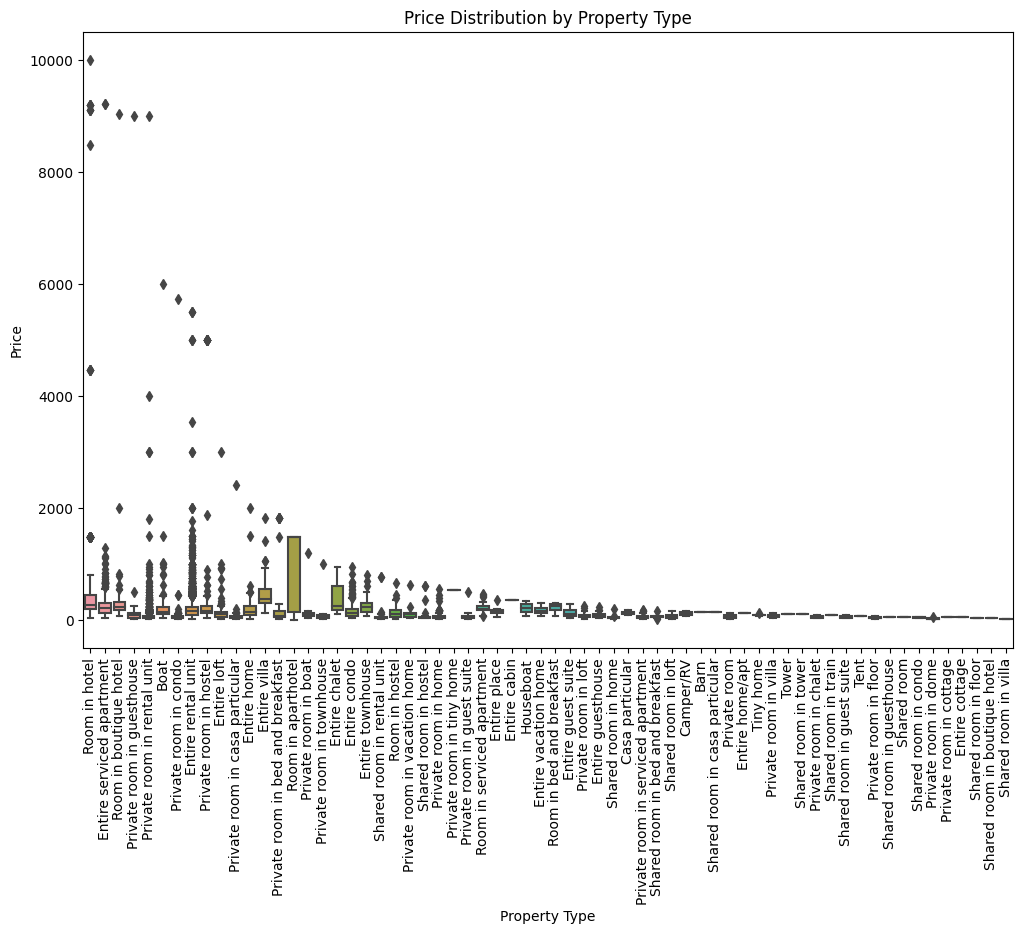

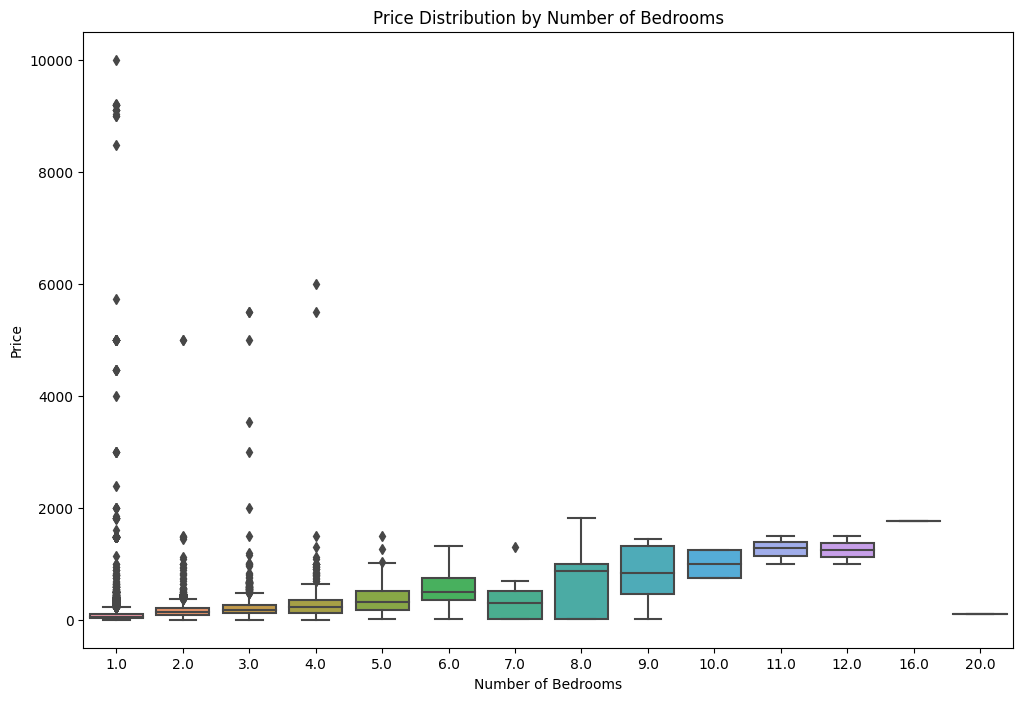

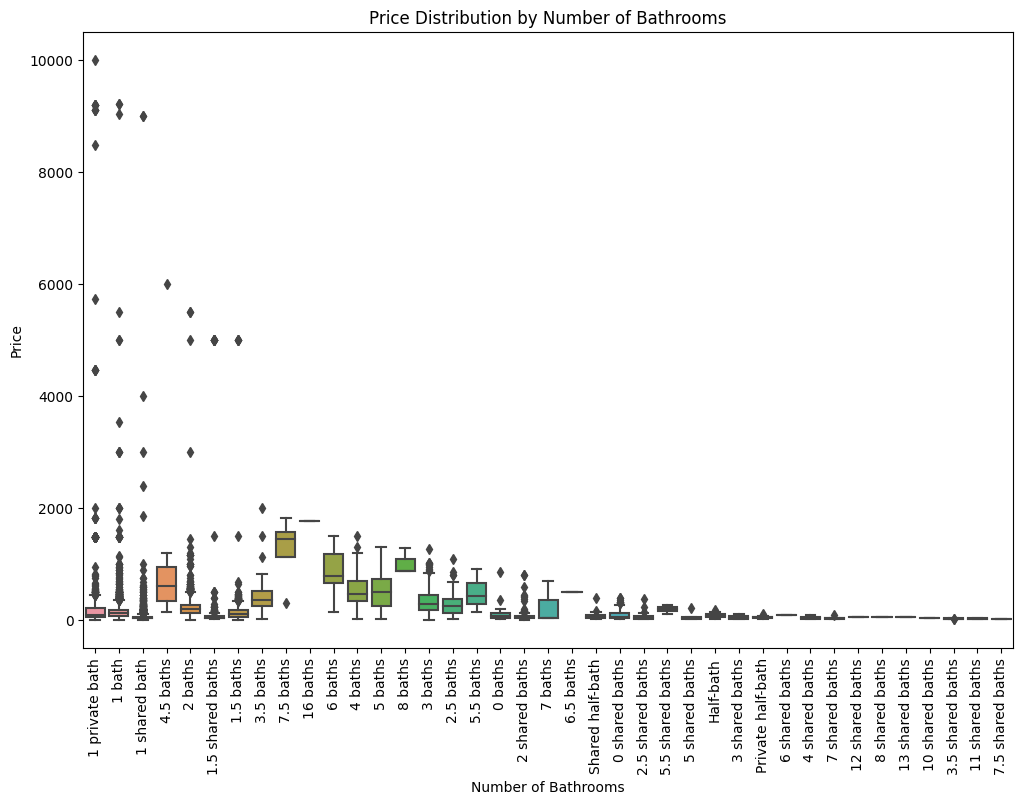

In [ ]:
# Analyze the effect of property type on price
plt.figure(figsize=(12, 8))
sns.boxplot(data=new_dfs[df_key], x='property_type', y='price')
plt.xticks(rotation=90)
plt.title('Price Distribution by Property Type')
plt.xlabel('Property Type')
plt.ylabel('Price')
plt.show()

# Analyze the effect of the number of bedrooms on price
plt.figure(figsize=(12, 8))
sns.boxplot(data=new_dfs[df_key], x='bedrooms', y='price')
plt.title('Price Distribution by Number of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Price')
plt.show()

# Analyze the effect of the number of bathrooms on price
plt.figure(figsize=(12, 8))
sns.boxplot(data=new_dfs[df_key], x='bathrooms_text', y='price')
plt.xticks(rotation=90)
plt.title('Price Distribution by Number of Bathrooms')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Price')
plt.show()

* **Price Distribution by Property Type**:
This boxplot illustrates the distribution of prices across different property types. The spread and median of prices vary significantly by property type, indicating that certain types of properties tend to be priced higher than others. The presence of outliers across many property types suggests that there are some unusually high-priced listings within each category, which could be due to luxury features, exceptional locations, or special amenities.

* **Price Distribution by Number of Bedrooms**:
The boxplot for the price distribution by the number of bedrooms shows a general trend where the median price increases with the number of bedrooms. This trend is expected as larger properties typically command higher prices. However, the number of outliers seems to decrease with more bedrooms, and the spread of prices is wider for properties with fewer bedrooms. This could indicate a more significant variation in the types of smaller properties available, from budget to luxury offerings. For our project, this implies that pricing strategies could be adjusted based on the size of the property, with more nuanced pricing within categories with more significant variability.

* **Price Distribution by Number of Bathrooms**:
In the boxplot showing the price distribution by the number of bathrooms, we again see a variation in median prices based on the number of bathrooms, although it's less pronounced than with bedrooms. There are outliers present, particularly in listings with fewer bathrooms, suggesting that even properties with fewer bathrooms can command high prices, possibly due to other premium features or desirable locations. The variation in price within each category indicates that the number of bathrooms is a factor in pricing, but it may be influenced by other factors as well.

In summary, these visualizations highlight the importance of property characteristics in setting prices. Larger properties with more bedrooms or bathrooms generally have higher median prices, but there is significant price variability within each category. Outliers in each category will need to be assessed to determine if they represent a premium segment of the market or if they should be considered anomalies for the purposes of your analysis.



<ipython-input-22-3e6a9a297b16>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['bathrooms_text'] = df['bathrooms_text'].astype(str)
<ipython-input-22-3e6a9a297b16>:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['bathrooms_number'] = df['bathrooms_text'].apply(extract_bathroom_number)


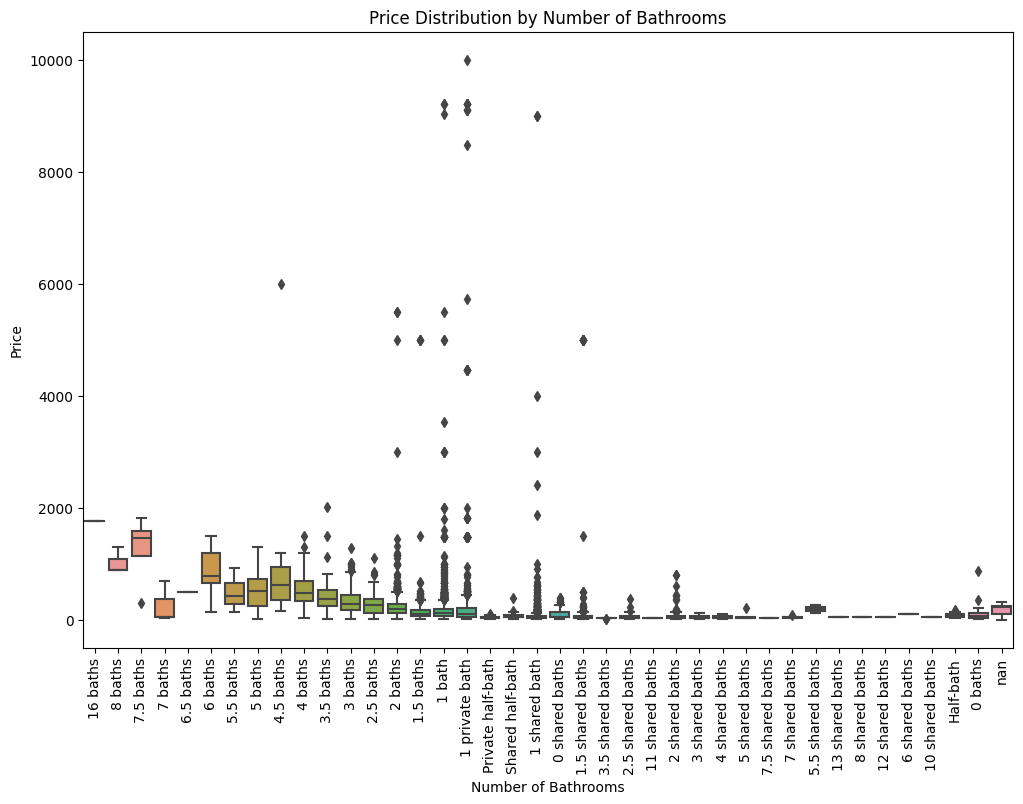

In [ ]:
df = new_dfs[df_key]

# Convert 'bathrooms_text' to a string to ensure consistent processing
df['bathrooms_text'] = df['bathrooms_text'].astype(str)

# Define a custom function to extract numerical value for sorting
def extract_bathroom_number(text):
    # Handle special cases like 'Shared bath', 'Private half-bath', etc.
    if 'half' in text:
        return 0.5
    elif 'shared' in text:
        return 0.01  # Assuming shared is less than half
    elif 'private' in text:
        return 0.75  # Assuming private is more than half but less than 1
    else:
        # Extract the number (assuming it's the first part of the string)
        number = text.split(' ')[0]
        try:
            return float(number)
        except ValueError:
            return 0  # In case of any unconvertible values

# Apply the function to create a new 'bathrooms_number' column for sorting
df['bathrooms_number'] = df['bathrooms_text'].apply(extract_bathroom_number)

# Sort the DataFrame based on this new column
df_sorted = df.sort_values(by='bathrooms_number', ascending=False)

# Now create the plot
plt.figure(figsize=(12, 8))
sns.boxplot(data=df_sorted, x='bathrooms_text', y='price', order=df_sorted['bathrooms_text'].unique())
plt.xticks(rotation=90)
plt.title('Price Distribution by Number of Bathrooms')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Price')
plt.show()

For a better visualisation we sort the bathrooms.

**Utilize violin plots to visualize price distributions by accommodation capacity**

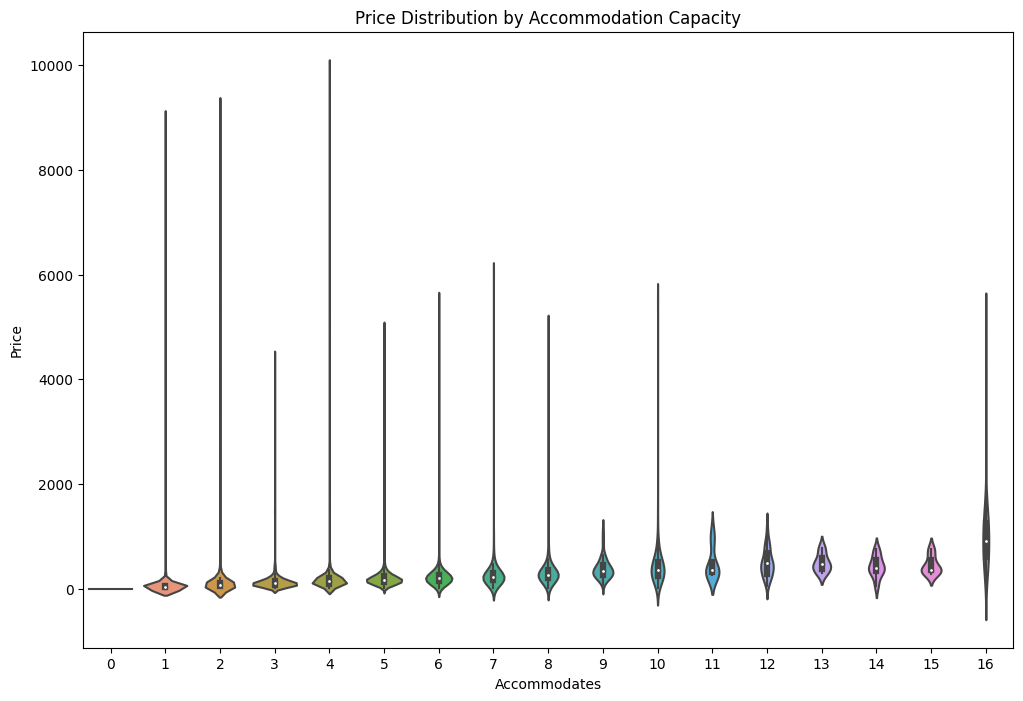

In [ ]:
# Analyze the effect of the number of accommodation capacity on price
plt.figure(figsize=(12, 8))
sns.violinplot(data=new_dfs['df_barcelona_new'], x='accommodates', y='price')
plt.title('Price Distribution by Accommodation Capacity')
plt.xlabel('Accommodates')
plt.ylabel('Price')
plt.show()

* The "Price Distribution by Accommodation Capacity" graph shows how the price of listings varies with the capacity of the accommodation (how many people it can accommodate). The x-axis represents the accommodation capacity, ranging from 1 to 16 people. The y-axis represents the price of the listings. Each violin shape suggests the price frequency for a given capacity, with wider sections indicating higher data concentration. Notably, there's a significant price range for single-person accommodations, with some extreme outliers, while prices for accommodations hosting two to ten people appear more uniform with fewer outliers.

### Host-Related Factors Analysis


**Examine the relationship between host response rate, superhost status, and pricing**


<ipython-input-24-f5302356a83b>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['host_response_rate_num'] = new_dfs[df_key]['host_response_rate'].str.replace('%', '').astype(float) / 100
<ipython-input-24-f5302356a83b>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['superhost'] = new_dfs[df_key]['host_is_superhost'].map({'t': 1, 'f': 0})


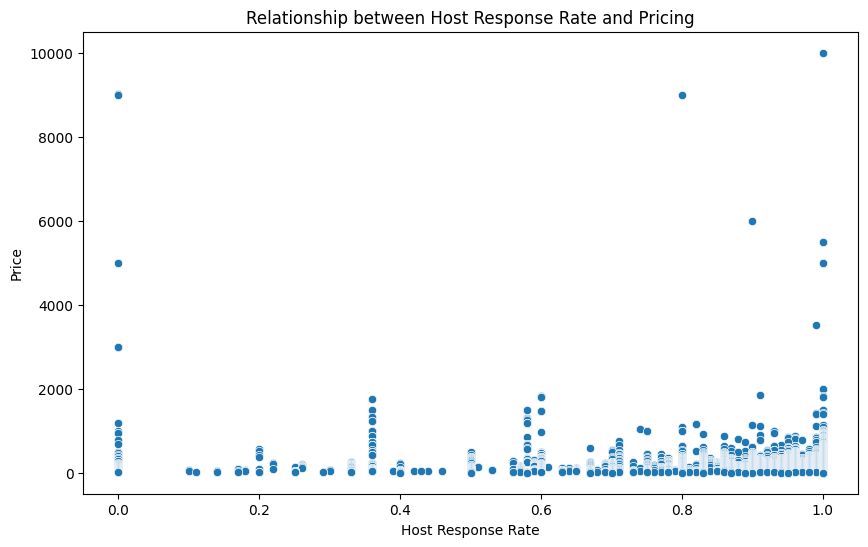

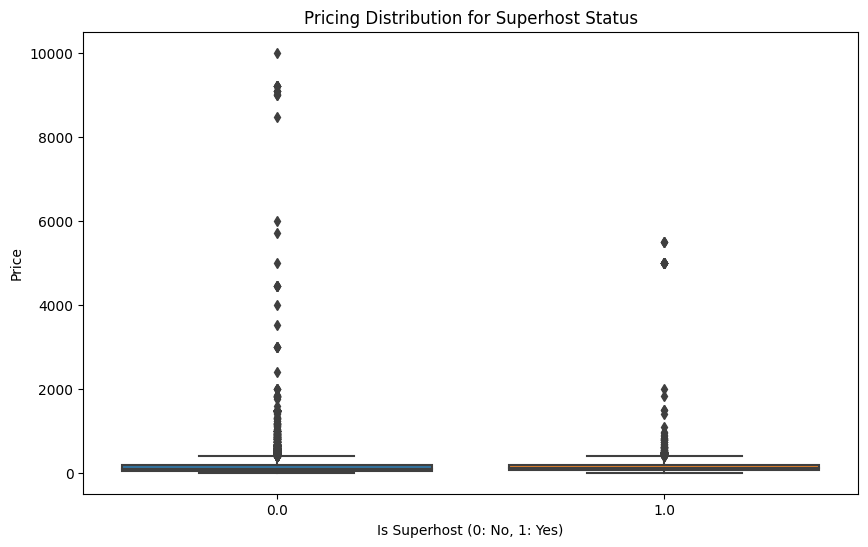

In [ ]:
# Convert host response rate to a numerical value
new_dfs[df_key]['host_response_rate_num'] = new_dfs[df_key]['host_response_rate'].str.replace('%', '').astype(float) / 100

# Convert superhost status to a numerical value
new_dfs[df_key]['superhost'] = new_dfs[df_key]['host_is_superhost'].map({'t': 1, 'f': 0})

# Scatter plot for host response rate and pricing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=new_dfs[df_key], x='host_response_rate_num', y='price')
plt.title('Relationship between Host Response Rate and Pricing')
plt.xlabel('Host Response Rate')
plt.ylabel('Price')
plt.show()

# Boxplot for superhost status and pricing
plt.figure(figsize=(10, 6))
sns.boxplot(data=new_dfs[df_key], x='superhost', y='price')
plt.title('Pricing Distribution for Superhost Status')
plt.xlabel('Is Superhost (0: No, 1: Yes)')
plt.ylabel('Price')
plt.show()

* For the graph "Relationship between Host Response Rate and Pricing," it appears that the majority of listings, regardless of the host's response rate, are clustered at the lower end of the price spectrum. There are some listings at higher price points across various response rates, with a notable outlier at a response rate of 1 (or 100%) that significantly exceeds the general price range. This suggests that while a high response rate may be associated with some high-priced listings, there is no clear or consistent pattern indicating that response rate alone dictates pricing.

* In the "Pricing Distribution for Superhost Status" plot, both superhosts and non-superhosts mostly have listings in the lower price range. However, there are outliers in both categories with significantly higher prices. The plot does not show a distinct difference in pricing between superhosts and non-superhosts, indicating that superhost status does not necessarily lead to higher prices. The majority of listings for both groups are modestly priced, which may suggest that guests are not consistently willing to pay a premium for superhost listings, or that superhosts do not always charge more.

**Investigate if the number of listings per host affects pricing strategies**

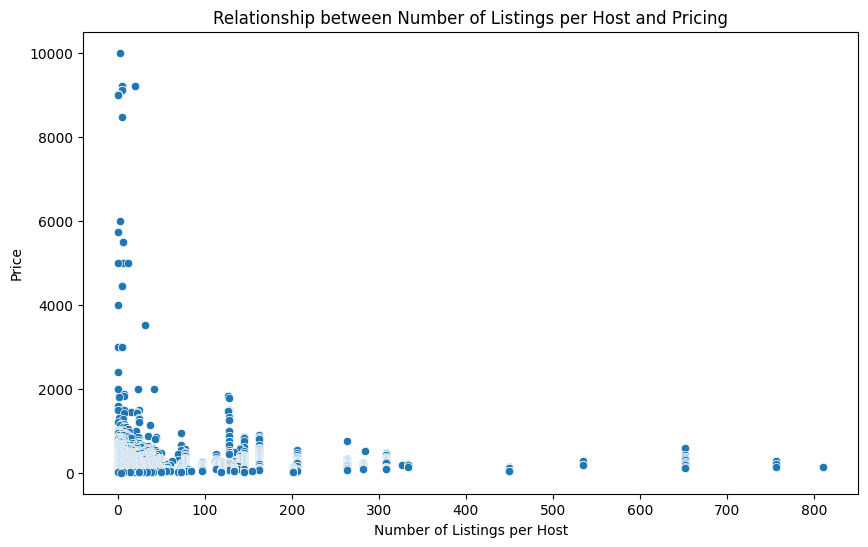

In [ ]:
# Scatter plot for number of listings per host and pricing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=new_dfs[df_key], x='host_listings_count', y='price')
plt.title('Relationship between Number of Listings per Host and Pricing')
plt.xlabel('Number of Listings per Host')
plt.ylabel('Price')
plt.show()

* The plot depicts that hosts with a smaller number of listings tend to have a wide range of prices, with many clustered at the lower end, suggesting that individual or small-scale hosts may offer more competitive or budget-friendly options. There's a significant outlier with a very high price from a host with few listings. As the number of listings per host increases, there's less variability in price, with most prices remaining low, but a few hosts with many listings have some offerings at higher prices. This could indicate that hosts with a larger number of listings may standardize their prices, focusing on volume over premium pricing, although the capacity for higher-priced listings still exists among these hosts.

**Analyze the impact of host ratings and reviews on pricing**

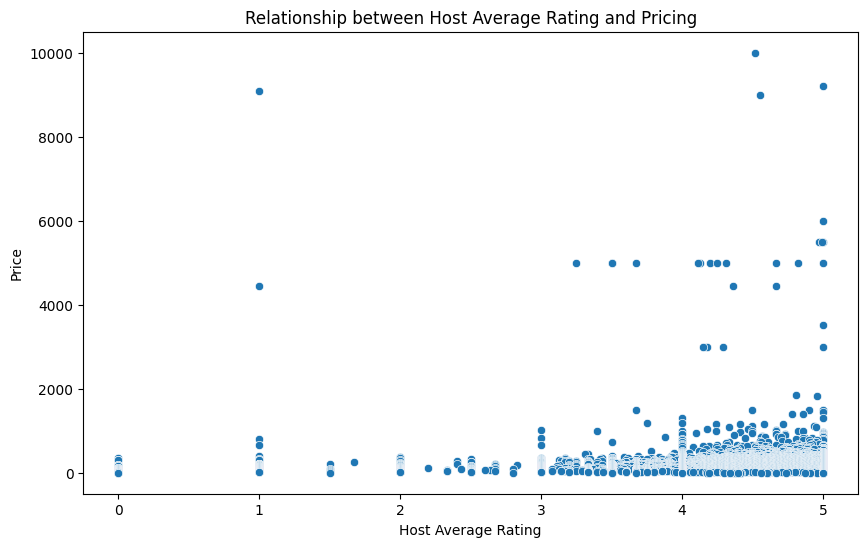

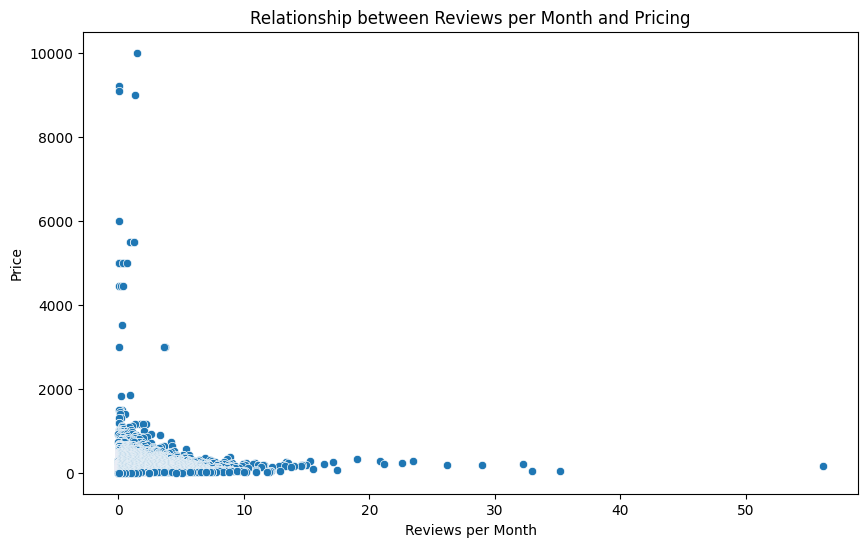

In [ ]:
# Assuming 'review_scores_rating' is the average rating for the host
# Scatter plot for host average rating and pricing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=new_dfs[df_key], x='review_scores_rating', y='price')
plt.title('Relationship between Host Average Rating and Pricing')
plt.xlabel('Host Average Rating')
plt.ylabel('Price')
plt.show()

# Assuming 'reviews_per_month' is an indicator for host reviews frequency
# Scatter plot for reviews per month and pricing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=new_dfs[df_key], x='reviews_per_month', y='price')
plt.title('Relationship between Reviews per Month and Pricing')
plt.xlabel('Reviews per Month')
plt.ylabel('Price')
plt.show()

* The "Relationship between Host Average Rating and Pricing" graph suggests that there is not a strong, clear relationship between a host's average rating and the pricing of their listings. Most listings, regardless of price, have high ratings close to 5, which is common in platforms where ratings tend to be positively skewed. The graph also shows a few listings with very high prices across the rating spectrum, indicating that some high-priced listings have a broad range of host ratings.

* In the "Relationship between Reviews per Month and Pricing" graph, we observe that listings with a wide range of reviews per month are mostly clustered at the lower end of the price spectrum. There are a few listings with a high number of reviews per month that also command higher prices, which could suggest a positive experience or high demand for those listings. However, the majority of data points are concentrated at the lower price range, regardless of the number of reviews per month, indicating that frequent reviews do not necessarily correlate with higher pricing.

### Advanced Statistical Analysis

**Conduct hypothesis testing to check if differences in pricing between various groups are statistically significant**

In [ ]:
# Hypothesis Testing Between Superhosts and non-Superhosts
# Convert price to numeric and remove any non-numeric characters
new_dfs[df_key]['price'] = pd.to_numeric(new_dfs[df_key]['price'].replace('[\$,]', '', regex=True))

# Split the data into two groups: Superhosts and non-Superhosts
superhost_prices = new_dfs[df_key][new_dfs[df_key]['host_is_superhost'] == 't']['price']
non_superhost_prices = new_dfs[df_key][new_dfs[df_key]['host_is_superhost'] == 'f']['price']

# Perform a t-test
t_stat, p_value = ttest_ind(superhost_prices, non_superhost_prices, equal_var=False)
print(f"T-statistic: {t_stat}, P-value: {p_value}")

# If the data is not normally distributed, use Mann-Whitney U test
u_stat, p_value_u = mannwhitneyu(superhost_prices, non_superhost_prices)
print(f"U-statistic: {u_stat}, P-value: {p_value_u}")

T-statistic: 3.1355326767443072, P-value: 0.0017285278567203968
U-statistic: 22472480.0, P-value: 5.3230851695748725e-30


<ipython-input-27-a2451a87c405>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['price'] = pd.to_numeric(new_dfs[df_key]['price'].replace('[\$,]', '', regex=True))


* Based on the hypothesis testing for Superhost status in Airbnb listings, both the T-test and the Mann-Whitney U test indicate that there's a significant difference in pricing between Superhosts and non-Superhosts. The T-test shows a positive T-statistic and a P-value well below 0.05, suggesting that Superhosts tend to charge higher prices. However, given that the data is not normally distributed, the Mann-Whitney U test provides a more reliable result. It shows an extremely low P-value, reinforcing the finding that Superhost status is associated with higher listing prices. This insight is particularly valuable for our project as it suggests that achieving Superhost status might enable hosts to command higher prices, potentially due to the perceived value and trust associated with such listings.



In [ ]:
# Hypothesis Testing Based on Host Identity Verification
# (Works just if the code is loaded completely)
# Convert host_identity_verified to 0s and 1s
new_dfs[df_key]['host_identity_verified'] = new_dfs[df_key]['host_identity_verified'].map({'f': 0, 't': 1})

# Extract prices for verified and non-verified hosts
verified_host_prices = new_dfs[df_key][new_dfs[df_key]['host_identity_verified'] == 1]['price']
non_verified_host_prices = new_dfs[df_key][new_dfs[df_key]['host_identity_verified'] == 0]['price']

# Perform t-test between verified and non-verified host prices
t_stat_verified, p_value_verified = ttest_ind(verified_host_prices, non_verified_host_prices, equal_var=False)
print(f"T-statistic for Host Verification: {t_stat_verified}, P-value: {p_value_verified}")

# Perform Mann-Whitney U test as a non-parametric test
u_stat, p_value_u = mannwhitneyu(verified_host_prices, non_verified_host_prices)
print(f"U-statistic: {u_stat}, P-value: {p_value_u}")

T-statistic for Host Verification: 1.7534520485197287, P-value: 0.0796451413585652
U-statistic: 24211783.5, P-value: 1.2363934868745823e-226


<ipython-input-28-f3cc3c192071>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['host_identity_verified'] = new_dfs[df_key]['host_identity_verified'].map({'f': 0, 't': 1})


* The hypothesis testing on the impact of host verification status on Airbnb listing prices yields mixed results. The T-test, with a P-value slightly above 0.05, suggests that the difference in mean prices between verified and non-verified hosts is not statistically significant. However, the Mann-Whitney U test, which is more appropriate for non-normally distributed data like ours, shows a significant difference in price distributions, indicated by an extremely low P-value. This suggests that while the average prices might not differ markedly between verified and non-verified hosts, the overall range and distribution of prices do vary significantly. In the context of our project, this implies that host verification could influence pricing, potentially through a broader spectrum of pricing strategies among verified hosts, perhaps due to perceived trustworthiness or quality, but this effect is not uniformly seen across all listings.

In [ ]:
# Hypothesis Testing Based on Instant Bookable Feature
# (Works just if the code is loaded completely)
# Convert instant_bookable to 0s and 1s
new_dfs[df_key]['instant_bookable'] = new_dfs[df_key]['instant_bookable'].map({'f': 0, 't': 1})

# Extract prices for listings with and without instant booking
instant_prices = new_dfs[df_key][new_dfs[df_key]['instant_bookable'] == 1]['price']
no_instant_prices = new_dfs[df_key][new_dfs[df_key]['instant_bookable'] == 0]['price']

# Perform t-test between instant bookable and non-instant bookable prices
t_stat_instant, p_value_instant = ttest_ind(instant_prices, no_instant_prices, equal_var=False)
print(f"T-statistic for Instant Booking: {t_stat_instant}, P-value: {p_value_instant}")

# Perform Mann-Whitney U test as a non-parametric test
u_stat, p_value_u = mannwhitneyu(instant_prices, no_instant_prices)
print(f"U-statistic: {u_stat}, P-value: {p_value_u}")

T-statistic for Instant Booking: 12.498562288925681, P-value: 1.1673370659652481e-35
U-statistic: 45852796.0, P-value: 4.4456691106649634e-223


<ipython-input-29-9d252cdcdd9d>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['instant_bookable'] = new_dfs[df_key]['instant_bookable'].map({'f': 0, 't': 1})


* The hypothesis testing on the impact of the instant bookable feature on Airbnb listing prices shows a consistent and significant effect. Both the T-test and the Mann-Whitney U test yield extremely small P-values, indicating a statistically significant difference in pricing between listings with and without this feature. The high positive T-statistic suggests that listings with the instant bookable feature generally command higher prices compared to those without it. This result is particularly notable as the Mann-Whitney U test, suitable for non-normally distributed data like ours, supports this finding. In our project, this implies that the instant bookable feature is perceived as adding value to a listing, leading hosts to set higher prices for such properties. This insight can inform strategic recommendations for hosts considering whether to enable instant booking, highlighting its potential impact on pricing and market competitiveness.

In [ ]:
# Hypothesis Testing Based on Accommodation Size
# Group the data by accommodation size
accommodates_pricing = new_dfs[df_key].groupby('accommodates')['price'].agg(['mean', 'count'])

# Let's compare small (1-2 people) vs. large (more than 2 people) accommodations
small_accommodation_prices = new_dfs[df_key][new_dfs[df_key]['accommodates'] <= 2]['price']
large_accommodation_prices = new_dfs[df_key][new_dfs[df_key]['accommodates'] > 2]['price']

# Perform t-test between small and large accommodation prices
t_stat_accommodates, p_value_accommodates = ttest_ind(small_accommodation_prices, large_accommodation_prices, equal_var=False)
print(f"T-statistic for Accommodation Size: {t_stat_accommodates}, P-value: {p_value_accommodates}")

# Perform Mann-Whitney U test as a non-parametric test
u_stat, p_value_u = mannwhitneyu(small_accommodation_prices, large_accommodation_prices)
print(f"U-statistic: {u_stat}, P-value: {p_value_u}")

T-statistic for Accommodation Size: -15.49445885671362, P-value: 1.085895852848205e-53
U-statistic: 12109513.0, P-value: 0.0


* The hypothesis testing for the impact of accommodation size on Airbnb listing prices demonstrates a significant relationship. Both the T-test and the Mann-Whitney U test, which is more suitable for our non-normally distributed data, indicate that larger accommodations (for more than 2 people) tend to have higher prices compared to smaller ones (for 1-2 people). The negative T-statistic and the extremely small P-values from both tests confirm this difference in pricing is statistically significant. This finding is crucial for our project as it underscores the importance of accommodation size in determining listing prices. It suggests that hosts can price larger properties higher, reflecting the added value of increased space. This insight can guide hosts in pricing strategies, particularly when considering the size of their property, and can be incorporated into predictive pricing models to optimize revenue.

## Malaga

### Initial Data Exploration

In [ ]:
# Analyzing the DataFrame malaga_df

df = malaga_df

num_variables = len(df.columns)
print(f"Number of variables (columns) in malaga_df: {num_variables}")

num_observations = len(df)
print(f"Number of observations (rows) in malaga_df: {num_observations}")

missing_cells = df.isnull().sum()
print("Missing cells per variable (column) in malaga_df:")
print(missing_cells)

duplicate_rows = df[df.duplicated(keep='first')]
num_duplicate_rows = len(duplicate_rows)
print(f"Number of duplicate rows in malaga_df: {num_duplicate_rows}")

has_missing_values = df.isnull().values.any()
print(f"Missing values in the entire malaga_df dataset: {has_missing_values}")

Number of variables (columns) in malaga_df: 18
Number of observations (rows) in malaga_df: 8481
Missing cells per variable (column) in malaga_df:
id                                   0
name                                 0
host_id                              0
host_name                            0
neighbourhood_group               8481
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                       1217
reviews_per_month                 1217
calculated_host_listings_count       0
availability_365                     0
number_of_reviews_ltm                0
license                            171
dtype: int64
Number of duplicate rows in malaga_df: 0
Missing values in the entire malaga_df dataset: True


The malaga_df dataset consists of 18 variables (columns) and 8,481 observations (rows). There are no duplicate rows, indicating unique entries across the dataset. However, it contains missing values in several columns. Notably, the 'neighbourhood_group' column has a significant number of missing values (8,481 out of 8,481), basically all af them, so we could get rid of it. The columns 'last_review' and 'reviews_per_month' also have a substantial number of missing entries (1,217 each), suggesting that many listings haven't been reviewed recently or at all. This could impact the reliability of customer satisfaction or popularity metrics derived from these data. For our project, these gaps might necessitate imputation strategies or a focused analysis on listings with complete data to ensure accuracy.

In [ ]:
# Analyzing the DataFrame malaga2_df

df = malaga2_df

num_variables = len(df.columns)
print(f"Number of variables (columns) in malaga2_df: {num_variables}")

num_observations = len(df)
print(f"Number of observations (rows) in malaga2_df: {num_observations}")

missing_cells = df.isnull().sum()
print("Missing cells per variable (column) in malaga2_df:")
print(missing_cells)

duplicate_rows = df[df.duplicated(keep='first')]
num_duplicate_rows = len(duplicate_rows)
print(f"Number of duplicate rows in malaga2_df: {num_duplicate_rows}")

has_missing_values = df.isnull().values.any()
print(f"Missing values in the entire malaga2_df dataset: {has_missing_values}")

Number of variables (columns) in malaga2_df: 75
Number of observations (rows) in malaga2_df: 8481
Missing cells per variable (column) in malaga2_df:
id                                                 0
listing_url                                        0
scrape_id                                          0
last_scraped                                       0
source                                             0
                                                ... 
calculated_host_listings_count                     0
calculated_host_listings_count_entire_homes        0
calculated_host_listings_count_private_rooms       0
calculated_host_listings_count_shared_rooms        0
reviews_per_month                               1217
Length: 75, dtype: int64
Number of duplicate rows in malaga2_df: 0
Missing values in the entire malaga2_df dataset: True


The malaga2_df dataset is more extensive, with 75 variables and 8,481 observations. Like malaga_df, this dataset also has no duplicate rows, ensuring the uniqueness of the listings. The dataset's complexity is increased due to a higher number of variables, leading to a more comprehensive range of missing values across different columns. The 'reviews_per_month' column again shows a significant number of missing values (1,217), indicating a similar trend as observed in mlaga_df. The large number of variables offers a richer dataset for analysis but also introduces more complexity in handling missing data. For our project, the decision to either simplify the dataset by removing less relevant variables or to address these missing values through imputation or exclusion will be crucial in shaping our analysis approach.

In [ ]:
set1, set2 = set(malaga_df['id']), set(malaga2_df['id'])
duplicates = set1.intersection(set2)
unique_in_df1 = set1.difference(set2)
unique_in_df2 = set2.difference(set1)

print("Duplicates:", duplicates)
print("Unique in DataFrame 1:", unique_in_df1)
print("Unique in DataFrame 2:", unique_in_df2)

Duplicates: {33030145, 1114114, 549015834893451271, 30572553, 51904528, 20447249, 53805075, 39813140, 638273447225327635, 50429980, 45514782, 33488929, 51609649, 637577237677604916, 593984746304208953, 4554815, 50593857, 665628880047505475, 691009344544866380, 689464101006573648, 27197522, 37322834, 40239188, 24445016, 20873305, 35553374, 41451614, 25493601, 13107301, 45351019, 664219726451146861, 23855215, 40403061, 53870718, 229511, 51052681, 43810954, 50135179, 42926220, 23167118, 682446734100103312, 33423505, 53674134, 44368027, 4751521, 46268579, 557891819263918248, 21102762, 628780040028815531, 43745456, 52002995, 39387322, 786626, 561956179319914694, 786638, 52625617, 19398866, 51380436, 31195349, 786648, 786651, 681746655439323355, 786656, 48398560, 48857318, 786663, 48857320, 20087017, 52396267, 53772528, 54362354, 35487987, 1966333, 33292545, 43057416, 620686689728987400, 38699275, 51446028, 49185036, 13009184, 42336549, 38666541, 582631250446713138, 42926388, 31359298, 52920

* The output indicates that there are all duplicate listings between malaga_df and malaga2_df, as evidenced by the empty Unique in Dataframe sets. This suggests that each dataset contains the same listings, which is valuable for a comprehensive analysis meaning that by only using one of them, it this case the malaga2_df we would not only have more data, but the number of properties listed are the same, as we did bith the barcelona_2 dataset, and we will probably do with all of the other datasets it they follow the same trend.

In [ ]:
malaga_dataframes = {'malaga_df': malaga_df, 'malaga2_df': malaga2_df}

for key, df in malaga_dataframes.items():
    print(f"\nThe columns in the dataframe {key} are:\n", df.columns)


The columns in the dataframe malaga_df are:
 Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365', 'number_of_reviews_ltm', 'license'],
      dtype='object')

The columns in the dataframe malaga2_df are:
 Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name',
       'description', 'neighborhood_overview', 'picture_url', 'host_id',
       'host_url', 'host_name', 'host_since', 'host_location', 'host_about',
       'host_response_time', 'host_response_rate', 'host_acceptance_rate',
       'host_is_superhost', 'host_thumbnail_url', 'host_picture_url',
       'host_neighbourhood', 'host_listings_count',
       'host_total_listings_count', 'host_verifications',
       'host_has_profile_pic', 'host_identity_verified', 'neighbourhood',
     

Again, for our model we are using malaga2_df, because our analysis will benefit from a more detailed understanding of each listing. The addidional data will provide more depth and context for our analysis, which could be crucial for developing accurate pricing strategies. We are opting for a streamlined and efficient model by dropping columns such as URLs, detailed host information, and extensive review texts from our Airbnb datasets. Following the approach in the previous city, we decided to drop those columns first and then continue with the EDA.

In [ ]:
new_dfs = {}

df_key = 'df_malaga_new'

columns_to_drop = [
    'id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview',
    'picture_url', 'host_id', 'host_url', 'host_name', 'host_location', 'host_about',
    'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood',
    'calendar_updated', 'has_availability', 'availability_30', 'availability_60',
    'availability_90', 'calendar_last_scraped'
]

new_dfs[df_key] = malaga2_df.drop(columns=columns_to_drop)
pre_df_malaga = new_dfs['df_malaga_new']

print(f"\nRemaining columns in {df_key}: {new_dfs[df_key].columns.tolist()}")



Remaining columns in df_malaga_new: ['host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'first_review', 'last_review', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'license', 'insta

In [ ]:
print("Summary Statistics:\n")
print(new_dfs[df_key].describe())

Summary Statistics:

       host_listings_count  host_total_listings_count  \
count          8481.000000                8481.000000   
mean             69.481547                 120.580946   
std             234.095209                 446.745166   
min               1.000000                   1.000000   
25%               1.000000                   2.000000   
50%               5.000000                   6.000000   
75%              29.000000                  37.000000   
max            1798.000000                3418.000000   

       neighbourhood_group_cleansed     latitude    longitude  accommodates  \
count                           0.0  8481.000000  8481.000000   8481.000000   
mean                            NaN    36.708691    -4.430014      4.078646   
std                             NaN     0.035890     0.042482      2.318774   
min                             NaN    36.620820    -4.604990      1.000000   
25%                             NaN    36.708580    -4.441020      2.0

* The dataset consists of 8,481 listings with a wide range of host listings count (1 to 8,481), indicating a diverse set of hosts from individuals to possibly commercial entities.
The majority of properties accommodate between 2 to 4 people, suggesting a focus on small to medium-sized groups.
The review scores are generally high (above 4.7 on average), which implies a better overall guest satisfaction that the Barcelona.
The bathrooms column lacks data (all values are NaN), which might require imputation or dropping the column for further analysis.
The high standard deviations in host listings count and review scores suggest variability in host activity and guest experiences.

In [ ]:
# Data types of columns
print("\nData Types of Each Column:\n")
print(new_dfs[df_key].dtypes)


Data Types of Each Column:

host_since                                       object
host_response_time                               object
host_response_rate                               object
host_acceptance_rate                             object
host_is_superhost                                object
host_listings_count                               int64
host_total_listings_count                         int64
host_verifications                               object
host_has_profile_pic                             object
host_identity_verified                           object
neighbourhood                                    object
neighbourhood_cleansed                           object
neighbourhood_group_cleansed                    float64
latitude                                        float64
longitude                                       float64
property_type                                    object
room_type                                        object
accommodates       

The dataset contains a mix of numerical (int64, float64) and categorical/object (string) data types, which is typical for accommodation listings.
Some columns that appear to be numeric (like price) are actually stored as objects, indicating the presence of non-numeric characters (e.g., currency symbols) and a need for data cleaning.

In [ ]:
# Check uniqueness
print("\nUniqueness of Each Column:\n")
print(new_dfs[df_key].nunique())


Uniqueness of Each Column:

host_since                                      2198
host_response_time                                 4
host_response_rate                                49
host_acceptance_rate                              80
host_is_superhost                                  2
host_listings_count                              114
host_total_listings_count                        128
host_verifications                                 6
host_has_profile_pic                               2
host_identity_verified                             2
neighbourhood                                     96
neighbourhood_cleansed                            11
neighbourhood_group_cleansed                       0
latitude                                        4307
longitude                                       5186
property_type                                     52
room_type                                          4
accommodates                                      16
bathrooms        

There's a diverse range of unique entries, in most columns.
The significant variety in license, host_verifications, and review_per_month can offer insights into the regulation compliance, host verification process, and popularity of listings.

In [ ]:
# Show first 10 rows
print("\nFirst 10 rows:\n")
print(new_dfs[df_key].head(10))


First 10 rows:

   host_since  host_response_time host_response_rate host_acceptance_rate  \
0  2011-04-15      within an hour               100%                 100%   
1  2011-07-08  within a few hours               100%                  76%   
2  2011-05-23  within a few hours               100%                  88%   
3  2011-09-23      within an hour               100%                  67%   
4  2012-02-02      within an hour               100%                  97%   
5  2012-02-09      within an hour               100%                 100%   
6  2011-12-22        within a day                80%                  75%   
7  2011-11-12                 NaN                NaN                  NaN   
8  2012-04-02        within a day               100%                 100%   
9  2012-04-08      within an hour               100%                  81%   

  host_is_superhost  host_listings_count  host_total_listings_count  \
0                 f                    1                        

The first 10 rows provide a glimpse into the dataset's structure, showing details like host response time, room type, amenities, and review scores.
Some fields such as license and reviews_per_month contain NaN values, indicating missing data that may need addressing.
The variety in instant_bookable, property_type, and room_type reflects the diversity of the listings.

Further observations:

Variability in Host Listings: There's a wide range in the number of listings per host, with some having just one and others managing thousands. This indicates a diversity in host types, from individuals to large-scale operators.

Geographical Spread: The latitude and longitude data points to a geographical spread of properties. The location is a crucial factor in pricing, as different areas have different demand and price points.

Accommodation Capacity: The accommodates, bedrooms, and beds columns show a range of property sizes. Larger properties (more beds and bedrooms) likely command higher prices.

Minimum Nights and Availability: The minimum_nights and availability_365 columns suggest varied booking and availability patterns. This can impact pricing strategy, especially considering peak and off-peak seasons.

Review Scores: High average scores across various review categories indicate generally positive guest experiences. Higher-rated properties might be able to charge more.

Recent Reviews and Review Frequency: The number_of_reviews_l30d and reviews_per_month indicate recent activity and overall review frequency. Properties with more frequent reviews may be more popular and could potentially price higher.

Missing Data in Bathrooms: The consistent absence of data in the bathrooms column across datasets might require data imputation or a decision to exclude this variable from pricing models.

These insights are crucial for developing a dynamic pricing model. They highlight the importance of considering a range of factors - from property size and type, host's portfolio size, geographical location, to guest satisfaction and booking patterns - for setting optimal prices.

### Detailed Analysis of Pricing Variable

Analyze the Distribution of Listing Prices

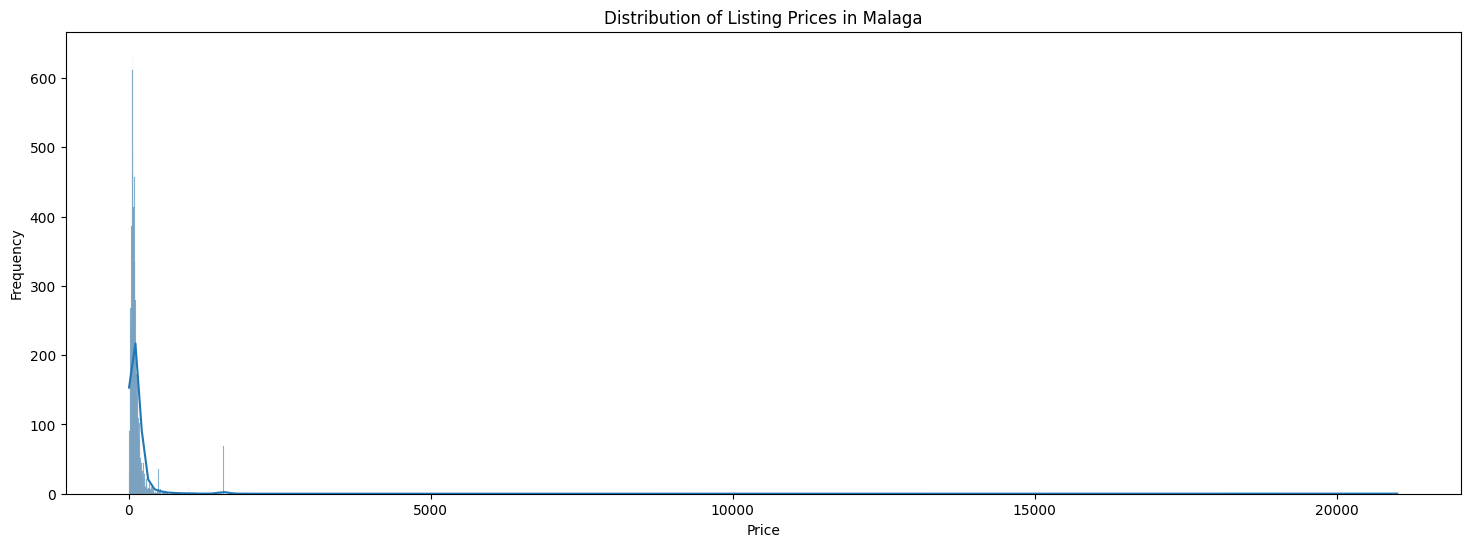

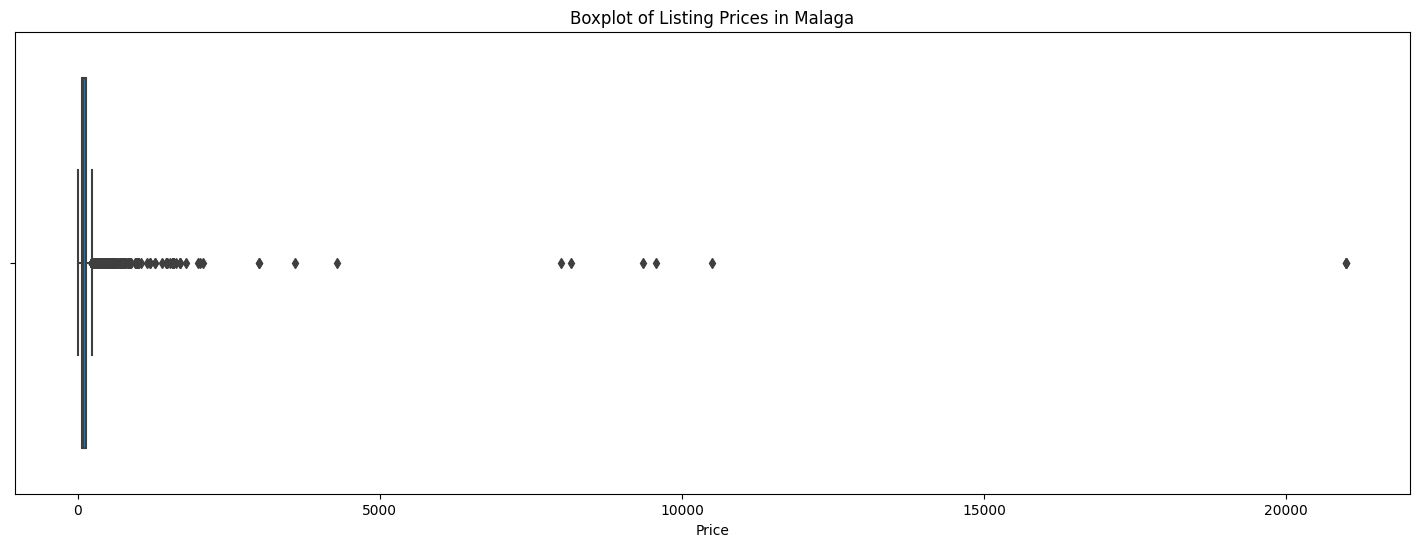

In [ ]:
# Convert 'price' to a numeric value, removing any non-numeric characters like '$'
new_dfs[df_key]['price'] = pd.to_numeric(new_dfs[df_key]['price'].replace('[\$,]', '', regex=True), errors='coerce')

plt.figure(figsize=(18, 6))
sns.histplot(new_dfs[df_key]['price'], kde=True)
plt.title('Distribution of Listing Prices in Malaga')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(18, 6))
sns.boxplot(x=new_dfs[df_key]['price'])
plt.title('Boxplot of Listing Prices in Malaga')
plt.xlabel('Price')
plt.show()

The histogram of listing prices in Malaga shows that the vast majority of listings are priced at the lower end of the scale. This indicates that affordable listings dominate the market. However, there are a few listings with extremely high prices, which are likely outliers or luxuty properties.

The boxplot reveals that while the central range of prices (the box) is quite narrow, indicating that most prices are clustered within a small range, there are several outliers far above the upper whisker. These outliers could represent luxury accommodations or could be due to data entry errors.

For our project, these visuals suggest a skewed distribution of listing prices, with a concentration on the lower end and a few extremely high-value listings. It is important to investigate the outliers to determine whether they are genuine luxury listings or anomalies that should be cleaned from the dataset. Understanding this distribution will be crucial for developing predictive pricing models and making strategic recommendations for pricing strategies. It's also important to normalize or transform the price variable for any modelling to mitigate the skewness and potential influence of outliers.

**Investigate Any Outliers in the Price Data**

In [ ]:
# Calculating IQR to identify outliers
Q1 = new_dfs[df_key]['price'].quantile(0.25)
Q3 = new_dfs[df_key]['price'].quantile(0.75)
IQR = Q3 - Q1
outlier_threshold = Q3 + 1.5 * IQR

# Counting number of outliers
outliers = new_dfs[df_key][new_dfs[df_key]['price'] > outlier_threshold]
print(f"Number of Outliers: {len(outliers)}")
print(f"Outlier Threshold: {outlier_threshold}")

Number of Outliers: 672
Outlier Threshold: 230.5


* After visualizing the price column, and considereing dropping the outliers, since we don't really know what to do with them yet and there quite a few, we at least decided to get rid of the highest ones that are making it difficult to read most of our grapghs properly.

In [ ]:
# Sort the DataFrame by the 'price' column in descending order
sorted_df = new_dfs[df_key].sort_values(by='price', ascending=False)

# Drop the top two rows (the highest price values)
new_dfs[df_key] = sorted_df.iloc[3:]

# Optionally, reset the index if you want a clean, sequential index
new_dfs[df_key].reset_index(drop=True, inplace=True)

**Examine the Relationship Between Price and Other Numerical Variables**

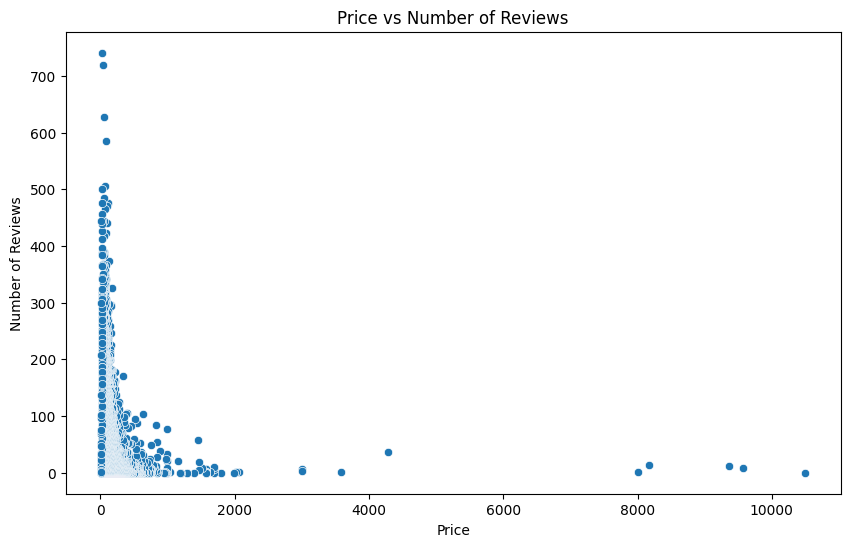

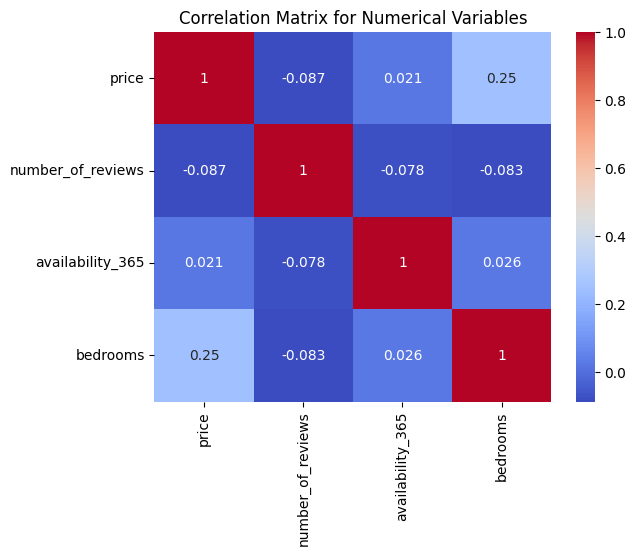

In [ ]:
# Scatter plot between price and numerical variables like 'number_of_reviews'
plt.figure(figsize=(10, 6))
sns.scatterplot(x='price', y='number_of_reviews', data=new_dfs[df_key])
plt.title('Price vs Number of Reviews')
plt.xlabel('Price')
plt.ylabel('Number of Reviews')
plt.show()

# Correlation analysis
numerical_vars = ['price', 'number_of_reviews', 'availability_365', 'bedrooms']
correlation_matrix = new_dfs[df_key][numerical_vars].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix for Numerical Variables')
plt.show()

* The scatter plot and correlation matrix show a weak relationship between price and the number of reviews, suggesting that higher prices don't necessarily equate to a higher number of reviews. It's also noteworthy that there is a slight positive correlation between price and the number of bedrooms, which is intuitive, as larger properties with more bedrooms are likely to be priced higher. The slight correlation with the number of bedrooms could be used to help determine pricing strategies based on property size.

### Analysis of Location-Based Pricing

**Group the data by neighborhood and calculate average, median, and range of prices**

In [ ]:
neighbourhood_pricing = new_dfs[df_key].groupby('neighbourhood_cleansed')['price'].agg(['mean', 'median', 'max', 'min'])
neighbourhood_pricing['range'] = neighbourhood_pricing['max'] - neighbourhood_pricing['min']
print(neighbourhood_pricing)

                              mean  median      max   min    range
neighbourhood_cleansed                                            
Bailen-Miraflores        64.762195    60.0    400.0  12.0    388.0
Campanillas             180.152778   164.5    453.0  34.0    419.0
Carretera de Cadiz       95.391304    79.0    617.0  12.0    605.0
Centro                  126.458540    93.0  10500.0  13.0  10487.0
Churriana               126.123016    81.0   8167.0  15.0   8152.0
Ciudad Jardin           105.065574    75.0    370.0  16.0    354.0
Cruz De Humilladero     268.661818    65.0   1686.0  15.0   1671.0
Este                    141.339499    94.0   2018.0  12.0   2006.0
Palma-Palmilla           88.396226    50.0    500.0   9.0    491.0
Puerto de la Torre      162.838710   104.0    699.0  15.0    684.0
Teatinos-Universidad    121.846154    88.5   1000.0  17.0    983.0


* These statistics indicate that some neighborhoods have a wide range of listing prices, which could reflect a diverse housing market with both budget and luxury accommodations. For our project, neighborhoods with large ranges could be of particular interest as they may offer opportunities for price optimization based on various property features and market demand. Additionally, the neighborhoods' mean and median prices can help identify areas that could yield higher revenue potential or require competitive pricing strategies.

**Visualize geographical price variations using maps**

In [ ]:
# Visualize geographical price variations using maps.
# Create a map centered around Malaga
malaga_map = folium.Map(location=[new_dfs[df_key]['latitude'].mean(), new_dfs[df_key]['longitude'].mean()], zoom_start=13)

# Add points to the map
for idx, row in new_dfs[df_key].iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=3,
        popup=f"${row['price']}",
        color='blue' if row['price'] <= neighbourhood_pricing['median'][row['neighbourhood_cleansed']] else 'red',
        fill=True
    ).add_to(malaga_map)

# Display the map
malaga_map

Output hidden; open in https://colab.research.google.com to view.

* The map visualization indicates that listing prices vary across different neighborhoods. The use of blue and red markers to differentiate prices below and above the median suggests that there may be clusters of higher-priced and lower-priced listings, potentially reflecting the socio-economic diversity across neighborhoods. Proximity to central areas or popular tourist destinations could be influencing these price variations, a common trend in urban accommodation pricing.

* Blue CircleMarkers indicate locations where the price is less than or equal to the median price of that particular neighborhood.

* Red CircleMarkers indicate locations where the price is higher than the median price of the neighborhood.

**Investigate any noticeable trends in pricing based on proximity to key tourist attractions or transport hubs**

<ipython-input-46-f132718aea88>:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['distance_to_central'] = new_dfs[df_key].apply(calculate_distance, axis=1)


   neighbourhood_cleansed       price  distance_to_central
3                  Centro  126.458540             0.676228
0       Bailen-Miraflores   64.762195             1.683090
6     Cruz De Humilladero  268.661818             2.626373
2      Carretera de Cadiz   95.391304             2.773998
8          Palma-Palmilla   88.396226             4.220943
10   Teatinos-Universidad  121.846154             4.566773
5           Ciudad Jardin  105.065574             6.166825
9      Puerto de la Torre  162.838710             6.517570
7                    Este  141.339499             6.799542
4               Churriana  126.123016            11.904754
1             Campanillas  180.152778            13.242752


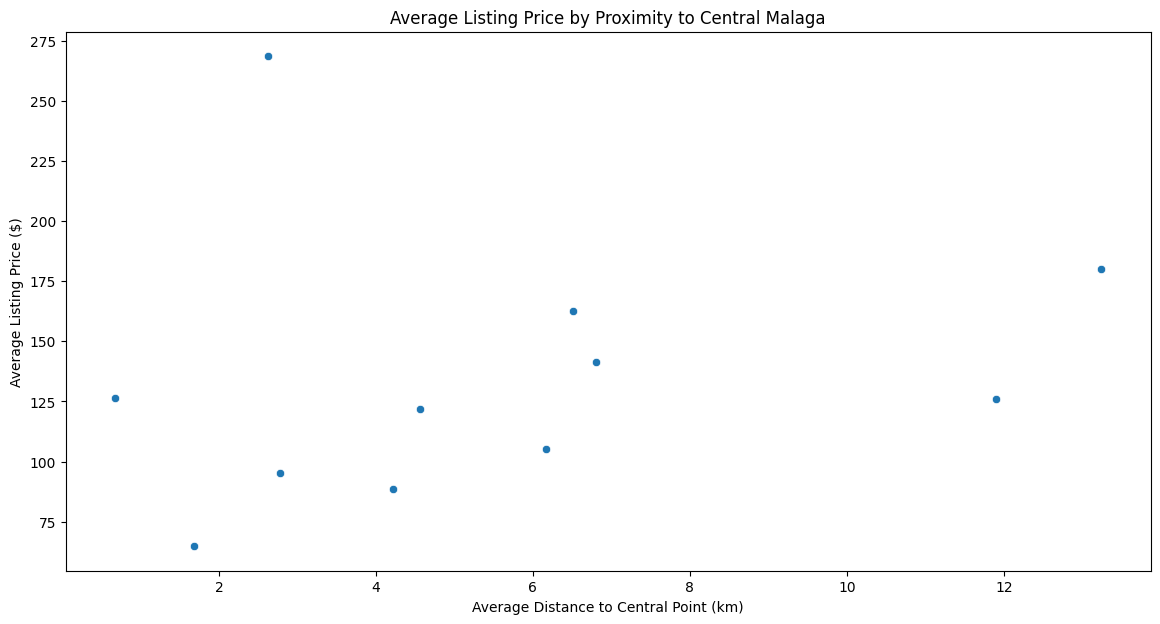

In [ ]:
# Assuming central points for key tourist attractions or transport hubs are the following:
# Let's say these are the coordinates for a central point in Malaga.
central_point = {'latitude': 36.719444, 'longitude': -4.420000}

# Now, let's calculate the distance of each listing to this central point
def calculate_distance(row):
    listing_coords = (row['latitude'], row['longitude'])
    central_coords = (central_point['latitude'], central_point['longitude'])
    return great_circle(listing_coords, central_coords).km

new_dfs[df_key]['distance_to_central'] = new_dfs[df_key].apply(calculate_distance, axis=1)

# Group by neighborhood and calculate average price and average distance to the central point
pricing_by_proximity = new_dfs[df_key].groupby('neighbourhood_cleansed').agg({'price':'mean', 'distance_to_central':'mean'}).reset_index()

# Now, let's sort by average distance to central point and see the average prices
pricing_by_proximity.sort_values('distance_to_central', inplace=True)
print(pricing_by_proximity)

# Visualize the relationship between average price and average distance to central point
plt.figure(figsize=(14, 7))
sns.scatterplot(data=pricing_by_proximity, x='distance_to_central', y='price')
plt.title('Average Listing Price by Proximity to Central Malaga')
plt.xlabel('Average Distance to Central Point (km)')
plt.ylabel('Average Listing Price ($)')
plt.show()


* The scatter plot and the output table together illustrate the relationship between the average listing price and the distance from a central point in Barcelona, which is a proxy for proximity to key attractions and transport hubs.

* From the table,we can visualize a direct slight direct correlation between the proximity to the center of Málaga, and the average listing price, being more expensive the porperties the futher away in most cases.

### Seasonal Analysis of Pricing

**Extract month or season information**

In [ ]:
# Convert 'last_review' to datetime
new_dfs['df_malaga_new']['last_review'] = pd.to_datetime(new_dfs['df_malaga_new']['last_review'])

# Extract month and year from 'last_review' to a new column
new_dfs['df_malaga_new']['review_month'] = new_dfs['df_malaga_new']['last_review'].dt.month
new_dfs['df_malaga_new']['review_year'] = new_dfs['df_malaga_new']['last_review'].dt.year

# Drop rows where review month/year is NaN
seasonal_df = new_dfs['df_malaga_new'].dropna(subset=['review_month', 'review_year'])

<ipython-input-47-27808e914c7f>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs['df_malaga_new']['last_review'] = pd.to_datetime(new_dfs['df_malaga_new']['last_review'])
<ipython-input-47-27808e914c7f>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs['df_malaga_new']['review_month'] = new_dfs['df_malaga_new']['last_review'].dt.month
<ipython-input-47-27808e914c7f>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_in

**Analyze average price variations by month or season/Explore any apparent relationships between special events/holidays and pricing**

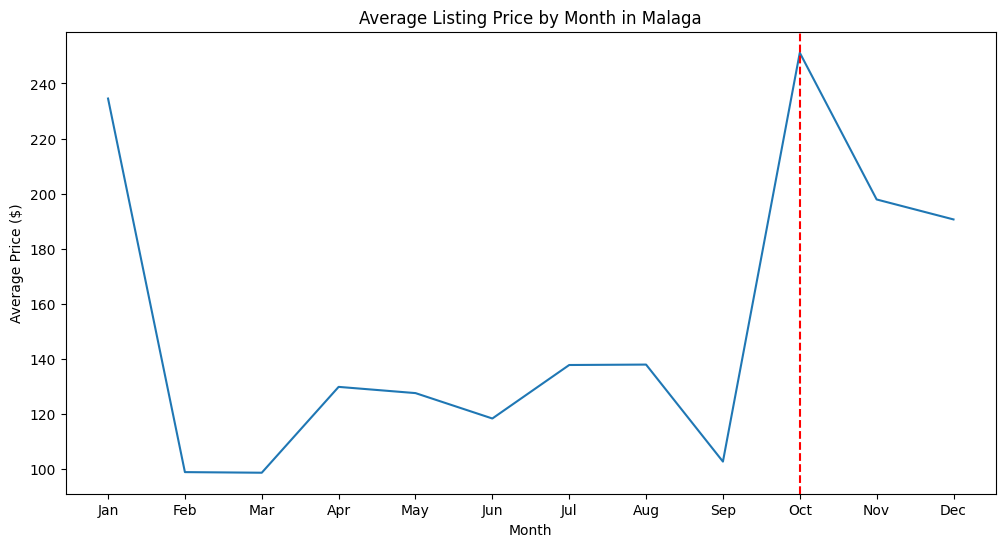

In [ ]:
# Group by month and calculate average price
monthly_price = seasonal_df.groupby('review_month')['price'].mean().reset_index()

# Plot the average price by month
plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_price, x='review_month', y='price')
plt.axvline(x=10, color='red', linestyle='--', label='Highest Month')
plt.title('Average Listing Price by Month in Malaga')
plt.xlabel('Month')
plt.ylabel('Average Price ($)')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.show()

The seasonal analysis graphs show a sharp peak in prices during autumn and winter months, with a particular spike in October, which could be associated with the months people from northern countries come to visit Malaga because of the nice weather in this area during this times of the year.

### Property Characteristics Analysis

**Analyze the effect of property type and size on price**

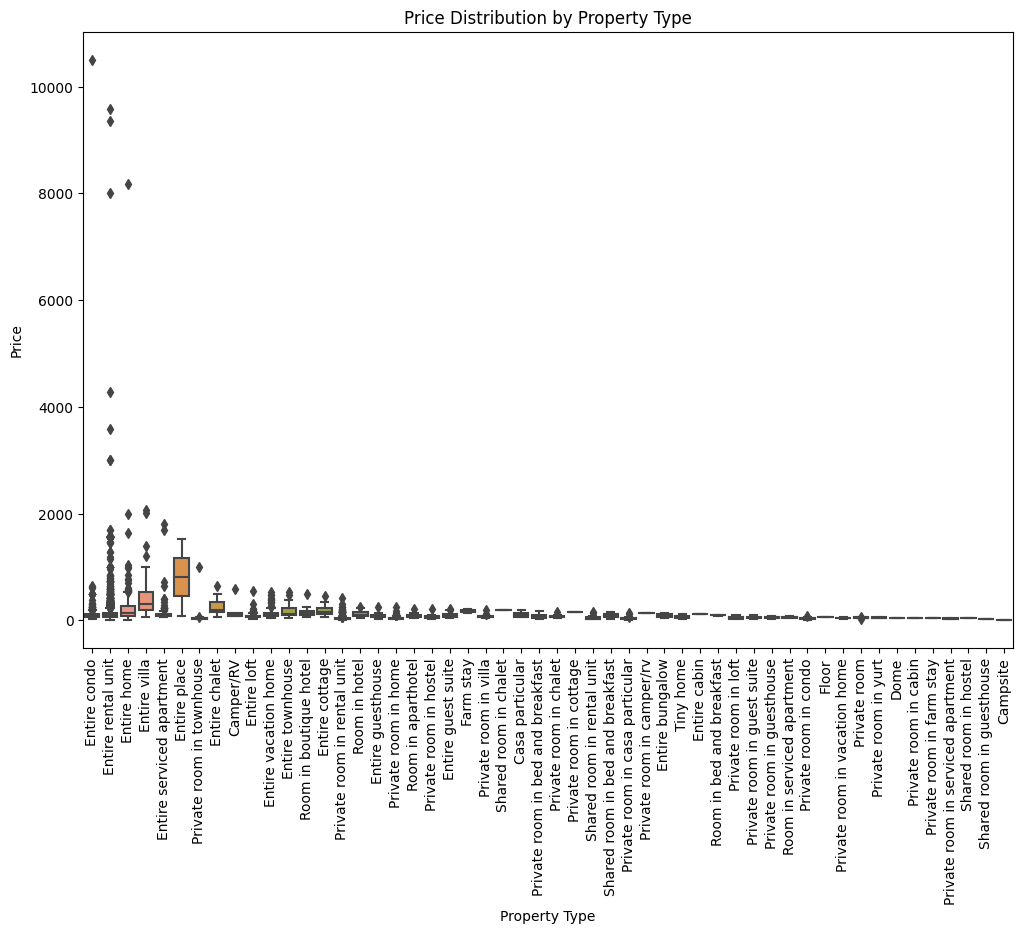

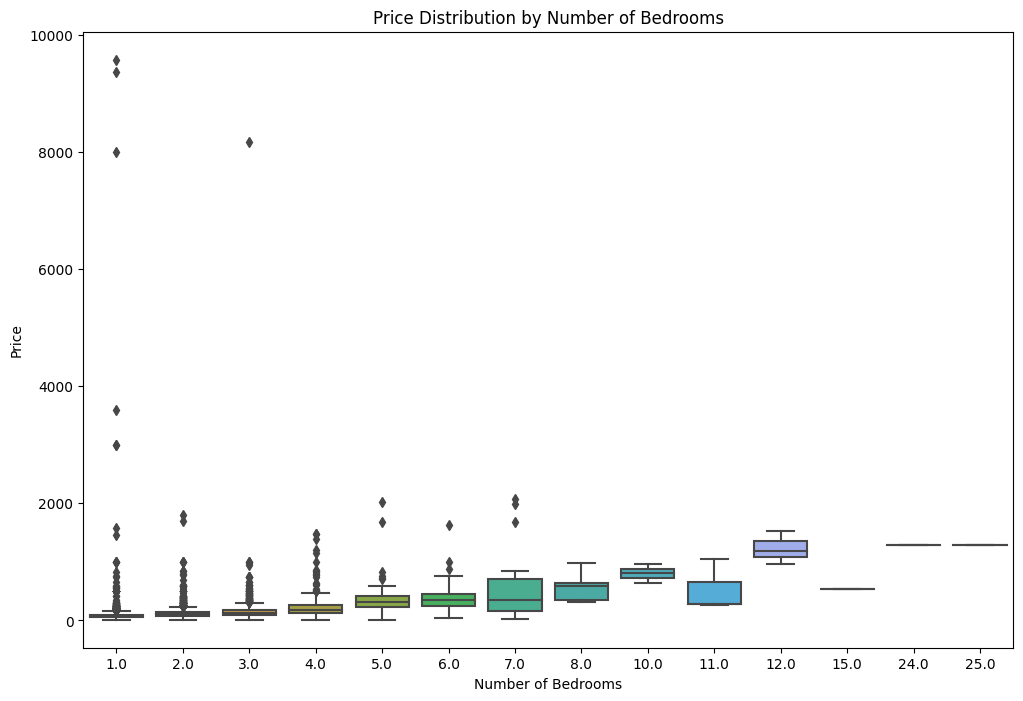

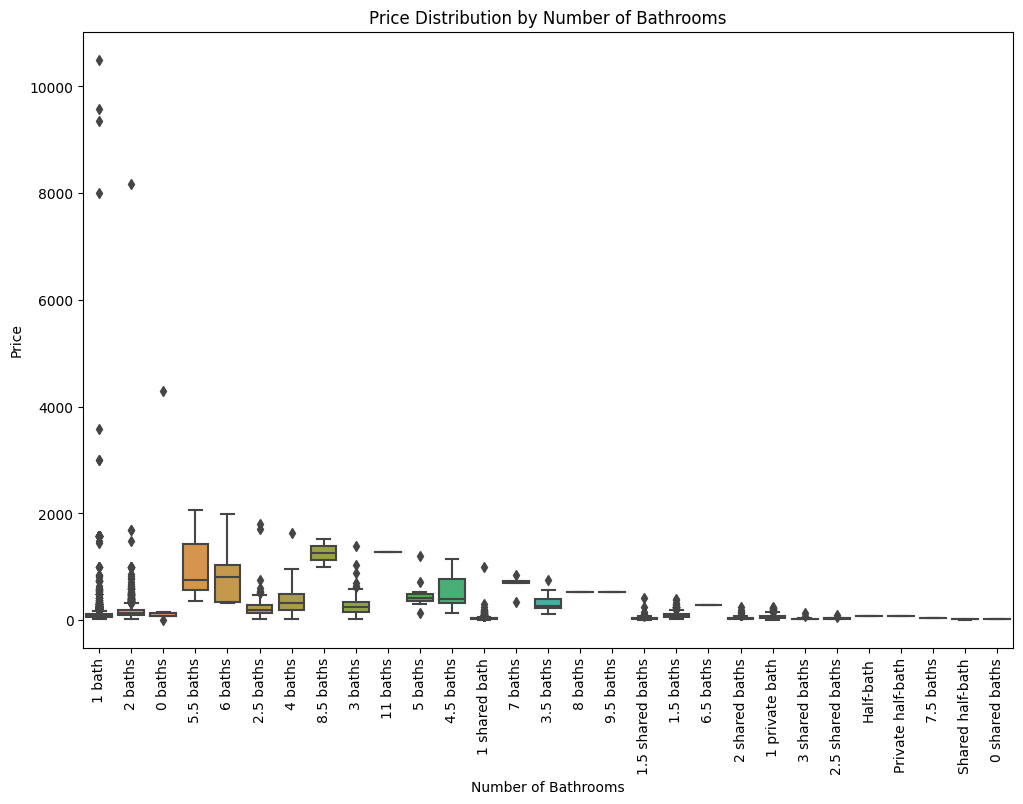

In [ ]:
# Analyze the effect of property type on price
plt.figure(figsize=(12, 8))
sns.boxplot(data=new_dfs[df_key], x='property_type', y='price')
plt.xticks(rotation=90)
plt.title('Price Distribution by Property Type')
plt.xlabel('Property Type')
plt.ylabel('Price')
plt.show()

# Analyze the effect of the number of bedrooms on price
plt.figure(figsize=(12, 8))
sns.boxplot(data=new_dfs[df_key], x='bedrooms', y='price')
plt.title('Price Distribution by Number of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Price')
plt.show()

# Analyze the effect of the number of bathrooms on price
plt.figure(figsize=(12, 8))
sns.boxplot(data=new_dfs[df_key], x='bathrooms_text', y='price')
plt.xticks(rotation=90)
plt.title('Price Distribution by Number of Bathrooms')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Price')
plt.show()

* **Price Distribution by Property Type**:
This boxplot illustrates the distribution of prices across different property types. The spread and median of prices vary significantly by property type, indicating that certain types of properties tend to be priced higher than others. The presence of outliers across many property types suggests that there are some unusually high-priced listings within each category, which could be due to luxury features, exceptional locations, or special amenities.

* **Price Distribution by Number of Bedrooms**:
The boxplot for the price distribution by the number of bedrooms shows a general trend where the median price increases with the number of bedrooms. This trend is expected as larger properties typically command higher prices. However, the number of outliers seems to decrease with more bedrooms, and the spread of prices is wider for properties with fewer bedrooms. This could indicate a more significant variation in the types of smaller properties available, from budget to luxury offerings. For our project, this implies that pricing strategies could be adjusted based on the size of the property, with more nuanced pricing within categories with more significant variability.

* **Price Distribution by Number of Bathrooms**:
In the boxplot showing the price distribution by the number of bathrooms, we again see a variation in median prices based on the number of bathrooms, although it's less pronounced than with bedrooms. There are outliers present, particularly in listings with fewer bathrooms, suggesting that even properties with fewer bathrooms can command high prices, possibly due to other premium features or desirable locations. The variation in price within each category indicates that the number of bathrooms is a factor in pricing, but it may be influenced by other factors as well.

In summary, these visualizations highlight the importance of property characteristics in setting prices. Larger properties with more bedrooms or bathrooms generally have higher median prices, but there is significant price variability within each category. Outliers in each category will need to be assessed to determine if they represent a premium segment of the market or if they should be considered anomalies for the purposes of your analysis.



<ipython-input-50-3e6a9a297b16>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['bathrooms_text'] = df['bathrooms_text'].astype(str)
<ipython-input-50-3e6a9a297b16>:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['bathrooms_number'] = df['bathrooms_text'].apply(extract_bathroom_number)


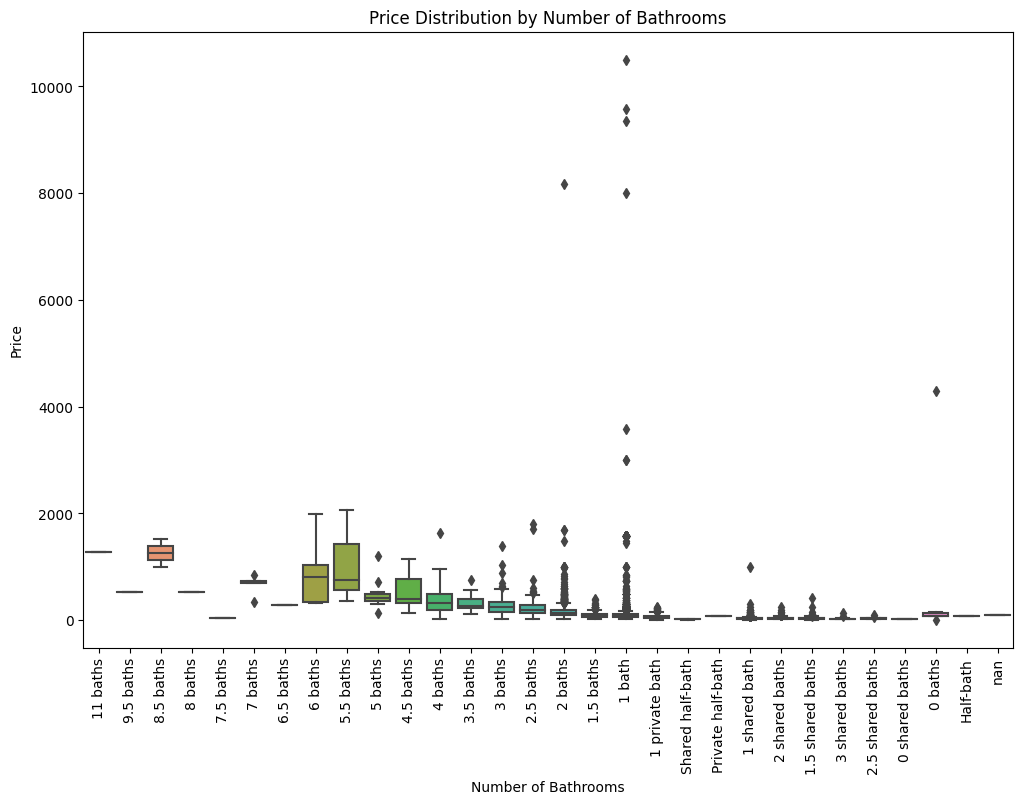

In [ ]:
df = new_dfs[df_key]

# Convert 'bathrooms_text' to a string to ensure consistent processing
df['bathrooms_text'] = df['bathrooms_text'].astype(str)

# Define a custom function to extract numerical value for sorting
def extract_bathroom_number(text):
    # Handle special cases like 'Shared bath', 'Private half-bath', etc.
    if 'half' in text:
        return 0.5
    elif 'shared' in text:
        return 0.01  # Assuming shared is less than half
    elif 'private' in text:
        return 0.75  # Assuming private is more than half but less than 1
    else:
        # Extract the number (assuming it's the first part of the string)
        number = text.split(' ')[0]
        try:
            return float(number)
        except ValueError:
            return 0  # In case of any unconvertible values

# Apply the function to create a new 'bathrooms_number' column for sorting
df['bathrooms_number'] = df['bathrooms_text'].apply(extract_bathroom_number)

# Sort the DataFrame based on this new column
df_sorted = df.sort_values(by='bathrooms_number', ascending=False)

# Now create the plot
plt.figure(figsize=(12, 8))
sns.boxplot(data=df_sorted, x='bathrooms_text', y='price', order=df_sorted['bathrooms_text'].unique())
plt.xticks(rotation=90)
plt.title('Price Distribution by Number of Bathrooms')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Price')
plt.show()

For a better visualisation we sort the bathrooms.

**Utilize violin plots to visualize price distributions by accommodation capacity**

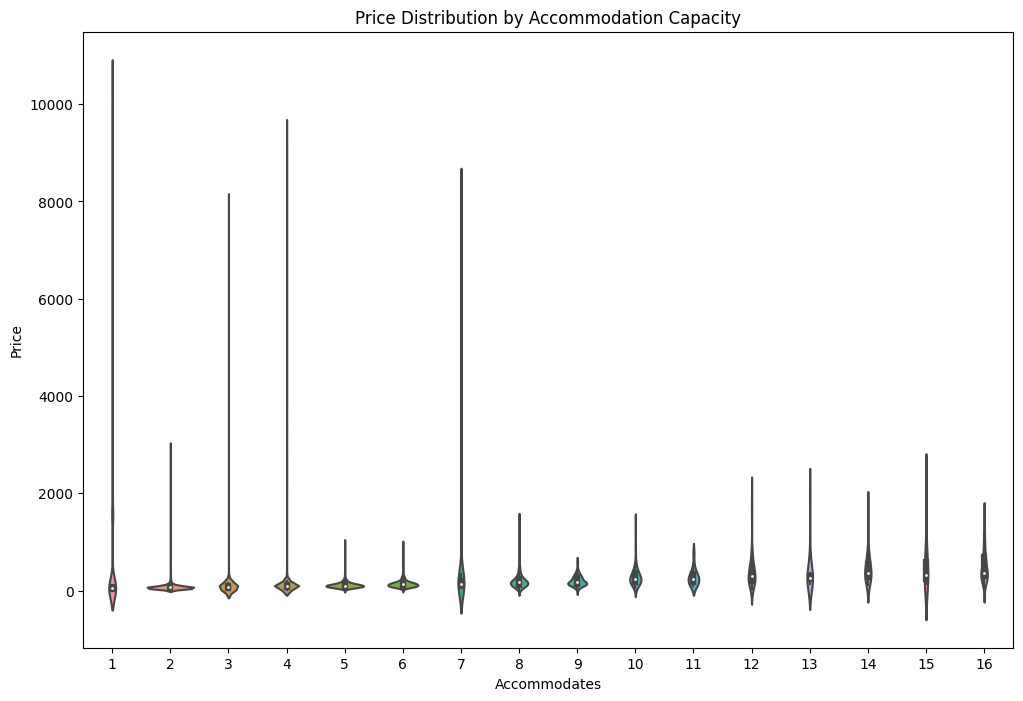

In [ ]:
# Analyze the effect of the number of accommodation capacity on price
plt.figure(figsize=(12, 8))
sns.violinplot(data=new_dfs['df_malaga_new'], x='accommodates', y='price')
plt.title('Price Distribution by Accommodation Capacity')
plt.xlabel('Accommodates')
plt.ylabel('Price')
plt.show()

* The "Price Distribution by Accommodation Capacity" graph shows how the price of listings varies with the capacity of the accommodation (how many people it can accommodate). The x-axis represents the accommodation capacity, ranging from 1 to 16 people. The y-axis represents the price of the listings. Each violin shape suggests the price frequency for a given capacity, with wider sections indicating higher data concentration. Notably, there's a significant price range for two-people and four-people accommodations, with some extreme outliers, while prices for other accommodations appear more uniform with fewer outliers.

### Host-Related Factors Analysis


**Examine the relationship between host response rate, superhost status, and pricing**


<ipython-input-52-f5302356a83b>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['host_response_rate_num'] = new_dfs[df_key]['host_response_rate'].str.replace('%', '').astype(float) / 100
<ipython-input-52-f5302356a83b>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['superhost'] = new_dfs[df_key]['host_is_superhost'].map({'t': 1, 'f': 0})


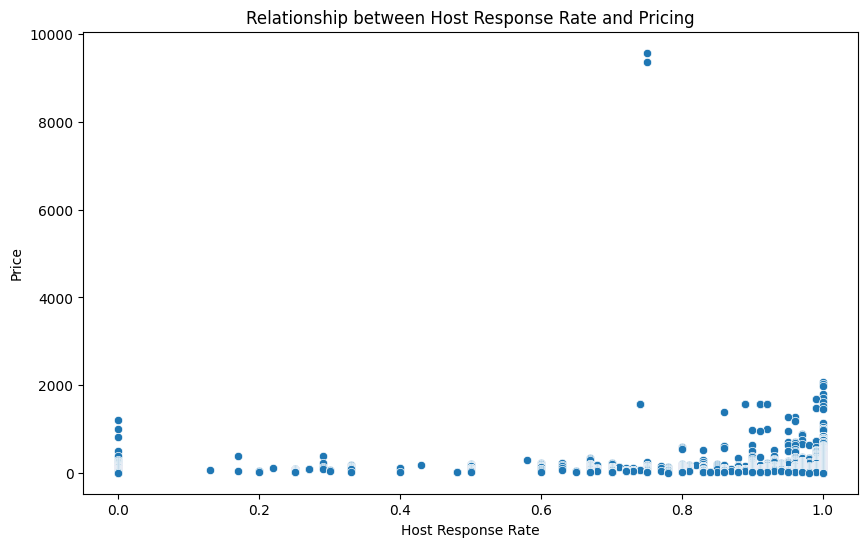

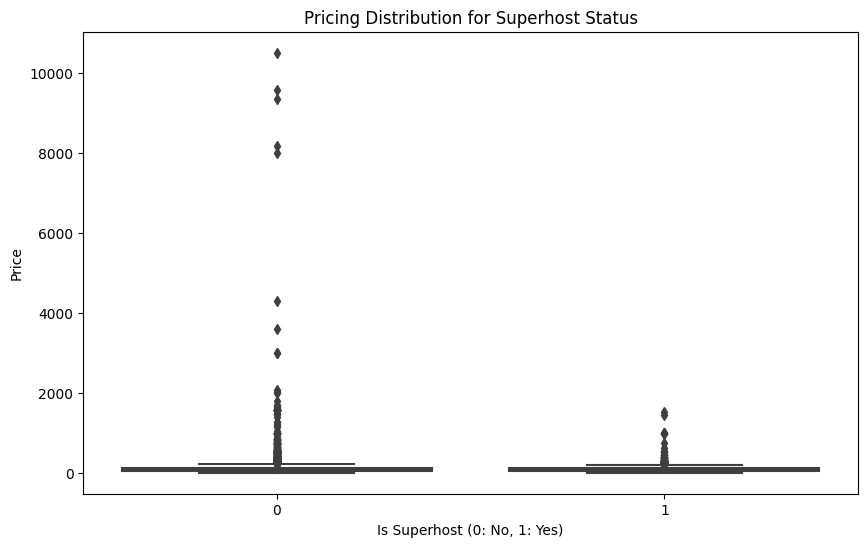

In [ ]:
# Convert host response rate to a numerical value
new_dfs[df_key]['host_response_rate_num'] = new_dfs[df_key]['host_response_rate'].str.replace('%', '').astype(float) / 100

# Convert superhost status to a numerical value
new_dfs[df_key]['superhost'] = new_dfs[df_key]['host_is_superhost'].map({'t': 1, 'f': 0})

# Scatter plot for host response rate and pricing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=new_dfs[df_key], x='host_response_rate_num', y='price')
plt.title('Relationship between Host Response Rate and Pricing')
plt.xlabel('Host Response Rate')
plt.ylabel('Price')
plt.show()

# Boxplot for superhost status and pricing
plt.figure(figsize=(10, 6))
sns.boxplot(data=new_dfs[df_key], x='superhost', y='price')
plt.title('Pricing Distribution for Superhost Status')
plt.xlabel('Is Superhost (0: No, 1: Yes)')
plt.ylabel('Price')
plt.show()

* For the graph "Relationship between Host Response Rate and Pricing," it appears that the majority of listings, regardless of the host's response rate, are clustered at the higher end of the price spectrum. There are some listings at higher price points across various response rates, with a notable outlier at a response rate. This suggests that while a high response rate may be associated with some high-priced listings, there is no clear or consistent pattern indicating that response rate alone dictates pricing.

* In the "Pricing Distribution for Superhost Status" plot, both superhosts and non-superhosts mostly have listings in the lower price range. However, there are outliers in both categories with significantly higher prices. The plot does not show a distinct difference in pricing between superhosts and non-superhosts, indicating that superhost status does not necessarily lead to higher prices. The majority of listings for both groups are modestly priced, which may suggest that guests are not consistently willing to pay a premium for superhost listings, or that superhosts do not always charge more.

**Investigate if the number of listings per host affects pricing strategies**

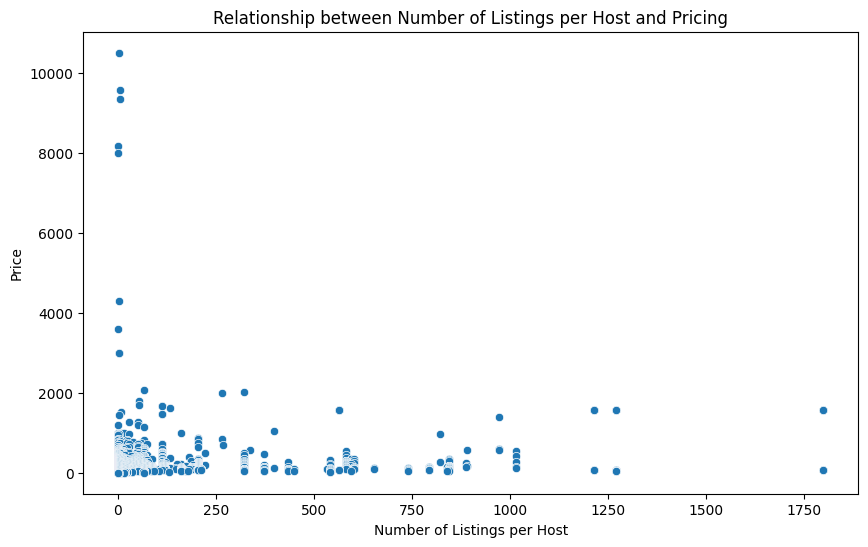

In [ ]:
# Scatter plot for number of listings per host and pricing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=new_dfs[df_key], x='host_listings_count', y='price')
plt.title('Relationship between Number of Listings per Host and Pricing')
plt.xlabel('Number of Listings per Host')
plt.ylabel('Price')
plt.show()

* The plot depicts that hosts with a smaller number of listings tend to have a wide range of prices, with many clustered at the lower end, suggesting that individual or small-scale hosts may offer more competitive or budget-friendly options.

**Analyze the impact of host ratings and reviews on pricing**

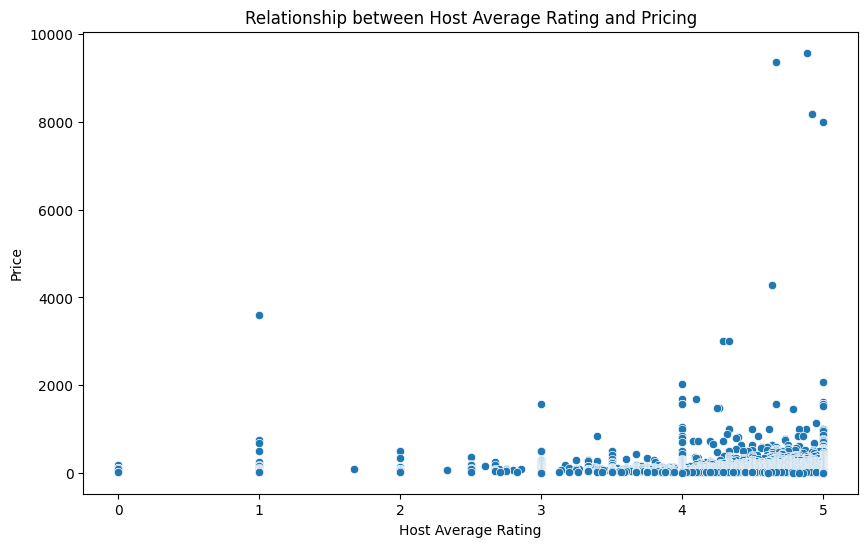

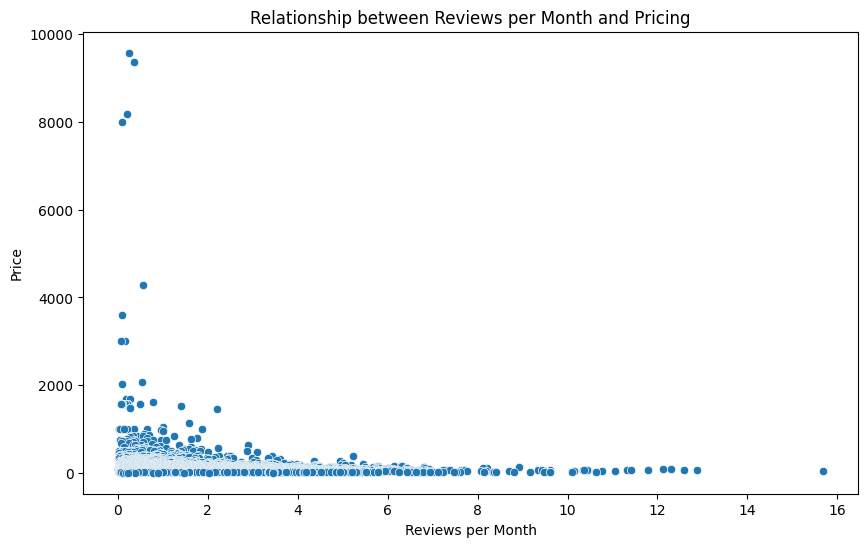

In [ ]:
# Assuming 'review_scores_rating' is the average rating for the host
# Scatter plot for host average rating and pricing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=new_dfs[df_key], x='review_scores_rating', y='price')
plt.title('Relationship between Host Average Rating and Pricing')
plt.xlabel('Host Average Rating')
plt.ylabel('Price')
plt.show()

# Assuming 'reviews_per_month' is an indicator for host reviews frequency
# Scatter plot for reviews per month and pricing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=new_dfs[df_key], x='reviews_per_month', y='price')
plt.title('Relationship between Reviews per Month and Pricing')
plt.xlabel('Reviews per Month')
plt.ylabel('Price')
plt.show()

* The "Relationship between Host Average Rating and Pricing" graph suggests that there is not a strong, clear relationship between a host's average rating and the pricing of their listings. Most listings, regardless of price, have high ratings between 4 and 5, which is common in platforms where ratings tend to be positively skewed. The graph also shows a few listings with very high prices across the rating spectrum, indicating that some high-priced listings have a broad range of host ratings.

* In the "Relationship between Reviews per Month and Pricing" graph, we observe that listings with a wide range of reviews per month are mostly clustered at the lower end of the price spectrum. There are a few listings with a high number of reviews per month that also command higher prices, which could suggest a positive experience or high demand for those listings. However, the majority of data points are concentrated at the lower price range, regardless of the number of reviews per month, indicating that frequent reviews do not necessarily correlate with higher pricing.

### Advanced Statistical Analysis

**Conduct hypothesis testing to check if differences in pricing between various groups are statistically significant**

In [ ]:
# Hypothesis Testing Between Superhosts and non-Superhosts
# Convert price to numeric and remove any non-numeric characters
new_dfs[df_key]['price'] = pd.to_numeric(new_dfs[df_key]['price'].replace('[\$,]', '', regex=True))

# Split the data into two groups: Superhosts and non-Superhosts
superhost_prices = new_dfs[df_key][new_dfs[df_key]['host_is_superhost'] == 't']['price']
non_superhost_prices = new_dfs[df_key][new_dfs[df_key]['host_is_superhost'] == 'f']['price']

# Perform a t-test
t_stat, p_value = ttest_ind(superhost_prices, non_superhost_prices, equal_var=False)
print(f"T-statistic: {t_stat}, P-value: {p_value}")

# If the data is not normally distributed, use Mann-Whitney U test
u_stat, p_value_u = mannwhitneyu(superhost_prices, non_superhost_prices)
print(f"U-statistic: {u_stat}, P-value: {p_value_u}")

T-statistic: -7.575060285320406, P-value: 3.9678320002797396e-14
U-statistic: 5913413.0, P-value: 0.027083129136551653


<ipython-input-55-a2451a87c405>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['price'] = pd.to_numeric(new_dfs[df_key]['price'].replace('[\$,]', '', regex=True))


* The hypothesis testing comparing prices between Airbnb listings managed by Superhosts and non-Superhosts reveals a significant difference in their pricing strategies. The negative T-statistic and extremely low P-value from the T-test suggest that Superhosts generally price their listings lower than non-Superhosts, a result that is statistically significant but somewhat counterintuitive. This could be due to Superhosts aiming to maintain competitive pricing to attract more guests, thereby sustaining their high ratings and status. However, the Mann-Whitney U test, which is more appropriate for our non-normally distributed data, shows a P-value slightly above the conventional significance level (0.05), indicating a less pronounced difference in pricing distributions between the two groups. This discrepancy highlights the importance of considering the data distribution in our project's analysis. It suggests that while Superhost status might impact pricing, the effect is not uniformly strong across all listings, and other factors could also be influencing pricing decisions. This finding is crucial for developing pricing strategies that balance between competitive pricing and maintaining high-quality standards expected of Superhosts.

In [ ]:
# Hypothesis Testing Based on Host Identity Verification
# (Works just if the code is loaded completely)
# Convert host_identity_verified to 0s and 1s
new_dfs[df_key]['host_identity_verified'] = new_dfs[df_key]['host_identity_verified'].map({'f': 0, 't': 1})

# Extract prices for verified and non-verified hosts
verified_host_prices = new_dfs[df_key][new_dfs[df_key]['host_identity_verified'] == 1]['price']
non_verified_host_prices = new_dfs[df_key][new_dfs[df_key]['host_identity_verified'] == 0]['price']

# Perform t-test between verified and non-verified host prices
t_stat_verified, p_value_verified = ttest_ind(verified_host_prices, non_verified_host_prices, equal_var=False)
print(f"T-statistic for Host Verification: {t_stat_verified}, P-value: {p_value_verified}")

# Perform Mann-Whitney U test as a non-parametric test
u_stat, p_value_u = mannwhitneyu(verified_host_prices, non_verified_host_prices)
print(f"U-statistic: {u_stat}, P-value: {p_value_u}")

T-statistic for Host Verification: 1.1545691180491835, P-value: 0.24840004325593415
U-statistic: 4296111.5, P-value: 0.0928514128767141


<ipython-input-56-f3cc3c192071>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['host_identity_verified'] = new_dfs[df_key]['host_identity_verified'].map({'f': 0, 't': 1})


* The hypothesis testing conducted to understand the impact of host identity verification on Airbnb listing prices in Malaga yields intriguing insights for our project. The T-test results, with a T-statistic of 1.1545 and a P-value of 0.2484, indicate that the difference in average prices between verified and non-verified hosts is not statistically significant. This suggests that, on average, host verification status may not be a key factor influencing pricing decisions. However, the Mann-Whitney U test, which is more appropriate for our non-normally distributed data, shows a P-value of 0.0928, slightly above the standard threshold for statistical significance (0.05). While this result is not conclusive, it hints that there could be some differences in the overall distribution of prices between verified and non-verified hosts, perhaps due to perceived trustworthiness or quality associated with verification. For the project, this information is valuable, indicating that while host verification may not dramatically influence pricing on average, it could still play a role in how hosts position their listings in the market, potentially affecting certain segments more than others.

In [ ]:
# Hypothesis Testing Based on Instant Bookable Feature
# (Works just if the code is loaded completely)
# Convert instant_bookable to 0s and 1s
new_dfs[df_key]['instant_bookable'] = new_dfs[df_key]['instant_bookable'].map({'f': 0, 't': 1})

# Extract prices for listings with and without instant booking
instant_prices = new_dfs[df_key][new_dfs[df_key]['instant_bookable'] == 1]['price']
no_instant_prices = new_dfs[df_key][new_dfs[df_key]['instant_bookable'] == 0]['price']

# Perform t-test between instant bookable and non-instant bookable prices
t_stat_instant, p_value_instant = ttest_ind(instant_prices, no_instant_prices, equal_var=False)
print(f"T-statistic for Instant Booking: {t_stat_instant}, P-value: {p_value_instant}")

# Perform Mann-Whitney U test as a non-parametric test
u_stat, p_value_u = mannwhitneyu(instant_prices, no_instant_prices)
print(f"U-statistic: {u_stat}, P-value: {p_value_u}")

T-statistic for Instant Booking: -3.542744997571468, P-value: 0.0004013409947037672
U-statistic: 9235603.5, P-value: 3.132943274678997e-39


<ipython-input-57-9d252cdcdd9d>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['instant_bookable'] = new_dfs[df_key]['instant_bookable'].map({'f': 0, 't': 1})


* The T-test, with a T-statistic of -3.5427 and a P-value of 0.0004, indicates a statistically significant difference in prices between listings with and without this feature. Interestingly, the negative T-statistic suggests that listings without the instant booking option might be priced higher than those with it. However, the more pertinent result for our non-normally distributed data comes from the Mann-Whitney U test, which shows a U-statistic of 9235603.5 and an extremely small P-value (near zero). This strongly reinforces the finding of a significant difference in the price distribution between the two groups. For the project, this suggests that the absence of an instant booking option could be associated with higher pricing strategies. This insight is crucial as it highlights that while instant booking might add convenience, it does not necessarily translate to higher prices for hosts, and its absence might be a characteristic of more premium or uniquely positioned listings.

In [ ]:
# Hypothesis Testing Based on Accommodation Size
# Group the data by accommodation size
accommodates_pricing = new_dfs[df_key].groupby('accommodates')['price'].agg(['mean', 'count'])

# Let's compare small (1-2 people) vs. large (more than 2 people) accommodations
small_accommodation_prices = new_dfs[df_key][new_dfs[df_key]['accommodates'] <= 2]['price']
large_accommodation_prices = new_dfs[df_key][new_dfs[df_key]['accommodates'] > 2]['price']

# Perform t-test between small and large accommodation prices
t_stat_accommodates, p_value_accommodates = ttest_ind(small_accommodation_prices, large_accommodation_prices, equal_var=False)
print(f"T-statistic for Accommodation Size: {t_stat_accommodates}, P-value: {p_value_accommodates}")

# Perform Mann-Whitney U test as a non-parametric test
u_stat, p_value_u = mannwhitneyu(small_accommodation_prices, large_accommodation_prices)
print(f"U-statistic: {u_stat}, P-value: {p_value_u}")

T-statistic for Accommodation Size: -3.1161898095408636, P-value: 0.001846068029755758
U-statistic: 3319600.0, P-value: 0.0


* The hypothesis testing results for accommodation size within our project's analysis of Malaga's Airbnb listings highlight a notable trend in pricing strategies. The T-test shows a T-statistic of -3.1162 and a P-value of 0.0018, suggesting a statistically significant difference in prices between small (accommodating 1-2 people) and large (more than 2 people) accommodations, with larger accommodations generally priced higher. This is further reinforced by the Mann-Whitney U test, which, being a non-parametric test ideal for our non-normally distributed data, shows a U-statistic of 3319600.0 and a P-value of 0.0, indicating a significant difference in the distribution of prices between these two categories. For our project, this emphasizes the importance of accommodation size as a factor in pricing strategies. This finding can be instrumental in guiding hosts on how to price their properties based on size to optimize revenue, particularly highlighting the potential for higher revenue from larger properties.

## Euskadi

### Initial Data Exploration

In [ ]:
# Analyzing the DataFrame euskadi_df

df = euskadi_df

num_variables = len(df.columns)
print(f"Number of variables (columns) in euskadi_df: {num_variables}")

num_observations = len(df)
print(f"Number of observations (rows) in euskadi_df: {num_observations}")

missing_cells = df.isnull().sum()
print("Missing cells per variable (column) in euskadi_df:")
print(missing_cells)

duplicate_rows = df[df.duplicated(keep='first')]
num_duplicate_rows = len(duplicate_rows)
print(f"Number of duplicate rows in euskadi_df: {num_duplicate_rows}")

has_missing_values = df.isnull().values.any()
print(f"Missing values in the entire euskadi_df dataset: {has_missing_values}")

Number of variables (columns) in euskadi_df: 18
Number of observations (rows) in euskadi_df: 6894
Missing cells per variable (column) in euskadi_df:
id                                   0
name                                 0
host_id                              0
host_name                          100
neighbourhood_group                  0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                       1058
reviews_per_month                 1058
calculated_host_listings_count       0
availability_365                     0
number_of_reviews_ltm                0
license                           3370
dtype: int64
Number of duplicate rows in euskadi_df: 0
Missing values in the entire euskadi_df dataset: True


The esukadi_df dataset consists of 18 variables (columns) and 6894 observations (rows). There are no duplicate rows, indicating unique entries across the dataset. However, it contains missing values in several columns. Notably, the 'license' column has a significant number of missing values (3370 out of 6894), which could affect analyses related to regulatory compliance. The columns 'last_review' and 'reviews_per_month' also have a substantial number of missing entries (1058 each), suggesting that many listings haven't been reviewed recently or at all. This could impact the reliability of customer satisfaction or popularity metrics derived from these data. For our project, these gaps might necessitate imputation strategies or a focused analysis on listings with complete data to ensure accuracy.

In [ ]:
# Analyzing the DataFrame euskadi2_df

df = euskadi2_df
num_variables = len(df.columns)
print(f"Number of variables (columns) in euskadi2_df: {num_variables}")

num_observations = len(df)
print(f"Number of observations (rows) in euskadi2_df: {num_observations}")

missing_cells = df.isnull().sum()
print("Missing cells per variable (column) in euskadi2_df:")
print(missing_cells)

duplicate_rows = df[df.duplicated(keep='first')]
num_duplicate_rows = len(duplicate_rows)
print(f"Number of duplicate rows in euskadi2_df: {num_duplicate_rows}")

has_missing_values = df.isnull().values.any()
print(f"Missing values in the entire euskadi2_df dataset: {has_missing_values}")

Number of variables (columns) in euskadi2_df: 75
Number of observations (rows) in euskadi2_df: 6894
Missing cells per variable (column) in euskadi2_df:
id                                                 0
listing_url                                        0
scrape_id                                          0
last_scraped                                       0
source                                             0
                                                ... 
calculated_host_listings_count                     0
calculated_host_listings_count_entire_homes        0
calculated_host_listings_count_private_rooms       0
calculated_host_listings_count_shared_rooms        0
reviews_per_month                               1058
Length: 75, dtype: int64
Number of duplicate rows in euskadi2_df: 0
Missing values in the entire euskadi2_df dataset: True


Again the euskadi2_df dataset is more extensive, with 75 variables and 6894 observations. WIth no duplicated rows, but quite a few missing values.

In [ ]:
set1, set2 = set(euskadi_df['id']), set(euskadi2_df['id'])
duplicates = set1.intersection(set2)
unique_in_df1 = set1.difference(set2)
unique_in_df2 = set2.difference(set1)
print("Duplicates:", duplicates)
print("Unique in DataFrame 1:", unique_in_df1)
print("Unique in DataFrame 2:", unique_in_df2)

Duplicates: {620054550581870592, 9633804, 51314703, 720913, 1998866, 41680913, 720916, 37453845, 17793050, 42369052, 24838181, 562263745415512123, 710485948129280072, 42500169, 31031373, 53182541, 19071057, 564375698698469460, 13500502, 37748842, 44335213, 650413919039717489, 43450483, 573224954054901881, 16089213, 17694858, 14090384, 11370650, 582467117175603357, 34504862, 51937447, 17170605, 30081204, 706352622785495238, 7635145, 51839184, 24707282, 51020000, 26837218, 3473638, 24903910, 38371560, 41681127, 3244266, 51249383, 38699245, 653686558765220078, 721139, 35815669, 685322857635479815, 39551248, 691154526121591060, 29753623, 681644392069038359, 666484125372940569, 13861146, 18907436, 666030067255607600, 13500721, 695610073465323824, 42238262, 609908481073938743, 628244665338364214, 597065812936950086, 34832711, 18153800, 44794184, 19857740, 11862351, 20513103, 32833901, 24772975, 38044018, 13402485, 48693625, 32309651, 22872473, 51085725, 654749119086985629, 21365151, 44007842

* Also the output indicates that there are all duplicate listings between the two dataframes, as evidenced by the empty Unique in Dataframe sets. This suggests that each dataset contains the same listings, which is valuable for a comprehensive analysis meaning that by only using one of them, it this case the euskadi2_df, we would not only have more data, but the number of properties listed are the same.

In [ ]:
euskadi_dataframes = {'euskadi_df': euskadi_df, 'euskadi2_df': euskadi2_df}
for key, df in euskadi_dataframes.items():
    print(f"\nThe columns in the dataframe {key} are:\n", df.columns)


The columns in the dataframe euskadi_df are:
 Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365', 'number_of_reviews_ltm', 'license'],
      dtype='object')

The columns in the dataframe euskadi2_df are:
 Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name',
       'description', 'neighborhood_overview', 'picture_url', 'host_id',
       'host_url', 'host_name', 'host_since', 'host_location', 'host_about',
       'host_response_time', 'host_response_rate', 'host_acceptance_rate',
       'host_is_superhost', 'host_thumbnail_url', 'host_picture_url',
       'host_neighbourhood', 'host_listings_count',
       'host_total_listings_count', 'host_verifications',
       'host_has_profile_pic', 'host_identity_verified', 'neighbourhood',
   

The euskadi_df dataset provides a concise overview of the listings, including basic details like location, type, price, and review metrics. It's ideal for a high-level analysis focusing on geographical distribution, pricing strategies, and general host information. In contrast, barcelona2_df offers a more comprehensive dataset with detailed information such as host response rates, property type, amenities, and detailed review scores. This dataset is more suitable for an in-depth analysis that requires understanding the specifics of each listing, host engagement, and customer satisfaction metrics.

For our project we are using euskadi2_df, because our analysis will benefit from a more detailed understanding of each listing. The addidional data will provide more depth and context for our analysis, which could be crucial for developing accurate pricing strategies. We are opting for a streamlined and efficient model by dropping columns such as URLs, detailed host information, and extensive review texts from our Airbnb datasets. This approach reduces computational complexity and time, focusing on clear and direct factors affecting pricing. This way, we maintain high efficiency in our analysis while ensuring the model remains manageable and effective. This is why we decided to drop those columns first and then continue with the EDA.

In [ ]:
new_dfs = {}
df_key = 'df_euskadi_new'
columns_to_drop = [
   'id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview',
   'picture_url', 'host_id', 'host_url', 'host_name', 'host_location', 'host_about',
   'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood',
   'calendar_updated', 'has_availability', 'availability_30', 'availability_60',
   'availability_90', 'calendar_last_scraped'
]
new_dfs[df_key] = euskadi2_df.drop(columns=columns_to_drop)
print(f"\nRemaining columns in {df_key}: {new_dfs[df_key].columns.tolist()}")


Remaining columns in df_euskadi_new: ['host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'first_review', 'last_review', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'license', 'inst

In [ ]:
# Descriptive analysis of the dataset
print("Summary Statistics:\n")
print(new_dfs[df_key].describe())

Summary Statistics:

       host_listings_count  host_total_listings_count     latitude  \
count          6794.000000                6794.000000  6894.000000   
mean             97.880483                 186.995290    43.252007   
std             491.304278                 971.766771     0.180959   
min               1.000000                   1.000000    42.465810   
25%               1.000000                   1.000000    43.258755   
50%               2.000000                   3.000000    43.305520   
75%               8.000000                  10.000000    43.326620   
max            4408.000000               20000.000000    43.441055   

         longitude  accommodates  bathrooms     bedrooms         beds  \
count  6894.000000   6894.000000        0.0  6390.000000  6804.000000   
mean     -2.403962      3.901799        NaN     1.935837     2.878601   
std       0.464865      2.385352        NaN     1.194741     2.277646   
min      -3.459210      1.000000        NaN     1.000000

The dataset consists of 6794 listings with a wide range of host listings count, indicating a diverse set of hosts from individuals to possibly commercial entities.
The majority of properties accommodate between 2 to 4 people, suggesting a focus on small to medium-sized groups.
The review scores are generally high (above 4.6 on average), which implies a good overall guest satisfaction.
The bathrooms column lacks data (all values are NaN), which might require imputation or dropping the column for further analysis.
The high standard deviations in host listings count and review scores suggest variability in host activity and guest experiences.

In [ ]:
# Data types of columns
print("\nData Types of Each Column:\n")
print(new_dfs[df_key].dtypes)


Data Types of Each Column:

host_since                                       object
host_response_time                               object
host_response_rate                               object
host_acceptance_rate                             object
host_is_superhost                                object
host_listings_count                             float64
host_total_listings_count                       float64
host_verifications                               object
host_has_profile_pic                             object
host_identity_verified                           object
neighbourhood                                    object
neighbourhood_cleansed                           object
neighbourhood_group_cleansed                     object
latitude                                        float64
longitude                                       float64
property_type                                    object
room_type                                        object
accommodates       

The dataset contains a mix of numerical (int64, float64) and categorical/object (string) data types, which is typical for accommodation listings.
Some columns that appear to be numeric (like price) are actually stored as objects, indicating the presence of non-numeric characters (e.g., currency symbols) and a need for data cleaning.

In [ ]:
# Check uniqueness
print("\nUniqueness of Each Column:\n")
print(new_dfs[df_key].nunique())


Uniqueness of Each Column:

host_since                                      2211
host_response_time                                 4
host_response_rate                                42
host_acceptance_rate                              82
host_is_superhost                                  2
host_listings_count                               53
host_total_listings_count                         68
host_verifications                                 7
host_has_profile_pic                               2
host_identity_verified                             2
neighbourhood                                    541
neighbourhood_cleansed                           210
neighbourhood_group_cleansed                       3
latitude                                        5537
longitude                                       6042
property_type                                     67
room_type                                          4
accommodates                                      16
bathrooms        

There's a diverse range of amenities, with 6093 unique entries, suggesting a wide variety of features offered across listings.
The significant variety in license, host_verifications, and review_per_month can offer insights into the regulation compliance, host verification process, and popularity of listings.

In [ ]:
# Show first 10 rows
print("\nFirst 10 rows:\n")
print(new_dfs[df_key].head(10))


First 10 rows:

   host_since  host_response_time host_response_rate host_acceptance_rate  \
0  2011-05-31      within an hour               100%                 100%   
1  2011-06-12      within an hour               100%                  96%   
2  2011-09-18  within a few hours               100%                  93%   
3  2012-01-10      within an hour               100%                  95%   
4  2012-01-10      within an hour               100%                  95%   
5  2012-01-10      within an hour               100%                  95%   
6  2012-01-10      within an hour               100%                  95%   
7  2012-02-11  within a few hours               100%                   0%   
8  2012-02-07      within an hour               100%                 100%   
9  2012-03-16      within an hour               100%                  99%   

  host_is_superhost  host_listings_count  host_total_listings_count  \
0                 t                  1.0                        

The first 10 rows provide a glimpse into the dataset's structure, showing details like host response time, room type, amenities, and review scores.
Some fields such as license and reviews_per_month contain NaN values, indicating missing data that may need addressing.
The variety in instant_bookable, property_type, and room_type reflects the diversity of the listings.

Further observations:

Variability in Host Listings: There's a wide range in the number of listings per host, with some having just one and others managing thousands. This indicates a diversity in host types, from individuals to large-scale operators.

Geographical Spread: The latitude and longitude data points to a geographical spread of properties. The location is a crucial factor in pricing, as different areas have different demand and price points.

Accommodation Capacity: The accommodates, bedrooms, and beds columns show a range of property sizes. Larger properties (more beds and bedrooms) likely command higher prices.

Minimum Nights and Availability: The minimum_nights and availability_365 columns suggest varied booking and availability patterns. This can impact pricing strategy, especially considering peak and off-peak seasons.

Review Scores: High average scores across various review categories indicate generally positive guest experiences. Higher-rated properties might be able to charge more.

Recent Reviews and Review Frequency: The number_of_reviews_l30d and reviews_per_month indicate recent activity and overall review frequency. Properties with more frequent reviews may be more popular and could potentially price higher.

Missing Data in Bathrooms: The consistent absence of data in the bathrooms column across datasets might require data imputation or a decision to exclude this variable from pricing models.

These insights are crucial for developing a dynamic pricing model. They highlight the importance of considering a range of factors - from property size and type, host's portfolio size, geographical location, to guest satisfaction and booking patterns - for setting optimal prices.

### Detailed Analysis of Pricing Variable

Analyze the Distribution of Listing Prices

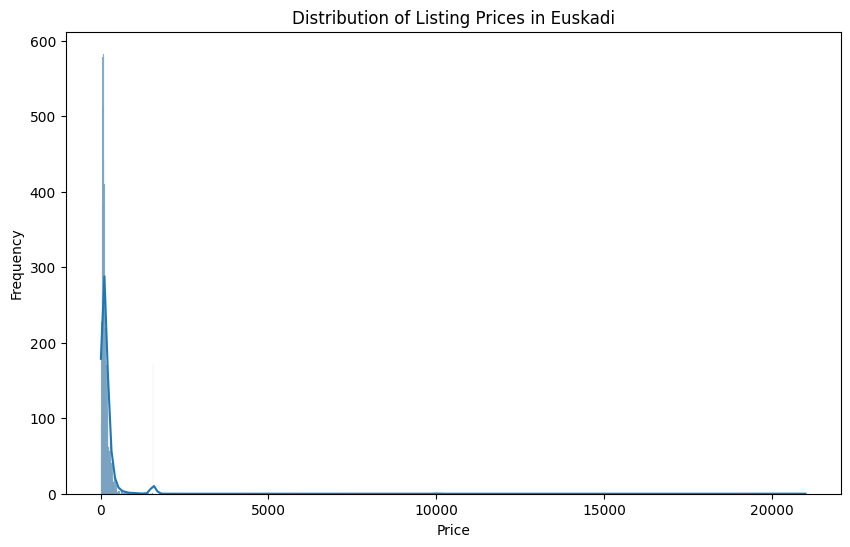

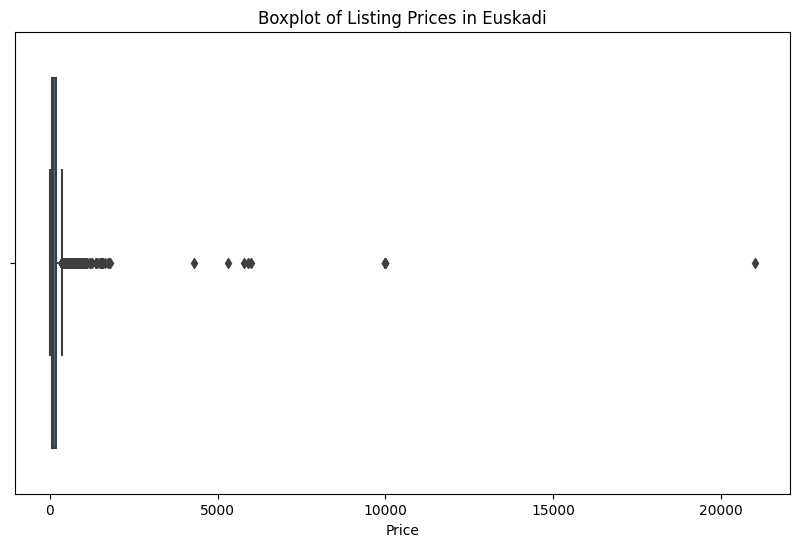

In [ ]:
# Convert 'price' to a numeric value, removing any non-numeric characters like '$'
new_dfs[df_key]['price'] = pd.to_numeric(new_dfs[df_key]['price'].replace('[\$,]', '', regex=True), errors='coerce')

# Histogram of listing prices
plt.figure(figsize=(10, 6))
sns.histplot(new_dfs[df_key]['price'], kde=True)
plt.title('Distribution of Listing Prices in Euskadi')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

# Boxplot of listing prices
plt.figure(figsize=(10, 6))
sns.boxplot(x=new_dfs[df_key]['price'])
plt.title('Boxplot of Listing Prices in Euskadi')
plt.xlabel('Price')
plt.show()

The graphs of listing prices in Euskadi shows that the vast majority of listings are priced at the lower end of the scale which indicates that affordable listings dominate the market. However, there are a few listings with extremely high prices.These outliers could represent luxury accommodations or could be due to data entry errors.

For our project, it is important to investigate the outliers to determine whether they are genuine luxury listings or anomalies that should be cleaned from the dataset. Understanding this distribution will be crucial for developing predictive pricing models and making strategic recommendations for pricing strategies. It's also important to normalize or transform the price variable for any modelling to mitigate the skewness and potential influence of outliers.

**Investigate Any Outliers in the Price Data**

In [ ]:
# Calculating IQR to identify outliers
Q1 = new_dfs[df_key]['price'].quantile(0.25)
Q3 = new_dfs[df_key]['price'].quantile(0.75)
IQR = Q3 - Q1
outlier_threshold = Q3 + 1.5 * IQR

# Counting number of outliers
outliers = new_dfs[df_key][new_dfs[df_key]['price'] > outlier_threshold]
print(f"Number of Outliers: {len(outliers)}")
print(f"Outlier Threshold: {outlier_threshold}")

Number of Outliers: 535
Outlier Threshold: 350.375


**Examine the Relationship Between Price and Other Numerical Variables**

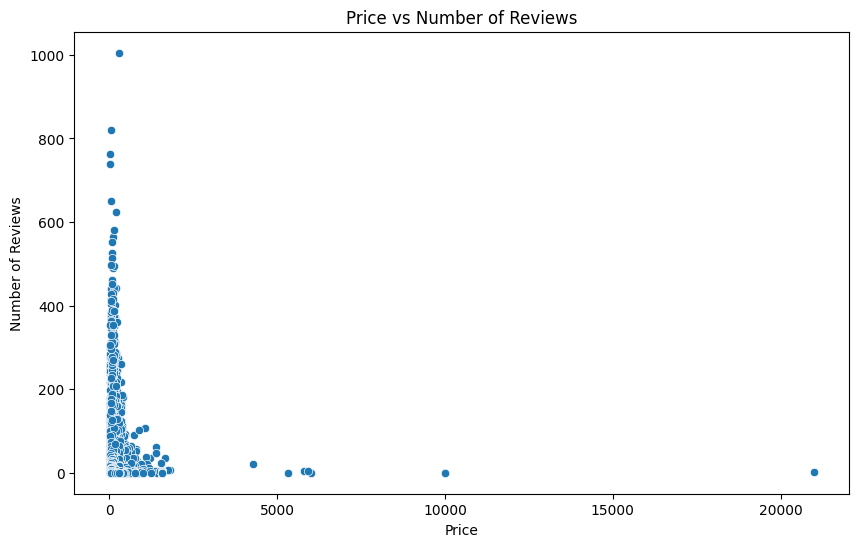

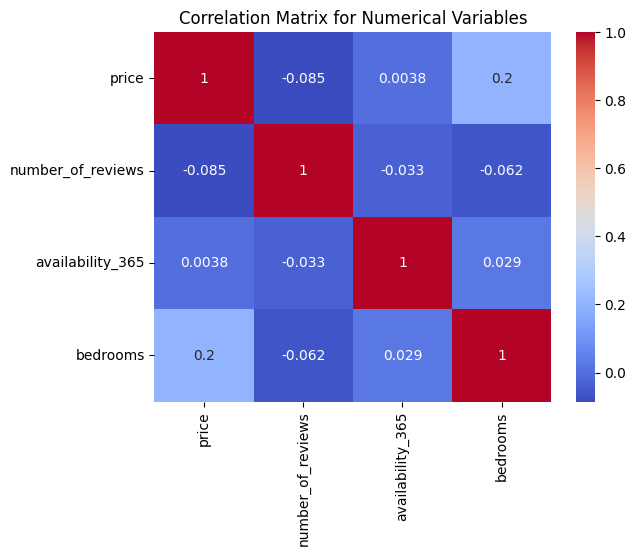

In [ ]:
# Scatter plot between price and numerical variables like 'number_of_reviews'
plt.figure(figsize=(10, 6))
sns.scatterplot(x='price', y='number_of_reviews', data=new_dfs[df_key])
plt.title('Price vs Number of Reviews')
plt.xlabel('Price')
plt.ylabel('Number of Reviews')
plt.show()

# Correlation analysis
numerical_vars = ['price', 'number_of_reviews', 'availability_365', 'bedrooms']  # Include other relevant numerical variables
correlation_matrix = new_dfs[df_key][numerical_vars].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix for Numerical Variables')
plt.show()

* The scatter plot and correlation matrix show a weak relationship between price and the number of reviews, suggesting that higher prices don't necessarily equate to a higher number of reviews. It's also noteworthy that there is a slight positive correlation between price and the number of bedrooms, which is intuitive, as larger properties with more bedrooms are likely to be priced higher. The slight correlation with the number of bedrooms could be used to help determine pricing strategies based on property size.

### Analysis of Location-Based Pricing

**Group the data by neighborhood and calculate average, median, and range of prices**

In [ ]:
# Group the data by neighbourhood and calculate average, median, and range of prices.

neighbourhood_pricing = new_dfs[df_key].groupby('neighbourhood_cleansed')['price'].agg(['mean', 'median', 'max', 'min'])
neighbourhood_pricing['range'] = neighbourhood_pricing['max'] - neighbourhood_pricing['min']
print(neighbourhood_pricing)

                                          mean  median     max    min  range
neighbourhood_cleansed                                                      
AbadiÃ±o                            110.500000    74.0   232.0   62.0  170.0
Abaltzisketa                        105.000000   105.0   115.0   95.0   20.0
Abanto y CiÃ©rvana-Abanto Zierbena   88.166667    79.5   150.0   50.0  100.0
Aduna                               140.000000   140.0   150.0  130.0   20.0
Aia                                 169.615385   141.0   389.0   62.0  327.0
...                                        ...     ...     ...    ...    ...
Zigoitia                            264.200000   139.0  1000.0   89.0  911.0
Zizurkil                            183.500000   124.5   450.0   35.0  415.0
Zuia                                143.066667   122.0   329.0   60.0  269.0
Zumaia                              135.853659   110.0   450.0   53.0  397.0
Zumarraga                            52.666667    56.0    79.0   23.0   56.0

* These statistics indicate that some neighborhoods have a wide range of listing prices, which could reflect a diverse housing market with both budget and luxury accommodations. For our project, neighborhoods with large ranges could be of particular interest as they may offer opportunities for price optimization based on various property features and market demand. Additionally, the neighborhoods' mean and median prices can help identify areas that could yield higher revenue potential or require competitive pricing strategies.

**Visualize geographical price variations using maps**

In [ ]:
# Visualize geographical price variations using maps.
# Create a map centered around Euskadi
euskadi_map = folium.Map(location=[new_dfs[df_key]['latitude'].mean(), new_dfs[df_key]['longitude'].mean()], zoom_start=13)

# Add points to the map
for idx, row in new_dfs[df_key].iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=3,
        popup=f"${row['price']}",
        color='blue' if row['price'] <= neighbourhood_pricing['median'][row['neighbourhood_cleansed']] else 'red',
        fill=True
    ).add_to(euskadi_map)

# Display the map
euskadi_map

Output hidden; open in https://colab.research.google.com to view.

* After analyzing the Euskadi map, we concluded that the dataset represents an entire Autonomous Community with numerous cities and hotspots, in contrast to the datasets focusing on individual cities as seen above. Therefore, we decided to exclude this dataset from our training model.

## Madrid

### Initial Data Exploration

In [ ]:
# Analyzing the DataFrame madrid_df

df = madrid_df

num_variables = len(df.columns)
print(f"Number of variables (columns) in madrid_df: {num_variables}")

num_observations = len(df)
print(f"Number of observations (rows) in madrid_df: {num_observations}")

missing_cells = df.isnull().sum()
print("Missing cells per variable (column) in madrid_df:")
print(missing_cells)

duplicate_rows = df[df.duplicated(keep='first')]
num_duplicate_rows = len(duplicate_rows)
print(f"Number of duplicate rows in madrid_df: {num_duplicate_rows}")

has_missing_values = df.isnull().values.any()
print(f"Missing values in the entire madrid_df dataset: {has_missing_values}")

Number of variables (columns) in madrid_df: 18
Number of observations (rows) in madrid_df: 20681
Missing cells per variable (column) in madrid_df:
id                                    0
name                                  4
host_id                               0
host_name                             3
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                        4462
reviews_per_month                  4462
calculated_host_listings_count        0
availability_365                      0
number_of_reviews_ltm                 0
license                           17926
dtype: int64
Number of duplicate rows in madrid_df: 0
Missing values in the entire madrid_df dataset: True


* The madrid_df dataset consists of 18 variables (columns) and 20681 observations (rows). There are no duplicate rows, indicating unique entries across the dataset. However, it contains missing values in several columns. Notably, the 'license' column has a significant number of missing values (17926 out of 20681), which could affect analyses related to regulatory compliance. The columns 'last_review' and 'reviews_per_month' also have a substantial number of missing entries (4462 each), suggesting that many listings haven't been reviewed recently or at all.



In [ ]:
# Analyzing the DataFrame madrid2_df

df = madrid2_df

num_variables = len(df.columns)
print(f"Number of variables (columns) in madrid2_df: {num_variables}")

num_observations = len(df)
print(f"Number of observations (rows) in madrid2_df: {num_observations}")

missing_cells = df.isnull().sum()
print("Missing cells per variable (column) in madrid2_df:")
print(missing_cells)

duplicate_rows = df[df.duplicated(keep='first')]
num_duplicate_rows = len(duplicate_rows)
print(f"Number of duplicate rows in madrid2_df: {num_duplicate_rows}")

has_missing_values = df.isnull().values.any()
print(f"Missing values in the entire madrid2_df dataset: {has_missing_values}")


Number of variables (columns) in madrid2_df: 75
Number of observations (rows) in madrid2_df: 20682
Missing cells per variable (column) in madrid2_df:
listings.csv                                       1
listing_url                                        1
scrape_id                                          1
last_scraped                                       1
source                                             1
                                                ... 
calculated_host_listings_count                     1
calculated_host_listings_count_entire_homes        1
calculated_host_listings_count_private_rooms       1
calculated_host_listings_count_shared_rooms        1
reviews_per_month                               4463
Length: 75, dtype: int64
Number of duplicate rows in madrid2_df: 0
Missing values in the entire madrid2_df dataset: True


* The madrid2_df dataset is more extensive, with 75 variables and the same number observations as madrida_df, this dataset also has no duplicate rows, ensuring the uniqueness of the listings. Nevertheless there are still a significant amout of values in each column. But since there are more values that could help our model we will still chose this one over the other one.

* We tried to check for duplicates as we did with the cities above, but we noticed that madrid2_df, does't have an id column, that we could compare with madrid_df. Still we decided to use madrid2_df because the numbers of rows are the same, but there are many more columns that could be usefull for our analysis.

In [ ]:
madrid_dataframes = {'madrid_df': madrid_df, 'madrid2_df': madrid2_df}

for key, df in madrid_dataframes.items():
    print(f"\nThe columns in the dataframe {key} are:\n", df.columns)


The columns in the dataframe madrid_df are:
 Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365', 'number_of_reviews_ltm', 'license'],
      dtype='object')

The columns in the dataframe madrid2_df are:
 Index(['listings.csv', 'listing_url', 'scrape_id', 'last_scraped', 'source',
       'name', 'description', 'neighborhood_overview', 'picture_url',
       'host_id', 'host_url', 'host_name', 'host_since', 'host_location',
       'host_about', 'host_response_time', 'host_response_rate',
       'host_acceptance_rate', 'host_is_superhost', 'host_thumbnail_url',
       'host_picture_url', 'host_neighbourhood', 'host_listings_count',
       'host_total_listings_count', 'host_verifications',
       'host_has_profile_pic', 'host_identity_verified', 'neighbourho

In [ ]:
# Initialize the dictionary to store the modified DataFrame
new_dfs = {}

df_key = 'df_madrid_new'

columns_to_drop = [
   'listings.csv','listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview',
   'picture_url', 'host_id', 'host_url', 'host_name', 'host_location', 'host_about',
   'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood',
   'calendar_updated', 'has_availability', 'availability_30', 'availability_60',
   'availability_90', 'calendar_last_scraped'
]

new_dfs[df_key] = madrid2_df.drop(columns=columns_to_drop)
pre_df_madrid= new_dfs['df_madrid_new']

print(f"\nRemaining columns in {df_key}: {new_dfs[df_key].columns.tolist()}")


Remaining columns in df_madrid_new: ['host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'first_review', 'last_review', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'license', 'insta

In [ ]:
# Descriptive analysis of the dataset
print("Summary Statistics:\n")
print(new_dfs[df_key].describe())

Summary Statistics:

       host_listings_count  host_total_listings_count      latitude  \
count         20678.000000               20678.000000  20681.000000   
mean             21.187978                  28.421898     40.421275   
std              82.656923                 124.211905      0.025182   
min               0.000000                   0.000000     40.308640   
25%               1.000000                   1.000000     40.409530   
50%               2.000000                   3.000000     40.419767   
75%              11.000000                  13.000000     40.430330   
max            2157.000000                3311.000000     40.620800   

          longitude  accommodates  bathrooms      bedrooms          beds  \
count  20681.000000  20681.000000        0.0  19227.000000  20331.000000   
mean      -3.694393      3.113873        NaN      1.473709      1.975014   
std        0.030974      1.937426        NaN      0.891767      1.449211   
min       -3.907250      0.000000  

* The dataset consists of 20678 listings with a wide range of host listings count (1 to 20678), indicating a diverse set of hosts from individuals to possibly commercial entities.
* The majority of properties accommodate between 2 to 4 people, suggesting a focus on small to medium-sized groups.
* The review scores are generally high (above 4.5 on average), which implies a good overall guest satisfaction.
* The bathrooms column lacks data (all values are NaN), which might require imputation or dropping the column for further analysis.
* The high standard deviations in host listings count and review scores suggest variability in host activity and guest experiences.

In [ ]:
# Data types of columns
print("\nData Types of Each Column:\n")
print(new_dfs[df_key].dtypes)


Data Types of Each Column:

host_since                                       object
host_response_time                               object
host_response_rate                               object
host_acceptance_rate                             object
host_is_superhost                                object
host_listings_count                             float64
host_total_listings_count                       float64
host_verifications                               object
host_has_profile_pic                             object
host_identity_verified                           object
neighbourhood                                    object
neighbourhood_cleansed                           object
neighbourhood_group_cleansed                     object
latitude                                        float64
longitude                                       float64
property_type                                    object
room_type                                        object
accommodates       

* The dataset contains a mix of numerical (int64, float64) and categorical/object (string) data types, which is typical for accommodation listings.
* Some columns that appear to be numeric (like price) are actually stored as objects, indicating the presence of non-numeric characters (e.g., currency symbols) and a need for data cleaning.

In [ ]:
# Check uniqueness
print("\nUniqueness of Each Column:\n")
print(new_dfs[df_key].nunique())


Uniqueness of Each Column:

host_since                                       3557
host_response_time                                  4
host_response_rate                                 73
host_acceptance_rate                              100
host_is_superhost                                   2
host_listings_count                                87
host_total_listings_count                         103
host_verifications                                  8
host_has_profile_pic                                2
host_identity_verified                              2
neighbourhood                                      63
neighbourhood_cleansed                            128
neighbourhood_group_cleansed                       21
latitude                                         9995
longitude                                        9961
property_type                                      76
room_type                                           4
accommodates                                       17

* There's a diverse range of amenities, with 18071 unique entries, suggesting a wide variety of features offered across listings.
* The significant variety in license, host_verifications, and review_per_month can offer insights into the regulation compliance, host verification process, and popularity of listings.

In [ ]:
# Show first 10 rows
print("\nFirst 10 rows:\n")
print(new_dfs[df_key].head(10))


First 10 rows:

   host_since  host_response_time host_response_rate host_acceptance_rate  \
0  2009-04-16        within a day               100%                  86%   
1  2010-02-21                 NaN                NaN                   0%   
2  2020-05-15                 NaN                NaN                  NaN   
3  2010-04-27  within a few hours                92%                  74%   
4  2012-03-01      within an hour               100%                  99%   
5  2010-05-24  within a few hours               100%                  67%   
6  2010-05-23  a few days or more                 0%                   8%   
7  2010-05-26                 NaN                NaN                  NaN   
8  2015-05-25      within an hour                97%                 100%   
9  2012-03-06                 NaN                NaN                 100%   

  host_is_superhost  host_listings_count  host_total_listings_count  \
0                 f                  1.0                        

* The first 10 rows provide a glimpse into the dataset's structure, showing details like host response time, room type, amenities, and review scores.
* Some fields such as license and reviews_per_month contain NaN values, indicating missing data that may need addressing.
* The variety in instant_bookable, property_type, and room_type reflects the diversity of the listings.

Further observations:

1. **Variability in Host Listings**: There's a wide range in the number of listings per host, with some having just one and others managing thousands. This indicates a diversity in host types, from individuals to large-scale operators.

2. **Geographical Spread**: The latitude and longitude data points to a geographical spread of properties. The location is a crucial factor in pricing, as different areas have different demand and price points.

3. **Accommodation Capacity**: The accommodates, bedrooms, and beds columns show a range of property sizes. Larger properties (more beds and bedrooms) likely command higher prices.

4. **Minimum Nights and Availability**: The minimum_nights and availability_365 columns suggest varied booking and availability patterns. This can impact pricing strategy, especially considering peak and off-peak seasons.

5. **Review Scores**: High average scores across various review categories indicate generally positive guest experiences. Higher-rated properties might be able to charge more.

6. **Recent Reviews and Review Frequency**: The number_of_reviews_l30d and reviews_per_month indicate recent activity and overall review frequency. Properties with more frequent reviews may be more popular and could potentially price higher.

7. **Missing Data in Bathrooms**: The consistent absence of data in the bathrooms column across datasets might require data imputation or a decision to exclude this variable from pricing models.

These insights are crucial for developing a dynamic pricing model. They highlight the importance of considering a range of factors - from property size and type, host's portfolio size, geographical location, to guest satisfaction and booking patterns - for setting optimal prices.

### Detailed Analysis of Pricing Variable

**Analyze the Distribution of Listing Prices**

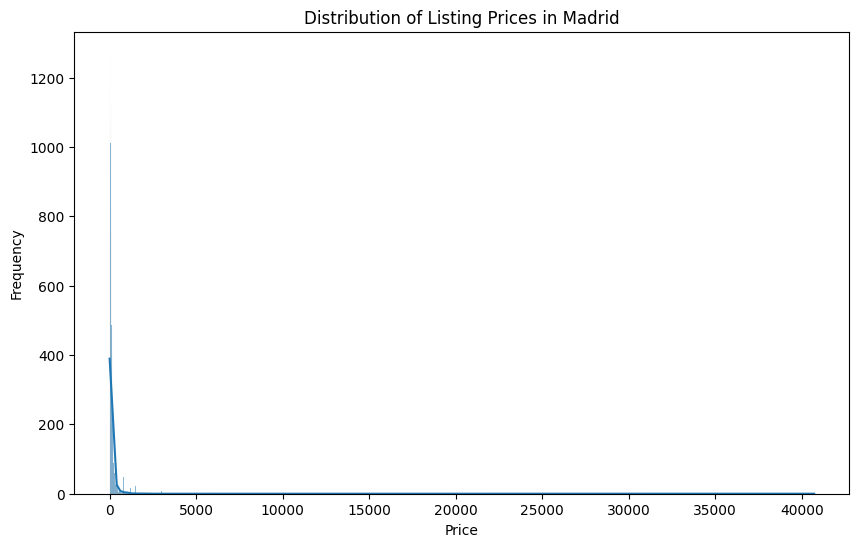

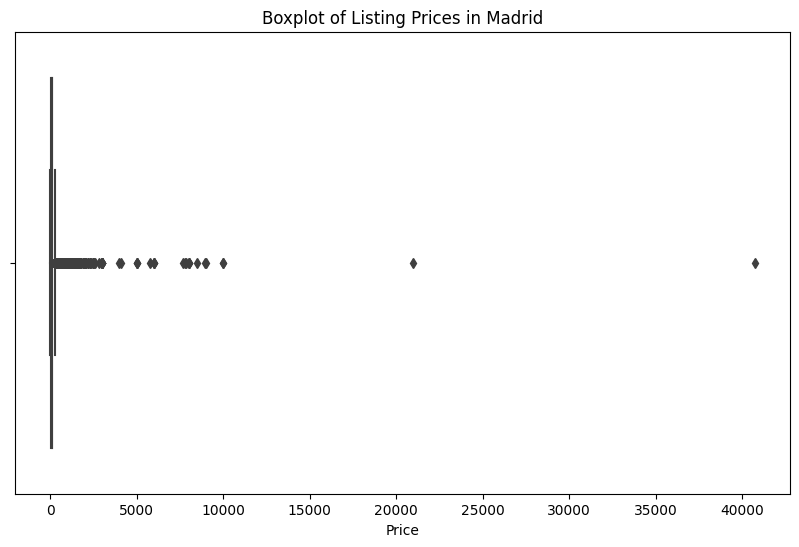

In [ ]:
# Convert 'price' to a numeric value, removing any non-numeric characters like '$'
new_dfs[df_key]['price'] = pd.to_numeric(new_dfs[df_key]['price'].replace('[\$,]', '', regex=True), errors='coerce')

# Histogram of listing prices
plt.figure(figsize=(10, 6))
sns.histplot(new_dfs[df_key]['price'], kde=True)
plt.title('Distribution of Listing Prices in Madrid')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

# Boxplot of listing prices
plt.figure(figsize=(10, 6))
sns.boxplot(x=new_dfs[df_key]['price'])
plt.title('Boxplot of Listing Prices in Madrid')
plt.xlabel('Price')
plt.show()

* The histogram of listing prices in Madrid shows that the vast majority of listings are priced at the lower end of the scale, with a sharp peak close to zero. This indicates that affordable listings dominate the market. However, there are a few listings with extremely high prices, which are likely outliers.

* The boxplot reveals that while the central range of prices (the box) is quite narrow, indicating that most prices are clustered within a small range, there are several outliers far above the upper whisker. These outliers could represent luxury accommodations or could be due to data entry errors.

* For our project, these visuals suggest a skewed distribution of listing prices, with a concentration on the lower end and a few extremely high-value listings. It is important to investigate the outliers to determine whether they are genuine luxury listings or anomalies that should be cleaned from the dataset. Understanding this distribution will be crucial for developing predictive pricing models and making strategic recommendations for pricing strategies. It's also important to normalize or transform the price variable for any modelling to mitigate the skewness and potential influence of outliers.

**Investigate Any Outliers in the Price Data**

In [ ]:
# Calculating IQR to identify outliers
Q1 = new_dfs[df_key]['price'].quantile(0.25)
Q3 = new_dfs[df_key]['price'].quantile(0.75)
IQR = Q3 - Q1
outlier_threshold = Q3 + 1.5 * IQR

# Counting number of outliers
outliers = new_dfs[df_key][new_dfs[df_key]['price'] > outlier_threshold]
print(f"Number of Outliers: {len(outliers)}")
print(f"Outlier Threshold: {outlier_threshold}")

Number of Outliers: 1735
Outlier Threshold: 275.0


After visualizing the price column, and considereing dropping the outliers, since we don't really know what to do with them yet and there quite a few, we at least decided to get rid of the highest ones that are making it difficult to read most of our grapghs properly.

In [ ]:
# Sort the DataFrame by the 'price' column in descending order
sorted_df = new_dfs[df_key].sort_values(by='price', ascending=False)

# Drop the top two rows (the highest price values)
new_dfs[df_key] = sorted_df.iloc[3:]

# Optionally, reset the index if you want a clean, sequential index
new_dfs[df_key].reset_index(drop=True, inplace=True)

**Examine the Relationship Between Price and Other Numerical Variables**

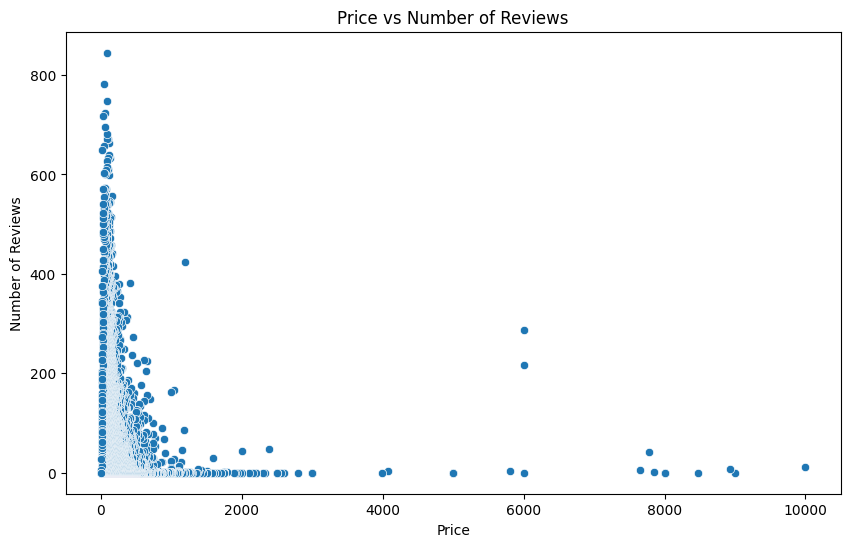

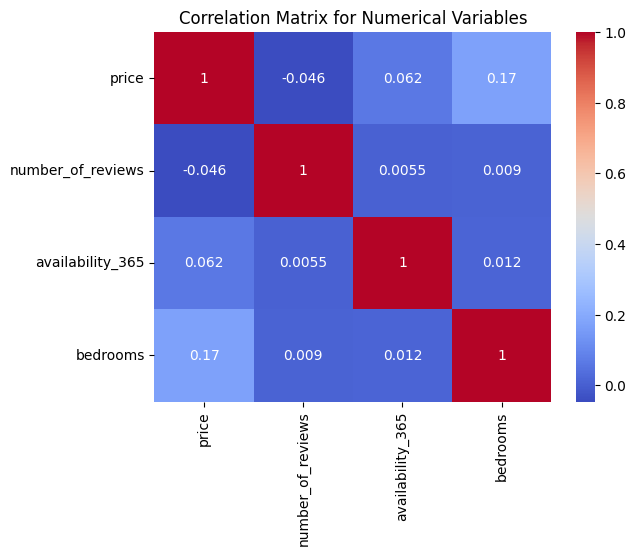

In [ ]:
# Scatter plot between price and numerical variables like 'number_of_reviews'
plt.figure(figsize=(10, 6))
sns.scatterplot(x='price', y='number_of_reviews', data=new_dfs[df_key])
plt.title('Price vs Number of Reviews')
plt.xlabel('Price')
plt.ylabel('Number of Reviews')
plt.show()

# Correlation analysis
numerical_vars = ['price', 'number_of_reviews', 'availability_365', 'bedrooms']  # Include other relevant numerical variables
correlation_matrix = new_dfs[df_key][numerical_vars].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix for Numerical Variables')
plt.show()

* The scatter plot and correlation matrix show a weak relationship between price and the number of reviews, suggesting that higher prices don't necessarily equate to a higher number of reviews. It's also noteworthy that there is a slight positive correlation between price and the number of bedrooms, which is intuitive, as larger properties with more bedrooms are likely to be priced higher. The slight correlation with the number of bedrooms could be used to help determine pricing strategies based on property size.

### Analysis of Location-Based Pricing

**Group the data by neighborhood and calculate average, median, and range of prices**

In [ ]:
# Group the data by neighbourhood and calculate average, median, and range of prices.

neighbourhood_pricing = new_dfs[df_key].groupby('neighbourhood_cleansed')['price'].agg(['mean', 'median', 'max', 'min'])
neighbourhood_pricing['range'] = neighbourhood_pricing['max'] - neighbourhood_pricing['min']
print(neighbourhood_pricing)

                              mean  median     max   min   range
neighbourhood_cleansed                                          
Abrantes                 79.147059    39.0   820.0  14.0   806.0
Acacias                 111.781250    60.5  5000.0  17.0  4983.0
Adelfas                  76.230769    65.0   220.0  23.0   197.0
Aeropuerto              117.541667    74.5   550.0  18.0   532.0
Aguilas                 248.476190    39.0  8000.0  15.0  7985.0
...                            ...     ...     ...   ...     ...
Valverde                 91.565657    65.0   600.0  10.0   590.0
Ventas                  104.688742    41.0  3000.0   9.0  2991.0
Vinateros                49.045455    21.5   450.0  12.0   438.0
Vista Alegre             54.877049    41.0   400.0   9.0   391.0
Zofío                    58.695652    37.0   340.0  15.0   325.0

[128 rows x 5 columns]


* These statistics indicate that some neighborhoods have a wide range of listing prices, which could reflect a diverse housing market with both budget and luxury accommodations. For our project, neighborhoods with large ranges could be of particular interest as they may offer opportunities for price optimization based on various property features and market demand. Additionally, the neighborhoods' mean and median prices can help identify areas that could yield higher revenue potential or require competitive pricing strategies.

**Visualize geographical price variations using maps**

In [ ]:
# Create 'cleaned_df' by dropping rows with for example missing latitude or longitude
cleaned_df = new_dfs[df_key].dropna(subset=['latitude', 'longitude', 'price', 'neighbourhood_cleansed'])

# Now, we create a heatmap data list
heat_data = [[row['latitude'], row['longitude'], row['price']] for idx, row in cleaned_df.iterrows()]

# Create a map centered around Madrid
madrid_map = folium.Map(location=[new_dfs[df_key]['latitude'].mean(), new_dfs[df_key]['longitude'].mean()], zoom_start=13)

# Convert price data to list of tuples (latitude, longitude, weight)
heat_data = [[row['latitude'], row['longitude'], row['price']] for idx, row in cleaned_df.iterrows()]

# Add heatmap layer to the map
plugins.HeatMap(heat_data, radius=15).add_to(madrid_map)

# Display the map
madrid_map

The heatmap visualizations represent the concentration and distribution of Airbnb listing prices in Madrid. The intensity of the colors, ranging from blue to red, indicates the density of listings at different price points, with red signifying higher prices and blue indicating lower prices. From the images, it is evident that there is a significant cluster of higher-priced listings in the central areas, which likely correspond to popular tourist districts or areas with high demand. The spread of warm colors to the outskirts suggests that there are also pricier options available outside the center, possibly offering larger or more luxurious accommodations. These maps are instrumental for identifying areas of high rental activity and can guide pricing strategies to reflect local demand and competition.

In [ ]:
# Visualize geographical price variations using maps.
# Create a map centered around Madrid
madrid_map = folium.Map(location=[new_dfs[df_key]['latitude'].mean(), new_dfs[df_key]['longitude'].mean()], zoom_start=13)

# Add points to the map
for idx, row in cleaned_df.iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=3,
        popup=f"${row['price']}",
        color='blue' if row['price'] <= neighbourhood_pricing['median'][row['neighbourhood_cleansed']] else 'red',
        fill=True
    ).add_to(madrid_map)

# Display the map
madrid_map

Output hidden; open in https://colab.research.google.com to view.

* The map visualization indicates that listing prices vary across different neighborhoods. The use of blue and red markers to differentiate prices below and above the median suggests that there may be clusters of higher-priced and lower-priced listings, potentially reflecting the socio-economic diversity across neighborhoods. Proximity to central areas or popular tourist destinations could be influencing these price variations, a common trend in urban accommodation pricing.

**Investigate any noticeable trends in pricing based on proximity to key tourist attractions or transport hubs**

<ipython-input-88-b0c831e4b2f9>:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleaned_df['distance_to_central'] = cleaned_df.apply(calculate_distance, axis=1)


         neighbourhood_cleansed       price  distance_to_central
114                         Sol  160.128920             0.266622
40                       Cortes  150.879570             0.530548
83                      Palacio  141.333333             0.793652
50                  Embajadores  119.311667             0.804351
65                     Justicia  139.622568             0.841259
..                          ...         ...                  ...
48                   El Plantío  103.846154            12.038942
27   Casco Histórico de Barajas   93.057143            12.318203
46                    El Goloso  135.969697            12.399853
3                    Aeropuerto  117.541667            16.041366
47                     El Pardo  213.000000            20.539114

[128 rows x 3 columns]


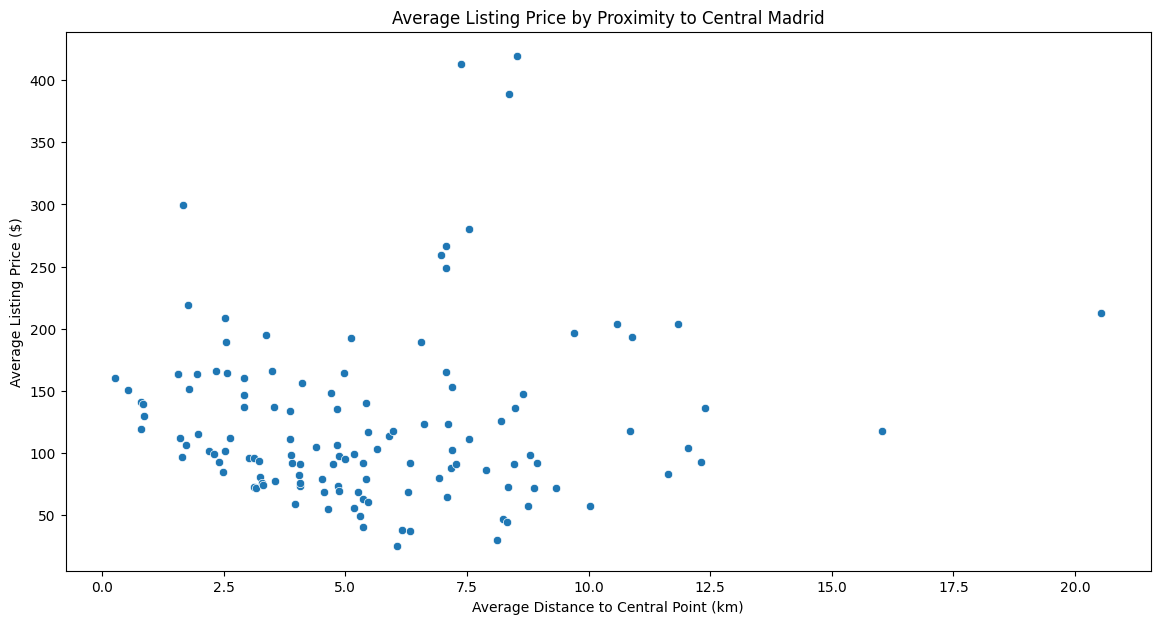

In [ ]:
# Assuming central points for key tourist attractions or transport hubs are the following:
# Let's say these are the coordinates for a central point in Madrid
central_point = {'latitude': 40.4167, 'longitude': -3.7033}

# Ensure that the DataFrame does not contain NaN values in latitude and longitude
cleaned_df = new_dfs[df_key].dropna(subset=['latitude', 'longitude'])

# Now, let's calculate the distance of each listing to this central point
def calculate_distance(row):
    listing_coords = (row['latitude'], row['longitude'])
    central_coords = (central_point['latitude'], central_point['longitude'])
    return great_circle(listing_coords, central_coords).km

cleaned_df['distance_to_central'] = cleaned_df.apply(calculate_distance, axis=1)

# Group by neighborhood and calculate average price and average distance to the central point
pricing_by_proximity = cleaned_df.groupby('neighbourhood_cleansed').agg({'price':'mean', 'distance_to_central':'mean'}).reset_index()

# Now, let's sort by average distance to central point and see the average prices
pricing_by_proximity.sort_values('distance_to_central', inplace=True)
print(pricing_by_proximity)

# Visualize the relationship between average price and average distance to central point
plt.figure(figsize=(14, 7))
sns.scatterplot(data=pricing_by_proximity, x='distance_to_central', y='price')
plt.title('Average Listing Price by Proximity to Central Madrid')
plt.xlabel('Average Distance to Central Point (km)')
plt.ylabel('Average Listing Price ($)')
plt.show()


* The scatter plot titled "Average Listing Price by Proximity to Central Madrid" and the provided data snippet illustrate a correlation between the average listing prices of Airbnb accommodations and their distance from a central point in Madrid, presumably a popular area or tourist attraction.

* From the plot, we can discern a trend where the average listing price tends to be higher closer to the central point, with neighborhoods like Sol and Cortes, which are less than a kilometer away from the central point, showing some of the highest average prices. This pattern suggests that proximity to the city center, which is often a hub for tourism and activities, commands a premium in listing prices.

* However, the spread of the data points also indicates that there are listings with both high and low prices at various distances from the central point. For instance, while El Pardo, the furthest neighborhood at over 20 km from the central point, has a high average price of 213, this is not the case for all distant neighborhoods. The neighborhood of Aeropuerto, although quite far from the center at approximately 16 km, shows a more moderate average price of $117.54.

* This variability implies that while location is a significant factor in pricing, other factors like property quality, size, and amenities also play essential roles. For the project, this analysis underscores the importance of geographic location in pricing strategies, but also points to the necessity of a multi-faceted approach that considers a combination of factors for optimal price setting.

### Seasonal Analysis of Pricing

**Extract month or season information**

In [ ]:
# Convert 'last_review' to datetime
new_dfs['df_madrid_new']['last_review'] = pd.to_datetime(new_dfs['df_madrid_new']['last_review'])

# Extract month and year from 'last_review' to a new column
new_dfs['df_madrid_new']['review_month'] = new_dfs['df_madrid_new']['last_review'].dt.month
new_dfs['df_madrid_new']['review_year'] = new_dfs['df_madrid_new']['last_review'].dt.year

# Drop rows where review month/year is NaN
seasonal_df = new_dfs['df_madrid_new'].dropna(subset=['review_month', 'review_year'])

<ipython-input-89-0ad6d4da3a64>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs['df_madrid_new']['last_review'] = pd.to_datetime(new_dfs['df_madrid_new']['last_review'])
<ipython-input-89-0ad6d4da3a64>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs['df_madrid_new']['review_month'] = new_dfs['df_madrid_new']['last_review'].dt.month
<ipython-input-89-0ad6d4da3a64>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_in

**Analyze average price variations by month or season/Explore any apparent relationships between special events/holidays and pricing**

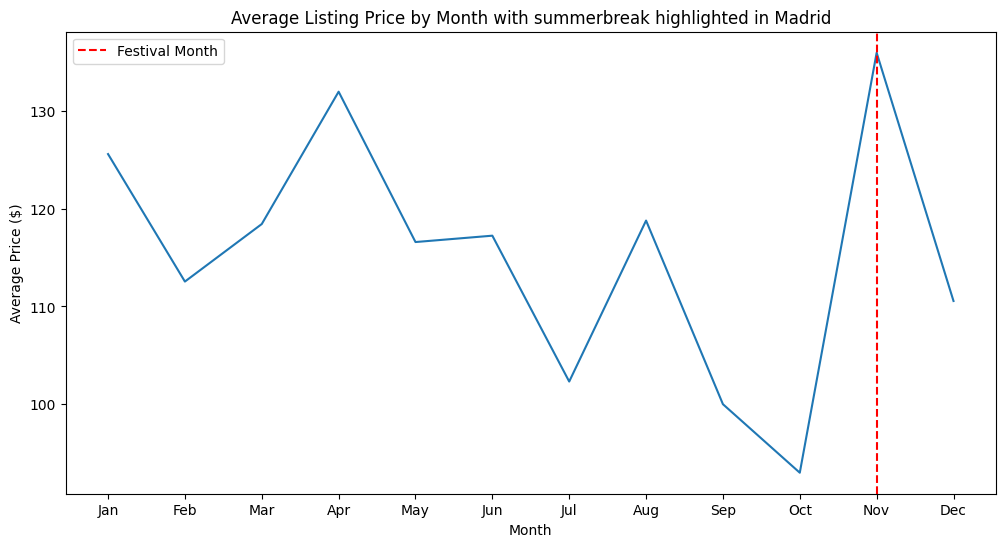

In [ ]:
# We now analyze specific events or holidays
# For example, we now explore November:
monthly_price = seasonal_df.groupby('review_month')['price'].mean().reset_index()
plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_price, x='review_month', y='price')
plt.axvline(x=11, color='red', linestyle='--', label='Festival Month')
plt.title('Average Listing Price by Month with summerbreak highlighted in Madrid')
plt.xlabel('Month')
plt.ylabel('Average Price ($)')
plt.legend()
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.show()


In Madrid, the housing market goes through ups and downs during the year. In April, prices go up a bit because it's springtime, and more tourists come, creating a greater need for short-term places to stay. Then, in November, prices shoot up even more as the holiday season starts. This is probably because more people need places to stay, whether they're visiting for the holidays or locals hosting festive events.

### Property Characteristics Analysis

**Analyze the effect of property type and size on price**

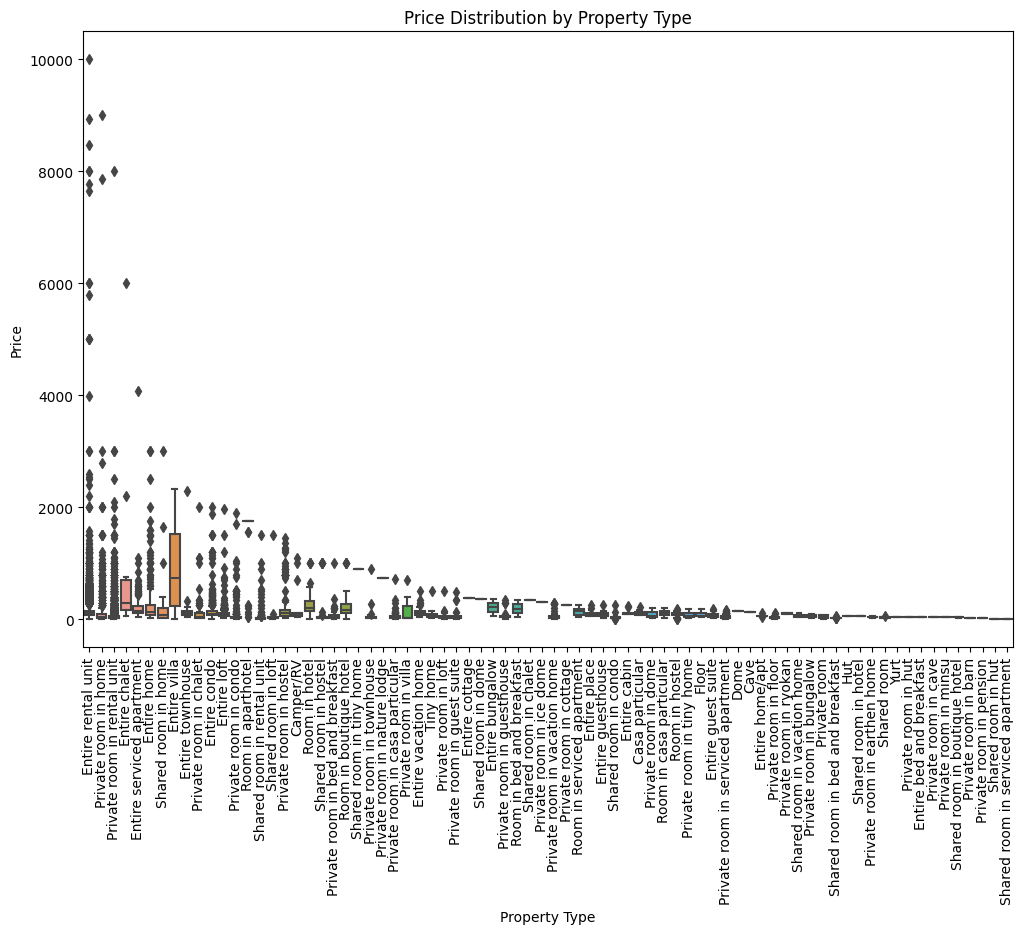

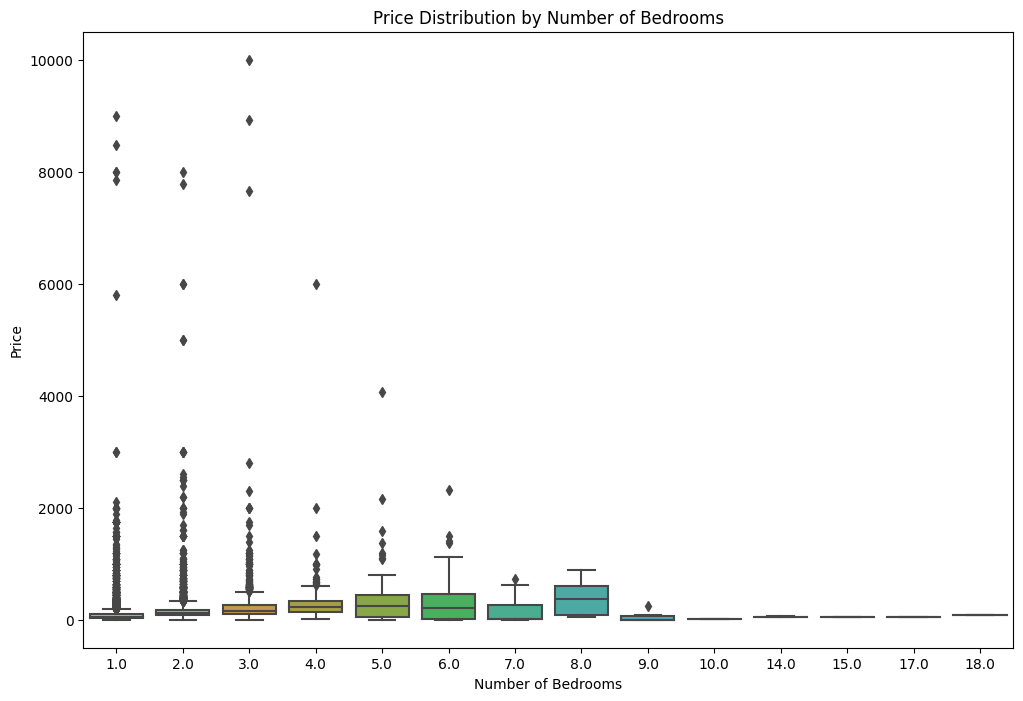

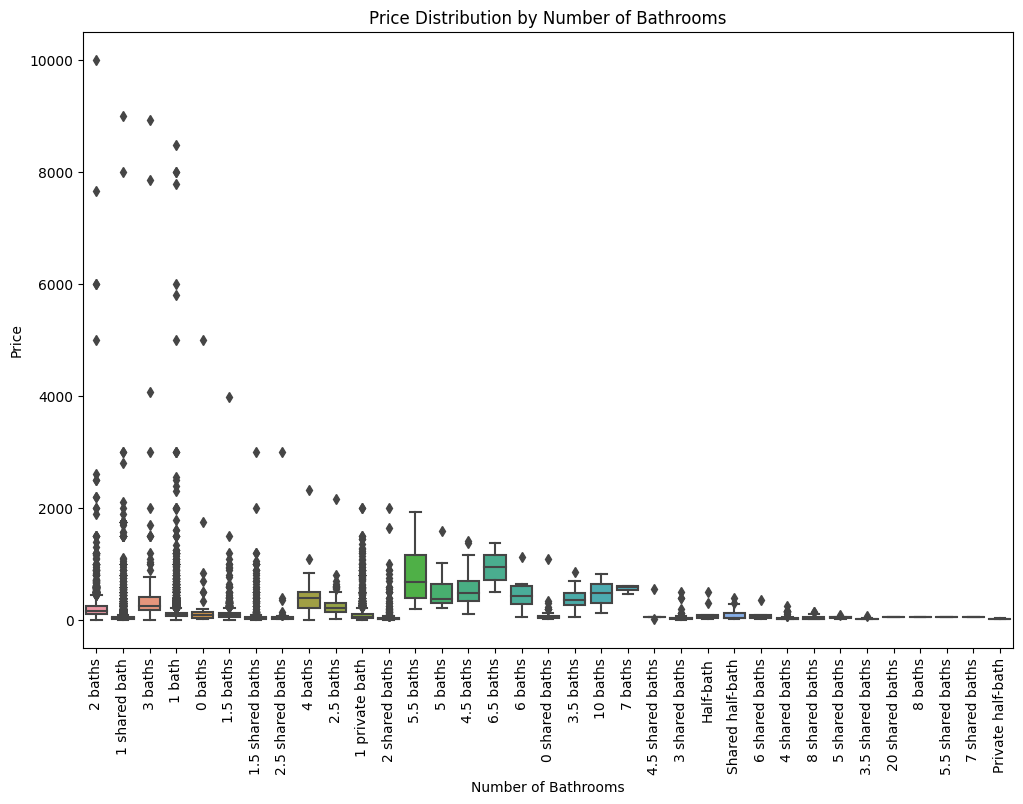

In [ ]:
# Analyze the effect of property type on price
plt.figure(figsize=(12, 8))
sns.boxplot(data=new_dfs[df_key], x='property_type', y='price')
plt.xticks(rotation=90)
plt.title('Price Distribution by Property Type')
plt.xlabel('Property Type')
plt.ylabel('Price')
plt.show()

# Analyze the effect of the number of bedrooms on price
plt.figure(figsize=(12, 8))
sns.boxplot(data=new_dfs[df_key], x='bedrooms', y='price')
plt.title('Price Distribution by Number of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Price')
plt.show()

# Analyze the effect of the number of bathrooms on price
plt.figure(figsize=(12, 8))
sns.boxplot(data=new_dfs[df_key], x='bathrooms_text', y='price')
plt.xticks(rotation=90)
plt.title('Price Distribution by Number of Bathrooms')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Price')
plt.show()

* **Price Distribution by Property Type**:
This boxplot illustrates the distribution of prices across different property types. The spread and median of prices vary significantly by property type, indicating that certain types of properties tend to be priced higher than others. The presence of outliers across many property types suggests that there are some unusually high-priced listings within each category, which could be due to luxury features, exceptional locations, or special amenities.

* **Price Distribution by Number of Bedrooms**:
The boxplot for the price distribution by the number of bedrooms shows a general trend where the median price increases with the number of bedrooms. This trend is expected as larger properties typically command higher prices. However, the number of outliers seems to decrease with more bedrooms, and the spread of prices is wider for properties with fewer bedrooms. This could indicate a more significant variation in the types of smaller properties available, from budget to luxury offerings. For our project, this implies that pricing strategies could be adjusted based on the size of the property, with more nuanced pricing within categories with more significant variability.

* **Price Distribution by Number of Bathrooms**:
In the boxplot showing the price distribution by the number of bathrooms, we again see a variation in median prices based on the number of bathrooms, although it's less pronounced than with bedrooms. There are outliers present, particularly in listings with fewer bathrooms, suggesting that even properties with fewer bathrooms can command high prices, possibly due to other premium features or desirable locations. The variation in price within each category indicates that the number of bathrooms is a factor in pricing, but it may be influenced by other factors as well.

In summary, these visualizations highlight the importance of property characteristics in setting prices. Larger properties with more bedrooms or bathrooms generally have higher median prices, but there is significant price variability within each category. Outliers in each category will need to be assessed to determine if they represent a premium segment of the market or if they should be considered anomalies for the purposes of your analysis.



<ipython-input-92-3e6a9a297b16>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['bathrooms_text'] = df['bathrooms_text'].astype(str)
<ipython-input-92-3e6a9a297b16>:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['bathrooms_number'] = df['bathrooms_text'].apply(extract_bathroom_number)


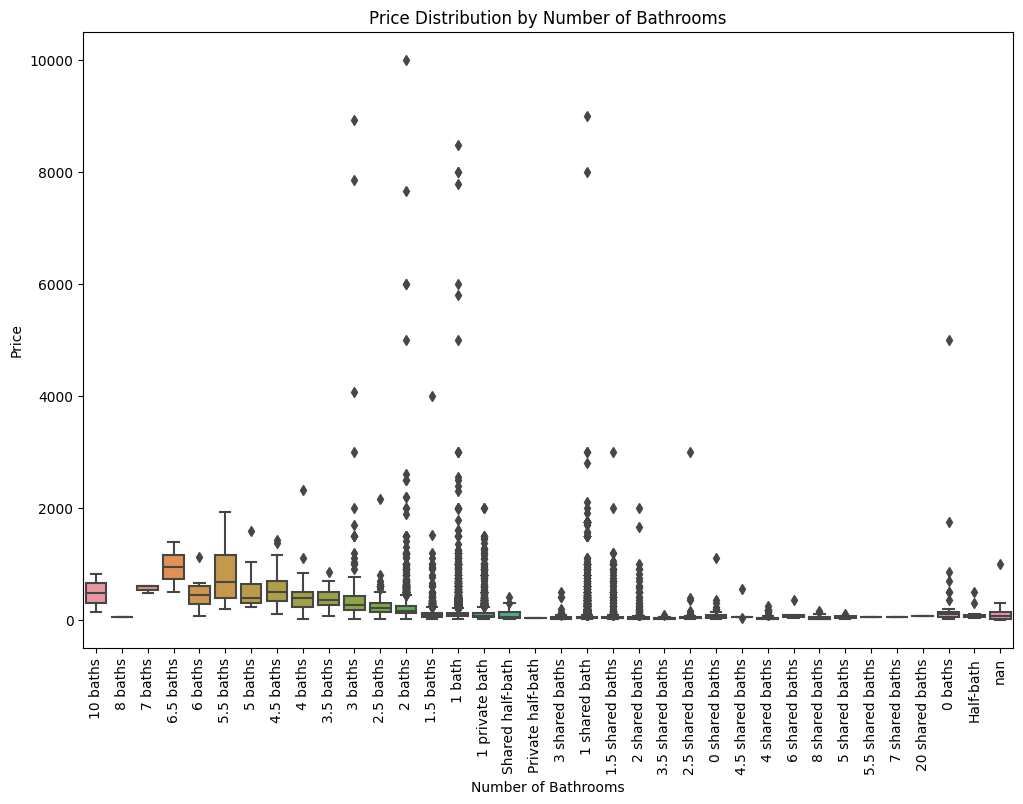

In [ ]:
df = new_dfs[df_key]

# Convert 'bathrooms_text' to a string to ensure consistent processing
df['bathrooms_text'] = df['bathrooms_text'].astype(str)

# Define a custom function to extract numerical value for sorting
def extract_bathroom_number(text):
    # Handle special cases like 'Shared bath', 'Private half-bath', etc.
    if 'half' in text:
        return 0.5
    elif 'shared' in text:
        return 0.01  # Assuming shared is less than half
    elif 'private' in text:
        return 0.75  # Assuming private is more than half but less than 1
    else:
        # Extract the number (assuming it's the first part of the string)
        number = text.split(' ')[0]
        try:
            return float(number)
        except ValueError:
            return 0  # In case of any unconvertible values

# Apply the function to create a new 'bathrooms_number' column for sorting
df['bathrooms_number'] = df['bathrooms_text'].apply(extract_bathroom_number)

# Sort the DataFrame based on this new column
df_sorted = df.sort_values(by='bathrooms_number', ascending=False)

# Now create the plot
plt.figure(figsize=(12, 8))
sns.boxplot(data=df_sorted, x='bathrooms_text', y='price', order=df_sorted['bathrooms_text'].unique())
plt.xticks(rotation=90)
plt.title('Price Distribution by Number of Bathrooms')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Price')
plt.show()

For a better visualisation we sort the bathrooms.

**Utilize violin plots to visualize price distributions by accommodation capacity**

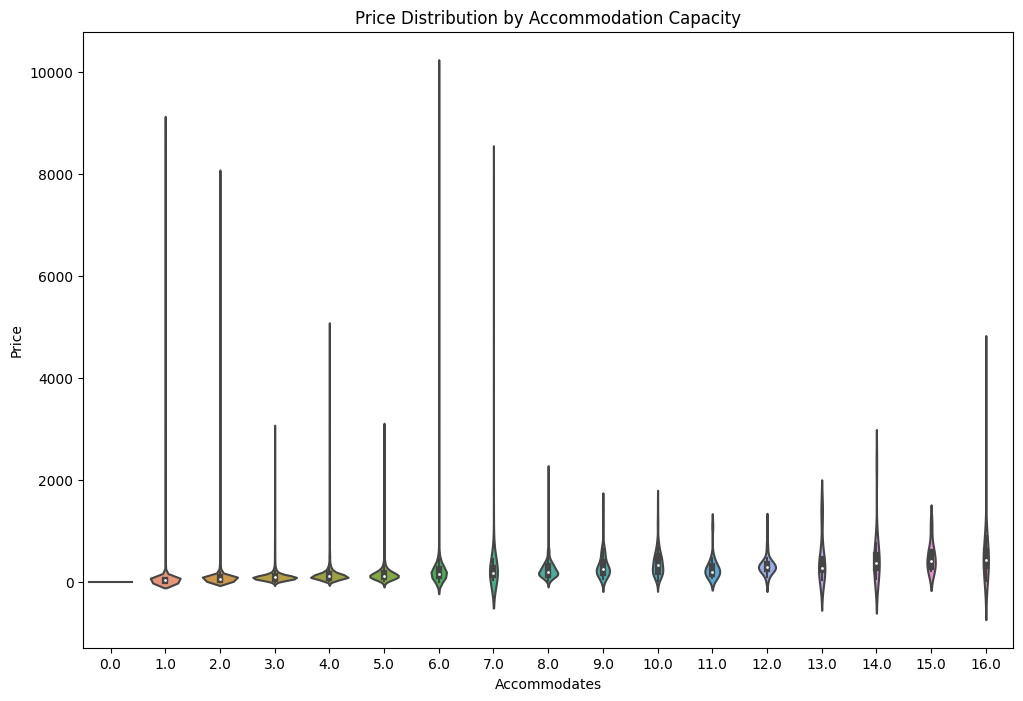

In [ ]:
# Analyze the effect of the number of accommodation capacity on price
plt.figure(figsize=(12, 8))
sns.violinplot(data=new_dfs['df_madrid_new'], x='accommodates', y='price')
plt.title('Price Distribution by Accommodation Capacity')
plt.xlabel('Accommodates')
plt.ylabel('Price')
plt.show()

* The "Price Distribution by Accommodation Capacity" graph shows how the price of listings varies with the capacity of the accommodation (how many people it can accommodate). The x-axis represents the accommodation capacity, ranging from 1 to 16 people. The y-axis represents the price of the listings. Each violin shape suggests the price frequency for a given capacity, with wider sections indicating higher data concentration. Notably, there's a significant price range for single-person accommodations, with some extreme outliers, while prices for accommodations hosting two to ten persons appear more uniform with fewer outliers.

### Host-Related Factors Analysis


**Examine the relationship between host response rate, superhost status, and pricing**


<ipython-input-94-f5302356a83b>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['host_response_rate_num'] = new_dfs[df_key]['host_response_rate'].str.replace('%', '').astype(float) / 100
<ipython-input-94-f5302356a83b>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['superhost'] = new_dfs[df_key]['host_is_superhost'].map({'t': 1, 'f': 0})


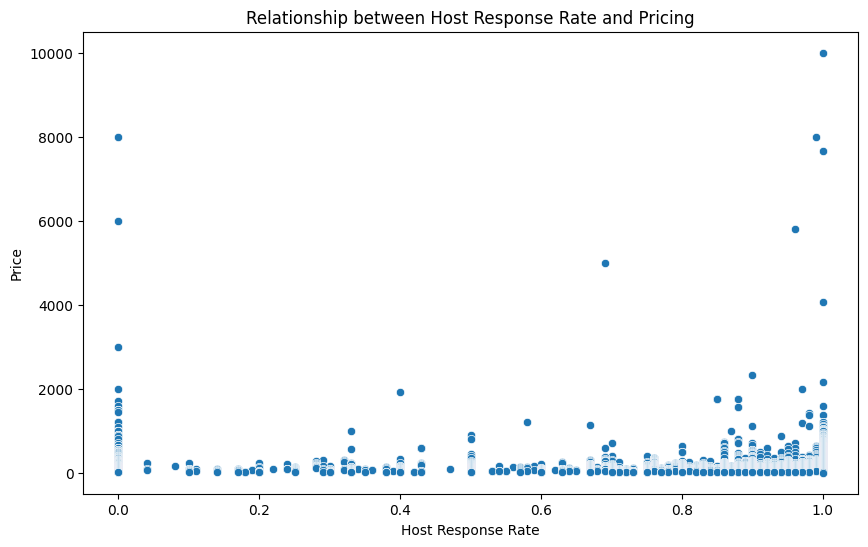

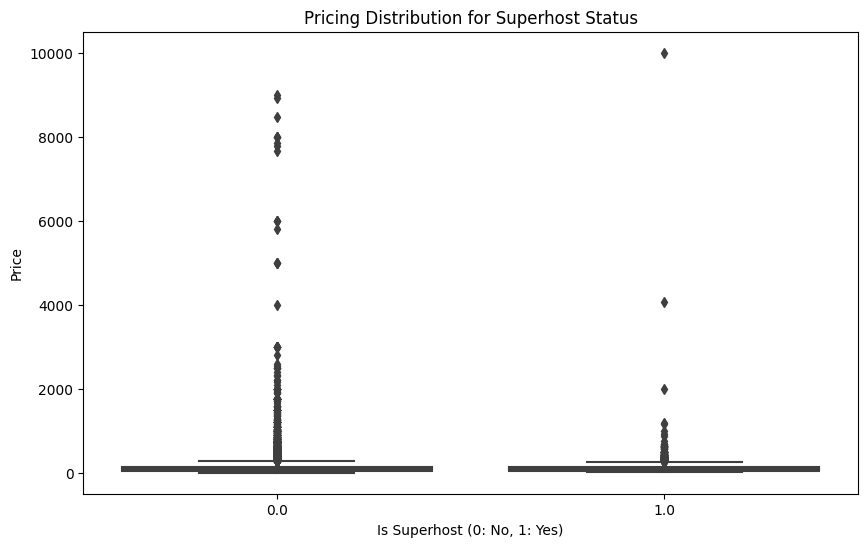

In [ ]:
# Convert host response rate to a numerical value
new_dfs[df_key]['host_response_rate_num'] = new_dfs[df_key]['host_response_rate'].str.replace('%', '').astype(float) / 100

# Convert superhost status to a numerical value
new_dfs[df_key]['superhost'] = new_dfs[df_key]['host_is_superhost'].map({'t': 1, 'f': 0})

# Scatter plot for host response rate and pricing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=new_dfs[df_key], x='host_response_rate_num', y='price')
plt.title('Relationship between Host Response Rate and Pricing')
plt.xlabel('Host Response Rate')
plt.ylabel('Price')
plt.show()

# Boxplot for superhost status and pricing
plt.figure(figsize=(10, 6))
sns.boxplot(data=new_dfs[df_key], x='superhost', y='price')
plt.title('Pricing Distribution for Superhost Status')
plt.xlabel('Is Superhost (0: No, 1: Yes)')
plt.ylabel('Price')
plt.show()

* For the graph "Relationship between Host Response Rate and Pricing," it appears that the majority of listings, regardless of the host's response rate, are clustered at the lower end of the price spectrum. There are some listings at higher price points across various response rates, with a notable outlier at a response rate of 1 (or 100%) that significantly exceeds the general price range. This suggests that while a high response rate may be associated with some high-priced listings, there is no clear or consistent pattern indicating that response rate alone dictates pricing.

* In the "Pricing Distribution for Superhost Status" plot, both superhosts and non-superhosts mostly have listings in the lower price range. However, there are outliers in both categories with significantly higher prices. The plot does not show a distinct difference in pricing between superhosts and non-superhosts, indicating that superhost status does not necessarily lead to higher prices. The majority of listings for both groups are modestly priced, which may suggest that guests are not consistently willing to pay a premium for superhost listings, or that superhosts do not always charge more.

**Investigate if the number of listings per host affects pricing strategies**

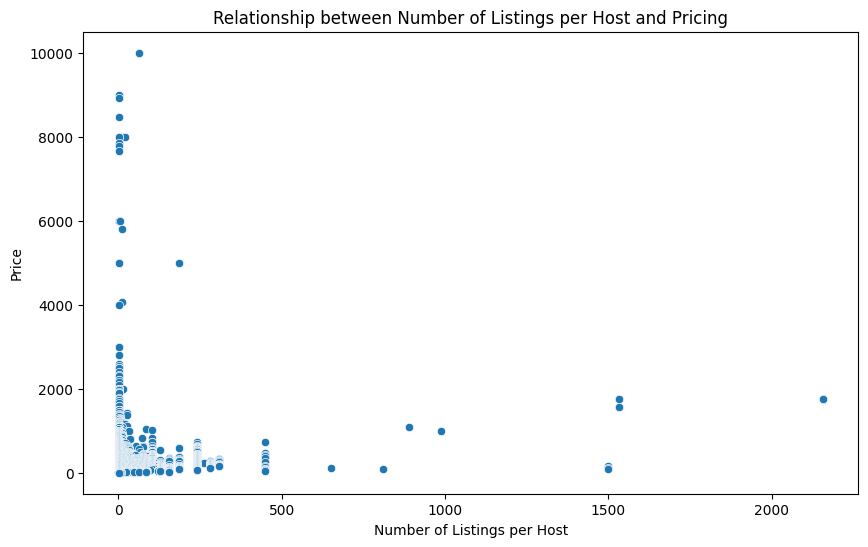

In [ ]:
# Scatter plot for number of listings per host and pricing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=new_dfs[df_key], x='host_listings_count', y='price')
plt.title('Relationship between Number of Listings per Host and Pricing')
plt.xlabel('Number of Listings per Host')
plt.ylabel('Price')
plt.show()

* The plot depicts that hosts with a smaller number of listings tend to have a wide range of prices, with many clustered at the lower end, suggesting that individual or small-scale hosts may offer more competitive or budget-friendly options. There's a significant outlier with a very high price from a host with few listings. As the number of listings per host increases, there's less variability in price, with most prices remaining low, but a few hosts with many listings have some offerings at higher prices. This could indicate that hosts with a larger number of listings may standardize their prices, focusing on volume over premium pricing, although the capacity for higher-priced listings still exists among these hosts.

**Analyze the impact of host ratings and reviews on pricing**

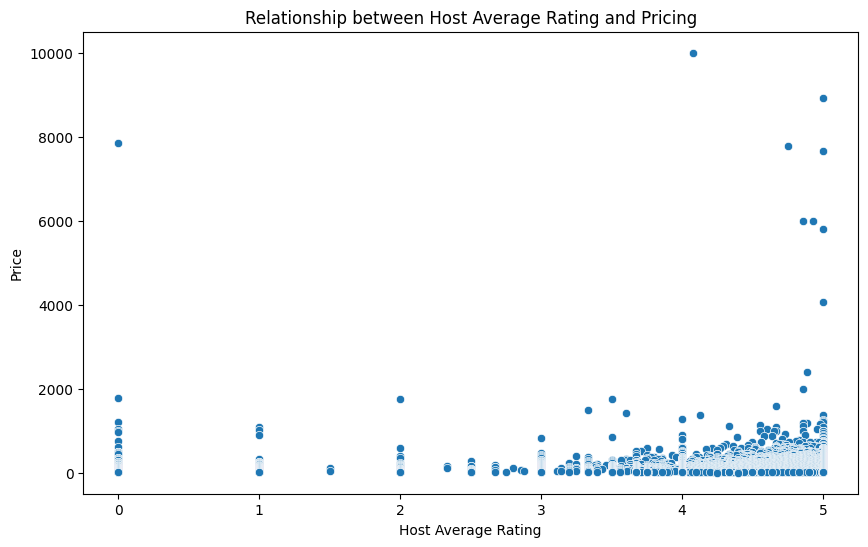

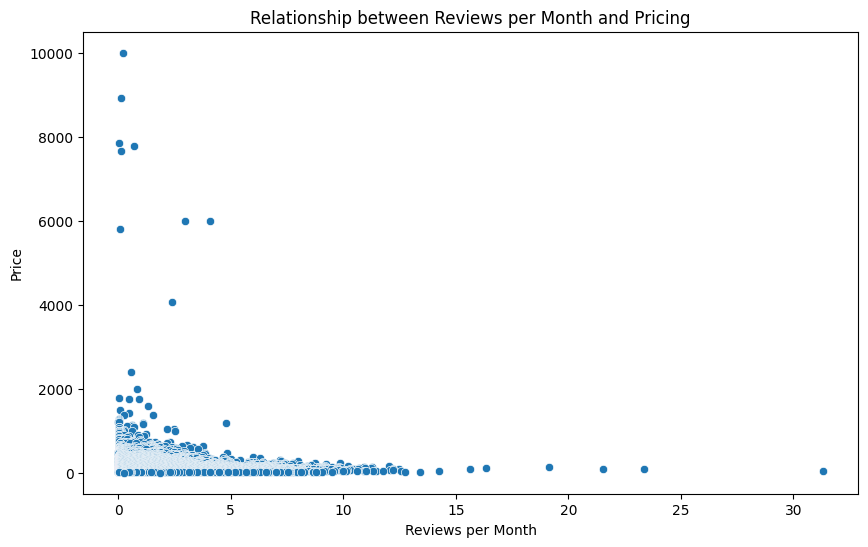

In [ ]:
# Assuming 'review_scores_rating' is the average rating for the host
# Scatter plot for host average rating and pricing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=new_dfs[df_key], x='review_scores_rating', y='price')
plt.title('Relationship between Host Average Rating and Pricing')
plt.xlabel('Host Average Rating')
plt.ylabel('Price')
plt.show()

# Assuming 'reviews_per_month' is an indicator for host reviews frequency
# Scatter plot for reviews per month and pricing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=new_dfs[df_key], x='reviews_per_month', y='price')
plt.title('Relationship between Reviews per Month and Pricing')
plt.xlabel('Reviews per Month')
plt.ylabel('Price')
plt.show()

* The "Relationship between Host Average Rating and Pricing" graph suggests that there is not a strong, clear relationship between a host's average rating and the pricing of their listings. Most listings, regardless of price, have high ratings close to 5, which is common in platforms where ratings tend to be positively skewed. The graph also shows a few listings with very high prices across the rating spectrum, indicating that some high-priced listings have a broad range of host ratings.

* In the "Relationship between Reviews per Month and Pricing" graph, we observe that listings with a wide range of reviews per month are mostly clustered at the lower end of the price spectrum. There are a few listings with a high number of reviews per month that also command higher prices, which could suggest a positive experience or high demand for those listings. However, the majority of data points are concentrated at the lower price range, regardless of the number of reviews per month, indicating that frequent reviews do not necessarily correlate with higher pricing.

### Advanced Statistical Analysis

**Conduct hypothesis testing to check if differences in pricing between various groups are statistically significant**

In [ ]:
# Hypothesis Testing Between Superhosts and non-Superhosts
# Convert price to numeric and remove any non-numeric characters
new_dfs[df_key]['price'] = pd.to_numeric(new_dfs[df_key]['price'].replace('[\$,]', '', regex=True))

# Split the data into two groups: Superhosts and non-Superhosts
superhost_prices = new_dfs[df_key][new_dfs[df_key]['host_is_superhost'] == 't']['price']
non_superhost_prices = new_dfs[df_key][new_dfs[df_key]['host_is_superhost'] == 'f']['price']

# Perform a t-test
t_stat, p_value = ttest_ind(superhost_prices, non_superhost_prices, equal_var=False)
print(f"T-statistic: {t_stat}, P-value: {p_value}")

# If the data is not normally distributed, use Mann-Whitney U test
u_stat, p_value_u = mannwhitneyu(superhost_prices, non_superhost_prices)
print(f"U-statistic: {u_stat}, P-value: {p_value_u}")

T-statistic: -5.760018233807924, P-value: 8.726504203430872e-09
U-statistic: 32852353.0, P-value: 0.001874177750303676


<ipython-input-97-a2451a87c405>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['price'] = pd.to_numeric(new_dfs[df_key]['price'].replace('[\$,]', '', regex=True))


* In the context of our project, the hypothesis testing between Superhosts and non-Superhosts yields significant results. The negative T-statistic indicates that, on average, Superhosts tend to charge less for their listings compared to non-Superhosts, with a P-value that is significantly less than the conventional threshold of 0.05. This is corroborated by the Mann-Whitney U test, which confirms the significant difference in pricing distributions between the two groups, as indicated by its P-value. Given the data is not normally distributed, the Mann-Whitney U test's results are particularly relevant, suggesting that achieving Superhost status might not necessarily lead to higher listing prices. This insight is crucial for informing pricing strategies within the project, as it highlights the complex relationship between host status and pricing that might be influenced by factors other than just the Superhost label.

In [ ]:
# Hypothesis Testing Based on Host Identity Verification
# (Works just if the code is loaded completely)
# Convert host_identity_verified to 0s and 1s
new_dfs[df_key]['host_identity_verified'] = new_dfs[df_key]['host_identity_verified'].map({'f': 0, 't': 1})

# Extract prices for verified and non-verified hosts
verified_host_prices = new_dfs[df_key][new_dfs[df_key]['host_identity_verified'] == 1]['price']
non_verified_host_prices = new_dfs[df_key][new_dfs[df_key]['host_identity_verified'] == 0]['price']

# Perform t-test between verified and non-verified host prices
t_stat_verified, p_value_verified = ttest_ind(verified_host_prices, non_verified_host_prices, equal_var=False)
print(f"T-statistic for Host Verification: {t_stat_verified}, P-value: {p_value_verified}")

# Perform Mann-Whitney U test as a non-parametric test
u_stat, p_value_u = mannwhitneyu(verified_host_prices, non_verified_host_prices)
print(f"U-statistic: {u_stat}, P-value: {p_value_u}")

T-statistic for Host Verification: -4.989849257151216, P-value: 6.228618297395404e-07
U-statistic: 38368513.0, P-value: 2.1286523144601002e-34


<ipython-input-98-f3cc3c192071>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['host_identity_verified'] = new_dfs[df_key]['host_identity_verified'].map({'f': 0, 't': 1})


* For our project, the statistical tests conducted to assess the impact of host identity verification on pricing reveal significant findings. The negative T-statistic indicates that verified hosts generally charge less than non-verified hosts, and the very small P-value from the T-test signals strong evidence against the null hypothesis, suggesting that this result is statistically significant. Furthermore, the Mann-Whitney U test, which is more appropriate given the non-normal distribution of our data, also shows a very small P-value, reinforcing the conclusion that there is a substantial difference in the pricing strategies of verified versus non-verified hosts. These results suggest that within the scope of our project, host verification may play a role in pricing decisions, potentially affecting how guests perceive the value of listings and how hosts position their pricing in the competitive Airbnb market.

In [ ]:
# Hypothesis Testing Based on Instant Bookable Feature
# (Works just if the code is loaded completely)
# Convert instant_bookable to 0s and 1s
new_dfs[df_key]['instant_bookable'] = new_dfs[df_key]['instant_bookable'].map({'f': 0, 't': 1})

# Extract prices for listings with and without instant booking
instant_prices = new_dfs[df_key][new_dfs[df_key]['instant_bookable'] == 1]['price']
no_instant_prices = new_dfs[df_key][new_dfs[df_key]['instant_bookable'] == 0]['price']

# Perform t-test between instant bookable and non-instant bookable prices
t_stat_instant, p_value_instant = ttest_ind(instant_prices, no_instant_prices, equal_var=False)
print(f"T-statistic for Instant Booking: {t_stat_instant}, P-value: {p_value_instant}")

# Perform Mann-Whitney U test as a non-parametric test
u_stat, p_value_u = mannwhitneyu(instant_prices, no_instant_prices)
print(f"U-statistic: {u_stat}, P-value: {p_value_u}")

<ipython-input-99-9d252cdcdd9d>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['instant_bookable'] = new_dfs[df_key]['instant_bookable'].map({'f': 0, 't': 1})


T-statistic for Instant Booking: 11.943904950879604, P-value: 9.009876662771762e-33
U-statistic: 64383141.0, P-value: 1.0355693262992653e-155


* In the context of our project, the analysis of the instant bookable feature's influence on pricing strategy indicates a significant effect. The positive T-statistic from the t-test suggests that listings with the instant bookable feature are priced higher than those without, and the exceptionally low P-value provides strong evidence to support this conclusion. Moreover, the Mann-Whitney U test, which is better suited for our data's non-normal distribution, corroborates this finding with an exceedingly small P-value, emphasizing the robustness of this result. These outcomes imply that the instant bookable option is likely perceived as an added convenience by guests, allowing hosts to command a premium for offering this feature. For our project's aim of establishing optimal pricing strategies, these insights are particularly valuable, indicating that enabling instant booking could be leveraged as a strategic advantage in the marketplace.

In [ ]:
# Hypothesis Testing Based on Accommodation Size
# Group the data by accommodation size
accommodates_pricing = new_dfs[df_key].groupby('accommodates')['price'].agg(['mean', 'count'])

# Let's compare small (1-2 people) vs. large (more than 2 people) accommodations
small_accommodation_prices = new_dfs[df_key][new_dfs[df_key]['accommodates'] <= 2]['price']
large_accommodation_prices = new_dfs[df_key][new_dfs[df_key]['accommodates'] > 2]['price']

# Perform t-test between small and large accommodation prices
t_stat_accommodates, p_value_accommodates = ttest_ind(small_accommodation_prices, large_accommodation_prices, equal_var=False)
print(f"T-statistic for Accommodation Size: {t_stat_accommodates}, P-value: {p_value_accommodates}")

# Perform Mann-Whitney U test as a non-parametric test
u_stat, p_value_u = mannwhitneyu(small_accommodation_prices, large_accommodation_prices)
print(f"U-statistic: {u_stat}, P-value: {p_value_u}")

T-statistic for Accommodation Size: -22.65328728297577, P-value: 3.799544072431728e-112
U-statistic: 20519244.0, P-value: 0.0


* For our project, the statistical tests conducted to evaluate the impact of accommodation size on pricing provide a clear indication that larger accommodations tend to be priced higher than smaller ones. The t-test's large negative T-statistic and exceedingly small P-value, along with a U-statistic from the Mann-Whitney U test that also points to a significant result, confirm that the difference in pricing between small and large accommodations is not by chance. Given the non-normal distribution of our data, the Mann-Whitney U test's P-value of 0.0 is especially telling, suggesting a very strong likelihood that accommodation size is a key determinant in pricing strategy. These findings underscore the importance of considering property size in our predictive models and pricing recommendations, to help hosts strategically price their listings in line with market expectations and revenue optimization goals.

## Mallorca

### Initial Data Exploration

In [ ]:
# Analyzing the DataFrame mallorca_df

df = mallorca_df  # Replace df with mallorca_df for the analysis

# Number of variables (columns)
num_variables = len(df.columns)
print(f"Number of variables (columns) in mallorca_df: {num_variables}")

# Number of observations (rows)
num_observations = len(df)
print(f"Number of observations (rows) in mallorca_df: {num_observations}")

# Missing cells per variable (column)
missing_cells = df.isnull().sum()
print("Missing cells per variable (column) in mallorca_df:")
print(missing_cells)

# Number of duplicated rows
duplicate_rows = df[df.duplicated(keep='first')]
num_duplicate_rows = len(duplicate_rows)
print(f"Number of duplicate rows in mallorca_df: {num_duplicate_rows}")

# Check for missing values in the entire dataset
has_missing_values = df.isnull().values.any()
print(f"Missing values in the entire mallorca_df dataset: {has_missing_values}")

Number of variables (columns) in mallorca_df: 18
Number of observations (rows) in mallorca_df: 19049
Missing cells per variable (column) in mallorca_df:
id                                    0
name                                  1
host_id                               0
host_name                            51
neighbourhood_group               19049
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                        5116
reviews_per_month                  5116
calculated_host_listings_count        0
availability_365                      0
number_of_reviews_ltm                 0
license                            7399
dtype: int64
Number of duplicate rows in mallorca_df: 0
Missing values in the entire mallorca_df dataset: True


The mallorca_df dataset consists of 18 variables (columns) and 19049 observations (rows). There are no duplicate rows, indicating unique entries across the dataset. However, it contains missing values in several columns. Again the license and reviews columns are showing a  significant amount of missing data, which could affect analyses related to regulatory compliance. But also the neighbourhood group column seems to be empty.

In [ ]:
# Analyzing the DataFrame mallorca2_df

df = mallorca2_df  # Replace df with mallorca2_df for the analysis

# Number of variables (columns)
num_variables = len(df.columns)
print(f"Number of variables (columns) in mallorca2_df: {num_variables}")

# Number of observations (rows)
num_observations = len(df)
print(f"Number of observations (rows) in mallorca2_df: {num_observations}")

# Missing cells per variable (column)
missing_cells = df.isnull().sum()
print("Missing cells per variable (column) in mallorca2_df:")
print(missing_cells)

# Number of duplicated rows
duplicate_rows = df[df.duplicated(keep='first')]
num_duplicate_rows = len(duplicate_rows)
print(f"Number of duplicate rows in mallorca2_df: {num_duplicate_rows}")

# Check for missing values in the entire dataset
has_missing_values = df.isnull().values.any()
print(f"Missing values in the entire mallorca2_df dataset: {has_missing_values}")

Number of variables (columns) in mallorca2_df: 75
Number of observations (rows) in mallorca2_df: 19049
Missing cells per variable (column) in mallorca2_df:
id                                                 0
listing_url                                        0
scrape_id                                          0
last_scraped                                       0
source                                             0
                                                ... 
calculated_host_listings_count                     0
calculated_host_listings_count_entire_homes        0
calculated_host_listings_count_private_rooms       0
calculated_host_listings_count_shared_rooms        0
reviews_per_month                               5116
Length: 75, dtype: int64
Number of duplicate rows in mallorca2_df: 0
Missing values in the entire mallorca2_df dataset: True


The mallorca2_df dataset is more extensive, with 75 variables and 1904 observations. Like mallorca_df, this dataset also has no duplicate rows, ensuring the uniqueness of the listings. The dataset's complexity is increased due to a higher number of variables, leading to a more comprehensive range of missing values across different columns. The 'reviews_per_month' column again shows a significant number of missing values, indicating a similar trend as observed in mallorca_df. The large number of variables offers a richer dataset for analysis but also introduces more complexity in handling missing data. For our project, the decision to either simplify the dataset by removing less relevant variables or to address these missing values through imputation or exclusion will be crucial in shaping our analysis approach.

In [ ]:
# Identify duplicate and unique listings in Mallorca datasets
set1, set2 = set(mallorca_df['id']), set(mallorca2_df['id'])
duplicates = set1.intersection(set2)
unique_in_df1 = set1.difference(set2)
unique_in_df2 = set2.difference(set1)

# Display information about duplicates and unique IDs
print("Duplicates:", duplicates)
print("Unique in DataFrame 1:", unique_in_df1)
print("Unique in DataFrame 2:", unique_in_df2)

Duplicates: {675339877969264641, 7831554, 594052167294681091, 602479129787400199, 45711369, 44564490, 38240267, 19464207, 44433423, 53149712, 553560209581080593, 19529747, 4161556, 21102614, 54034462, 49020958, 36896800, 1146914, 15794211, 663476875700043818, 16449584, 631887835829927985, 49512502, 38240312, 1015869, 21889085, 625810924252921920, 32931909, 560465613000212550, 29589575, 525297517302415433, 31260749, 710915685715542093, 25821264, 51478608, 41386067, 619891741756751956, 33030229, 34340949, 21004375, 51511383, 632441925786599524, 49283173, 26247271, 17596521, 17825900, 24674412, 646287476525793388, 47775855, 51282033, 6324338, 587386600147026035, 49152116, 696895771079245940, 664187879803158648, 2490491, 630906478519025790, 39518334, 16154752, 29982850, 48169090, 50430087, 42008718, 562916248929861774, 20447378, 39944338, 43450515, 39878805, 4751510, 47579285, 562360363023597717, 26247321, 34406554, 29425819, 44335260, 41549981, 24117406, 50167970, 52396198, 40468652, 5082

* The output indicates that there are all duplicate listings between mallorca_df and mallorca2_df, as evidenced by the empty Unique in Dataframe sets. This suggests that each dataset contains the same listings, which is valuable for a comprehensive analysis meaning that by only using one of them, it this case the mallorca2_df we would not only have more data, but the number of properties listed are the same.

In [ ]:
# Initialize the dictionary to store the modified DataFrame
new_dfs = {}

# Define the key for the modified DataFrame of mallorca
df_key = 'df_mallorca_new'

# Specify the columns to drop from the mallorca2_df
columns_to_drop = [
   'id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview',
   'picture_url', 'host_id', 'host_url', 'host_name', 'host_location', 'host_about',
   'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood',
   'calendar_updated', 'has_availability', 'availability_30', 'availability_60',
   'availability_90', 'calendar_last_scraped'
]

# Drop the specified columns from mallorca2_df and store it in the new_dfs dictionary
new_dfs[df_key] = mallorca2_df.drop(columns=columns_to_drop)

# Print the remaining columns in the modified DataFrame
print(f"\nRemaining columns in {df_key}: {new_dfs[df_key].columns.tolist()}")


Remaining columns in df_mallorca_new: ['host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'first_review', 'last_review', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'license', 'ins

In [ ]:
# Descriptive analysis of the dataset
print("Summary Statistics:\n")
print(new_dfs[df_key].describe())

Summary Statistics:

       host_listings_count  host_total_listings_count  \
count         18998.000000               18998.000000   
mean            161.478050                 288.866618   
std             277.196175                 542.646378   
min               1.000000                   1.000000   
25%               2.000000                   3.000000   
50%              17.000000                  28.000000   
75%             179.000000                 302.000000   
max            1811.000000               20000.000000   

       neighbourhood_group_cleansed      latitude     longitude  accommodates  \
count                           0.0  19049.000000  19049.000000  19049.000000   
mean                            NaN     39.659080      3.000765      5.667279   
std                             NaN      0.169308      0.242839      2.711112   
min                             NaN     39.301970      2.346610      0.000000   
25%                             NaN     39.541100      2.840

The dataset consists of 18,998 listings with a wide range of host listings count, indicating a diverse set of hosts from individuals to possibly commercial entities.
The majority of properties accommodate between 3 to 5 people, suggesting a focus on small to medium-sized groups.
The review scores are generally high (above 4.5 on average), which implies a good overall guest satisfaction.
The bathrooms column lacks data (all values are NaN), which might require imputation or dropping the column for further analysis.
The high standard deviations in host listings count and review scores suggest variability in host activity and guest experiences.

In [ ]:
# Data types of columns
print("\nData Types of Each Column:\n")
print(new_dfs[df_key].dtypes)


Data Types of Each Column:

host_since                                       object
host_response_time                               object
host_response_rate                               object
host_acceptance_rate                             object
host_is_superhost                                object
host_listings_count                             float64
host_total_listings_count                       float64
host_verifications                               object
host_has_profile_pic                             object
host_identity_verified                           object
neighbourhood                                    object
neighbourhood_cleansed                           object
neighbourhood_group_cleansed                    float64
latitude                                        float64
longitude                                       float64
property_type                                    object
room_type                                        object
accommodates       

The dataset contains a mix of numerical (int64, float64) and categorical/object (string) data types, which is typical for accommodation listings.
Some columns that appear to be numeric (like price) are actually stored as objects, indicating the presence of non-numeric characters (e.g., currency symbols) and a need for data cleaning.

In [ ]:
# Check uniqueness
print("\nUniqueness of Each Column:\n")
print(new_dfs[df_key].nunique())


Uniqueness of Each Column:

host_since                                       2900
host_response_time                                  4
host_response_rate                                 53
host_acceptance_rate                               95
host_is_superhost                                   2
host_listings_count                               139
host_total_listings_count                         170
host_verifications                                  7
host_has_profile_pic                                2
host_identity_verified                              2
neighbourhood                                     918
neighbourhood_cleansed                             53
neighbourhood_group_cleansed                        0
latitude                                        15985
longitude                                       16392
property_type                                      81
room_type                                           4
accommodates                                       17

There's a diverse range of amenities, with 16796 unique entries, suggesting a wide variety of features offered across listings.
The significant variety in license, host_verifications, and review_per_month can offer insights into the regulation compliance, host verification process, and popularity of listings.

In [ ]:
# Show first 10 rows
print("\nFirst 10 rows:\n")
print(new_dfs[df_key].head(10))


First 10 rows:

   host_since  host_response_time host_response_rate host_acceptance_rate  \
0  2009-10-02  within a few hours               100%                  92%   
1  2011-01-19      within an hour               100%                 100%   
2  2011-05-01                 NaN                NaN                  NaN   
3  2011-05-02  within a few hours               100%                  75%   
4  2011-06-30      within an hour               100%                 100%   
5  2015-05-16                 NaN                NaN                  NaN   
6  2011-06-09  within a few hours               100%                  77%   
7  2011-07-08      within an hour               100%                 100%   
8  2011-07-11  within a few hours               100%                  67%   
9  2011-07-11  within a few hours                93%                 100%   

  host_is_superhost  host_listings_count  host_total_listings_count  \
0                 f                  1.0                        

The first 10 rows provide a glimpse into the dataset's structure, showing details like host response time, room type, amenities, and review scores.
Some fields such as license and reviews_per_month contain NaN values, indicating missing data that may need addressing.
The variety in instant_bookable, property_type, and room_type reflects the diversity of the listings.

Further observations:

Variability in Host Listings: There's a wide range in the number of listings per host, with some having just one and others managing thousands. This indicates a diversity in host types, from individuals to large-scale operators.

Geographical Spread: The latitude and longitude data points to a geographical spread of properties. The location is a crucial factor in pricing, as different areas have different demand and price points.

Accommodation Capacity: The accommodates, bedrooms, and beds columns show a range of property sizes. Larger properties (more beds and bedrooms) likely command higher prices.

Minimum Nights and Availability: The minimum_nights and availability_365 columns suggest varied booking and availability patterns. This can impact pricing strategy, especially considering peak and off-peak seasons.

Review Scores: High average scores across various review categories indicate generally positive guest experiences. Higher-rated properties might be able to charge more.

Recent Reviews and Review Frequency: The number_of_reviews_l30d and reviews_per_month indicate recent activity and overall review frequency. Properties with more frequent reviews may be more popular and could potentially price higher.

Missing Data in Bathrooms: The consistent absence of data in the bathrooms column across datasets might require data imputation or a decision to exclude this variable from pricing models.

These insights are crucial for developing a dynamic pricing model. They highlight the importance of considering a range of factors - from property size and type, host's portfolio size, geographical location, to guest satisfaction and booking patterns - for setting optimal prices.

### Detailed Analysis of Pricing Variable

Analyze the Distribution of Listing Prices

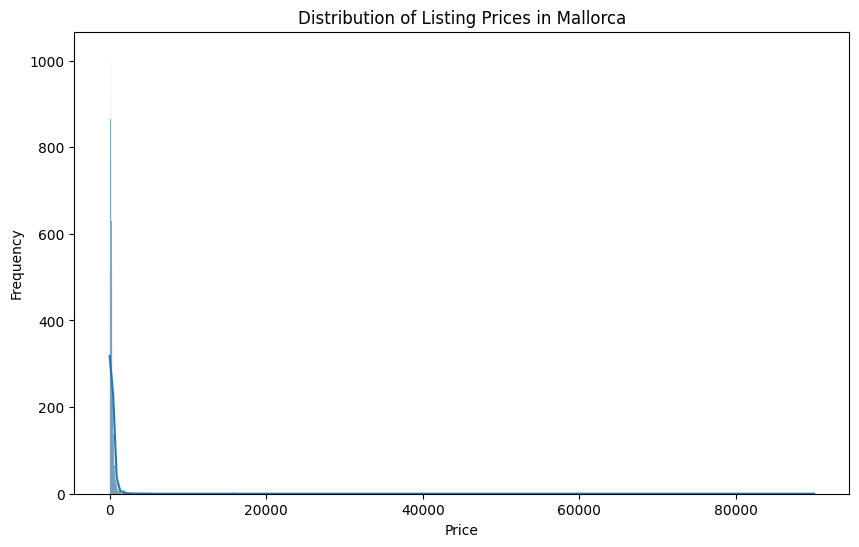

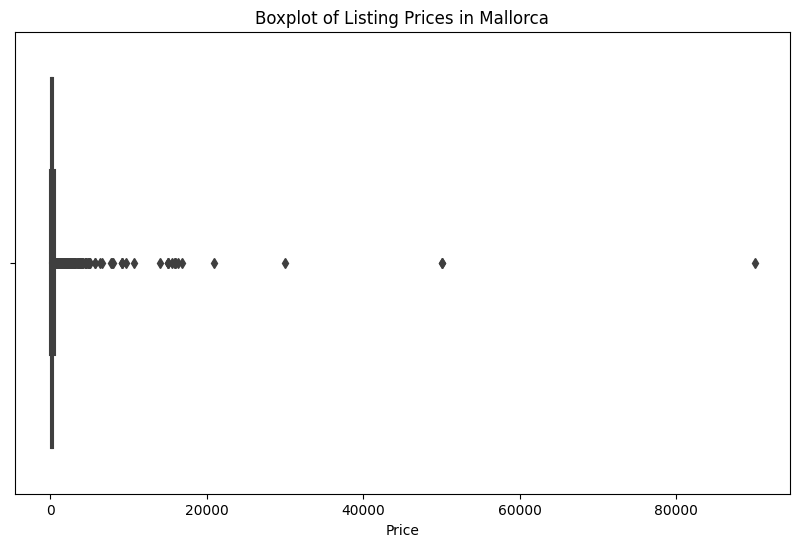

In [ ]:
# Convert 'price' to a numeric value, removing any non-numeric characters like '$'
new_dfs[df_key]['price'] = pd.to_numeric(new_dfs[df_key]['price'].replace('[\$,]', '', regex=True), errors='coerce')

# Histogram of listing prices
plt.figure(figsize=(10, 6))
sns.histplot(new_dfs[df_key]['price'], kde=True)
plt.title('Distribution of Listing Prices in Mallorca')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

# Boxplot of listing prices
plt.figure(figsize=(10, 6))
sns.boxplot(x=new_dfs[df_key]['price'])
plt.title('Boxplot of Listing Prices in Mallorca')
plt.xlabel('Price')
plt.show()

The histogram of listing prices in Mallorca show that the vast majority of listings are priced at the lower end of the scale, as seen in the other cities. This indicates that affordable listings dominate the market. However, there are a few listings with extremely high prices, which are likely outliers.

The boxplot reveals that there are several outliers far above the upper whisker. These outliers could represent luxury accommodations or could be due to data entry errors.


**Investigate Any Outliers in the Price Data**

In [ ]:
# Calculating IQR to identify outliers
Q1 = new_dfs[df_key]['price'].quantile(0.25)
Q3 = new_dfs[df_key]['price'].quantile(0.75)
IQR = Q3 - Q1
outlier_threshold = Q3 + 1.5 * IQR

# Counting number of outliers
outliers = new_dfs[df_key][new_dfs[df_key]['price'] > outlier_threshold]
print(f"Number of Outliers: {len(outliers)}")
print(f"Outlier Threshold: {outlier_threshold}")

Number of Outliers: 1629
Outlier Threshold: 625.0


**Examine the Relationship Between Price and Other Numerical Variables**

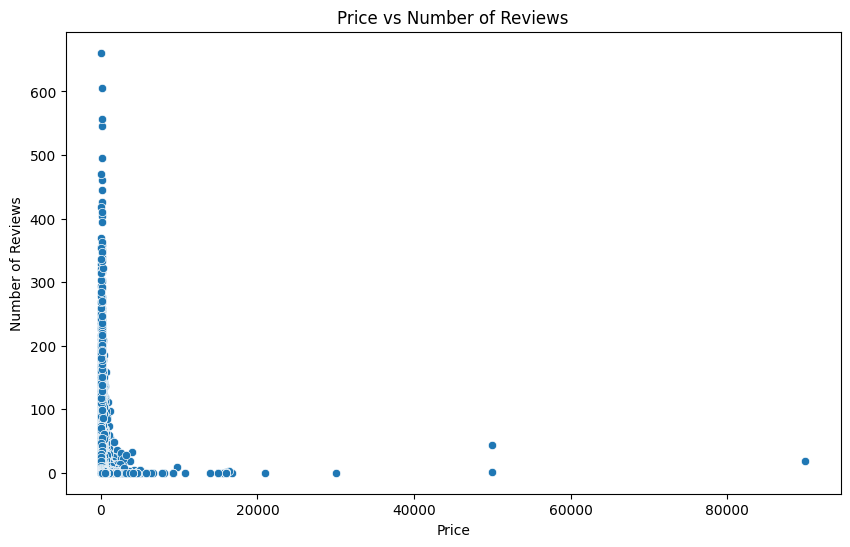

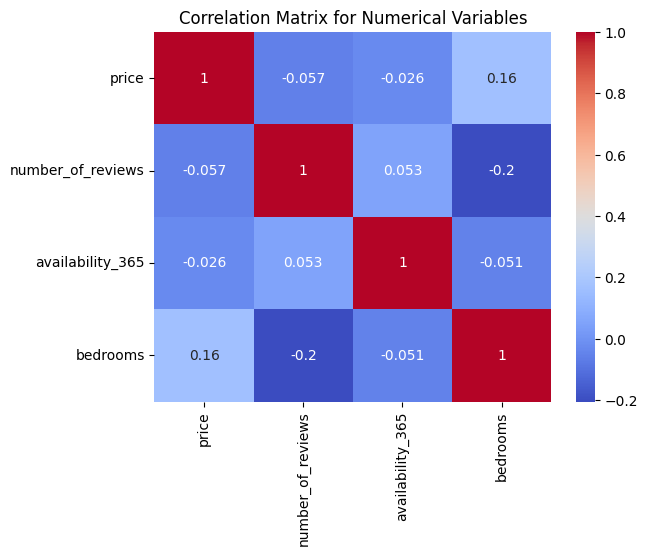

In [ ]:
# Scatter plot between price and numerical variables like 'number_of_reviews'
plt.figure(figsize=(10, 6))
sns.scatterplot(x='price', y='number_of_reviews', data=new_dfs[df_key])
plt.title('Price vs Number of Reviews')
plt.xlabel('Price')
plt.ylabel('Number of Reviews')
plt.show()

# Correlation analysis
numerical_vars = ['price', 'number_of_reviews', 'availability_365', 'bedrooms']  # Include other relevant numerical variables
correlation_matrix = new_dfs[df_key][numerical_vars].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix for Numerical Variables')
plt.show()

* The scatter plot and correlation matrix show a weak relationship between price and the number of reviews, suggesting that higher prices don't necessarily equate to a higher number of reviews. It's also noteworthy that there is a slight positive correlation between price and the number of bedrooms, which is intuitive, as larger properties with more bedrooms are likely to be priced higher. The slight correlation with the number of bedrooms could be used to help determine pricing strategies based on property size.

### Analysis of Location-Based Pricing

**Group the data by neighborhood and calculate average, median, and range of prices**

In [ ]:
# Group the data by neighbourhood and calculate average, median, and range of prices.

neighbourhood_pricing = new_dfs[df_key].groupby('neighbourhood_cleansed')['price'].agg(['mean', 'median', 'max', 'min'])
neighbourhood_pricing['range'] = neighbourhood_pricing['max'] - neighbourhood_pricing['min']
print(neighbourhood_pricing)

                                  mean  median      max   min    range
neighbourhood_cleansed                                                
Alaró                       407.650407   180.0  14000.0  10.0  13990.0
Alcúdia                     293.229969   213.0   6668.0  10.0   6658.0
Algaida                     272.242188   195.5   1080.0  10.0   1070.0
Andratx                     645.277992   260.0  10776.0  10.0  10766.0
Ariany                      292.854839   189.5   1799.0  10.0   1789.0
Artà                        330.183983   226.5   9713.0  15.0   9698.0
Banyalbufar                 320.904762   174.0   2695.0  15.0   2680.0
Binissalem                  284.346154   198.0   1236.0  15.0   1221.0
Bunyola                     330.604938   265.0   1910.0  52.0   1858.0
Búger                       326.362069   282.5    958.0  15.0    943.0
Calvià                      383.115966   190.0   8000.0  10.0   7990.0
Campanet                    231.407609   186.0   1759.0  15.0   1744.0
Campos

* These statistics indicate that some neighborhoods have a wide range of listing prices, which could reflect a diverse housing market with both budget and luxury accommodations. For our project, neighborhoods with large ranges could be of particular interest as they may offer opportunities for price optimization based on various property features and market demand. Additionally, the neighborhoods' mean and median prices can help identify areas that could yield higher revenue potential or require competitive pricing strategies.

**Visualize geographical price variations using maps**

In [ ]:
# Visualize geographical price variations using maps.
# Create a map centered around Mallorca
mallorca_map = folium.Map(location=[new_dfs[df_key]['latitude'].mean(), new_dfs[df_key]['longitude'].mean()], zoom_start=13)

# Add points to the map
for idx, row in new_dfs[df_key].iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=3,
        popup=f"${row['price']}",
        color='blue' if row['price'] <= neighbourhood_pricing['median'][row['neighbourhood_cleansed']] else 'red',
        fill=True
    ).add_to(mallorca_map)

# Display the map
mallorca_map

Output hidden; open in https://colab.research.google.com to view.

* Same as Euskadi Mallorca represents the whole island, with many touristic places and atracction, whe thought that maybe it would be smart to divide the data from each mayor city in the island, but after some more thought, we concluded that it would be smarter to just drop it, and work with the other mayor cities in Spain. The reason would be first to create an effective model. After this we can think about expanding and including this.

## Menorca

### Initial Data Exploration

In [ ]:
# Analyzing the DataFrame menorca_df

df = menorca_df  # Replace df with menorca_df for the analysis

# Number of variables (columns)
num_variables = len(df.columns)
print(f"Number of variables (columns) in menorca_df: {num_variables}")

# Number of observations (rows)
num_observations = len(df)
print(f"Number of observations (rows) in menorca_df: {num_observations}")

# Missing cells per variable (column)
missing_cells = df.isnull().sum()
print("Missing cells per variable (column) in menorca_df:")
print(missing_cells)

# Number of duplicated rows
duplicate_rows = df[df.duplicated(keep='first')]
num_duplicate_rows = len(duplicate_rows)
print(f"Number of duplicate rows in menorca_df: {num_duplicate_rows}")

# Check for missing values in the entire dataset
has_missing_values = df.isnull().values.any()
print(f"Missing values in the entire menorca_df dataset: {has_missing_values}")

Number of variables (columns) in menorca_df: 18
Number of observations (rows) in menorca_df: 3676
Missing cells per variable (column) in menorca_df:
id                                   0
name                                 0
host_id                              0
host_name                            1
neighbourhood_group               3676
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                        535
reviews_per_month                  535
calculated_host_listings_count       0
availability_365                     0
number_of_reviews_ltm                0
license                           1645
dtype: int64
Number of duplicate rows in menorca_df: 0
Missing values in the entire menorca_df dataset: True


The menorca_df dataset consists of 18 variables (columns) and 3676 observations (rows). There are no duplicate rows, indicating unique entries across the dataset. However, it contains missing values in several columns. The neighbourhood_group columns is again empty, and there are a lot of missing values in the license and reviews_per_month and las_reviews columns.

In [ ]:
# Analyzing the DataFrame menorca2_df

df = menorca2_df  # Replace df with menorca2_df for the analysis

# Number of variables (columns)
num_variables = len(df.columns)
print(f"Number of variables (columns) in menorca2_df: {num_variables}")

# Number of observations (rows)
num_observations = len(df)
print(f"Number of observations (rows) in menorca2_df: {num_observations}")

# Missing cells per variable (column)
missing_cells = df.isnull().sum()
print("Missing cells per variable (column) in menorca2_df:")
print(missing_cells)

# Number of duplicated rows
duplicate_rows = df[df.duplicated(keep='first')]
num_duplicate_rows = len(duplicate_rows)
print(f"Number of duplicate rows in menorca2_df: {num_duplicate_rows}")

# Check for missing values in the entire dataset
has_missing_values = df.isnull().values.any()
print(f"Missing values in the entire menorca2_df dataset: {has_missing_values}")

Number of variables (columns) in menorca2_df: 75
Number of observations (rows) in menorca2_df: 3676
Missing cells per variable (column) in menorca2_df:
id                                                0
listing_url                                       0
scrape_id                                         0
last_scraped                                      0
source                                            0
                                               ... 
calculated_host_listings_count                    0
calculated_host_listings_count_entire_homes       0
calculated_host_listings_count_private_rooms      0
calculated_host_listings_count_shared_rooms       0
reviews_per_month                               535
Length: 75, dtype: int64
Number of duplicate rows in menorca2_df: 0
Missing values in the entire menorca2_df dataset: True


The menorca2_df dataset is more extensive, with 75 variables and 3676 observations. Like no duplicate rows, ensuring the uniqueness of the listings. The dataset's complexity is increased due to a higher number of variables, leading to a more comprehensive range of missing values across different columns. And again some missing values.

In [ ]:
# Identify duplicate and unique listings in Menorca datasets
set1, set2 = set(menorca_df['id']), set(menorca2_df['id'])
duplicates = set1.intersection(set2)
unique_in_df1 = set1.difference(set2)
unique_in_df2 = set2.difference(set1)

# Display information about duplicates and unique IDs
print("Duplicates:", duplicates)
print("Unique in DataFrame 1:", unique_in_df1)
print("Unique in DataFrame 2:", unique_in_df2)

Duplicates: {695897574112387072, 34406403, 34062342, 18341898, 48283659, 10690573, 434190, 32251918, 50110482, 47390741, 6447126, 50159639, 48693269, 11403289, 48693274, 17195036, 32432157, 662857411969212450, 51798053, 42115112, 25960489, 49299496, 22429739, 34938924, 999469, 10723373, 634534598378995758, 646087150581981227, 692101550436278320, 50520116, 1065016, 31350842, 47726655, 43630657, 30490690, 43917377, 51576897, 23404613, 48693318, 52789315, 589898, 26247244, 564895859494453327, 19152982, 22954071, 26378328, 572224932125515865, 31703130, 562319723016921179, 4784220, 21422172, 48693340, 50593892, 32825446, 695303750103171174, 37109865, 37085290, 53936235, 48693358, 36511857, 12140664, 37077113, 33005691, 22683772, 23552126, 49283200, 49283201, 2506888, 22962312, 53960841, 641078910076747912, 547536088148787341, 12370062, 2891919, 1335440, 10723473, 25804945, 48693393, 43958420, 50790548, 10354838, 16818327, 577409538326233235, 41549980, 5742749, 659950311790362784, 43073699, 

The output indicates that there are all duplicate listings between manorca_df and menorca2_df, as evidenced by the empty Unique in Dataframe sets. This suggests that each dataset contains the same listings, which is valuable for a comprehensive analysis meaning that by only using one of them, it this case the menorca2_df we would not only have more data, but the number of properties listed are the same.

In [ ]:
# Initialize the dictionary to store the modified DataFrame
new_dfs = {}

# Define the key for the modified DataFrame of Menorca
df_key = 'df_menorca_new'

# Specify the columns to drop from the menorca2_df
columns_to_drop = [
   'id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview',
   'picture_url', 'host_id', 'host_url', 'host_name', 'host_location', 'host_about',
   'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood', 'amenities',
   'calendar_updated', 'has_availability', 'availability_30', 'availability_60',
   'availability_90', 'calendar_last_scraped'
]

# Drop the specified columns from menorca2_df and store it in the new_dfs dictionary
new_dfs[df_key] = menorca2_df.drop(columns=columns_to_drop)

# Print the remaining columns in the modified DataFrame
print(f"\nRemaining columns in {df_key}: {new_dfs[df_key].columns.tolist()}")


Remaining columns in df_menorca_new: ['host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'first_review', 'last_review', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'license', 'instant_bookable'

In [ ]:
# Descriptive analysis of the dataset
print("Summary Statistics:\n")
print(new_dfs[df_key].describe())

Summary Statistics:

       host_listings_count  host_total_listings_count  \
count          3675.000000                3675.000000   
mean             91.744218                 159.783673   
std             222.958730                 392.625415   
min               1.000000                   1.000000   
25%               1.000000                   2.000000   
50%               4.000000                   5.000000   
75%              35.000000                  56.000000   
max            1503.000000                2399.000000   

       neighbourhood_group_cleansed     latitude    longitude  accommodates  \
count                           0.0  3676.000000  3676.000000   3676.000000   
mean                            NaN    39.943991     4.034266      5.452938   
std                             NaN     0.072406     0.176888      2.297994   
min                             NaN    39.808760     3.793170      1.000000   
25%                             NaN    39.888508     3.835179      4.0

The dataset consists of 3675 listings with a wide range of host listings count, indicating a diverse set of hosts from individuals to possibly commercial entities.
The majority of properties accommodate between 2 to 5 people, suggesting a focus on small to medium-sized groups.
The review scores are generally high (above 4.5 on average), which implies a good overall guest satisfaction.
The bathrooms column lacks data (all values are NaN), which might require imputation or dropping the column for further analysis.
The high standard deviations in host listings count and review scores suggest variability in host activity and guest experiences.

In [ ]:
# Data types of columns
print("\nData Types of Each Column:\n")
print(new_dfs[df_key].dtypes)


Data Types of Each Column:

host_since                                       object
host_response_time                               object
host_response_rate                               object
host_acceptance_rate                             object
host_is_superhost                                object
host_listings_count                             float64
host_total_listings_count                       float64
host_verifications                               object
host_has_profile_pic                             object
host_identity_verified                           object
neighbourhood                                    object
neighbourhood_cleansed                           object
neighbourhood_group_cleansed                    float64
latitude                                        float64
longitude                                       float64
property_type                                    object
room_type                                        object
accommodates       

The dataset contains a mix of numerical (int64, float64) and categorical/object (string) data types, which is typical for accommodation listings.
Some columns that appear to be numeric (like price) are actually stored as objects, indicating the presence of non-numeric characters (e.g., currency symbols) and a need for data cleaning.

In [ ]:
# Check uniqueness
print("\nUniqueness of Each Column:\n")
print(new_dfs[df_key].nunique())


Uniqueness of Each Column:

host_since                                      1353
host_response_time                                 4
host_response_rate                                38
host_acceptance_rate                              74
host_is_superhost                                  2
host_listings_count                               65
host_total_listings_count                         77
host_verifications                                 6
host_has_profile_pic                               2
host_identity_verified                             2
neighbourhood                                    254
neighbourhood_cleansed                             8
neighbourhood_group_cleansed                       0
latitude                                        3244
longitude                                       3312
property_type                                     48
room_type                                          4
accommodates                                      16
bathrooms        

There's a diverse range of amenities, with 6,674 unique entries, suggesting a wide variety of features offered across listings.
The significant variety in license, host_verifications, and review_per_month can offer insights into the regulation compliance, host verification process, and popularity of listings.

In [ ]:
# Show first 10 rows
print("\nFirst 10 rows:\n")
print(new_dfs[df_key].head(10))


First 10 rows:

   host_since  host_response_time host_response_rate host_acceptance_rate  \
0  2010-08-06      within an hour               100%                 100%   
1  2011-04-26  within a few hours               100%                  86%   
2  2011-12-09  within a few hours                90%                  89%   
3  2010-12-07        within a day                60%                  17%   
4  2011-12-20      within an hour               100%                  78%   
5  2010-12-07        within a day                60%                  17%   
6  2012-03-13      within an hour               100%                  97%   
7  2012-02-12      within an hour               100%                  86%   
8  2012-02-25      within an hour               100%                 100%   
9  2012-03-03        within a day                50%                 100%   

  host_is_superhost  host_listings_count  host_total_listings_count  \
0                 t                  4.0                        

The first 10 rows provide a glimpse into the dataset's structure, showing details like host response time, room type, amenities, and review scores.
Some fields such as license and reviews_per_month contain NaN values, indicating missing data that may need addressing.
The variety in instant_bookable, property_type, and room_type reflects the diversity of the listings.

Further observations:

Variability in Host Listings: There's a wide range in the number of listings per host, with some having just one and others managing thousands. This indicates a diversity in host types, from individuals to large-scale operators.

Geographical Spread: The latitude and longitude data points to a geographical spread of properties. The location is a crucial factor in pricing, as different areas have different demand and price points.

Accommodation Capacity: The accommodates, bedrooms, and beds columns show a range of property sizes. Larger properties (more beds and bedrooms) likely command higher prices.

Minimum Nights and Availability: The minimum_nights and availability_365 columns suggest varied booking and availability patterns. This can impact pricing strategy, especially considering peak and off-peak seasons.

Review Scores: High average scores across various review categories indicate generally positive guest experiences. Higher-rated properties might be able to charge more.

Recent Reviews and Review Frequency: The number_of_reviews_l30d and reviews_per_month indicate recent activity and overall review frequency. Properties with more frequent reviews may be more popular and could potentially price higher.

Missing Data in Bathrooms: The consistent absence of data in the bathrooms column across datasets might require data imputation or a decision to exclude this variable from pricing models.

These insights are crucial for developing a dynamic pricing model. They highlight the importance of considering a range of factors - from property size and type, host's portfolio size, geographical location, to guest satisfaction and booking patterns - for setting optimal prices.

### Detailed Analysis of Pricing Variable

Analyze the Distribution of Listing Prices

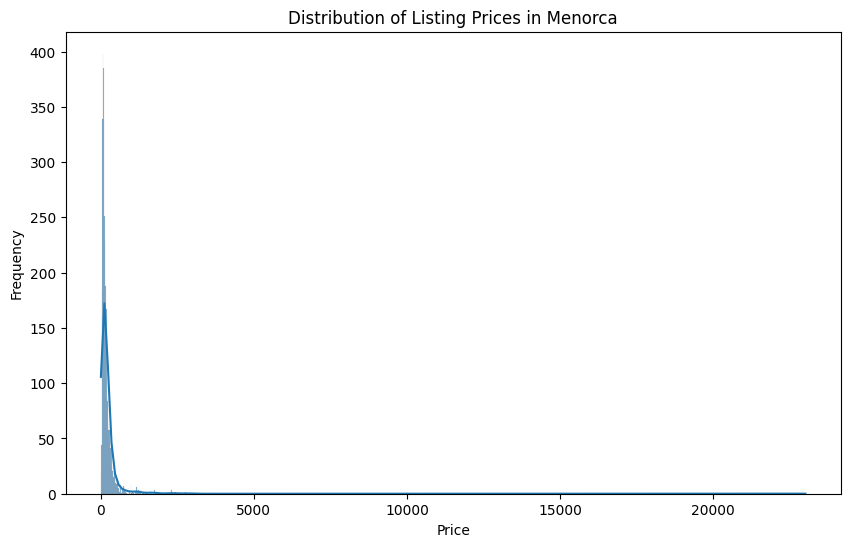

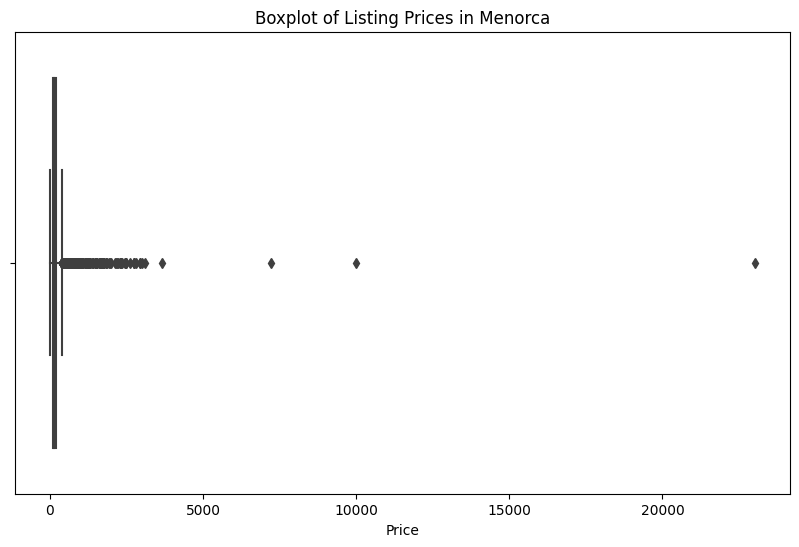

In [ ]:
# Convert 'price' to a numeric value, removing any non-numeric characters like '$'
new_dfs[df_key]['price'] = pd.to_numeric(new_dfs[df_key]['price'].replace('[\$,]', '', regex=True), errors='coerce')

# Histogram of listing prices
plt.figure(figsize=(10, 6))
sns.histplot(new_dfs[df_key]['price'], kde=True)
plt.title('Distribution of Listing Prices in Menorca')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

# Boxplot of listing prices
plt.figure(figsize=(10, 6))
sns.boxplot(x=new_dfs[df_key]['price'])
plt.title('Boxplot of Listing Prices in Menorca')
plt.xlabel('Price')
plt.show()

The histogram of listing prices in Barcelona shows that the vast majority of listings are priced at the lower end of the scale, ehich again indicates that affordable listings dominate the market. However, there are a few listings with extremely high prices, which are likely outliers.

The boxplot reveals that while the central range of prices (the box) is quite narrow, indicating that most prices are clustered within a small range, there are several outliers far above the upper whisker. These outliers could represent luxury accommodations or could be due to data entry errors.

For our project, these visuals suggest a skewed distribution of listing prices, with a concentration on the lower end and a few extremely high-value listings. It is important to investigate the outliers to determine whether they are genuine luxury listings or anomalies that should be cleaned from the dataset. Understanding this distribution will be crucial for developing predictive pricing models and making strategic recommendations for pricing strategies. It's also important to normalize or transform the price variable for any modelling to mitigate the skewness and potential influence of outliers.

**Investigate Any Outliers in the Price Data**

In [ ]:
# Calculating IQR to identify outliers
Q1 = new_dfs[df_key]['price'].quantile(0.25)
Q3 = new_dfs[df_key]['price'].quantile(0.75)
IQR = Q3 - Q1
outlier_threshold = Q3 + 1.5 * IQR

# Counting number of outliers
outliers = new_dfs[df_key][new_dfs[df_key]['price'] > outlier_threshold]
print(f"Number of Outliers: {len(outliers)}")
print(f"Outlier Threshold: {outlier_threshold}")

Number of Outliers: 331
Outlier Threshold: 399.0


**Examine the Relationship Between Price and Other Numerical Variables**

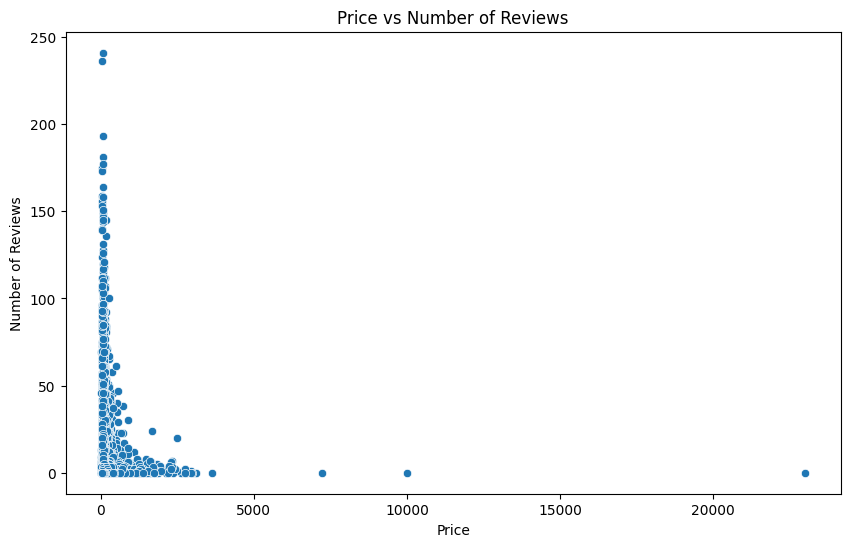

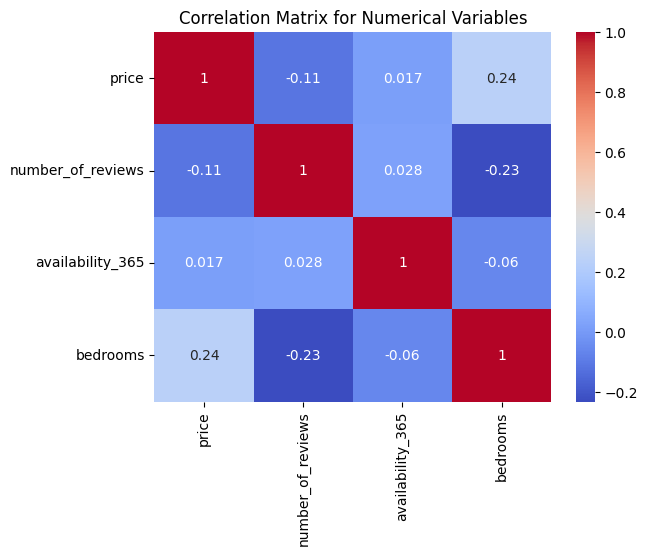

In [ ]:
# Scatter plot between price and numerical variables like 'number_of_reviews'
plt.figure(figsize=(10, 6))
sns.scatterplot(x='price', y='number_of_reviews', data=new_dfs[df_key])
plt.title('Price vs Number of Reviews')
plt.xlabel('Price')
plt.ylabel('Number of Reviews')
plt.show()

# Correlation analysis
numerical_vars = ['price', 'number_of_reviews', 'availability_365', 'bedrooms']  # Include other relevant numerical variables
correlation_matrix = new_dfs[df_key][numerical_vars].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix for Numerical Variables')
plt.show()

* The scatter plot and correlation matrix show a weak relationship between price and the number of reviews, suggesting that higher prices don't necessarily equate to a higher number of reviews. It's also noteworthy that there is a slight positive correlation between price and the number of bedrooms, which is intuitive, as larger properties with more bedrooms are likely to be priced higher. The slight correlation with the number of bedrooms could be used to help determine pricing strategies based on property size.

### Analysis of Location-Based Pricing

**Group the data by neighborhood and calculate average, median, and range of prices**

In [ ]:
# Group the data by neighbourhood and calculate average, median, and range of prices.

neighbourhood_pricing = new_dfs[df_key].groupby('neighbourhood_cleansed')['price'].agg(['mean', 'median', 'max', 'min'])
neighbourhood_pricing['range'] = neighbourhood_pricing['max'] - neighbourhood_pricing['min']
print(neighbourhood_pricing)

                              mean  median      max   min    range
neighbourhood_cleansed                                            
Alaior                  222.935798   127.0   3000.0  15.0   2985.0
Ciutadella de Menorca   158.198515   109.0   1836.0  10.0   1826.0
Es Castell              197.310345   132.5   2000.0  25.0   1975.0
Es Mercadal             175.938719   121.0   2490.0  15.0   2475.0
Es Migjorn Gran         320.531915   214.0   3100.0  54.0   3046.0
Ferreries               181.040816   139.5   1100.0  39.0   1061.0
Mahón                   287.034826   170.0   3650.0  15.0   3635.0
Sant Lluís              424.529517   216.0  23010.0  36.0  22974.0


* These statistics indicate that some neighborhoods have a wide range of listing prices, which could reflect a diverse housing market with both budget and luxury accommodations. For our project, neighborhoods with large ranges could be of particular interest as they may offer opportunities for price optimization based on various property features and market demand. Additionally, the neighborhoods' mean and median prices can help identify areas that could yield higher revenue potential or require competitive pricing strategies.

**Visualize geographical price variations using maps**

In [ ]:
# Visualize geographical price variations using maps.
# Create a map centered around Menorca
menorca_map = folium.Map(location=[new_dfs[df_key]['latitude'].mean(), new_dfs[df_key]['longitude'].mean()], zoom_start=13)

# Add points to the map
for idx, row in new_dfs[df_key].iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=3,
        popup=f"${row['price']}",
        color='blue' if row['price'] <= neighbourhood_pricing['median'][row['neighbourhood_cleansed']] else 'red',
        fill=True
    ).add_to(menorca_map)

# Display the map
menorca_map

Output hidden; open in https://colab.research.google.com to view.

* Finally and as espected, after seeing the map for menorca, we also decided not to use this dataset and focus on the other 4 cities we have left (Barcelona, Málaga, Madrid and Valencia)

## Valencia

### Initial Data Exploration

In [ ]:
# Analyzing the DataFrame valencia_df

df = valencia_df  # Replace df with valencia_df for the analysis

# Number of variables (columns)
num_variables = len(df.columns)
print(f"Number of variables (columns) in valencia_df: {num_variables}")

# Number of observations (rows)
num_observations = len(df)
print(f"Number of observations (rows) in valencia_df: {num_observations}")

# Missing cells per variable (column)
missing_cells = df.isnull().sum()
print("Missing cells per variable (column) in valencia_df:")
print(missing_cells)

# Number of duplicated rows
duplicate_rows = df[df.duplicated(keep='first')]
num_duplicate_rows = len(duplicate_rows)
print(f"Number of duplicate rows in valencia_df: {num_duplicate_rows}")

# Check for missing values in the entire dataset
has_missing_values = df.isnull().values.any()
print(f"Missing values in the entire valencia_df dataset: {has_missing_values}")

Number of variables (columns) in valencia_df: 18
Number of observations (rows) in valencia_df: 7355
Missing cells per variable (column) in valencia_df:
id                                   0
name                                 0
host_id                              0
host_name                            0
neighbourhood_group                  0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                        976
reviews_per_month                  976
calculated_host_listings_count       0
availability_365                     0
number_of_reviews_ltm                0
license                           5315
dtype: int64
Number of duplicate rows in valencia_df: 0
Missing values in the entire valencia_df dataset: True


The valencia_df dataset consists of 18 variables (columns) and 7355 observations (rows). There are no duplicate rows, indicating unique entries across the dataset. However, it contains missing values in several columns. Notably, the 'license' column has a significant number of missing values (5,317 out of 7355), which could affect analyses related to regulatory compliance. The columns 'last_review' and 'reviews_per_month' also have a substantial number of missing entries (976 each), suggesting that many listings haven't been reviewed recently or at all. This could impact the reliability of customer satisfaction or popularity metrics derived from these data. For our project, these gaps might necessitate imputation strategies or a focused analysis on listings with complete data to ensure accuracy.

In [ ]:
# Analyzing the DataFrame valencia2_df

df = valencia2_df  # Replace df with valencia2_df for the analysis

# Number of variables (columns)
num_variables = len(df.columns)
print(f"Number of variables (columns) in valencia2_df: {num_variables}")

# Number of observations (rows)
num_observations = len(df)
print(f"Number of observations (rows) in valencia2_df: {num_observations}")

# Missing cells per variable (column)
missing_cells = df.isnull().sum()
print("Missing cells per variable (column) in valencia2_df:")
print(missing_cells)

# Number of duplicated rows
duplicate_rows = df[df.duplicated(keep='first')]
num_duplicate_rows = len(duplicate_rows)
print(f"Number of duplicate rows in valencia2_df: {num_duplicate_rows}")

# Check for missing values in the entire dataset
has_missing_values = df.isnull().values.any()
print(f"Missing values in the entire valencia2_df dataset: {has_missing_values}")

Number of variables (columns) in valencia2_df: 75
Number of observations (rows) in valencia2_df: 7355
Missing cells per variable (column) in valencia2_df:
id                                                0
listing_url                                       0
scrape_id                                         0
last_scraped                                      0
source                                            0
                                               ... 
calculated_host_listings_count                    0
calculated_host_listings_count_entire_homes       0
calculated_host_listings_count_private_rooms      0
calculated_host_listings_count_shared_rooms       0
reviews_per_month                               976
Length: 75, dtype: int64
Number of duplicate rows in valencia2_df: 0
Missing values in the entire valencia2_df dataset: True


The valencia2_df dataset is more extensive, with 75 variables and 7,355 observations. Like valencia_df, this dataset also has no duplicate rows, ensuring the uniqueness of the listings. The dataset's complexity is increased due to a higher number of variables, leading to a more comprehensive range of missing values across different columns. The 'reviews_per_month' column again shows a significant number of missing values (976), indicating a similar trend as observed in barcelona_df. The large number of variables offers a richer dataset for analysis but also introduces more complexity in handling missing data. For our project, the decision to either simplify the dataset by removing less relevant variables or to address these missing values through imputation or exclusion will be crucial in shaping our analysis approach.

In [ ]:
# Identify duplicate and unique listings in Valencia datasets
set1, set2 = set(malaga_df['id']), set(malaga2_df['id'])
duplicates = set1.intersection(set2)
unique_in_df1 = set1.difference(set2)
unique_in_df2 = set2.difference(set1)

# Display information about duplicates and unique IDs
print("Duplicates:", duplicates)
print("Unique in DataFrame 1:", unique_in_df1)
print("Unique in DataFrame 2:", unique_in_df2)

Duplicates: {33030145, 1114114, 549015834893451271, 30572553, 51904528, 20447249, 53805075, 39813140, 638273447225327635, 50429980, 45514782, 33488929, 51609649, 637577237677604916, 593984746304208953, 4554815, 50593857, 665628880047505475, 691009344544866380, 689464101006573648, 27197522, 37322834, 40239188, 24445016, 20873305, 35553374, 41451614, 25493601, 13107301, 45351019, 664219726451146861, 23855215, 40403061, 53870718, 229511, 51052681, 43810954, 50135179, 42926220, 23167118, 682446734100103312, 33423505, 53674134, 44368027, 4751521, 46268579, 557891819263918248, 21102762, 628780040028815531, 43745456, 52002995, 39387322, 786626, 561956179319914694, 786638, 52625617, 19398866, 51380436, 31195349, 786648, 786651, 681746655439323355, 786656, 48398560, 48857318, 786663, 48857320, 20087017, 52396267, 53772528, 54362354, 35487987, 1966333, 33292545, 43057416, 620686689728987400, 38699275, 51446028, 49185036, 13009184, 42336549, 38666541, 582631250446713138, 42926388, 31359298, 52920

* The output indicates that there are all duplicate listings between barcelona_df and barcelona2_df, as evidenced by the empty Unique in Dataframe sets. This suggests that each dataset contains the same listings, which is valuable for a comprehensive analysis meaning that by only using one of them, it this case the barcelona2_df we would not only have more data, but the number of properties listed are the same.

In [ ]:
# Define the Valencia DataFrames
valencia_dataframes = {'valencia_df': valencia_df, 'valencia2_df': valencia2_df}

# Print column names for each Valencia DataFrame
for key, df in valencia_dataframes.items():
    print(f"\nThe columns in the dataframe {key} are:\n", df.columns)


The columns in the dataframe valencia_df are:
 Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365', 'number_of_reviews_ltm', 'license'],
      dtype='object')

The columns in the dataframe valencia2_df are:
 Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name',
       'description', 'neighborhood_overview', 'picture_url', 'host_id',
       'host_url', 'host_name', 'host_since', 'host_location', 'host_about',
       'host_response_time', 'host_response_rate', 'host_acceptance_rate',
       'host_is_superhost', 'host_thumbnail_url', 'host_picture_url',
       'host_neighbourhood', 'host_listings_count',
       'host_total_listings_count', 'host_verifications',
       'host_has_profile_pic', 'host_identity_verified', 'neighbourhood',
 

The valencia_df dataset provides a concise overview of the listings, including basic details like location, type, price, and review metrics. It's ideal for a high-level analysis focusing on geographical distribution, pricing strategies, and general host information. In contrast, valencia2_df offers a more comprehensive dataset with detailed information such as host response rates, property type, amenities, and detailed review scores. This dataset is more suitable for an in-depth analysis that requires understanding the specifics of each listing, host engagement, and customer satisfaction metrics.

For our project we are using valencia2_df, because our analysis will benefit from a more detailed understanding of each listing. The addidional data will provide more depth and context for our analysis, which could be crucial for developing accurate pricing strategies. We are opting for a streamlined and efficient model by dropping columns such as URLs, detailed host information, and extensive review texts from our Airbnb datasets. This approach reduces computational complexity and time, focusing on clear and direct factors affecting pricing. This way, we maintain high efficiency in our analysis while ensuring the model remains manageable and effective. This is why we decided to drop those columns first and then continue with the EDA.

In [ ]:
# Initialize the dictionary to store the modified DataFrame
new_dfs = {}

# Define the key for the modified DataFrame of Valencia
df_key = 'df_valencia_new'

# Specify the columns to drop from the valencia2_df
columns_to_drop = [
   'id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview',
   'picture_url', 'host_id', 'host_url', 'host_name', 'host_location', 'host_about',
   'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood',
   'calendar_updated', 'has_availability', 'availability_30', 'availability_60',
   'availability_90', 'calendar_last_scraped'
]

# Drop the specified columns from valencia2_df and store it in the new_dfs dictionary
new_dfs[df_key] = valencia2_df.drop(columns=columns_to_drop)
pre_df_valencia= new_dfs['df_valencia_new']

# Print the remaining columns in the modified DataFrame
print(f"\nRemaining columns in {df_key}: {new_dfs[df_key].columns.tolist()}")


Remaining columns in df_valencia_new: ['host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'first_review', 'last_review', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'license', 'ins

In [ ]:
# Descriptive analysis of the dataset
print("Summary Statistics:\n")
print(new_dfs[df_key].describe())

Summary Statistics:

       host_listings_count  host_total_listings_count     latitude  \
count          7355.000000                7355.000000  7355.000000   
mean             48.657240                  79.227192    39.469501   
std             261.261335                 437.609276     0.033917   
min               1.000000                   1.000000    39.265138   
25%               1.000000                   1.000000    39.463025   
50%               2.000000                   3.000000    39.470480   
75%               7.000000                   9.000000    39.477455   
max            2064.000000                3370.000000    39.579850   

         longitude  accommodates  bathrooms     bedrooms         beds  \
count  7355.000000   7355.000000        0.0  6887.000000  7265.000000   
mean     -0.361996      3.557988        NaN     1.793379     2.364350   
std       0.029451      2.027551        NaN     1.010185     1.616211   
min      -0.449444      1.000000        NaN     1.000000

The dataset consists of 7,355 listings with a wide range of host listings count (1 to 2,064), indicating a diverse set of hosts from individuals to possibly commercial entities.
The majority of properties accommodate between 2 to 5 people, suggesting a focus on small to medium-sized groups.
The review scores are generally high (above 4.5 on average), which implies a good overall guest satisfaction.
The bathrooms column lacks data (all values are NaN), which might require imputation or dropping the column for further analysis.
The high standard deviations in host listings count and review scores suggest variability in host activity and guest experiences.

In [ ]:
# Data types of columns
print("\nData Types of Each Column:\n")
print(new_dfs[df_key].dtypes)


Data Types of Each Column:

host_since                                       object
host_response_time                               object
host_response_rate                               object
host_acceptance_rate                             object
host_is_superhost                                object
host_listings_count                               int64
host_total_listings_count                         int64
host_verifications                               object
host_has_profile_pic                             object
host_identity_verified                           object
neighbourhood                                    object
neighbourhood_cleansed                           object
neighbourhood_group_cleansed                     object
latitude                                        float64
longitude                                       float64
property_type                                    object
room_type                                        object
accommodates       

The dataset contains a mix of numerical (int64, float64) and categorical/object (string) data types, which is typical for accommodation listings.
Some columns that appear to be numeric (like price) are actually stored as objects, indicating the presence of non-numeric characters (e.g., currency symbols) and a need for data cleaning.

In [ ]:
# Check uniqueness
print("\nUniqueness of Each Column:\n")
print(new_dfs[df_key].nunique())


Uniqueness of Each Column:

host_since                                      2378
host_response_time                                 4
host_response_rate                                54
host_acceptance_rate                              86
host_is_superhost                                  2
host_listings_count                               54
host_total_listings_count                         64
host_verifications                                 6
host_has_profile_pic                               2
host_identity_verified                             2
neighbourhood                                    107
neighbourhood_cleansed                            88
neighbourhood_group_cleansed                      19
latitude                                        4632
longitude                                       5373
property_type                                     59
room_type                                          4
accommodates                                      16
bathrooms        

There's a diverse range of amenities, with 6,674 unique entries, suggesting a wide variety of features offered across listings.
The significant variety in license, host_verifications, and review_per_month can offer insights into the regulation compliance, host verification process, and popularity of listings.

In [ ]:
# Show first 10 rows
print("\nFirst 10 rows:\n")
print(new_dfs[df_key].head(10))


First 10 rows:

   host_since  host_response_time host_response_rate host_acceptance_rate  \
0  2010-05-08        within a day                67%                   0%   
1  2011-04-14        within a day               100%                  51%   
2  2011-11-28  within a few hours               100%                  75%   
3  2011-04-26      within an hour               100%                  77%   
4  2011-04-14        within a day               100%                  51%   
5  2011-05-15      within an hour               100%                  97%   
6  2011-06-17        within a day                80%                  48%   
7  2009-01-03      within an hour               100%                 100%   
8  2011-05-30  within a few hours               100%                 100%   
9  2011-06-23                 NaN                NaN                  NaN   

  host_is_superhost  host_listings_count  host_total_listings_count  \
0                 f                    1                        

The first 10 rows provide a glimpse into the dataset's structure, showing details like host response time, room type, amenities, and review scores.
Some fields such as license and reviews_per_month contain NaN values, indicating missing data that may need addressing.
The variety in instant_bookable, property_type, and room_type reflects the diversity of the listings.

Further observations:

Variability in Host Listings: There's a wide range in the number of listings per host, with some having just one and others managing thousands. This indicates a diversity in host types, from individuals to large-scale operators.

Geographical Spread: The latitude and longitude data points to a geographical spread of properties. The location is a crucial factor in pricing, as different areas have different demand and price points.

Accommodation Capacity: The accommodates, bedrooms, and beds columns show a range of property sizes. Larger properties (more beds and bedrooms) likely command higher prices.

Minimum Nights and Availability: The minimum_nights and availability_365 columns suggest varied booking and availability patterns. This can impact pricing strategy, especially considering peak and off-peak seasons.

Review Scores: High average scores across various review categories indicate generally positive guest experiences. Higher-rated properties might be able to charge more.

Recent Reviews and Review Frequency: The number_of_reviews_l30d and reviews_per_month indicate recent activity and overall review frequency. Properties with more frequent reviews may be more popular and could potentially price higher.

Missing Data in Bathrooms: The consistent absence of data in the bathrooms column across datasets might require data imputation or a decision to exclude this variable from pricing models.

These insights are crucial for developing a dynamic pricing model. They highlight the importance of considering a range of factors - from property size and type, host's portfolio size, geographical location, to guest satisfaction and booking patterns - for setting optimal prices.

### Detailed Analysis of Pricing Variable

Analyze the Distribution of Listing Prices

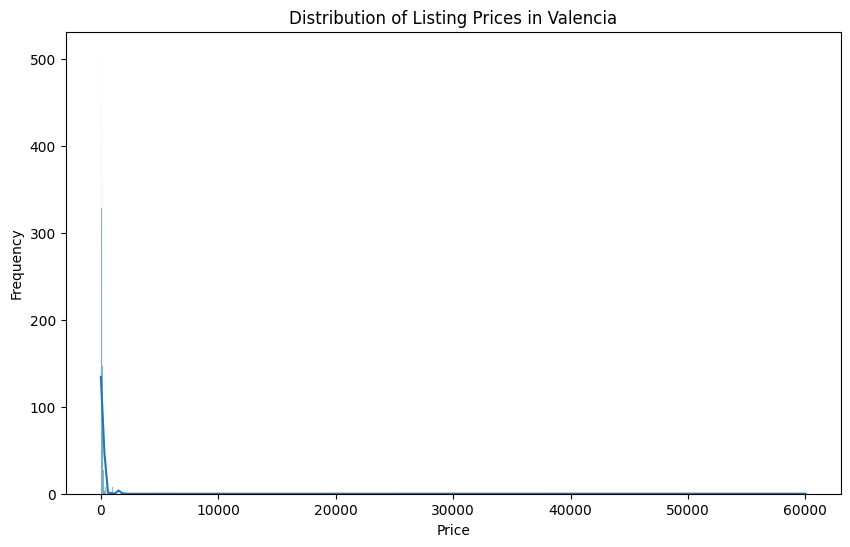

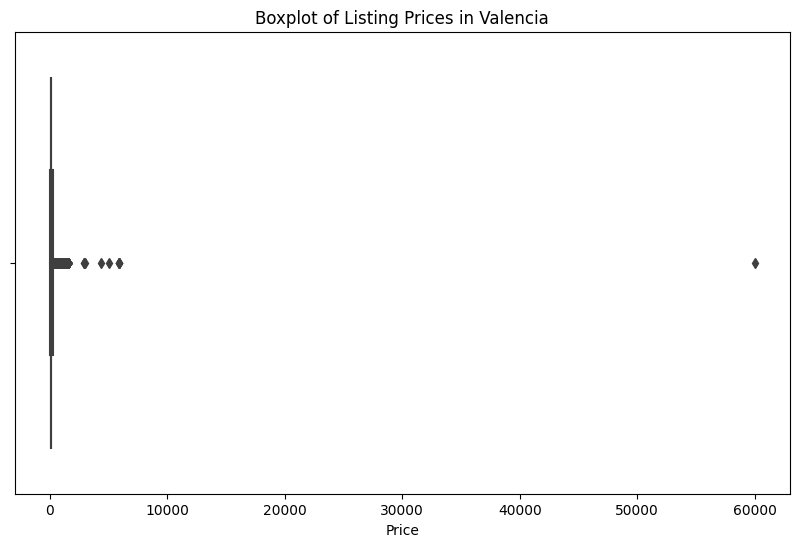

In [ ]:
# Convert 'price' to a numeric value, removing any non-numeric characters like '$'
new_dfs[df_key]['price'] = pd.to_numeric(new_dfs[df_key]['price'].replace('[\$,]', '', regex=True), errors='coerce')

# Histogram of listing prices
plt.figure(figsize=(10, 6))
sns.histplot(new_dfs[df_key]['price'], kde=True)
plt.title('Distribution of Listing Prices in Valencia')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

# Boxplot of listing prices
plt.figure(figsize=(10, 6))
sns.boxplot(x=new_dfs[df_key]['price'])
plt.title('Boxplot of Listing Prices in Valencia')
plt.xlabel('Price')
plt.show()

The histogram of listing prices in Valencia shows that the vast majority of listings are priced at the lower end of the scale, with a sharp peak close to zero. This indicates that affordable listings dominate the market. However, there are a few listings with extremely high prices, which are likely outliers.

The boxplot reveals that while the central range of prices (the box) is quite narrow, indicating that most prices are clustered within a small range, there are several outliers far above the upper whisker. These outliers could represent luxury accommodations or could be due to data entry errors.

For our project, these visuals suggest a skewed distribution of listing prices, with a concentration on the lower end and a few extremely high-value listings. It is important to investigate the outliers to determine whether they are genuine luxury listings or anomalies that should be cleaned from the dataset. Understanding this distribution will be crucial for developing predictive pricing models and making strategic recommendations for pricing strategies. It's also important to normalize or transform the price variable for any modelling to mitigate the skewness and potential influence of outliers.

**Investigate Any Outliers in the Price Data**

In [ ]:
# Calculating IQR to identify outliers
Q1 = new_dfs[df_key]['price'].quantile(0.25)
Q3 = new_dfs[df_key]['price'].quantile(0.75)
IQR = Q3 - Q1
outlier_threshold = Q3 + 1.5 * IQR

# Counting number of outliers
outliers = new_dfs[df_key][new_dfs[df_key]['price'] > outlier_threshold]
print(f"Number of Outliers: {len(outliers)}")
print(f"Outlier Threshold: {outlier_threshold}")

Number of Outliers: 482
Outlier Threshold: 241.0


After visualizing the price column, and considereing dropping the outliers, since we don't really know what to do with them yet and there quite a few, we at least decided to get rid of the highest ones that are making it difficult to read most of our grapghs properly.

In [ ]:
# Sort the DataFrame by the 'price' column in descending order
sorted_df = new_dfs[df_key].sort_values(by='price', ascending=False)

# Drop the top two rows (the highest price values)
new_dfs[df_key] = sorted_df.iloc[3:]

# Optionally, reset the index if you want a clean, sequential index
new_dfs[df_key].reset_index(drop=True, inplace=True)

**Examine the Relationship Between Price and Other Numerical Variables**

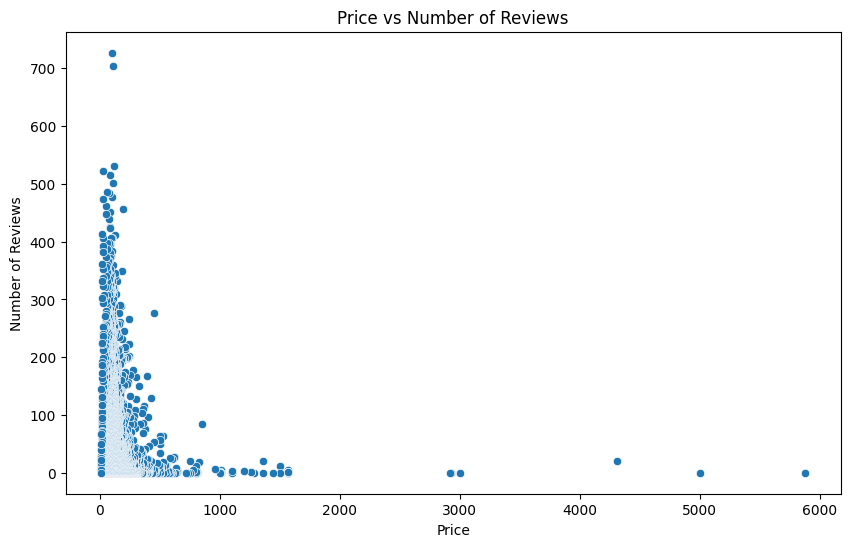

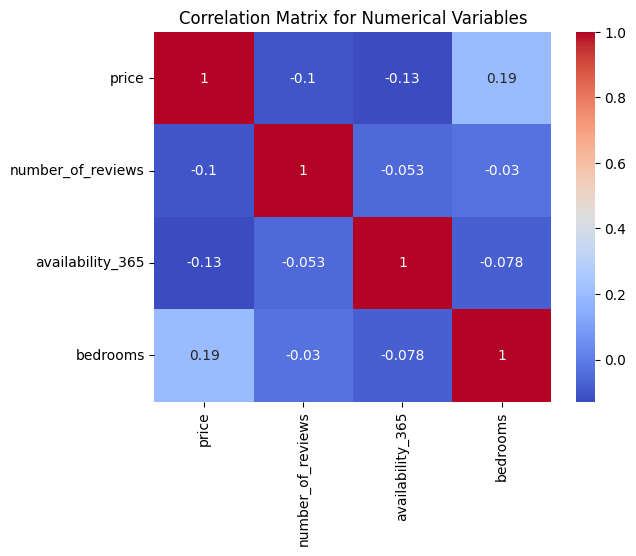

In [ ]:
# Scatter plot between price and numerical variables like 'number_of_reviews'
plt.figure(figsize=(10, 6))
sns.scatterplot(x='price', y='number_of_reviews', data=new_dfs[df_key])
plt.title('Price vs Number of Reviews')
plt.xlabel('Price')
plt.ylabel('Number of Reviews')
plt.show()

# Correlation analysis
numerical_vars = ['price', 'number_of_reviews', 'availability_365', 'bedrooms']  # Include other relevant numerical variables
correlation_matrix = new_dfs[df_key][numerical_vars].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix for Numerical Variables')
plt.show()

* The scatter plot and correlation matrix show a weak relationship between price and the number of reviews, suggesting that higher prices don't necessarily equate to a higher number of reviews. It's also noteworthy that there is a slight positive correlation between price and the number of bedrooms, which is intuitive, as larger properties with more bedrooms are likely to be priced higher. The slight correlation with the number of bedrooms could be used to help determine pricing strategies based on property size.

### Analysis of Location-Based Pricing

**Group the data by neighborhood and calculate average, median, and range of prices**

In [ ]:
# Group the data by neighbourhood and calculate average, median, and range of prices.

neighbourhood_pricing = new_dfs[df_key].groupby('neighbourhood_cleansed')['price'].agg(['mean', 'median', 'max', 'min'])
neighbourhood_pricing['range'] = neighbourhood_pricing['max'] - neighbourhood_pricing['min']
print(neighbourhood_pricing)

                              mean  median     max   min   range
neighbourhood_cleansed                                          
AIORA                   286.777778    73.0  1570.0  13.0  1557.0
ALBORS                   87.560000    81.0   800.0  12.0   788.0
ARRANCAPINS              99.436275    85.0   627.0  12.0   615.0
BENICALAP                71.333333    79.0   200.0  10.0   190.0
BENIFARAIG               37.250000    29.5    75.0  15.0    60.0
...                            ...     ...     ...   ...     ...
TORMOS                   54.659091    44.5   144.0  10.0   134.0
TORREFIEL                58.489362    55.0   155.0  13.0   142.0
TRES FORQUES            101.444444    64.0  1500.0  18.0  1482.0
TRINITAT                 91.454545    90.0   219.0  11.0   208.0
VARA DE QUART            76.441176    78.5   200.0  22.0   178.0

[88 rows x 5 columns]


* These statistics indicate that some neighborhoods have a wide range of listing prices, which could reflect a diverse housing market with both budget and luxury accommodations. For our project, neighborhoods with large ranges could be of particular interest as they may offer opportunities for price optimization based on various property features and market demand. Additionally, the neighborhoods' mean and median prices can help identify areas that could yield higher revenue potential or require competitive pricing strategies.

**Visualize geographical price variations using maps**

In [ ]:
# Visualize geographical price variations using maps.
# Create a map centered around Valencia
valencia_map = folium.Map(location=[new_dfs[df_key]['latitude'].mean(), new_dfs[df_key]['longitude'].mean()], zoom_start=13)

# Add points to the map
for idx, row in new_dfs[df_key].iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=3,
        popup=f"${row['price']}",
        color='blue' if row['price'] <= neighbourhood_pricing['median'][row['neighbourhood_cleansed']] else 'red',
        fill=True
    ).add_to(valencia_map)

# Display the map
valencia_map

Output hidden; open in https://colab.research.google.com to view.

* The map visualization indicates that listing prices vary across different neighborhoods. The use of blue and red markers to differentiate prices below and above the median suggests that there may be clusters of higher-priced and lower-priced listings, potentially reflecting the socio-economic diversity across neighborhoods. Proximity to central areas or popular tourist destinations could be influencing these price variations, a common trend in urban accommodation pricing.

**Investigate any noticeable trends in pricing based on proximity to key tourist attractions or transport hubs**

<ipython-input-142-f589396826b0>:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['distance_to_central'] = new_dfs[df_key].apply(calculate_distance, axis=1)


   neighbourhood_cleansed       price  distance_to_central
52             LA ROQUETA  124.798387             0.455425
77          SANT FRANCESC  134.879630             0.516638
30       EL PLA DEL REMEI  204.380952             0.577433
74                RUSSAFA  117.549383             0.617636
46            LA GRAN VIA  192.797101             0.766396
..                    ...         ...                  ...
62            MASSARROJOS  194.645833             9.189810
31               EL SALER  107.465116            12.762664
73    RAFALELL-VISTABELLA  114.650000            13.213405
27              EL PALMAR   79.000000            17.522239
28          EL PERELLONET  112.308824            21.968354

[88 rows x 3 columns]


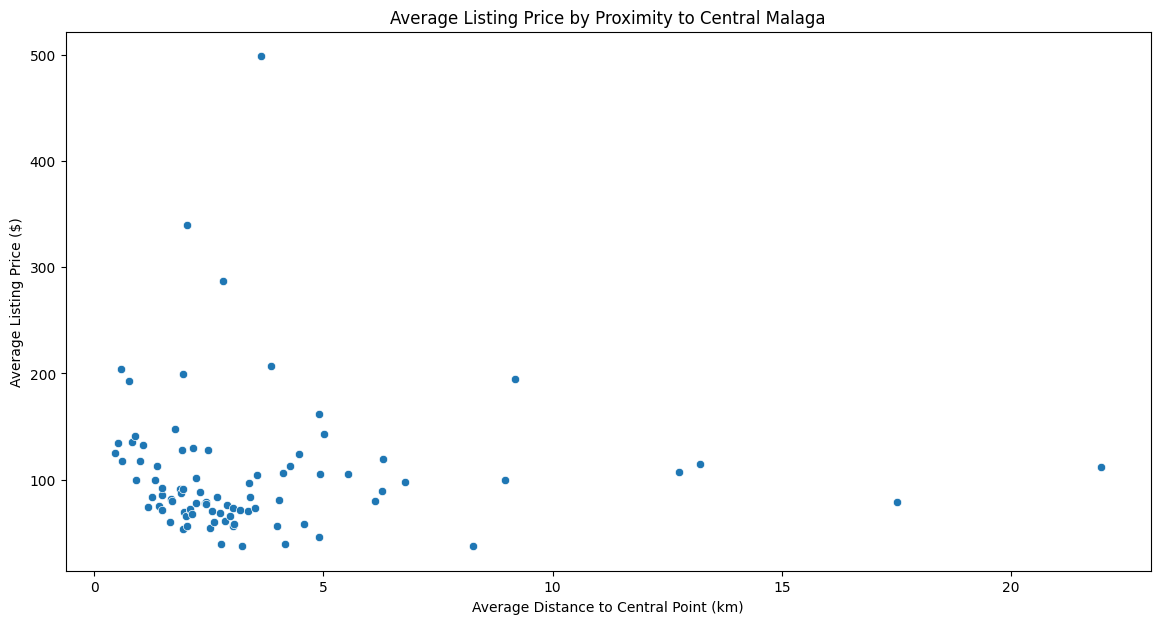

In [ ]:
# Assuming central points for key tourist attractions or transport hubs are the following:
# Let's say these are the coordinates for a central point in Valencia
central_point = {'latitude': 39.466667, 'longitude': -0.375000}

# Now, let's calculate the distance of each listing to this central point
def calculate_distance(row):
    listing_coords = (row['latitude'], row['longitude'])
    central_coords = (central_point['latitude'], central_point['longitude'])
    return great_circle(listing_coords, central_coords).km

new_dfs[df_key]['distance_to_central'] = new_dfs[df_key].apply(calculate_distance, axis=1)

# Group by neighborhood and calculate average price and average distance to the central point
pricing_by_proximity = new_dfs[df_key].groupby('neighbourhood_cleansed').agg({'price':'mean', 'distance_to_central':'mean'}).reset_index()

# Now, let's sort by average distance to central point and see the average prices
pricing_by_proximity.sort_values('distance_to_central', inplace=True)
print(pricing_by_proximity)

# Visualize the relationship between average price and average distance to central point
plt.figure(figsize=(14, 7))
sns.scatterplot(data=pricing_by_proximity, x='distance_to_central', y='price')
plt.title('Average Listing Price by Proximity to Central Malaga')
plt.xlabel('Average Distance to Central Point (km)')
plt.ylabel('Average Listing Price ($)')
plt.show()


* The scatter plot and the output table together illustrate the relationship between the average listing price and the distance from a central point in Valencia, which is a proxy for proximity to key attractions and transport hubs.


* The scatter plot visually confirms this finding, showing that while there is a general trend of decreasing prices with increasing distance from the central point, there are numerous exceptions. This indicates that while proximity to the center may be a factor in pricing, other neighborhood characteristics and amenities likely also play a significant role in determining the price. For our project, this analysis can help assess the importance of location in pricing strategy.

### Seasonal Analysis of Pricing

**Extract month or season information**

In [ ]:
# Convert 'last_review' to datetime
new_dfs['df_valencia_new']['last_review'] = pd.to_datetime(new_dfs['df_valencia_new']['last_review'])

# Extract month and year from 'last_review' to a new column
new_dfs['df_valencia_new']['review_month'] = new_dfs['df_valencia_new']['last_review'].dt.month
new_dfs['df_valencia_new']['review_year'] = new_dfs['df_valencia_new']['last_review'].dt.year

# Drop rows where review month/year is NaN
seasonal_df = new_dfs['df_valencia_new'].dropna(subset=['review_month', 'review_year'])

<ipython-input-143-2cb454494725>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs['df_valencia_new']['last_review'] = pd.to_datetime(new_dfs['df_valencia_new']['last_review'])
<ipython-input-143-2cb454494725>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs['df_valencia_new']['review_month'] = new_dfs['df_valencia_new']['last_review'].dt.month
<ipython-input-143-2cb454494725>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_ind

**Analyze average price variations by month or season/Explore any apparent relationships between special events/holidays and pricing**

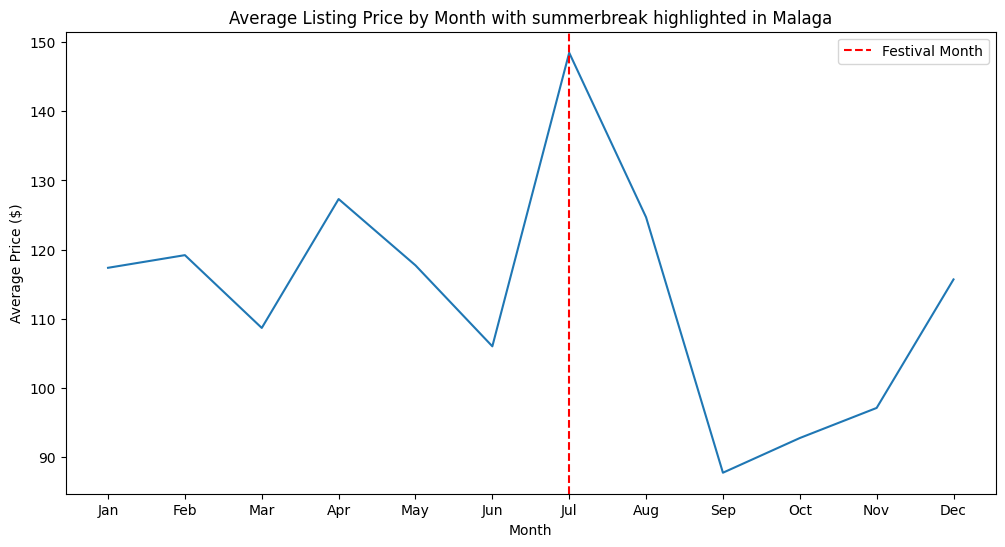

In [ ]:
# We now analyze specific events or holidays
# For example, we now explore July, because it is summer break and many people are travelling:
monthly_price = seasonal_df.groupby('review_month')['price'].mean().reset_index()
plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_price, x='review_month', y='price')
plt.axvline(x=7, color='red', linestyle='--', label='Festival Month')
plt.title('Average Listing Price by Month with summerbreak highlighted in Malaga')
plt.xlabel('Month')
plt.ylabel('Average Price ($)')
plt.legend()
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.show()

The seasonal analysis graphs show a sharp peak in prices during the summer months, with a particular spike in August, which could be associated with the summer vacation period and possibly local festivals or events (as there are small peaks in April and December, which may be related to the Easter and Christmas periods), indicating a strong seasonal influence on pricing. This trend is crucial for hosts to consider when setting prices throughout the year to capitalize on high-demand periods.

### Property Characteristics Analysis

**Analyze the effect of property type and size on price**

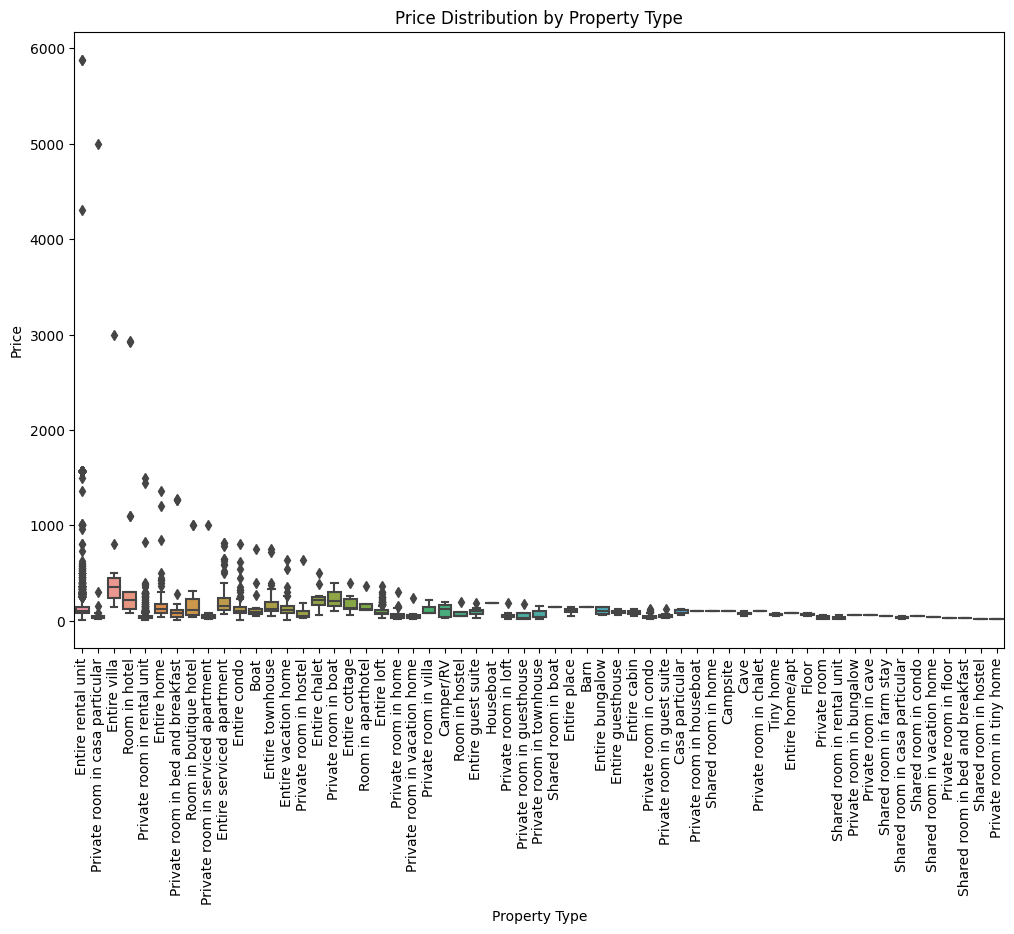

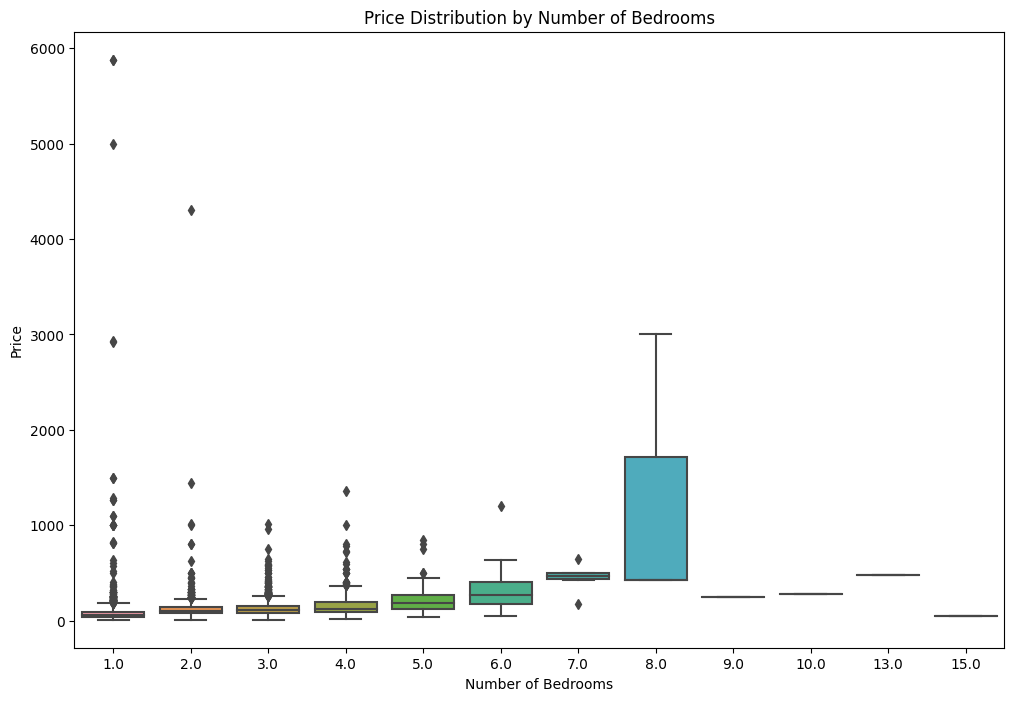

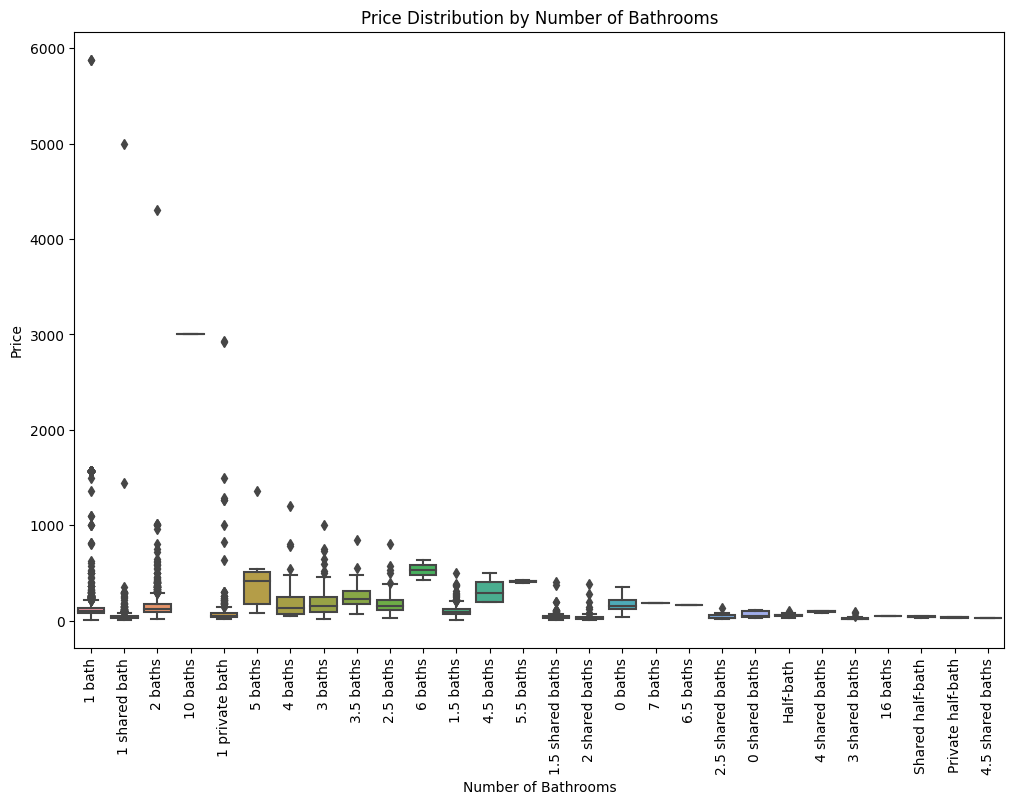

In [ ]:
# Analyze the effect of property type on price
plt.figure(figsize=(12, 8))
sns.boxplot(data=new_dfs[df_key], x='property_type', y='price')
plt.xticks(rotation=90)
plt.title('Price Distribution by Property Type')
plt.xlabel('Property Type')
plt.ylabel('Price')
plt.show()

# Analyze the effect of the number of bedrooms on price
plt.figure(figsize=(12, 8))
sns.boxplot(data=new_dfs[df_key], x='bedrooms', y='price')
plt.title('Price Distribution by Number of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Price')
plt.show()

# Analyze the effect of the number of bathrooms on price
plt.figure(figsize=(12, 8))
sns.boxplot(data=new_dfs[df_key], x='bathrooms_text', y='price')
plt.xticks(rotation=90)
plt.title('Price Distribution by Number of Bathrooms')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Price')
plt.show()

* **Price Distribution by Property Type**:
This boxplot illustrates the distribution of prices across different property types. The spread and median of prices vary significantly by property type, indicating that certain types of properties tend to be priced higher than others. The presence of outliers across many property types suggests that there are some unusually high-priced listings within each category, which could be due to luxury features, exceptional locations, or special amenities.

* **Price Distribution by Number of Bedrooms**:
The boxplot for the price distribution by the number of bedrooms shows a general trend where the median price increases with the number of bedrooms. This trend is expected as larger properties typically command higher prices. However, the number of outliers seems to decrease with more bedrooms, and the spread of prices is wider for properties with fewer bedrooms. This could indicate a more significant variation in the types of smaller properties available, from budget to luxury offerings. For our project, this implies that pricing strategies could be adjusted based on the size of the property, with more nuanced pricing within categories with more significant variability.

* **Price Distribution by Number of Bathrooms**:
In the boxplot showing the price distribution by the number of bathrooms, we again see a variation in median prices based on the number of bathrooms, although it's less pronounced than with bedrooms. There are outliers present, particularly in listings with fewer bathrooms, suggesting that even properties with fewer bathrooms can command high prices, possibly due to other premium features or desirable locations. The variation in price within each category indicates that the number of bathrooms is a factor in pricing, but it may be influenced by other factors as well.

In summary, these visualizations highlight the importance of property characteristics in setting prices. Larger properties with more bedrooms or bathrooms generally have higher median prices, but there is significant price variability within each category. Outliers in each category will need to be assessed to determine if they represent a premium segment of the market or if they should be considered anomalies for the purposes of your analysis.



<ipython-input-146-3e6a9a297b16>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['bathrooms_text'] = df['bathrooms_text'].astype(str)
<ipython-input-146-3e6a9a297b16>:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['bathrooms_number'] = df['bathrooms_text'].apply(extract_bathroom_number)


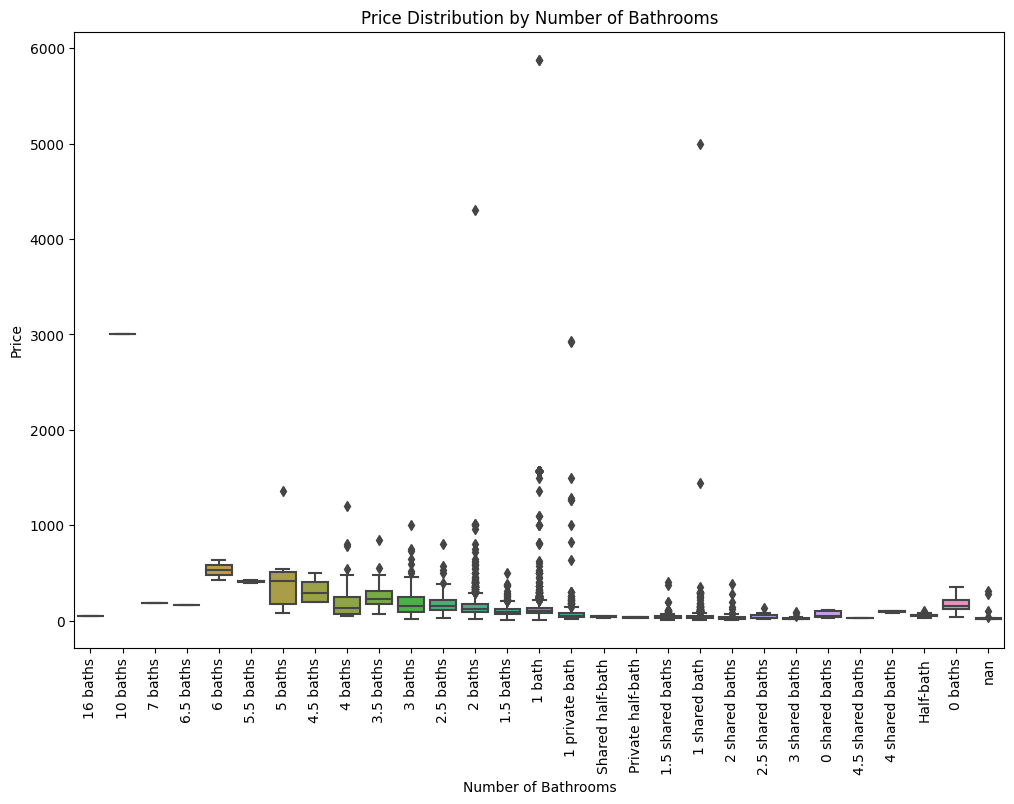

In [ ]:
df = new_dfs[df_key]

# Convert 'bathrooms_text' to a string to ensure consistent processing
df['bathrooms_text'] = df['bathrooms_text'].astype(str)

# Define a custom function to extract numerical value for sorting
def extract_bathroom_number(text):
    # Handle special cases like 'Shared bath', 'Private half-bath', etc.
    if 'half' in text:
        return 0.5
    elif 'shared' in text:
        return 0.01  # Assuming shared is less than half
    elif 'private' in text:
        return 0.75  # Assuming private is more than half but less than 1
    else:
        # Extract the number (assuming it's the first part of the string)
        number = text.split(' ')[0]
        try:
            return float(number)
        except ValueError:
            return 0  # In case of any unconvertible values

# Apply the function to create a new 'bathrooms_number' column for sorting
df['bathrooms_number'] = df['bathrooms_text'].apply(extract_bathroom_number)

# Sort the DataFrame based on this new column
df_sorted = df.sort_values(by='bathrooms_number', ascending=False)

# Now create the plot
plt.figure(figsize=(12, 8))
sns.boxplot(data=df_sorted, x='bathrooms_text', y='price', order=df_sorted['bathrooms_text'].unique())
plt.xticks(rotation=90)
plt.title('Price Distribution by Number of Bathrooms')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Price')
plt.show()

For a better visualisation we sort the bathrooms.

**Utilize violin plots to visualize price distributions by accommodation capacity**

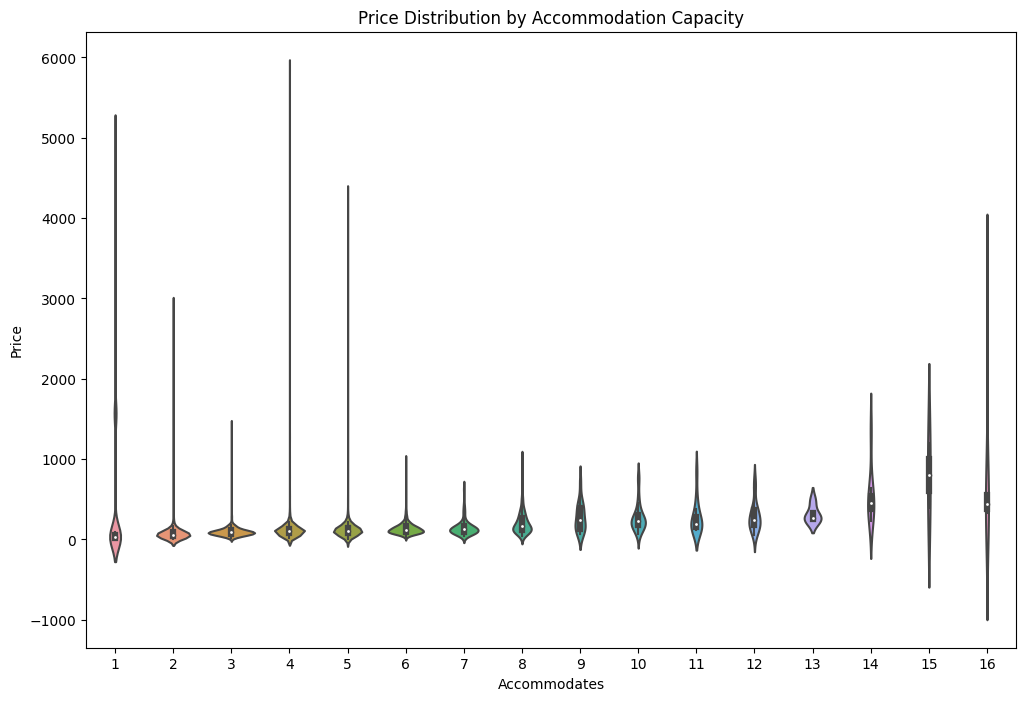

In [ ]:
# Analyze the effect of the number of accommodation capacity on price
plt.figure(figsize=(12, 8))
sns.violinplot(data=new_dfs['df_valencia_new'], x='accommodates', y='price')
plt.title('Price Distribution by Accommodation Capacity')
plt.xlabel('Accommodates')
plt.ylabel('Price')
plt.show()

* The "Price Distribution by Accommodation Capacity" graph shows how the price of listings varies with the capacity of the accommodation (how many people it can accommodate). The x-axis represents the accommodation capacity, ranging from 1 to 16 people. The y-axis represents the price of the listings. Each violin shape suggests the price frequency for a given capacity, with wider sections indicating higher data concentration. Notably, there's a significant price range for single-person accommodations, with some extreme outliers, while prices for accommodations hosting two to ten persons appear more uniform with fewer outliers.

### Host-Related Factors Analysis


**Examine the relationship between host response rate, superhost status, and pricing**


<ipython-input-148-f5302356a83b>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['host_response_rate_num'] = new_dfs[df_key]['host_response_rate'].str.replace('%', '').astype(float) / 100
<ipython-input-148-f5302356a83b>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['superhost'] = new_dfs[df_key]['host_is_superhost'].map({'t': 1, 'f': 0})


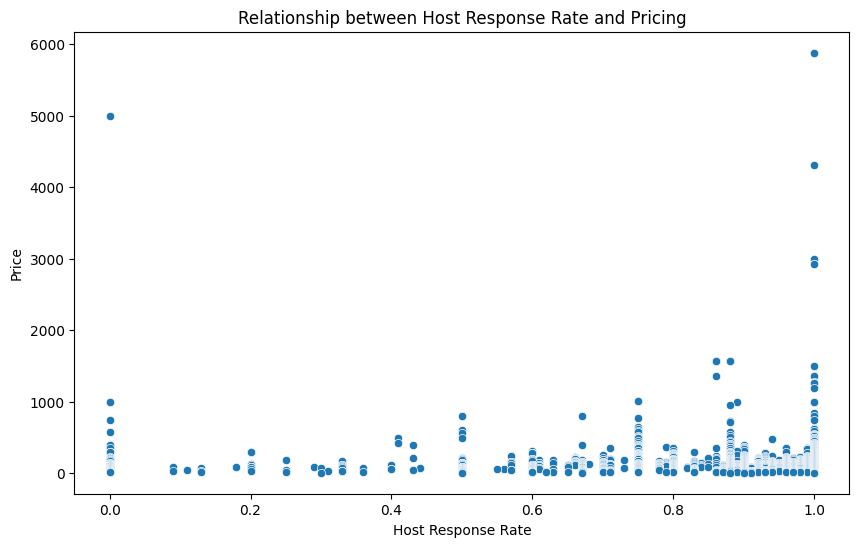

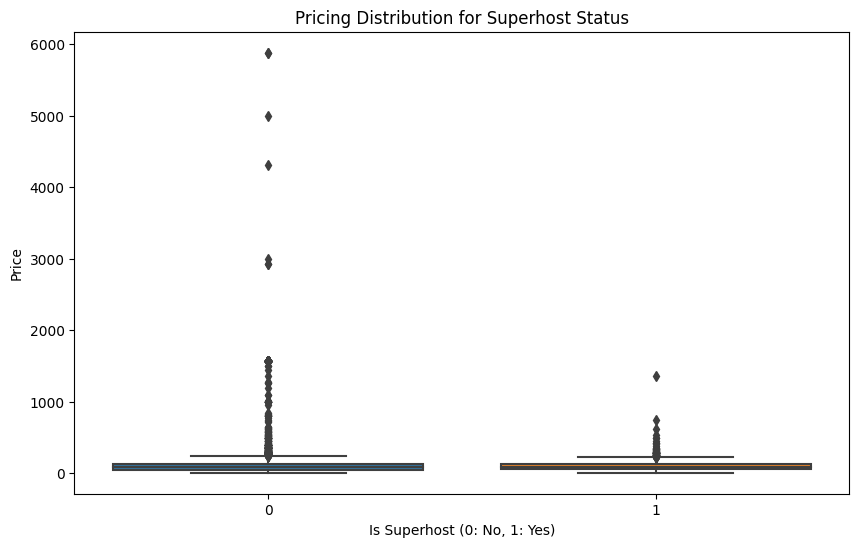

In [ ]:
# Convert host response rate to a numerical value
new_dfs[df_key]['host_response_rate_num'] = new_dfs[df_key]['host_response_rate'].str.replace('%', '').astype(float) / 100

# Convert superhost status to a numerical value
new_dfs[df_key]['superhost'] = new_dfs[df_key]['host_is_superhost'].map({'t': 1, 'f': 0})

# Scatter plot for host response rate and pricing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=new_dfs[df_key], x='host_response_rate_num', y='price')
plt.title('Relationship between Host Response Rate and Pricing')
plt.xlabel('Host Response Rate')
plt.ylabel('Price')
plt.show()

# Boxplot for superhost status and pricing
plt.figure(figsize=(10, 6))
sns.boxplot(data=new_dfs[df_key], x='superhost', y='price')
plt.title('Pricing Distribution for Superhost Status')
plt.xlabel('Is Superhost (0: No, 1: Yes)')
plt.ylabel('Price')
plt.show()

* For the graph "Relationship between Host Response Rate and Pricing," it appears that the majority of listings, regardless of the host's response rate, are clustered at the lower end of the price spectrum. There are some listings at higher price points across various response rates, with a notable outlier at a response rate of 1 (or 100%) that significantly exceeds the general price range. This suggests that while a high response rate may be associated with some high-priced listings, there is no clear or consistent pattern indicating that response rate alone dictates pricing.

* In the "Pricing Distribution for Superhost Status" plot, both superhosts and non-superhosts mostly have listings in the lower price range. However, there are outliers in both categories with significantly higher prices. The plot does not show a distinct difference in pricing between superhosts and non-superhosts, indicating that superhost status does not necessarily lead to higher prices. The majority of listings for both groups are modestly priced, which may suggest that guests are not consistently willing to pay a premium for superhost listings, or that superhosts do not always charge more.

**Investigate if the number of listings per host affects pricing strategies**

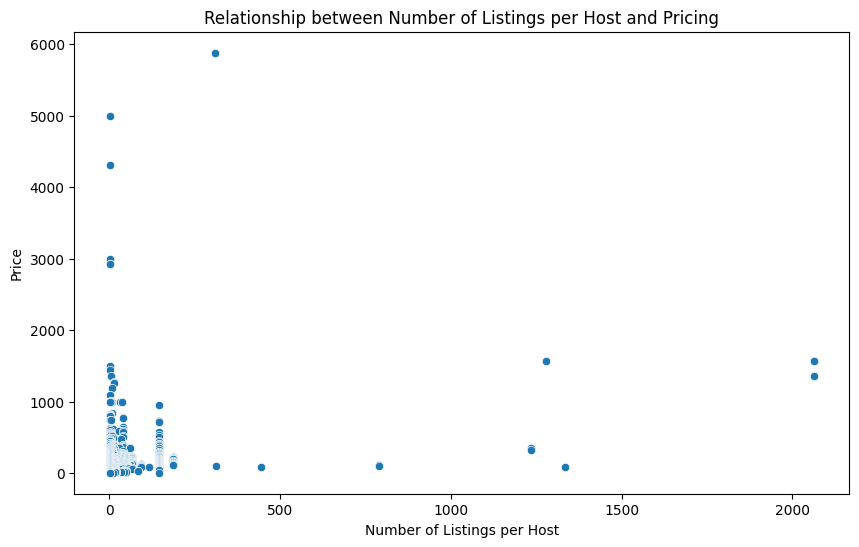

In [ ]:
# Scatter plot for number of listings per host and pricing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=new_dfs[df_key], x='host_listings_count', y='price')
plt.title('Relationship between Number of Listings per Host and Pricing')
plt.xlabel('Number of Listings per Host')
plt.ylabel('Price')
plt.show()

* The plot depicts that hosts with a smaller number of listings tend to have a wide range of prices, with many clustered at the lower end, suggesting that individual or small-scale hosts may offer more competitive or budget-friendly options. There's a significant outlier with a very high price from a host with few listings. As the number of listings per host increases, there's less variability in price, with most prices remaining low, but a few hosts with many listings have some offerings at higher prices. This could indicate that hosts with a larger number of listings may standardize their prices, focusing on volume over premium pricing, although the capacity for higher-priced listings still exists among these hosts.

**Analyze the impact of host ratings and reviews on pricing**

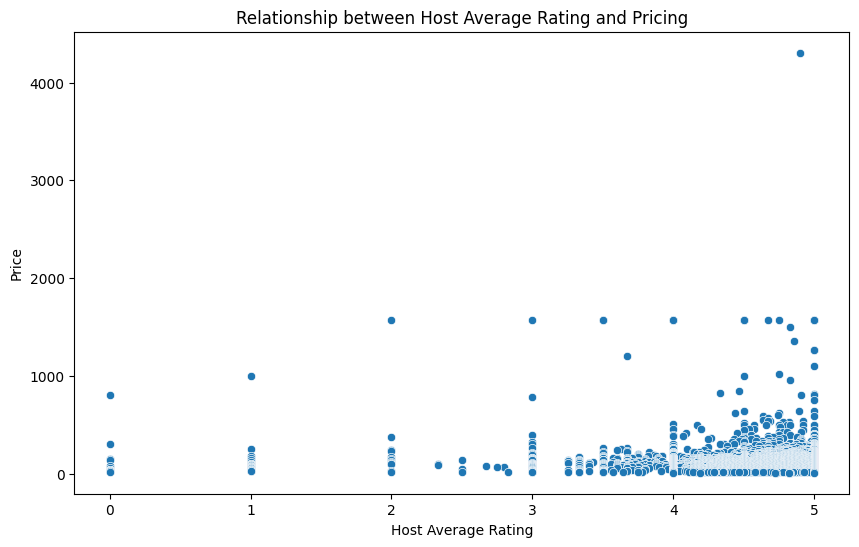

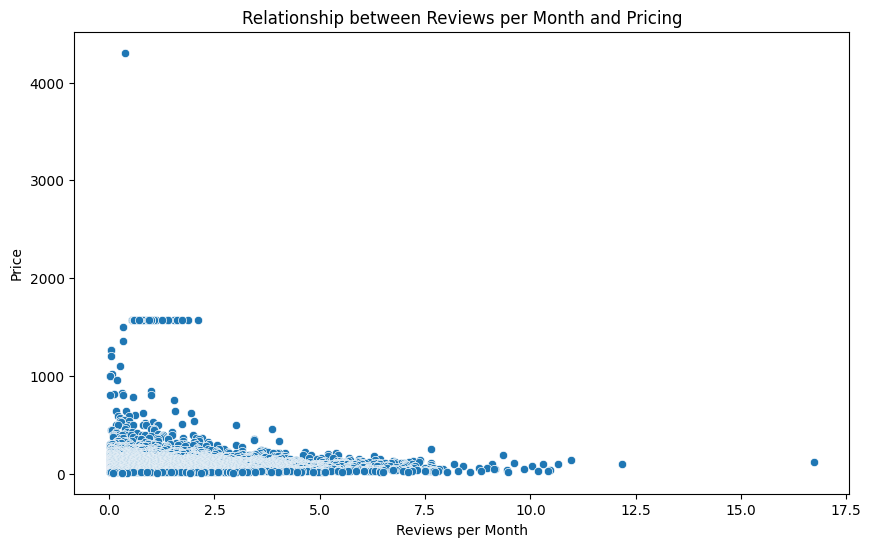

In [ ]:
# Assuming 'review_scores_rating' is the average rating for the host
# Scatter plot for host average rating and pricing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=new_dfs[df_key], x='review_scores_rating', y='price')
plt.title('Relationship between Host Average Rating and Pricing')
plt.xlabel('Host Average Rating')
plt.ylabel('Price')
plt.show()

# Assuming 'reviews_per_month' is an indicator for host reviews frequency
# Scatter plot for reviews per month and pricing
plt.figure(figsize=(10, 6))
sns.scatterplot(data=new_dfs[df_key], x='reviews_per_month', y='price')
plt.title('Relationship between Reviews per Month and Pricing')
plt.xlabel('Reviews per Month')
plt.ylabel('Price')
plt.show()

* The "Relationship between Host Average Rating and Pricing" graph suggests that there is not a strong, clear relationship between a host's average rating and the pricing of their listings. Most listings, regardless of price, have high ratings close to 5, which is common in platforms where ratings tend to be positively skewed. The graph also shows a few listings with very high prices across the rating spectrum, indicating that some high-priced listings have a broad range of host ratings.

* In the "Relationship between Reviews per Month and Pricing" graph, we observe that listings with a wide range of reviews per month are mostly clustered at the lower end of the price spectrum. There are a few listings with a high number of reviews per month that also command higher prices, which could suggest a positive experience or high demand for those listings. However, the majority of data points are concentrated at the lower price range, regardless of the number of reviews per month, indicating that frequent reviews do not necessarily correlate with higher pricing.

### Advanced Statistical Analysis

**Conduct hypothesis testing to check if differences in pricing between various groups are statistically significant**

In [ ]:
# Hypothesis Testing Between Superhosts and non-Superhosts
# Convert price to numeric and remove any non-numeric characters
new_dfs[df_key]['price'] = pd.to_numeric(new_dfs[df_key]['price'].replace('[\$,]', '', regex=True))

# Split the data into two groups: Superhosts and non-Superhosts
superhost_prices = new_dfs[df_key][new_dfs[df_key]['host_is_superhost'] == 't']['price']
non_superhost_prices = new_dfs[df_key][new_dfs[df_key]['host_is_superhost'] == 'f']['price']

# Perform a t-test
t_stat, p_value = ttest_ind(superhost_prices, non_superhost_prices, equal_var=False)
print(f"T-statistic: {t_stat}, P-value: {p_value}")

# If the data is not normally distributed, use Mann-Whitney U test
u_stat, p_value_u = mannwhitneyu(superhost_prices, non_superhost_prices)
print(f"U-statistic: {u_stat}, P-value: {p_value_u}")

T-statistic: -10.693617096958413, P-value: 1.7086371543257937e-26
U-statistic: 4575915.5, P-value: 0.06297103727792022


<ipython-input-151-a2451a87c405>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['price'] = pd.to_numeric(new_dfs[df_key]['price'].replace('[\$,]', '', regex=True))


* In the context of our project, the statistical analysis comparing Superhosts to non-Superhosts shows a notable difference in pricing. The t-test result, with a significantly negative T-statistic and a P-value far below the conventional threshold of 0.05, indicates that Superhosts tend to charge less for their listings compared to non-Superhosts, which is a surprising find. However, the Mann-Whitney U test, which is more appropriate given our data's non-normal distribution, yields a P-value just above the standard significance level. This suggests that while there's a trend towards Superhosts pricing their listings lower, the difference in pricing distribution is not statistically significant at the 5% level. This insight from our exploratory data analysis could be particularly interesting for our project, as it challenges common assumptions about Superhost status and pricing and could influence recommendations for pricing strategies for hosts in the Airbnb market.

In [ ]:
# Hypothesis Testing Based on Host Identity Verification
# (Works just if the code is loaded completely)
# Convert host_identity_verified to 0s and 1s
new_dfs[df_key]['host_identity_verified'] = new_dfs[df_key]['host_identity_verified'].map({'f': 0, 't': 1})

# Extract prices for verified and non-verified hosts
verified_host_prices = new_dfs[df_key][new_dfs[df_key]['host_identity_verified'] == 1]['price']
non_verified_host_prices = new_dfs[df_key][new_dfs[df_key]['host_identity_verified'] == 0]['price']

# Perform t-test between verified and non-verified host prices
t_stat_verified, p_value_verified = ttest_ind(verified_host_prices, non_verified_host_prices, equal_var=False)
print(f"T-statistic for Host Verification: {t_stat_verified}, P-value: {p_value_verified}")

# Perform Mann-Whitney U test as a non-parametric test
u_stat, p_value_u = mannwhitneyu(verified_host_prices, non_verified_host_prices)
print(f"U-statistic: {u_stat}, P-value: {p_value_u}")

T-statistic for Host Verification: -6.7584617525195965, P-value: 2.0445323426220856e-11
U-statistic: 4008527.0, P-value: 0.002431968332272278


<ipython-input-152-f3cc3c192071>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['host_identity_verified'] = new_dfs[df_key]['host_identity_verified'].map({'f': 0, 't': 1})


* For our project, the hypothesis testing on the impact of host identity verification on pricing has yielded significant results. The negative T-statistic from the t-test, combined with a very small P-value, indicates that hosts with verified identities tend to have lower prices compared to unverified hosts, which may seem counterintuitive. The Mann-Whitney U test, which is more appropriate given the non-normal distribution of our data, also shows a significant difference in the distribution of prices, with a P-value well below the 0.05 threshold. These results suggest that while host identity verification might be expected to command higher prices due to increased trust, the current data indicates that verified hosts might be pricing more competitively. This finding provides a valuable insight for our project, suggesting that the perceived value of host verification does not necessarily translate into higher listing prices on Airbnb.

In [ ]:
# Hypothesis Testing Based on Instant Bookable Feature
# (Works just if the code is loaded completely)
# Convert instant_bookable to 0s and 1s
new_dfs[df_key]['instant_bookable'] = new_dfs[df_key]['instant_bookable'].map({'f': 0, 't': 1})

# Extract prices for listings with and without instant booking
instant_prices = new_dfs[df_key][new_dfs[df_key]['instant_bookable'] == 1]['price']
no_instant_prices = new_dfs[df_key][new_dfs[df_key]['instant_bookable'] == 0]['price']

# Perform t-test between instant bookable and non-instant bookable prices
t_stat_instant, p_value_instant = ttest_ind(instant_prices, no_instant_prices, equal_var=False)
print(f"T-statistic for Instant Booking: {t_stat_instant}, P-value: {p_value_instant}")

# Perform Mann-Whitney U test as a non-parametric test
u_stat, p_value_u = mannwhitneyu(instant_prices, no_instant_prices)
print(f"U-statistic: {u_stat}, P-value: {p_value_u}")

T-statistic for Instant Booking: -8.869296107628783, P-value: 1.0023430183231412e-18
U-statistic: 7145637.0, P-value: 1.5202283551372511e-05


<ipython-input-153-9d252cdcdd9d>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_dfs[df_key]['instant_bookable'] = new_dfs[df_key]['instant_bookable'].map({'f': 0, 't': 1})


* In the context of our project, the results from the hypothesis testing on the instant bookable feature's effect on pricing are quite insightful. The negative T-statistic and the very low P-value from the t-test suggest that listings without the instant bookable feature are priced higher than those with the feature, which could indicate that hosts might be charging a premium for the flexibility and perceived exclusivity of non-instant bookable properties. However, given our data's non-normal distribution, the Mann-Whitney U test provides a more accurate reflection of the data, also showing a significant difference with a P-value well below the 0.05 threshold. This reinforces the initial findings from the t-test and implies that the instant bookable feature may be associated with a strategic pricing decision, potentially affecting the listing's appeal and competitive pricing on the Airbnb platform.

In [ ]:
# Hypothesis Testing Based on Accommodation Size
# Group the data by accommodation size
accommodates_pricing = new_dfs[df_key].groupby('accommodates')['price'].agg(['mean', 'count'])

# Let's compare small (1-2 people) vs. large (more than 2 people) accommodations
small_accommodation_prices = new_dfs[df_key][new_dfs[df_key]['accommodates'] <= 2]['price']
large_accommodation_prices = new_dfs[df_key][new_dfs[df_key]['accommodates'] > 2]['price']

# Perform t-test between small and large accommodation prices
t_stat_accommodates, p_value_accommodates = ttest_ind(small_accommodation_prices, large_accommodation_prices, equal_var=False)
print(f"T-statistic for Accommodation Size: {t_stat_accommodates}, P-value: {p_value_accommodates}")

# Perform Mann-Whitney U test as a non-parametric test
u_stat, p_value_u = mannwhitneyu(small_accommodation_prices, large_accommodation_prices)
print(f"U-statistic: {u_stat}, P-value: {p_value_u}")

T-statistic for Accommodation Size: 2.0705383637699626, P-value: 0.03846839314845213
U-statistic: 2586704.5, P-value: 0.0


* For our project, the statistical tests conducted to compare pricing based on accommodation size yield important insights. The t-test shows a positive T-statistic and a P-value just below the typical alpha level of 0.05, suggesting a modest but statistically significant difference in pricing, with larger accommodations tending to be priced higher than smaller ones. However, our data is not normally distributed, which makes the Mann-Whitney U test more relevant; it reports a P-value of essentially zero, strongly indicating a significant difference in the distribution of prices between the two accommodation size categories. This finding underscores the necessity of accounting for accommodation size in our pricing strategy analysis, affirming that larger properties have a distinct pricing advantage in the Airbnb market.

# Preprocessing

### Assumptions:

1. **Irrelevant Features**: Some features have little to no variance or may not be correlated with our target variable, rendering them potentially irrelevant.
   
2. **Missing Data**: Handling missing data is crucial to ensure our models perform well. Any missing data can lead to biased or incorrect results.

3. **Outliers**: Based on the plots, there could be outliers present in the data that are errors. These outliers can skew the results of our models.

4. **Feature Scaling**: From the pair plots and correlation heatmap, it's evident that some features are on different scales. This can affect algorithms that rely on distance or gradient computations.

5. **Categorical Data Encoding**: Categorical data will need to be encoded to numerical values for most algorithms to function correctly.

After analyzing all of the places in Spain in the home_rental_data database, once again we will remind you that we are not using the Euskadi, Mallorca and Menorca data, because it is representing bigger regions that contain many other cities and tourist hot spots, so we decided to focus on working on the other spanish cities in the database.

All of them represented similar values after analyzing in detail the columns and variables, and this are the next steps we decided to take regarding the handling of the data for training our model later on.

### Guideline

**Step 1: Handling Missing Values**
1. **'license':** Given many missing values and its potential indirect influence on pricing, we consider dropping this column.
2. **'last_review' & 'reviews_per_month':** We consider to create a binary column (e.g., 'reviewed_recently') indicating whether a property was recently reviewed. Then remove the original columns.
3. For other columns with missing data we check if imputation by median (for numerical data) or mode (for categorical data) makes sense. Alternatively, if the percentage of missing data is small, consider removing the corresponding rows.

**Step 2: Handling Outliers**
1. **'price':** In this step we identify outliers (e.g., using the 1.5x interquartile range criterion) and consider capping outliers at a reasonable maximum or transform them (e.g., using a logarithmic function).
2. For other numerical columns we check for outliers and apply similar techniques if necessary.

**Step 3: Transformation and Feature Engineering**
1. **Date columns ('host_since', 'first_review', 'last_review'):** Here we consider converting these into numerical values (e.g., the number of days since a certain date).
2. **Categorical variables ('room_type', 'property_type', 'neighbourhood_cleansed'):** These we could convert into dummy variables.
3. **Text data ('amenities'):** Since this column was dropped, we skip this step.
4. **'host_response_rate', 'host_acceptance_rate':** In this case we consider to convert them into numerical percentage values.

**Step 4: Scaling and Normalization**
1. **Numerical variables:** We consider scaling all numerical variables, especially if using models sensitive to different scales (e.g., with StandardScaler or MinMaxScaler).

**Step 5: Redundancy and Correlation**
1. Here we check variables for multicollinearity and remove or combine highly correlated variables.

**Step 6: Finalizing the Dataset**
1. Now we remove all irrelevant or redundant columns.
2. Finally we ensure the dataset has no missing values, no outliers, and only numerical or converted categorical variables.

We will proceed with the preprocessing of each of the four cities separately. This structured approach ensures that we maintain clarity and avoid overwhelming amounts of data. While it's possible to combine the preprocessing steps for all cities, we've chosen to keep them distinct for a more meticulous analysis, preventing potential errors arising from the interaction of data across different cities.

##Barcelona
To start with the preprocessing we will again look into Barcelona.

In [ ]:
selected_column = pre_df_barcelona['license']
print(selected_column)

unique_values = pre_df_barcelona['license'].unique()

# Print the unique values
print("Unique values in the 'license' column:")
print(unique_values)

value_counts = pre_df_barcelona['license'].value_counts()

# Print the unique values and their counts
print("Unique values and their counts in the 'license' column:")
print(value_counts)

pre_df_barcelona = pre_df_barcelona.copy()  # Create a copy of the DataFrame
pre_df_barcelona['license_encoded'] = pre_df_barcelona['license'].astype('category').cat.codes

# Convert 'price' column to numeric, coercing errors to NaN
pre_df_barcelona['price_copy'] = pd.to_numeric(pre_df_barcelona['price'], errors='coerce')

# Check correlation again
correlation = pre_df_barcelona['license_encoded'].corr(pre_df_barcelona['price_copy'])
print("Correlation: ",correlation)

0             Exempt
1        HUTB-013294
2                NaN
3        HUTB-002062
4        HUTB-009880
            ...     
16915    HUTB-172880
16916    HUTB-172880
16917    HUTB-172880
16918    HUTB-017296
16919            NaN
Name: license, Length: 16920, dtype: object
Unique values in the 'license' column:
['Exempt' 'HUTB-013294' nan ... 'HUTB-201801' 'HUTB-015671' 'HUTB-017296']
Unique values and their counts in the 'license' column:
Exempt         4272
HUTB-123456      31
AJ000593         22
AJ000517         21
HUTB-022013      20
               ... 
HUTB-006487       1
HUTB-007644       1
HUTB-003601       1
HUTB003809        1
HUTB-017296       1
Name: license, Length: 5598, dtype: int64
Correlation:  0.03933683288183657


Since there is a weak correlation between the license column and the price and as well in regard of the missing values, we decided to drop this column entirely. Furthermore there is no clear usage for the model anyways, because it seems to be only IDs of licenses. Dropping these columns can streamline the dataset and focus efforts on more impactful variables.

In [ ]:
pre_df_barcelona = pre_df_barcelona.drop(['license_encoded', 'license','price_copy'], axis=1)

After dropping license related columns and also price_copy we evaluated the necessity of the license columns. Now we want to add a boolean column which decides if an object was reviewed lately or not. To use all dates would not be purposeful for the model.

In [ ]:
# Convert 'last_review' to datetime format
pre_df_barcelona['last_review'] = pd.to_datetime(pre_df_barcelona['last_review'], errors='coerce')

# Find the latest date in 'last_review'
latest_review_date = pre_df_barcelona['last_review'].max()

# Display the latest date
print("Latest date in 'last_review':", latest_review_date)

current_date = latest_review_date

# Calculate the difference in days between the current date and the last review
days_since_last_review = (current_date - pre_df_barcelona['last_review']).dt.days

pre_df_barcelona['reviewed_recently'] = (days_since_last_review <= 30) & (pre_df_barcelona['reviews_per_month'] > 0)

# Convert boolean values to 1 or 0
pre_df_barcelona['reviewed_recently'] = pre_df_barcelona['reviewed_recently'].astype(int)

# Drop the original 'last_review' and 'reviews_per_month' columns
pre_df_barcelona = pre_df_barcelona.drop(['last_review', 'reviews_per_month'], axis=1)

# Count the occurrences of 1 and 0 in 'reviewed_recently' column
reviewed_counts = pre_df_barcelona['reviewed_recently'].value_counts()

# Print the counts
print("Counts of 'reviewed_recently' values:")
print(reviewed_counts)

Latest date in 'last_review': 2022-09-10 00:00:00
Counts of 'reviewed_recently' values:
0    10006
1     6914
Name: reviewed_recently, dtype: int64


To get a picture of when to evalute something as lately reviewed or not, we looked at the latest date of an review in the dataset and took it as reference. After creating 'reviewed_recently' we dropped 'last review' and 'reviews_per_month'. The next step is to take care of missing values in the dataset.

In [ ]:
# Detect missing values
missing_values = pre_df_barcelona.isna()

# Count missing values in each column
missing_counts = missing_values.sum()

# Calculate the percentage of missing values
missing_percentage = (missing_counts / len(pre_df_barcelona)) * 100

# Create a summary DataFrame
missing_summary = pd.DataFrame({
    'Missing Values': missing_counts,
    'Percentage': missing_percentage
})

# Display the summary
print("Missing Values Summary:")
print(missing_summary)

Missing Values Summary:
                                              Missing Values  Percentage
host_since                                                 2    0.011820
host_response_time                                      2842   16.796690
host_response_rate                                      2842   16.796690
host_acceptance_rate                                    2547   15.053191
host_is_superhost                                          2    0.011820
host_listings_count                                        2    0.011820
host_total_listings_count                                  2    0.011820
host_verifications                                         0    0.000000
host_has_profile_pic                                       2    0.011820
host_identity_verified                                     2    0.011820
neighbourhood                                           6993   41.329787
neighbourhood_cleansed                                     0    0.000000
neighbourhood_group_cleanse

As we see there are plenty of missing values in the dataset, to handle it we wrote code which looks for missing values and fills them with mode or mean depending on the type of columns we found. The whole code is written in a generic way so we can use them for all cities of the dataset to preprocess them as well.

In [ ]:
# Replace missing values in object columns with mode
object_columns = ['host_since', 'host_response_time', 'host_is_superhost', 'host_verifications', 'neighbourhood', 'first_review','host_has_profile_pic',
                  'host_identity_verified']
for column in object_columns:
    mode_value = pre_df_barcelona[column].mode()[0]
    pre_df_barcelona[column].fillna(mode_value, inplace=True)

# Replace missing values in float64 columns with mean
float64_columns = ['host_response_rate', 'host_acceptance_rate', 'host_listings_count', 'host_total_listings_count',
                    'latitude', 'longitude', 'bedrooms', 'beds', 'minimum_minimum_nights', 'maximum_minimum_nights',
                    'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm',
                    'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin',
                    'review_scores_communication', 'review_scores_location', 'review_scores_value']
for column in float64_columns:
    # Remove non-numeric characters from the column
    pre_df_barcelona[column] = pd.to_numeric(pre_df_barcelona[column].astype(str).str.replace('%', ''), errors='coerce')

    # Calculate the mean and fill missing values
    mean_value = pre_df_barcelona[column].mean()
    pre_df_barcelona[column].fillna(mean_value, inplace=True)

# Replace missing values in int64 columns with median
int64_columns = ['accommodates', 'minimum_nights', 'maximum_nights', 'availability_365', 'number_of_reviews',
                 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'calculated_host_listings_count',
                 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms',
                 'calculated_host_listings_count_shared_rooms', 'reviewed_recently']
for column in int64_columns:
    mean_value = pre_df_barcelona[column].mean()
    pre_df_barcelona[column].fillna(mean_value, inplace=True)

pre_df_barcelona = pre_df_barcelona.drop(['bathrooms','neighbourhood','bathrooms_text'], axis=1)

We handled missing values and also dropped some columns like 'bathrooms'. The amount of missing values was just too high or we considered the columns as not necessary.

In [ ]:
# Detect missing values
missing_values = pre_df_barcelona.isna()

# Count missing values in each column
missing_counts = missing_values.sum()

# Calculate the percentage of missing values
missing_percentage = (missing_counts / len(pre_df_barcelona)) * 100

# Create a summary DataFrame
missing_summary = pd.DataFrame({
    'Missing Values': missing_counts,
    'Percentage': missing_percentage
})

# Display the summary
print("Missing Values Summary:")
print(missing_summary)

Missing Values Summary:
                                              Missing Values  Percentage
host_since                                                 0         0.0
host_response_time                                         0         0.0
host_response_rate                                         0         0.0
host_acceptance_rate                                       0         0.0
host_is_superhost                                          0         0.0
host_listings_count                                        0         0.0
host_total_listings_count                                  0         0.0
host_verifications                                         0         0.0
host_has_profile_pic                                       0         0.0
host_identity_verified                                     0         0.0
neighbourhood_cleansed                                     0         0.0
neighbourhood_group_cleansed                               0         0.0
latitude                   

After removing the missing values, we checked again for missing values to get confirmation of the success of our code. As you see it worked perfectly. The next step is to remove outliers in the price column to get a more useful picture of the price structure in the city.

In [ ]:
pre_df_barcelona['price_copy'] = pre_df_barcelona['price'].copy()

# Clean 'price_copy' column by removing non-numeric characters
pre_df_barcelona['price_copy'] = pre_df_barcelona['price_copy'].replace('[\$,]', '', regex=True).astype(float)

# Display summary statistics before adjustments
print("Summary Statistics Before Adjustment:")
print(pre_df_barcelona['price_copy'].describe())

# Convert 'price_copy' to numeric
pre_df_barcelona['price_copy'] = pd.to_numeric(pre_df_barcelona['price_copy'], errors='coerce')

# Calculate the interquartile range (IQR) for 'price_copy'
Q1 = pre_df_barcelona['price_copy'].quantile(0.1)
Q3 = pre_df_barcelona['price_copy'].quantile(0.9)
IQR = Q3 - Q1

# Define the upper and lower limits for outliers
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify and drop outliers
pre_df_barcelona = pre_df_barcelona[(pre_df_barcelona['price_copy'] >= lower_limit) & (pre_df_barcelona['price_copy'] <= upper_limit)]

# Display summary statistics after adjustments
print("\nSummary Statistics After Adjustment:")
print(pre_df_barcelona['price_copy'].describe())

pre_df_barcelona['price'] = pre_df_barcelona['price_copy'].copy()

Summary Statistics Before Adjustment:
count    16920.000000
mean       172.914775
std        927.545812
min          0.000000
25%         50.000000
50%        100.000000
75%        191.000000
max      90000.000000
Name: price_copy, dtype: float64

Summary Statistics After Adjustment:
count    16651.000000
mean       133.089184
std        108.395260
min          0.000000
25%         50.000000
50%        100.000000
75%        186.000000
max        690.000000
Name: price_copy, dtype: float64


<ipython-input-161-3a51516f5b74>:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pre_df_barcelona['price'] = pre_df_barcelona['price_copy'].copy()


For the next step we looked at columns with low variance: This would mean that a large portion of their values are similar or the same. Such columns might not provide significant discriminative information for certain tasks like predictive modeling.

In [ ]:
var_threshold = 0.01

low_variance_cols = pre_df_barcelona.var(numeric_only=True)[pre_df_barcelona.var(numeric_only=True) < var_threshold].index.tolist()
print("Columns with low variance:", low_variance_cols)

Columns with low variance: ['latitude', 'longitude']


In [ ]:
pre_df_barcelona = pre_df_barcelona.drop(columns=['latitude', 'longitude'])

After finding columns with low variance we dropped them as well to get an optimized dataset for our model.

In the next step we looked at columns which are highly correlated. In that case we could drop one of the highly correlated columns without losing significant information.

In [ ]:
# If two features are highly correlated, one of them can potentially be removed without losing significant information
correlation_matrix = pre_df_barcelona.corr()
correlated_features = set()
for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > 0.95:
            colname = correlation_matrix.columns[i]
            correlated_features.add(colname)

print("Highly correlated features:", correlated_features)

<ipython-input-164-797115871c3d>:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matrix = pre_df_barcelona.corr()


Highly correlated features: {'maximum_nights_avg_ntm', 'price_copy', 'calculated_host_listings_count_entire_homes', 'minimum_nights_avg_ntm'}


In [ ]:
pre_df_barcelona = pre_df_barcelona.drop(columns=['minimum_nights_avg_ntm', 'calculated_host_listings_count_entire_homes', 'price_copy', 'maximum_nights_avg_ntm'])

After finding the highly correlated columns we dropped the ones which have still another column in the dataset they highly correlate with.

To handle outliers we use the interquantile range of 0.05 and 0.95. Using this range allows us to remove the big outliers but remain relevant information of the dataset. Furthermore we wanted to remove outliers in all numerical columns to get better data for our problem.

In [ ]:
numerical_columns = pre_df_barcelona.select_dtypes(include=['number']).columns
print(numerical_columns)

Index(['host_response_rate', 'host_acceptance_rate', 'host_listings_count',
       'host_total_listings_count', 'accommodates', 'bedrooms', 'beds',
       'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights',
       'maximum_minimum_nights', 'minimum_maximum_nights',
       'maximum_maximum_nights', 'availability_365', 'number_of_reviews',
       'number_of_reviews_ltm', 'number_of_reviews_l30d',
       'review_scores_rating', 'review_scores_accuracy',
       'review_scores_cleanliness', 'review_scores_checkin',
       'review_scores_communication', 'review_scores_location',
       'review_scores_value', 'calculated_host_listings_count',
       'calculated_host_listings_count_private_rooms',
       'calculated_host_listings_count_shared_rooms', 'reviewed_recently'],
      dtype='object')


In [ ]:
# Define the columns for which outliers should be removed
numeric_columns = [
       'host_response_rate', 'host_acceptance_rate', 'host_listings_count',
       'host_total_listings_count', 'accommodates', 'bedrooms', 'beds',
       'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights',
       'maximum_minimum_nights', 'minimum_maximum_nights',
       'maximum_maximum_nights', 'availability_365', 'number_of_reviews',
       'number_of_reviews_ltm', 'number_of_reviews_l30d',
       'review_scores_rating', 'review_scores_accuracy',
       'review_scores_cleanliness', 'review_scores_checkin',
       'review_scores_communication', 'review_scores_location',
       'review_scores_value', 'calculated_host_listings_count',
       'calculated_host_listings_count_private_rooms',
       'calculated_host_listings_count_shared_rooms', 'reviewed_recently'
]

# Loop through each column
for column in numeric_columns:
    # Check if the column has a numeric datatype
    if pre_df_barcelona[column].dtype in ['int64', 'float64']:
        # Calculate the interquartile range (IQR)
        Q1 = pre_df_barcelona[column].quantile(0.05)
        Q3 = pre_df_barcelona[column].quantile(0.95)
        IQR = Q3 - Q1

        # Define the lower and upper bounds for outlier removal
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Remove outliers
        pre_df_barcelona = pre_df_barcelona[(pre_df_barcelona[column] >= lower_bound) & (pre_df_barcelona[column] <= upper_bound)]

# Display the updated dataframe
print(pre_df_barcelona.describe())

       host_response_rate  host_acceptance_rate  host_listings_count  \
count        14813.000000          14813.000000         14813.000000   
mean            94.826972             89.123111            22.333441   
std             10.763811             19.283839            47.912857   
min             25.000000              0.000000             1.000000   
25%             93.810627             88.174633             1.000000   
50%             99.000000             97.000000             4.000000   
75%            100.000000            100.000000            19.000000   
max            100.000000            100.000000           333.000000   

       host_total_listings_count  accommodates      bedrooms          beds  \
count               14813.000000  14813.000000  14813.000000  14813.000000   
mean                   31.457930      3.479174      1.729671      2.387677   
std                    63.643569      2.060502      0.943943      1.648576   
min                     1.000000      1

By carefully addressing outliers in each column, we were able to enhance the quality of our dataset. While this process did lead to a reduction in the data volume, we believe it was a worthwhile step as we still have a robust dataset with ~15.000 records available for our model. Our focus was on refining the data by eliminating any potential sources of noise.

Our next step involved processing the 'host_since' and 'first_review' variables. Given that our model cannot directly handle date formats, we converted these dates into numerical values. For 'host_since,' we calculated the number of days since the host first joined and for 'first_review,' we used the most recent known review date as a reference point to obtain a meaningful numerical representation for our dataset.

In [ ]:
# Convert date columns to datetime objects
pre_df_barcelona['host_since'] = pd.to_datetime(pre_df_barcelona['host_since'])
pre_df_barcelona['first_review'] = pd.to_datetime(pre_df_barcelona['first_review'])

# Define a reference date (you can choose any date you prefer)
reference_date = datetime(2022, 9, 10)

# Calculate the number of days since the reference date
pre_df_barcelona['days_since_host'] = (reference_date - pre_df_barcelona['host_since']).dt.days
pre_df_barcelona['days_since_first_review'] = (reference_date - pre_df_barcelona['first_review']).dt.days

# Drop the original date columns
pre_df_barcelona = pre_df_barcelona.drop(columns=['host_since', 'first_review'])

# Display the updated DataFrame
print(pre_df_barcelona)

       host_response_time  host_response_rate  host_acceptance_rate  \
0          within an hour               100.0                 100.0   
1          within an hour               100.0                 100.0   
2      within a few hours               100.0                  97.0   
3          within an hour                98.0                  93.0   
4          within an hour               100.0                 100.0   
...                   ...                 ...                   ...   
16911      within an hour                98.0                  99.0   
16912      within an hour                95.0                  99.0   
16913      within an hour                95.0                  99.0   
16918  within a few hours                90.0                  33.0   
16919      within an hour               100.0                  80.0   

      host_is_superhost  host_listings_count  host_total_listings_count  \
0                     f                  1.0                        1.0 

After completing the transformation, we created dummies for the categorical columns in the remaining dataset. Also we transformed the 'host_response_rate' and 'host_acceptance_rate' to numbers we can use in our model.

In [ ]:
categorical_columns = ['room_type', 'property_type', 'neighbourhood_cleansed']
pre_df_barcelona = pd.get_dummies(pre_df_barcelona, columns=categorical_columns)

In [ ]:
pre_df_barcelona['host_response_rate'] = pre_df_barcelona['host_response_rate'].astype(str).str.rstrip('%').astype('float') / 100.0
pre_df_barcelona['host_acceptance_rate'] = pre_df_barcelona['host_acceptance_rate'].astype(str).str.rstrip('%').astype('float') / 100.0

##Malaga

After the EDA we are working with four cities for our assignment. The next one to preprocess is malaga. Therefore we are doing a similar preprocessing we did for Barcelona.

In [ ]:
selected_column = pre_df_malaga['license']
print(selected_column)

unique_values = pre_df_malaga['license'].unique()

# Print the unique values
print("Unique values in the 'license' column:")
print(unique_values)

value_counts = pre_df_malaga['license'].value_counts()

# Print the unique values and their counts
print("Unique values and their counts in the 'license' column:")
print(value_counts)

pre_df_malaga = pre_df_malaga.copy()  # Create a copy of the DataFrame
pre_df_malaga['license_encoded'] = pre_df_malaga['license'].astype('category').cat.codes

# Convert 'price' column to numeric, coercing errors to NaN
pre_df_malaga['price_copy'] = pd.to_numeric(pre_df_malaga['price'], errors='coerce')

# Check correlation again
correlation = pre_df_malaga['license_encoded'].corr(pre_df_malaga['price_copy'])
print("Correlation: ",correlation)

0         VFT/MA/22043
1       CTC/2018118027
2         VFT/MA/09354
3        VFT/ MA/22170
4         VFT/MA/12240
             ...      
8476      VFT/MA/44373
8477    CTC-2019033740
8478    CTC-2019027471
8479      VFT/MA/44512
8480    CTC-2017033334
Name: license, Length: 8481, dtype: object
Unique values in the 'license' column:
['VFT/MA/22043' 'CTC/2018118027' 'VFT/MA/09354' ... 'CTC-2019027471'
 'VFT/MA/44512' 'CTC-2017033334']
Unique values and their counts in the 'license' column:
Exempt             565
H/MA/01587         253
VFT/MA/31457        62
VFT/MA/30736        40
VFT/MA/47227        22
                  ... 
CTC-2019137086       1
VFT/MA/41991         1
-CTC-2019130690      1
VFT/MA/34488         1
CTC-2017033334       1
Name: license, Length: 5920, dtype: int64
Correlation:  0.01068272945081474


Since there is a very weak correlation between the license column and the price and as well in regard of the missing values, we decided to drop this column entirely. Furthermore there is no clear usage for the model anyways, because it seems to be only IDs of licenses. Therefore we are dropping these columns.

In [ ]:
pre_df_malaga = pre_df_malaga.drop(['license_encoded', 'license','price_copy'], axis=1)

After dropping license related columns and also price_copy we evaluated the necessity of the license columns. Now we want to add a boolean column which decides if an object was reviewed lately or not. To use all dates would not be purposeful for the model.

In [ ]:
# Convert 'last_review' to datetime format
pre_df_malaga['last_review'] = pd.to_datetime(pre_df_malaga['last_review'], errors='coerce')

# Find the latest date in 'last_review'
latest_review_date = pre_df_malaga['last_review'].max()

# Display the latest date
print("Latest date in 'last_review':", latest_review_date)

current_date = latest_review_date

# Calculate the difference in days between the current date and the last review
days_since_last_review = (current_date - pre_df_malaga['last_review']).dt.days

pre_df_malaga['reviewed_recently'] = (days_since_last_review <= 30) & (pre_df_malaga['reviews_per_month'] > 0)

# Convert boolean values to 1 or 0
pre_df_malaga['reviewed_recently'] = pre_df_malaga['reviewed_recently'].astype(int)

# Drop the original 'last_review' and 'reviews_per_month' columns
pre_df_malaga = pre_df_malaga.drop(['last_review', 'reviews_per_month'], axis=1)

# Count the occurrences of 1 and 0 in 'reviewed_recently' column
reviewed_counts = pre_df_malaga['reviewed_recently'].value_counts()

# Print the counts
print("Counts of 'reviewed_recently' values:")
print(reviewed_counts)

Latest date in 'last_review': 2022-09-28 00:00:00
Counts of 'reviewed_recently' values:
0    4863
1    3618
Name: reviewed_recently, dtype: int64


To get a picture of when to evalute something as lately reviewed or not, we looked at the latest date of an review in the dataset and took it as reference. After creating 'reviewed_recently' we dropped 'last review' and 'reviews_per_month'. The next step is to take care of missing values in the dataset.

In [ ]:
# Detect missing values
missing_values = pre_df_malaga.isna()

# Count missing values in each column
missing_counts = missing_values.sum()

# Calculate the percentage of missing values
missing_percentage = (missing_counts / len(pre_df_malaga)) * 100

# Create a summary DataFrame
missing_summary = pd.DataFrame({
    'Missing Values': missing_counts,
    'Percentage': missing_percentage
})

# Display the summary
print("Missing Values Summary:")
print(missing_summary)

Missing Values Summary:
                                              Missing Values  Percentage
host_since                                                 0    0.000000
host_response_time                                       717    8.454192
host_response_rate                                       717    8.454192
host_acceptance_rate                                     486    5.730456
host_is_superhost                                          0    0.000000
host_listings_count                                        0    0.000000
host_total_listings_count                                  0    0.000000
host_verifications                                         0    0.000000
host_has_profile_pic                                       0    0.000000
host_identity_verified                                     0    0.000000
neighbourhood                                           4080   48.107534
neighbourhood_cleansed                                     0    0.000000
neighbourhood_group_cleanse

As we see there are plenty of missing values in the dataset, to handle it we wrote code which looks for missing values and fills them with mode or mean depending on the type of columns we found.

In [ ]:
# Replace missing values in object columns with mode
object_columns = ['host_since', 'host_response_time', 'host_is_superhost', 'host_verifications',  'first_review','host_has_profile_pic',
                  'host_identity_verified']
for column in object_columns:
    mode_value = pre_df_malaga[column].mode()[0]
    pre_df_malaga[column].fillna(mode_value, inplace=True)

# Replace missing values in float64 columns with mean
float64_columns = ['host_response_rate', 'host_acceptance_rate', 'host_listings_count', 'host_total_listings_count',
                    'latitude', 'longitude', 'bedrooms', 'beds', 'minimum_minimum_nights', 'maximum_minimum_nights',
                    'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm',
                    'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin',
                    'review_scores_communication', 'review_scores_location', 'review_scores_value']
for column in float64_columns:
    # Remove non-numeric characters from the column
    pre_df_malaga[column] = pd.to_numeric(pre_df_malaga[column].astype(str).str.replace('%', ''), errors='coerce')

    # Calculate the median and fill missing values
    mean_value = pre_df_malaga[column].mean()
    pre_df_malaga[column].fillna(mean_value, inplace=True)

# Replace missing values in int64 columns with mean
int64_columns = ['accommodates', 'minimum_nights', 'maximum_nights', 'availability_365', 'number_of_reviews',
                 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'calculated_host_listings_count',
                 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms',
                 'calculated_host_listings_count_shared_rooms', 'reviewed_recently']
for column in int64_columns:
    mean_value = pre_df_malaga[column].mean()
    pre_df_malaga[column].fillna(mean_value, inplace=True)

pre_df_malaga = pre_df_malaga.drop(['bathrooms','neighbourhood','neighbourhood_group_cleansed','bathrooms_text'], axis=1)

We handled missing values and also dropped some columns like 'bathrooms'. The amount of missing values was just too high or we considered the columns as not necessary.

In [ ]:
# Detect missing values
missing_values = pre_df_malaga.isna()

# Count missing values in each column
missing_counts = missing_values.sum()

# Calculate the percentage of missing values
missing_percentage = (missing_counts / len(pre_df_malaga)) * 100

# Create a summary DataFrame
missing_summary = pd.DataFrame({
    'Missing Values': missing_counts,
    'Percentage': missing_percentage
})

# Display the summary
print("Missing Values Summary:")
print(missing_summary)

Missing Values Summary:
                                              Missing Values  Percentage
host_since                                                 0         0.0
host_response_time                                         0         0.0
host_response_rate                                         0         0.0
host_acceptance_rate                                       0         0.0
host_is_superhost                                          0         0.0
host_listings_count                                        0         0.0
host_total_listings_count                                  0         0.0
host_verifications                                         0         0.0
host_has_profile_pic                                       0         0.0
host_identity_verified                                     0         0.0
neighbourhood_cleansed                                     0         0.0
latitude                                                   0         0.0
longitude                  

After removing the missing values, we checked again for missing values to get confirmation of the success of our code. As you see it worked perfectly. The next step is to remove outliers in the price column to get a more useful picture of the price structure in the city.

To handle outliers we use the interquantile range of 0.1 and 0.9. Using this range allows us to remove big outliers and remain most of the information in the dataset.

In [ ]:
pre_df_malaga['price_copy'] = pre_df_malaga['price'].copy()

# Clean 'price_copy' column by removing non-numeric characters
pre_df_malaga['price_copy'] = pre_df_malaga['price_copy'].replace('[\$,]', '', regex=True).astype(float)

# Display summary statistics before adjustments
print("Summary Statistics Before Adjustment:")
print(pre_df_malaga['price_copy'].describe())

# Convert 'price_copy' to numeric
pre_df_malaga['price_copy'] = pd.to_numeric(pre_df_malaga['price_copy'], errors='coerce')

# Calculate the interquartile range (IQR) for 'price_copy'
Q1 = pre_df_malaga['price_copy'].quantile(0.1)
Q3 = pre_df_malaga['price_copy'].quantile(0.9)
IQR = Q3 - Q1

# Define the upper and lower limits for outliers
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify and drop outliers
pre_df_malaga = pre_df_malaga[(pre_df_malaga['price_copy'] >= lower_limit) & (pre_df_malaga['price_copy'] <= upper_limit)]

# Display summary statistics after adjustments
print("\nSummary Statistics After Adjustment:")
print(pre_df_malaga['price_copy'].describe())

pre_df_malaga['price'] = pre_df_malaga['price_copy'].copy()

Summary Statistics Before Adjustment:
count     8481.000000
mean       141.299493
std        488.459150
min          9.000000
25%         63.000000
50%         88.000000
75%        130.000000
max      21000.000000
Name: price_copy, dtype: float64

Summary Statistics After Adjustment:
count    8225.000000
mean      102.246809
std        63.240559
min         9.000000
25%        62.000000
50%        87.000000
75%       124.000000
max       433.000000
Name: price_copy, dtype: float64


<ipython-input-177-cf5b5ec96a39>:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pre_df_malaga['price'] = pre_df_malaga['price_copy'].copy()


For the next step we looked at columns with low variance: This would mean that a large portion of their values are similar or the same. Such columns might not provide significant discriminative information for certain tasks like predictive modeling.

In [ ]:
var_threshold = 0.01

low_variance_cols = pre_df_malaga.var(numeric_only=True)[pre_df_malaga.var(numeric_only=True) < var_threshold].index.tolist()
print("Columns with low variance:", low_variance_cols)

Columns with low variance: ['latitude', 'longitude']


In [ ]:
pre_df_malaga = pre_df_malaga.drop(columns= ['latitude', 'longitude'])

After finding columns with low variance we dropped them as well to get an optimized dataset for our model.

In the next step we looked at columns which are highly correlated. In that case we could drop one of the highly correlated columns without losing significant information.

In [ ]:
# If two features are highly correlated, one of them can potentially be removed without losing significant information
correlation_matrix = pre_df_malaga.corr()
correlated_features = set()
for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > 0.95:
            colname = correlation_matrix.columns[i]
            correlated_features.add(colname)

print("Highly correlated features:", correlated_features)

Highly correlated features: {'calculated_host_listings_count_entire_homes', 'minimum_minimum_nights', 'price_copy', 'minimum_nights_avg_ntm', 'host_total_listings_count'}


<ipython-input-180-c2d98aae3472>:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matrix = pre_df_malaga.corr()


In [ ]:
pre_df_malaga = pre_df_malaga.drop(columns=['minimum_minimum_nights', 'host_total_listings_count', 'minimum_nights_avg_ntm', 'calculated_host_listings_count_entire_homes', 'price_copy'])

After finding the highly correlated columns we dropped the ones which have still another column in the dataset they highly correlate with.

To handle outliers we use the interquantile range of 0.05 and 0.95. Using this range allows us to remove the big outliers but remain relevant information of the dataset. Furthermore we wanted to remove outliers in all numerical columns to get better data for our problem.

In [ ]:
numeric_column_names = pre_df_malaga.select_dtypes(include=['number']).columns

In [ ]:
# Loop through each column
for column in numeric_column_names:
    # Check if the column has a numeric datatype
    if pre_df_malaga[column].dtype in ['int64', 'float64']:
        # Calculate the interquartile range (IQR)
        Q1 = pre_df_malaga[column].quantile(0.05)
        Q3 = pre_df_malaga[column].quantile(0.95)
        IQR = Q3 - Q1

        # Define the lower and upper bounds for outlier removal
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Remove outliers
        pre_df_malaga = pre_df_malaga[(pre_df_malaga[column] >= lower_bound) & (pre_df_malaga[column] <= upper_bound)]

# Display the updated dataframe
print(pre_df_malaga.describe())

       host_response_rate  host_acceptance_rate  host_listings_count  \
count         7118.000000           7118.000000          7118.000000   
mean            97.251967             95.372641            23.920483   
std              6.731572             10.888632            49.323969   
min             50.000000             18.000000             1.000000   
25%             97.000000             96.000000             1.000000   
50%            100.000000            100.000000             4.000000   
75%            100.000000            100.000000            21.000000   
max            100.000000            100.000000           448.000000   

       accommodates     bedrooms         beds        price  minimum_nights  \
count   7118.000000  7118.000000  7118.000000  7118.000000     7118.000000   
mean       4.049031     1.752782     2.541786   102.509553        2.380725   
std        1.927879     0.887945     1.576059    60.017377        1.664169   
min        1.000000     1.000000     1.

By carefully addressing outliers in each column, we were able to enhance the quality of our dataset. While this process did lead to a reduction in the data volume, we believe it was a worthwhile step as we still have a robust dataset with ~7.000 records available for our model. Our focus was on refining the data by eliminating any potential sources of noise.

Our next step involved processing the 'host_since' and 'first_review' variables. Given that our model cannot directly handle date formats, we converted these dates into numerical values. For 'host_since,' we calculated the number of days since the host first joined and for 'first_review,' we used the most recent known review date as a reference point to obtain a meaningful numerical representation for our dataset.

In [ ]:
# Convert date columns to datetime objects
pre_df_malaga['host_since'] = pd.to_datetime(pre_df_malaga['host_since'])
pre_df_malaga['first_review'] = pd.to_datetime(pre_df_malaga['first_review'])

# Define a reference date (you can choose any date you prefer)
reference_date = datetime(2022, 9, 10)

# Calculate the number of days since the reference date
pre_df_malaga['days_since_host'] = (reference_date - pre_df_malaga['host_since']).dt.days
pre_df_malaga['days_since_first_review'] = (reference_date - pre_df_malaga['first_review']).dt.days

# Drop the original date columns
pre_df_malaga = pre_df_malaga.drop(columns=['host_since', 'first_review'])

# Display the updated DataFrame
print(pre_df_malaga)

      host_response_time  host_response_rate  host_acceptance_rate  \
0         within an hour          100.000000                 100.0   
1     within a few hours          100.000000                  76.0   
3         within an hour          100.000000                  67.0   
4         within an hour          100.000000                  97.0   
5         within an hour          100.000000                 100.0   
...                  ...                 ...                   ...   
8474      within an hour           95.556801                  80.0   
8475      within an hour           95.556801                 100.0   
8477      within an hour          100.000000                 100.0   
8478      within an hour          100.000000                 100.0   
8479        within a day          100.000000                 100.0   

     host_is_superhost  host_listings_count                host_verifications  \
0                    f                    1  ['email', 'phone', 'work_email'] 

After completing the transformation, we created dummies for the categorical columns in the remaining dataset. Also we transformed the 'host_response_rate' and 'host_acceptance_rate' to numbers we can use in our model.

In [ ]:
categorical_columns = ['room_type', 'property_type', 'neighbourhood_cleansed']
pre_df_malaga = pd.get_dummies(pre_df_malaga, columns=categorical_columns)

In [ ]:
pre_df_malaga['host_response_rate'] = pre_df_malaga['host_response_rate'].astype(str).str.rstrip('%').astype('float') / 100.0
pre_df_malaga['host_acceptance_rate'] = pre_df_malaga['host_acceptance_rate'].astype(str).str.rstrip('%').astype('float') / 100.0

##Madrid

The next city to preprocess is Madrid.

In [ ]:
selected_column = pre_df_madrid['license']
print(selected_column)

unique_values = pre_df_madrid['license'].unique()

# Print the unique values
print("Unique values in the 'license' column:")
print(unique_values)

value_counts = pre_df_madrid['license'].value_counts()

# Print the unique values and their counts
print("Unique values and their counts in the 'license' column:")
print(value_counts)

pre_df_madrid = pre_df_madrid.copy()  # Create a copy of the DataFrame
pre_df_madrid['license_encoded'] = pre_df_madrid['license'].astype('category').cat.codes

# Convert 'price' column to numeric, coercing errors to NaN
pre_df_madrid['price_copy'] = pd.to_numeric(pre_df_madrid['price'], errors='coerce')

# Check correlation again
correlation = pre_df_madrid['license_encoded'].corr(pre_df_madrid['price_copy'])
print("Correlation: ",correlation)

0        NaN
1        NaN
2        NaN
3        NaN
4        NaN
        ... 
20677    NaN
20678    NaN
20679    NaN
20680    NaN
20681    NaN
Name: license, Length: 20682, dtype: object
Unique values in the 'license' column:
[nan 'VT- 553' 'VT2922' ... 'VT-2639' 'TV_3792' '09/804594.9/20']
Unique values and their counts in the 'license' column:
AM-336                                  20
AM1329                                  15
HM-4817                                 13
B84109933                               12
REGISTRO COMUNIDAD DE MADRID VT-8631    12
                                        ..
VT-6262                                  1
VT-5437                                  1
VT-4891                                  1
VT-4210                                  1
09/804594.9/20                           1
Name: license, Length: 2346, dtype: int64
Correlation:  0.0379370357117842


Since there is a weak correlation between the license column and the price and as well in regard of the missing values, we decided to drop this column entirely. Furthermore there is no clear usage for the model anyways, because it seems to be only IDs of licenses. Dropping these columns can streamline the dataset and focus efforts on more impactful variables.

In [ ]:
pre_df_madrid = pre_df_madrid.drop(['license_encoded', 'license','price_copy'], axis=1)

After dropping license related columns and also price_copy we evaluated the necessity of the license columns. Now we want to add a boolean column which decides if an object was reviewed lately or not. To use all dates would not be purposeful for the model.

In [ ]:
# Convert 'last_review' to datetime format
pre_df_madrid['last_review'] = pd.to_datetime(pre_df_madrid['last_review'], errors='coerce')

# Find the latest date in 'last_review'
latest_review_date = pre_df_madrid['last_review'].max()

# Display the latest date
print("Latest date in 'last_review':", latest_review_date)

current_date = latest_review_date

# Calculate the difference in days between the current date and the last review
days_since_last_review = (current_date - pre_df_madrid['last_review']).dt.days

pre_df_madrid['reviewed_recently'] = (days_since_last_review <= 30) & (pre_df_madrid['reviews_per_month'] > 0)

# Convert boolean values to 1 or 0
pre_df_madrid['reviewed_recently'] = pre_df_madrid['reviewed_recently'].astype(int)

# Drop the original 'last_review' and 'reviews_per_month' columns
pre_df_madrid = pre_df_madrid.drop(['last_review', 'reviews_per_month'], axis=1)

# Count the occurrences of 1 and 0 in 'reviewed_recently' column
reviewed_counts = pre_df_madrid['reviewed_recently'].value_counts()

# Print the counts
print("Counts of 'reviewed_recently' values:")
print(reviewed_counts)

Latest date in 'last_review': 2022-09-11 00:00:00
Counts of 'reviewed_recently' values:
0    13768
1     6914
Name: reviewed_recently, dtype: int64


To get a picture of when to evalute something as lately reviewed or not, we looked at the latest date of an review in the dataset and took it as reference. After creating 'reviewed_recently' we dropped 'last review' and 'reviews_per_month'. The next step is to take care of missing values in the dataset.

In [ ]:
# Detect missing values
missing_values = pre_df_madrid.isna()

# Count missing values in each column
missing_counts = missing_values.sum()

# Calculate the percentage of missing values
missing_percentage = (missing_counts / len(pre_df_madrid)) * 100

# Create a summary DataFrame
missing_summary = pd.DataFrame({
    'Missing Values': missing_counts,
    'Percentage': missing_percentage
})

# Display the summary
print("Missing Values Summary:")
print(missing_summary)

Missing Values Summary:
                                              Missing Values  Percentage
host_since                                                 4    0.019340
host_response_time                                      4890   23.643748
host_response_rate                                      4890   23.643748
host_acceptance_rate                                    4402   21.284208
host_is_superhost                                          6    0.029011
host_listings_count                                        4    0.019340
host_total_listings_count                                  4    0.019340
host_verifications                                         1    0.004835
host_has_profile_pic                                       4    0.019340
host_identity_verified                                     4    0.019340
neighbourhood                                           9210   44.531477
neighbourhood_cleansed                                     1    0.004835
neighbourhood_group_cleanse

As we see there are plenty of missing values in the dataset, to handle it we wrote code which looks for missing values and fills them with mode or mean depending on the type of columns we found.

In [ ]:
# Replace missing values in object columns with mode
object_columns = ['host_since', 'host_response_time', 'host_is_superhost', 'host_verifications',  'first_review','host_has_profile_pic',
                  'host_identity_verified']
for column in object_columns:
    mode_value = pre_df_madrid[column].mode()[0]
    pre_df_madrid[column].fillna(mode_value, inplace=True)

# Replace missing values in float64 columns with mean
float64_columns = ['host_response_rate', 'host_acceptance_rate', 'host_listings_count', 'host_total_listings_count',
                    'latitude', 'longitude', 'bedrooms', 'beds', 'minimum_minimum_nights', 'maximum_minimum_nights',
                    'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm',
                    'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin',
                    'review_scores_communication', 'review_scores_location', 'review_scores_value']
for column in float64_columns:
    # Remove non-numeric characters from the column
    pre_df_madrid[column] = pd.to_numeric(pre_df_madrid[column].astype(str).str.replace('%', ''), errors='coerce')

    # Calculate the median and fill missing values
    mean_value = pre_df_madrid[column].mean()
    pre_df_madrid[column].fillna(mean_value, inplace=True)

# Replace missing values in int64 columns with median
int64_columns = ['accommodates', 'minimum_nights', 'maximum_nights', 'availability_365', 'number_of_reviews',
                 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'calculated_host_listings_count',
                 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms',
                 'calculated_host_listings_count_shared_rooms', 'reviewed_recently']
for column in int64_columns:
    mean_value = pre_df_madrid[column].mean()
    pre_df_madrid[column].fillna(mean_value, inplace=True)

pre_df_madrid.dropna(subset=['price'], inplace=True)

pre_df_madrid = pre_df_madrid.drop(['bathrooms','neighbourhood','neighbourhood_group_cleansed','bathrooms_text'], axis=1)

We handled missing values and also dropped some columns like 'bathrooms'. The amount of missing values was just too high or we considered the columns as not necessary.

In [ ]:
# Detect missing values
missing_values = pre_df_madrid.isna()

# Count missing values in each column
missing_counts = missing_values.sum()

# Calculate the percentage of missing values
missing_percentage = (missing_counts / len(pre_df_madrid)) * 100

# Create a summary DataFrame
missing_summary = pd.DataFrame({
    'Missing Values': missing_counts,
    'Percentage': missing_percentage
})

# Display the summary
print("Missing Values Summary:")
print(missing_summary)

Missing Values Summary:
                                              Missing Values  Percentage
host_since                                                 0         0.0
host_response_time                                         0         0.0
host_response_rate                                         0         0.0
host_acceptance_rate                                       0         0.0
host_is_superhost                                          0         0.0
host_listings_count                                        0         0.0
host_total_listings_count                                  0         0.0
host_verifications                                         0         0.0
host_has_profile_pic                                       0         0.0
host_identity_verified                                     0         0.0
neighbourhood_cleansed                                     0         0.0
latitude                                                   0         0.0
longitude                  

After removing the missing values, we checked again for missing values to get confirmation of the success of our code. As you see it worked perfectly. The next step is to remove outliers in the price column to get a more useful picture of the price structure in the city.

To handle outliers we use the interquantile range of 0.1 and 0.9. Using this range allows us to remove big outliers and remain most of the information in the dataset. Furthermore we wanted to remove outliers in all numerical columns to get better data for our problem.

In [ ]:
pre_df_madrid['price_copy'] = pre_df_madrid['price'].copy()

# Clean 'price_copy' column by removing non-numeric characters
pre_df_madrid['price_copy'] = pre_df_madrid['price_copy'].replace('[\$,]', '', regex=True).astype(float)

# Display summary statistics before adjustments
print("Summary Statistics Before Adjustment:")
print(pre_df_madrid['price_copy'].describe())

# Convert 'price_copy' to numeric
pre_df_madrid['price_copy'] = pd.to_numeric(pre_df_madrid['price_copy'], errors='coerce')

# Calculate the interquartile range (IQR) for 'price_copy'
Q1 = pre_df_madrid['price_copy'].quantile(0.1)
Q3 = pre_df_madrid['price_copy'].quantile(0.9)
IQR = Q3 - Q1

# Define the upper and lower limits for outliers
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify and drop outliers
pre_df_madrid = pre_df_madrid[(pre_df_madrid['price_copy'] >= lower_limit) & (pre_df_madrid['price_copy'] <= upper_limit)]

# Display summary statistics after adjustments
print("\nSummary Statistics After Adjustment:")
print(pre_df_madrid['price_copy'].describe())

pre_df_madrid['price'] = pre_df_madrid['price_copy'].copy()

Summary Statistics Before Adjustment:
count    20681.000000
mean       137.548983
std        429.832987
min          0.000000
25%         45.000000
50%         83.000000
75%        137.000000
max      40714.000000
Name: price_copy, dtype: float64

Summary Statistics After Adjustment:
count    20165.000000
mean       105.302083
std         90.610585
min          0.000000
25%         45.000000
50%         80.000000
75%        130.000000
max        585.000000
Name: price_copy, dtype: float64


For the next step we looked at columns with low variance: This would mean that a large portion of their values are similar or the same. Such columns might not provide significant discriminative information for certain tasks like predictive modeling.

In [ ]:
var_threshold = 0.01

low_variance_cols = pre_df_madrid.var(numeric_only=True)[pre_df_madrid.var(numeric_only=True) < var_threshold].index.tolist()
print("Columns with low variance:", low_variance_cols)

Columns with low variance: ['latitude', 'longitude']


In [ ]:
pre_df_madrid = pre_df_madrid.drop(columns= ['latitude', 'longitude'])

After finding columns with low variance we dropped them as well to get an optimized dataset for our model.

In the next step we looked at columns which are highly correlated. In that case we could drop one of the highly correlated columns without losing significant information.

In [ ]:
# If two features are highly correlated, one of them can potentially be removed without losing significant information
correlation_matrix = pre_df_madrid.corr()
correlated_features = set()
for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > 0.95:
            colname = correlation_matrix.columns[i]
            correlated_features.add(colname)

print("Highly correlated features:", correlated_features)

Highly correlated features: {'maximum_nights_avg_ntm', 'price_copy', 'minimum_nights_avg_ntm', 'maximum_maximum_nights'}


<ipython-input-196-ed4479063c95>:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matrix = pre_df_madrid.corr()


In [ ]:
pre_df_madrid = pre_df_madrid.drop(columns= ['minimum_nights_avg_ntm', 'maximum_maximum_nights', 'price_copy', 'maximum_nights_avg_ntm'])

After finding the highly correlated columns we dropped the ones which have still another column in the dataset they highly correlate with.

To handle outliers we use the interquantile range of 0.05 and 0.95. Using this range allows us to remove the big outliers but remain relevant information of the dataset. Furthermore we wanted to remove outliers in all numerical columns to get better data for our problem.

In [ ]:
numeric_column_names = pre_df_madrid.select_dtypes(include=['number']).columns

In [ ]:
# Loop through each column
for column in numeric_column_names:
    # Check if the column has a numeric datatype
    if pre_df_madrid[column].dtype in ['int64', 'float64']:
        # Calculate the interquartile range (IQR)
        Q1 = pre_df_madrid[column].quantile(0.05)
        Q3 = pre_df_madrid[column].quantile(0.95)
        IQR = Q3 - Q1

        # Define the lower and upper bounds for outlier removal
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Remove outliers
        pre_df_madrid = pre_df_madrid[(pre_df_madrid[column] >= lower_bound) & (pre_df_madrid[column] <= upper_bound)]

# Display the updated dataframe
print(pre_df_madrid.describe())

       host_response_rate  host_acceptance_rate  host_listings_count  \
count        17495.000000          17495.000000         17495.000000   
mean            95.254866             87.407789            10.858906   
std              9.177946             20.784872            23.918969   
min             25.000000              0.000000             0.000000   
25%             93.510512             86.971560             1.000000   
50%            100.000000             96.000000             2.000000   
75%            100.000000            100.000000             8.000000   
max            100.000000            100.000000           187.000000   

       host_total_listings_count  accommodates      bedrooms          beds  \
count               17495.000000  17495.000000  17495.000000  17495.000000   
mean                   15.098329      3.056073      1.421906      1.884479   
std                    35.767042      1.750043      0.699791      1.162726   
min                     0.000000      0

By carefully addressing outliers in each column, we were able to enhance the quality of our dataset. While this process did lead to a reduction in the data volume, we believe it was a worthwhile step as we still have a robust dataset with ~17.000 records available for our model. Our focus was on refining the data by eliminating any potential sources of noise.

Our next step involved processing the 'host_since' and 'first_review' variables. Given that our model cannot directly handle date formats, we converted these dates into numerical values. For 'host_since,' we calculated the number of days since the host first joined and for 'first_review,' we used the most recent known review date as a reference point to obtain a meaningful numerical representation for our dataset.

In [ ]:
# Convert date columns to datetime objects
pre_df_madrid['host_since'] = pd.to_datetime(pre_df_madrid['host_since'])
pre_df_madrid['first_review'] = pd.to_datetime(pre_df_madrid['first_review'])

# Define a reference date (you can choose any date you prefer)
reference_date = datetime(2022, 9, 10)

# Calculate the number of days since the reference date
pre_df_madrid['days_since_host'] = (reference_date - pre_df_madrid['host_since']).dt.days
pre_df_madrid['days_since_first_review'] = (reference_date - pre_df_madrid['first_review']).dt.days

# Drop the original date columns
pre_df_madrid = pre_df_madrid.drop(columns=['host_since', 'first_review'])

# Display the updated DataFrame
print(pre_df_madrid)

       host_response_time  host_response_rate  host_acceptance_rate  \
0            within a day          100.000000              86.00000   
1          within an hour           93.510512               0.00000   
2          within an hour           93.510512              86.97156   
3      within a few hours           92.000000              74.00000   
4          within an hour          100.000000              99.00000   
...                   ...                 ...                   ...   
20676      within an hour          100.000000             100.00000   
20677  within a few hours          100.000000              80.00000   
20678        within a day           80.000000              69.00000   
20679      within an hour          100.000000              91.00000   
20680      within an hour           93.510512              60.00000   

      host_is_superhost  host_listings_count  host_total_listings_count  \
0                     f                  1.0                        1.0 

After completing the transformation, we created dummies for the categorical columns in the remaining dataset. Also we transformed the 'host_response_rate' and 'host_acceptance_rate' to numbers we can use in our model.

In [ ]:
categorical_columns = ['room_type', 'property_type', 'neighbourhood_cleansed']
pre_df_madrid = pd.get_dummies(pre_df_madrid, columns=categorical_columns)

In [ ]:
pre_df_madrid['host_response_rate'] = pre_df_madrid['host_response_rate'].astype(str).str.rstrip('%').astype('float') / 100.0
pre_df_madrid['host_acceptance_rate'] = pre_df_madrid['host_acceptance_rate'].astype(str).str.rstrip('%').astype('float') / 100.0

##Valencia

Last but not least Valencia.

In [ ]:
selected_column = pre_df_valencia['license']
print(selected_column)

unique_values = pre_df_valencia['license'].unique()

# Print the unique values
print("Unique values in the 'license' column:")
print(unique_values)

value_counts = pre_df_valencia['license'].value_counts()

# Print the unique values and their counts
print("Unique values and their counts in the 'license' column:")
print(value_counts)

pre_df_valencia = pre_df_valencia.copy()  # Create a copy of the DataFrame
pre_df_valencia['license_encoded'] = pre_df_valencia['license'].astype('category').cat.codes

# Convert 'price' column to numeric, coercing errors to NaN
pre_df_valencia['price_copy'] = pd.to_numeric(pre_df_valencia['price'], errors='coerce')

# Check correlation again
correlation = pre_df_valencia['license_encoded'].corr(pre_df_valencia['price_copy'])
print("Correlation: ",correlation)

0              NaN
1            31815
2              NaN
3       VT-36438-V
4            31813
           ...    
7350           NaN
7351           NaN
7352           NaN
7353           NaN
7354           NaN
Name: license, Length: 7355, dtype: object
Unique values in the 'license' column:
[nan '31815' 'VT-36438-V' ... 'VT-44383-V' 'VT-41842-V' 'VT-46888-V']
Unique values and their counts in the 'license' column:
0179V         27
EGVT-221-V    12
HV-1480       11
HV-1474        9
EGVT-330-V     9
              ..
VT-41803-V     1
VT-44349-V     1
AT-40664-V     1
VT-46711-V     1
VT-46888-V     1
Name: license, Length: 1728, dtype: int64
Correlation:  -0.016611980255934685


Since there is a negative correlation but close to zero between the license column and the price and as well in regard of the missing values, we decided to drop this column entirely. Furthermore there is no clear usage for the model anyways, because it seems to be only IDs of licenses. Dropping these columns can streamline the dataset and focus efforts on more impactful variables.

In [ ]:
pre_df_valencia = pre_df_valencia.drop(['license_encoded', 'license','price_copy'], axis=1)

After dropping license related columns and also price_copy we evaluated the necessity of the license columns. Now we want to add a boolean column which decides if an object was reviewed lately or not. To use all dates would not be purposeful for the model.

In [ ]:
# Convert 'last_review' to datetime format
pre_df_valencia['last_review'] = pd.to_datetime(pre_df_valencia['last_review'], errors='coerce')

# Find the latest date in 'last_review'
latest_review_date = pre_df_valencia['last_review'].max()

# Display the latest date
print("Latest date in 'last_review':", latest_review_date)

current_date = latest_review_date

# Calculate the difference in days between the current date and the last review
days_since_last_review = (current_date - pre_df_valencia['last_review']).dt.days

pre_df_valencia['reviewed_recently'] = (days_since_last_review <= 30) & (pre_df_valencia['reviews_per_month'] > 0)

# Convert boolean values to 1 or 0
pre_df_valencia['reviewed_recently'] = pre_df_valencia['reviewed_recently'].astype(int)

# Drop the original 'last_review' and 'reviews_per_month' columns
pre_df_valencia = pre_df_valencia.drop(['last_review', 'reviews_per_month'], axis=1)

# Count the occurrences of 1 and 0 in 'reviewed_recently' column
reviewed_counts = pre_df_valencia['reviewed_recently'].value_counts()

# Print the counts
print("Counts of 'reviewed_recently' values:")
print(reviewed_counts)

Latest date in 'last_review': 2022-09-15 00:00:00
Counts of 'reviewed_recently' values:
1    3971
0    3384
Name: reviewed_recently, dtype: int64


To get a picture of when to evalute something as lately reviewed or not, we looked at the latest date of an review in the dataset and took it as reference. After creating 'reviewed_recently' we dropped 'last review' and 'reviews_per_month'. The next step is to take care of missing values in the dataset.

In [ ]:
# Detect missing values
missing_values = pre_df_valencia.isna()

# Count missing values in each column
missing_counts = missing_values.sum()

# Calculate the percentage of missing values
missing_percentage = (missing_counts / len(pre_df_valencia)) * 100

# Create a summary DataFrame
missing_summary = pd.DataFrame({
    'Missing Values': missing_counts,
    'Percentage': missing_percentage
})

# Display the summary
print("Missing Values Summary:")
print(missing_summary)

Missing Values Summary:
                                              Missing Values  Percentage
host_since                                                 0    0.000000
host_response_time                                       576    7.831407
host_response_rate                                       576    7.831407
host_acceptance_rate                                     317    4.309993
host_is_superhost                                          0    0.000000
host_listings_count                                        0    0.000000
host_total_listings_count                                  0    0.000000
host_verifications                                         0    0.000000
host_has_profile_pic                                       0    0.000000
host_identity_verified                                     0    0.000000
neighbourhood                                           3256   44.269205
neighbourhood_cleansed                                     0    0.000000
neighbourhood_group_cleanse

As we see there are plenty of missing values in the dataset, to handle it we wrote code which looks for missing values and fills them with mode or mean depending on the type of columns we found. The whole code is written in a generic way so we can use them for all cities of the dataset to preprocess them as well.

In [ ]:
# Replace missing values in object columns with mode
object_columns = ['host_since', 'host_response_time', 'host_is_superhost', 'host_verifications',  'first_review','host_has_profile_pic',
                  'host_identity_verified']
for column in object_columns:
    mode_value = pre_df_valencia[column].mode()[0]
    pre_df_valencia[column].fillna(mode_value, inplace=True)

# Replace missing values in float64 columns with mean
float64_columns = ['host_response_rate', 'host_acceptance_rate', 'host_listings_count', 'host_total_listings_count',
                    'latitude', 'longitude', 'bedrooms', 'beds', 'minimum_minimum_nights', 'maximum_minimum_nights',
                    'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm',
                    'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin',
                    'review_scores_communication', 'review_scores_location', 'review_scores_value']
for column in float64_columns:
    # Remove non-numeric characters from the column
    pre_df_valencia[column] = pd.to_numeric(pre_df_valencia[column].astype(str).str.replace('%', ''), errors='coerce')

    # Calculate the mean and fill missing values
    mean_value = pre_df_valencia[column].mean()
    pre_df_valencia[column].fillna(mean_value, inplace=True)

# Replace missing values in int64 columns with mean
int64_columns = ['accommodates', 'minimum_nights', 'maximum_nights', 'availability_365', 'number_of_reviews',
                 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'calculated_host_listings_count',
                 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms',
                 'calculated_host_listings_count_shared_rooms', 'reviewed_recently']
for column in int64_columns:
    mean_value = pre_df_valencia[column].mean()
    pre_df_valencia[column].fillna(mean_value, inplace=True)

pre_df_valencia.dropna(subset=['price'], inplace=True)

pre_df_valencia = pre_df_valencia.drop(['bathrooms','neighbourhood','neighbourhood_group_cleansed','bathrooms_text'], axis=1)

We handled missing values and also dropped some columns like 'bathrooms'. The amount of missing values was just too high or we considered the columns as not necessary.

In [ ]:
# Detect missing values
missing_values = pre_df_valencia.isna()

# Count missing values in each column
missing_counts = missing_values.sum()

# Calculate the percentage of missing values
missing_percentage = (missing_counts / len(pre_df_valencia)) * 100

# Create a summary DataFrame
missing_summary = pd.DataFrame({
    'Missing Values': missing_counts,
    'Percentage': missing_percentage
})

# Display the summary
print("Missing Values Summary:")
print(missing_summary)

Missing Values Summary:
                                              Missing Values  Percentage
host_since                                                 0         0.0
host_response_time                                         0         0.0
host_response_rate                                         0         0.0
host_acceptance_rate                                       0         0.0
host_is_superhost                                          0         0.0
host_listings_count                                        0         0.0
host_total_listings_count                                  0         0.0
host_verifications                                         0         0.0
host_has_profile_pic                                       0         0.0
host_identity_verified                                     0         0.0
neighbourhood_cleansed                                     0         0.0
latitude                                                   0         0.0
longitude                  

After removing the missing values, we checked again for missing values to get confirmation of the success of our code. As you see it worked perfectly. The next step is to remove outliers in the price column to get a more useful picture of the price structure in the city.

In [ ]:
pre_df_valencia['price_copy'] = pre_df_valencia['price'].copy()

# Clean 'price_copy' column by removing non-numeric characters
pre_df_valencia['price_copy'] = pre_df_valencia['price_copy'].replace('[\$,]', '', regex=True).astype(float)

# Display summary statistics before adjustments
print("Summary Statistics Before Adjustment:")
print(pre_df_valencia['price_copy'].describe())

# Convert 'price_copy' to numeric
pre_df_valencia['price_copy'] = pd.to_numeric(pre_df_valencia['price_copy'], errors='coerce')

# Calculate the interquartile range (IQR) for 'price_copy'
Q1 = pre_df_valencia['price_copy'].quantile(0.1)
Q3 = pre_df_valencia['price_copy'].quantile(0.9)
IQR = Q3 - Q1

# Define the upper and lower limits for outliers
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify and drop outliers
pre_df_valencia = pre_df_valencia[(pre_df_valencia['price_copy'] >= lower_limit) & (pre_df_valencia['price_copy'] <= upper_limit)]

# Display summary statistics after adjustments
print("\nSummary Statistics After Adjustment:")
print(pre_df_valencia['price_copy'].describe())

pre_df_valencia['price'] = pre_df_valencia['price_copy'].copy()

Summary Statistics Before Adjustment:
count     7355.000000
mean       148.373351
std        754.260029
min          9.000000
25%         51.000000
50%         89.000000
75%        127.000000
max      60000.000000
Name: price_copy, dtype: float64

Summary Statistics After Adjustment:
count    7103.000000
mean       95.439814
std        61.965959
min         9.000000
25%        50.000000
50%        86.000000
75%       120.000000
max       429.000000
Name: price_copy, dtype: float64


To handle outliers we use the interquantile range of 0.1 and 0.9. Using this range allows us to remove big outliers but remain the most relevant information of the dataset.

For the next step we looked at columns with low variance: This would mean that a large portion of their values are similar or the same. Such columns might not provide significant discriminative information for certain tasks like predictive modeling.

In [ ]:
var_threshold = 0.01

low_variance_cols = pre_df_valencia.var(numeric_only=True)[pre_df_valencia.var(numeric_only=True) < var_threshold].index.tolist()
print("Columns with low variance:", low_variance_cols)

Columns with low variance: ['latitude', 'longitude']


In [ ]:
pre_df_valencia = pre_df_valencia.drop(columns=['latitude', 'longitude'])

After finding columns with low variance we dropped them as well to get an optimized dataset for our model.

In the next step we looked at columns which are highly correlated. In that case we could drop one of the highly correlated columns without losing significant information.

In [ ]:
# If two features are highly correlated, one of them can potentially be removed without losing significant information
correlation_matrix = pre_df_valencia.corr()
correlated_features = set()
for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > 0.95:
            colname = correlation_matrix.columns[i]
            correlated_features.add(colname)

print("Highly correlated features:", correlated_features)

Highly correlated features: {'calculated_host_listings_count_entire_homes', 'minimum_minimum_nights', 'price_copy', 'minimum_nights_avg_ntm', 'host_total_listings_count'}


<ipython-input-212-f0bfb31a39b0>:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matrix = pre_df_valencia.corr()


In [ ]:
pre_df_valencia = pre_df_valencia.drop(columns= ['minimum_minimum_nights', 'host_total_listings_count', 'minimum_nights_avg_ntm', 'calculated_host_listings_count_entire_homes', 'price_copy'])

After finding the highly correlated columns we dropped the ones which have still another column in the dataset they highly correlate with.

To handle outliers we use the interquantile range of 0.05 and 0.95. Using this range allows us to remove big outliers but remain the most relevant information of the dataset. Furthermore we wanted to remove outliers in all numerical columns to get better data for our problem.

In [ ]:
numeric_column_names = pre_df_valencia.select_dtypes(include=['number']).columns

In [ ]:
# Loop through each column
for column in numeric_column_names:
    # Check if the column has a numeric datatype
    if pre_df_valencia[column].dtype in ['int64', 'float64']:
        # Calculate the interquartile range (IQR)
        Q1 = pre_df_valencia[column].quantile(0.05)
        Q3 = pre_df_valencia[column].quantile(0.95)
        IQR = Q3 - Q1

        # Define the lower and upper bounds for outlier removal
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Remove outliers
        pre_df_valencia = pre_df_valencia[(pre_df_valencia[column] >= lower_bound) & (pre_df_valencia[column] <= upper_bound)]

# Display the updated dataframe
print(pre_df_valencia.describe())

       host_response_rate  host_acceptance_rate  host_listings_count  \
count         6480.000000           6480.000000          6480.000000   
mean            96.393636             89.627833             6.432562   
std              8.758792             19.502172            12.004144   
min             29.000000              0.000000             1.000000   
25%             96.000000             88.431088             1.000000   
50%            100.000000             98.000000             2.000000   
75%            100.000000            100.000000             5.000000   
max            100.000000            100.000000            94.000000   

       accommodates     bedrooms         beds        price  minimum_nights  \
count   6480.000000  6480.000000  6480.000000  6480.000000     6480.000000   
mean       3.589969     1.785458     2.352308    94.950000        4.167130   
std        1.902856     0.933220     1.438241    59.237124        6.565284   
min        1.000000     1.000000     1.

By carefully addressing outliers in each column, we were able to enhance the quality of our dataset. While this process did lead to a reduction in the data volume, we believe it was a worthwhile step as we still have a robust dataset with ~6.000 records available for our model. Our focus was on refining the data by eliminating any potential sources of noise.

Our next step involved processing the 'host_since' and 'first_review' variables. Given that our model cannot directly handle date formats, we converted these dates into numerical values. For 'host_since,' we calculated the number of days since the host first joined and for 'first_review,' we used the most recent known review date as a reference point to obtain a meaningful numerical representation for our dataset.

In [ ]:
# Convert date columns to datetime objects
pre_df_valencia['host_since'] = pd.to_datetime(pre_df_valencia['host_since'])
pre_df_valencia['first_review'] = pd.to_datetime(pre_df_valencia['first_review'])

# Define a reference date (you can choose any date you prefer)
reference_date = datetime(2022, 9, 10)

# Calculate the number of days since the reference date
pre_df_valencia['days_since_host'] = (reference_date - pre_df_valencia['host_since']).dt.days
pre_df_valencia['days_since_first_review'] = (reference_date - pre_df_valencia['first_review']).dt.days

# Drop the original date columns
pre_df_valencia = pre_df_valencia.drop(columns=['host_since', 'first_review'])

# Display the updated DataFrame
print(pre_df_valencia)

      host_response_time  host_response_rate  host_acceptance_rate  \
0           within a day                67.0                   0.0   
1           within a day               100.0                  51.0   
2     within a few hours               100.0                  75.0   
4           within a day               100.0                  51.0   
5         within an hour               100.0                  97.0   
...                  ...                 ...                   ...   
7349      within an hour               100.0                 100.0   
7350  within a few hours               100.0                  70.0   
7351      within an hour               100.0                  82.0   
7353      within an hour               100.0                 100.0   
7354      within an hour               100.0                 100.0   

     host_is_superhost  host_listings_count                host_verifications  \
0                    f                    1                ['email', 'phone'] 

After completing the transformation, we created dummies for the categorical columns in the remaining dataset. Also we transformed the 'host_response_rate' and 'host_acceptance_rate' to numbers we can use in our model.

In [ ]:
categorical_columns = ['room_type', 'property_type', 'neighbourhood_cleansed']
pre_df_valencia = pd.get_dummies(pre_df_valencia, columns=categorical_columns)

In [ ]:
pre_df_valencia['host_response_rate'] = pre_df_valencia['host_response_rate'].astype(str).str.rstrip('%').astype('float') / 100.0
pre_df_valencia['host_acceptance_rate'] = pre_df_valencia['host_acceptance_rate'].astype(str).str.rstrip('%').astype('float') / 100.0

# ML Model


The preprocessing approach for the project was divided into manual preprocessing before the machine learning model and automated preprocessing within the model pipeline due to the complex and diverse nature of the datasets for the four cities. Manual preprocessing allowed for specific, context-sensitive transformations and cleaning that might not have been feasible or efficient within a ColumnTransformer. This could include creating dummy variables and performing feature-specific operations that require a nuanced understanding of the data. The following pipeline within the model is used primarily for scaling numerical data, a step that is standard and does not require the same level of customization as the initial preprocessing.

This two-tiered approach ensures that the data is appropriately prepared for modeling while retaining the flexibility to apply complex transformations where needed. By doing so, the model benefits from a tailored dataset that reflects the intricate details of the different city datasets and can apply consistent scaling to numerical features during the training process.

After finishing the manual preprocessing we'll start and build models and also look at the performance. As mentioned above we are using pipleines to scale our numerical data, since we already created dummies for our categorical data. We split the data into train and test set. Furthermore we are evaluating our Model through cross-validation and other metrics without using the test set to save it for the final model.

In [ ]:
X = pre_df_barcelona.drop('price', axis=1)  # Features
y = pre_df_barcelona['price']


# Second split to create training and testing sets from the remaining data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

numeric_column_names = pre_df_barcelona.select_dtypes(include=['number']).columns.drop('price')
categorical_column_names = ['host_response_time', 'host_is_superhost', 'host_verifications',
                            'host_has_profile_pic', 'host_identity_verified',
                            'neighbourhood_group_cleansed', 'instant_bookable']

In [ ]:
# Define the preprocessor as a ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_column_names),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_column_names)
    ],
    remainder='drop'  # Drops the non-specified columns
)

# Define models for RandomForestRegressor and SVR
rf_model = RandomForestRegressor(random_state=42)
svr_model = SVR()

# Create pipelines with preprocessing and each model
rf_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', rf_model)])
svr_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', svr_model)])

In [ ]:
# Define scoring metrics
scoring = {'MSE': make_scorer(mean_squared_error, greater_is_better=False),
           'MAE': make_scorer(mean_absolute_error),
           'R2': make_scorer(r2_score)}

# Evaluate models using cross-validation
rf_cv_results = cross_validate(rf_pipeline, X_train, y_train, cv=3, scoring=scoring)
svr_cv_results = cross_validate(svr_pipeline, X_train, y_train, cv=3, scoring=scoring)

# Calculate and print evaluation results
def print_evaluation_results(cv_results, model_name):
    mse_mean = -np.mean(cv_results['test_MSE'])
    mse_std = np.std(cv_results['test_MSE'])
    mae_mean = np.mean(cv_results['test_MAE'])
    r2_mean = np.mean(cv_results['test_R2'])
    print(f"{model_name} - CV MSE Mean: {mse_mean}, Std: {mse_std}")
    print(f"{model_name} - CV MAE Mean: {mae_mean}")
    print(f"{model_name} - CV R2 Mean: {r2_mean}")

print_evaluation_results(rf_cv_results, "RandomForestRegressor")
print_evaluation_results(svr_cv_results, "SVR")

RandomForestRegressor - CV MSE Mean: 3444.941410854379, Std: 165.85814725964616
RandomForestRegressor - CV MAE Mean: 35.080366164356036
RandomForestRegressor - CV R2 Mean: 0.7091926640797815
SVR - CV MSE Mean: 7129.964742449213, Std: 174.87076966922646
SVR - CV MAE Mean: 51.467288310607636
SVR - CV R2 Mean: 0.39826490745782744


### Results
* For the RandomForestRegressor: The mean Mean Squared Error (MSE) is 3444.94 with a standard deviation of 165.86. This means, on average, the squared difference between the model's predictions and the actual values is about 3444.94, with some variability indicated by the standard deviation.
The mean Mean Absolute Error (MAE) is 35.08, suggesting that on average, the model's predictions are approximately 35.08 units away from the actual values.
The mean R-squared (R2) value is 0.7092, indicating that about 70.92% of the variance in the dependent variable is predictable from the independent variables in the model.
* For the SVR: The mean MSE is 7129.96 with a standard deviation of 174.87, which is higher than the RandomForestRegressor, indicating less accuracy.
The mean MAE is 51.47, which is also higher than the RandomForestRegressor, suggesting the predictions are, on average, further from the actual values.
The mean R2 value is 0.3983, significantly lower than the RandomForestRegressor, meaning this model explains only about 39.83% of the variance in the dependent variable.

Overall, these results suggest that the RandomForestRegressor performs better on this dataset, with lower errors and a higher proportion of variance explained, compared to the SVR model.

The performance of the RandomForestRegressor model, as indicated by your metrics, is generally considered good but not exceptional. Therefore we decided to do hyperparametertuning for the RandomForest.

First we are extracting feature importances from the RandomForestRegressor model within our pipeline

Feature Importances (Top 20):
                                           Feature  Importance
4                                     accommodates    0.339521
10                          maximum_minimum_nights    0.109894
13                                availability_365    0.042047
66       property_type_Private room in rental unit    0.041264
24                  calculated_host_listings_count    0.040299
22                          review_scores_location    0.022325
28                                 days_since_host    0.019576
76                     property_type_Room in hotel    0.017407
5                                         bedrooms    0.017390
2                              host_listings_count    0.014466
29                         days_since_first_review    0.014420
3                        host_total_listings_count    0.014397
1                             host_acceptance_rate    0.014128
131  neighbourhood_cleansed_la Dreta de l'Eixample    0.014059
14                       

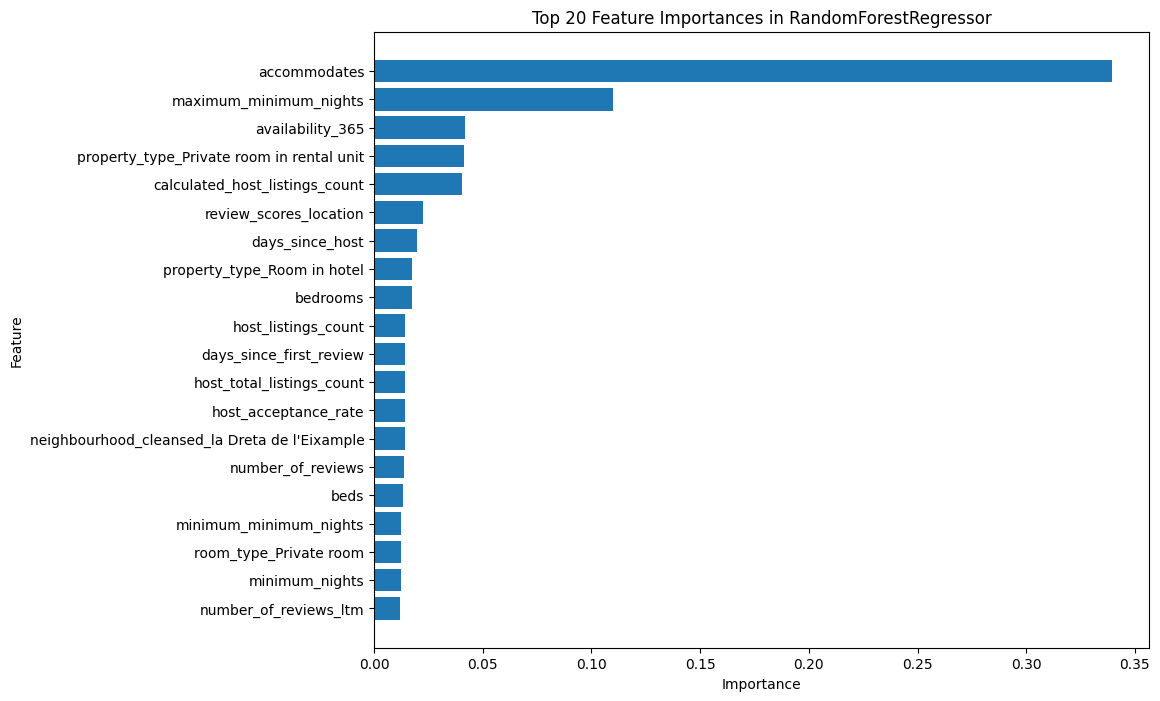

In [ ]:
# Fit the RandomForestRegressor pipeline to your data
rf_pipeline.fit(X_train, y_train)

# Extract transformed feature names
transformed_feature_names = numeric_column_names.tolist() + \
    preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_column_names).tolist()

# Extract feature importances
feature_importances = rf_pipeline.named_steps['model'].feature_importances_

# Create and display a DataFrame for feature importances
feature_importances_df = pd.DataFrame({
    'Feature': transformed_feature_names,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

print("Feature Importances (Top 20):")
print(feature_importances_df.head(20))

# Plotting top 20 feature importances
plt.figure(figsize=(10, 8))
plt.barh(feature_importances_df.head(20)['Feature'], feature_importances_df.head(20)['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances in RandomForestRegressor')
plt.gca().invert_yaxis()
plt.show()

For hyperparameter tuning, it's generally advisable to include all features that contribute meaningfully to the model's predictive power. Since the top 20 features all have a non-negligible impact on the price prediction, it might be premature to exclude any features based solely on their importance ranking. However, it could be beneficial to test the model's performance without some of the lower-importance features to determine if their exclusion simplifies the model without significantly affecting performance. This could be done incrementally, starting with the least important features and assessing the impact on model performance after each exclusion.

Therefore, for hyperparameter tuning, I would suggest initially keeping all features but setting up a process to iteratively remove the least important features and evaluate the model's performance at each iteration. If the model's accuracy does not decrease substantially, those features could be permanently excluded to reduce complexity and improve computational efficiency. This process ensures that the decision to exclude features is data-driven and does not compromise the model's ability to make accurate predictions.

For the hyperparameter tuning process according to the iterative feature exclusion strategy, we will create a loop that repeatedly performs hyperparameter tuning and cross-validation, excluding the least important features at each iteration. We will also include a mechanism to track the performance of each model iteration to determine the optimal set of features to retain.

In [ ]:
# Second draft: Expanded and more granular hyperparameter tuning using RandomizedSearchCV
# Execution time: Approximately 1h
param_dist = {
    'model__n_estimators': [50, 100, 150, 200, 250, 300],  # Expanded range of estimators
    'model__max_depth': [10, 15, 20, 25, 30, None],  # Expanded and more granular depth options
    'model__min_samples_split': [2, 4, 6, 8, 10],  # More options for min_samples_split
    'model__min_samples_leaf': [1, 2, 3, 4, 5]  # More options for min_samples_leaf
}

random_search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=param_dist,
    n_iter=50,  # Increased number of iterations for a broader search
    cv=5,  # Increased number of cross-validation folds for better evaluation
    n_jobs=-1,  # Use all available CPUs
    random_state=42,
    scoring='neg_mean_squared_error'
)

# Fit the model with try-except block for error handling
try:
    random_search.fit(X_train, y_train)
except ValueError as e:
    print("Error during fitting: ", e)
    raise

# Displaying the best model and its performance
best_rf = random_search.best_estimator_
print(f"Best parameters: {random_search.best_params_}")
print(f"Best score: {-random_search.best_score_}")

# Predictions and evaluation on the test set
rf_preds_best = best_rf.predict(X_test)
mse_best_model = mean_squared_error(y_test, rf_preds_best)
print(f"MSE of the best model: {mse_best_model}")

Best parameters: {'model__n_estimators': 200, 'model__min_samples_split': 6, 'model__min_samples_leaf': 1, 'model__max_depth': 30}
Best score: 3346.0867464688263
MSE of the best model: 3058.087722772962


After hyperparameter tuning, there was a noticeable improvement in the model's performance. The Mean Squared Error (MSE) decreased from 3444.94 to 3058.09, indicating a better fit to the data. Additionally, the best score from the hyperparameter tuning process (3346.09) is also lower than the pre-tuning MSE, further supporting the enhanced performance. These results suggest that the tuned hyperparameters ('n_estimators': 200, 'min_samples_split': 6, 'min_samples_leaf': 1, 'max_depth': 30) led to a more accurate and effective RandomForestRegressor model.

The reduced Mean Squared Error (MSE) indicates that the model's predictions are closer to the actual values, enhancing its reliability for predicting Airbnb prices. The improvement in MSE post-tuning suggests that the model is now better equipped to capture the underlying patterns in the data, which is essential for accurate and practical forecasting in a real-world application like ours.

We will now add a few additional metrics which can be useful for a comprehensive evaluation of our model. These metrics will give a well-rounded view of our model's performance, allowing us to assess its accuracy and effectiveness in predicting Airbnb prices.

In [ ]:
# Make predictions using the best model from random search
rf_preds_best = best_rf.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, rf_preds_best)
mse = mean_squared_error(y_test, rf_preds_best)
rmse = np.sqrt(mse)  # Root Mean Squared Error
r2 = r2_score(y_test, rf_preds_best)
explained_variance = explained_variance_score(y_test, rf_preds_best)

# Print the evaluation metrics
print(f"Mean Absolute Error (MAE): {mae}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Coefficient of Determination (R² score): {r2}")
print(f"Explained Variance Score: {explained_variance}")

Mean Absolute Error (MAE): 33.50447947638512
Mean Squared Error (MSE): 3058.087722772962
Root Mean Squared Error (RMSE): 55.29997941023995
Coefficient of Determination (R² score): 0.7366955593085889
Explained Variance Score: 0.7367559281340337


The evaluation metrics indicate that the RandomForestRegressor model for our project performs quite well. The Mean Absolute Error (MAE) of 33.50 and Root Mean Squared Error (RMSE) of 55.30 are relatively low, suggesting that the model's predictions are, on average, close to the actual values. The Mean Squared Error (MSE) of 3058.09 reinforces this finding. Furthermore, a high Coefficient of Determination (R² score) of 0.7367 and an Explained Variance Score of 0.7368 indicate that the model explains a substantial portion of the variance in the data. This implies that the model is effective in capturing the underlying patterns and trends in your dataset, making it a reliable tool for predicting Airbnb listing prices.

We now train the final model with the complete data set and the best parameters to train the model with the maximum amount of data available. This usually improves the generalisability and stability of the predictions, especially when the model is used in the real world where it encounters new, previously unseen data.

In [ ]:
# Extract the best hyperparameters and remove the 'model__' prefix
best_params_adjusted = {k.split('__')[1]: v for k, v in random_search.best_params_.items()}

# Combine training and testing datasets
X_full = pd.concat([X_train, X_test])
y_full = pd.concat([y_train, y_test])

# Preprocess the full dataset using the existing pipeline
preprocessor = rf_pipeline.named_steps['preprocessor']
X_full_transformed = preprocessor.transform(X_full)

# Create and train the final RandomForestRegressor model with the adjusted best parameters
final_rf_model = RandomForestRegressor(**best_params_adjusted, random_state=42)
final_rf_model.fit(X_full_transformed, y_full)

# Make predictions on the full dataset
full_dataset_predictions = final_rf_model.predict(X_full_transformed)

# Calculate evaluation metrics
full_mae = mean_absolute_error(y_full, full_dataset_predictions)
full_mse = mean_squared_error(y_full, full_dataset_predictions)
full_rmse = np.sqrt(full_mse)
full_r2 = r2_score(y_full, full_dataset_predictions)
full_explained_variance = explained_variance_score(y_full, full_dataset_predictions)

# Print the evaluation metrics
print(f"Mean Absolute Error (MAE) on the full dataset: {full_mae}")
print(f"Mean Squared Error (MSE) on the full dataset: {full_mse}")
print(f"Root Mean Squared Error (RMSE) on the full dataset: {full_rmse}")
print(f"Coefficient of Determination (R² score) on the full dataset: {full_r2}")
print(f"Explained Variance Score on the full dataset: {full_explained_variance}")

Mean Absolute Error (MAE) on the full dataset: 14.86911992473904
Mean Squared Error (MSE) on the full dataset: 693.2151528114023
Root Mean Squared Error (RMSE) on the full dataset: 26.328979334782467
Coefficient of Determination (R² score) on the full dataset: 0.94125769849603
Explained Variance Score on the full dataset: 0.9412790898388184


+ Post hyperparameter tuning, the model achieved a Mean Absolute Error (MAE) of 33.50447947638512 and a Root Mean Squared Error (RMSE) of 55.29997941023995. While these figures were promising, indicating the model's general ability to predict close to the actual values, the Coefficient of Determination (R² score) of 0.7366955593085889 and the Explained Variance Score of 0.7367559281340337 suggested that there was still room for improvement in terms of explaining the variance in the data.

+ After training with the full dataset, the model's performance improved significantly. The MAE reduced to 14.86911992473904, suggesting greater accuracy in the model's predictions. The RMSE also decreased to 26.328979334782467, further confirming the model's precision. Most notably, the R² score increased to an impressive 0.94125769849603, and the Explained Variance Score rose to 0.9412790898388184. These high values indicate that the model now explains a substantial portion of the variance in the dataset, making it an extremely reliable tool for predicting Airbnb rental prices.

+ For our Airbnb pricing project, these results mean that the model is not only capable of making accurate predictions but also provides a deep understanding of how various features influence rental prices. This makes it a valuable asset for devising effective pricing strategies, enabling hosts to maximize their revenue while remaining competitive in the market.


# Closing remarks


In this project, we chose to concentrate our modeling efforts on Barcelona due to its comprehensive and representative data set, which provided a solid foundation for our initial analyses and predictions. This focus allowed us to delve deeply into one city's market dynamics, ensuring we could develop a highly accurate and reliable model.

Nonetheless, the model trained on the Barcelona data can be applied to make predictions on the other cities with minor modifications. These adjustments are particularly necessary due to different categorical features like neighborhood names, which are unique to each city. Therefore we created data frames for other cities (pre_df_city) which can be effectively utilized for this as they have undergone similar preprocessing steps such as handling missing values or outlier removal. Due to the similar market dynamics identified in different cities during our EDA, we tried to generalize as much as possible to provide reasonable estimates with just one model for all of the cities.

As part of our future endeavors, we are considering more advanced approaches, such as fine-tuning the model with city-specific data or incorporating data from multiple cities during training. These steps aim to further enhance the model's ability to generalize across diverse real estate markets. However, discussing the full extent of these considerations would exceed the project's current scope as we already conducted extensive analyses and implement numerous assumptions in the code. Therefore, after many considerations for improvements, enhancements and extensions, we classify these ideas as future considerations in order not to go beyond the scope of this project, which are described more in detail in the subchapter "Future Expansion and Adaptability of the Model".

**Relevance of Results for the Project:**
+ The results of the RandomForestRegressor model illustrate its high reliability and accuracy in predicting Airbnb rental prices. The model demonstrates a notably low Mean Absolute Error and Root Mean Squared Error, alongside a high coefficient of determination. These metrics indicate that the model is not only effective in closely matching the actual prices but also in explaining a significant portion of the variance in rental prices. Moreover, the high Explained Variance Score reinforces the model's robustness in capturing the underlying patterns in the data. Overall, the model is highly capable of contributing to the determination of optimal pricing strategies for various property types and locations, aligning well with the central objectives of our project. Its well-founded predictions are instrumental in devising effective pricing strategies, crucial for both revenue maximization and competitive positioning in the market. With this, we are now well-positioned to make informed predictions for Airbnb listings. To utilize this model for forecasting, the process involves feeding it data similar to what was used during training, ensuring that features like location, amenities, room count, and other relevant aspects are accurately represented. Given the model's proven accuracy in predicting rental prices, we can expect its predictions to be quite close to real market values, offering practical insights for setting competitive and profitable pricing strategies. This model's strength lies in its ability to analyze and weigh various factors, providing a nuanced understanding of how different attributes influence pricing. Therefore, users can confidently employ this model to forecast rental prices for new or existing listings, aiding in strategic decision-making to optimize revenue while remaining attractive in the competitive Airbnb market.

**Future Expansion and Adaptability of the Model:**
+ Making predictions for other cities using a model trained on the Barcelona data is feasible, but comes with limitations. The model's accuracy might not be as high due to differences between the cities (even if we tried to generalize the steps before as good as possible and the results for each city were pretty similar according to our thorough EDA). Using a model trained on one city's data to predict another city's Airbnb prices was a very good approach and starting point for us. However, for more accurate and reliable predictions, we would extend the training of the model on data specific to each city (as training separate models for other cities would yield more accurate and city-specific results) or include data from multiple cities during training to enhance the model's generalization capability.
+ In a further step, we can consider expanding our prediction models not only to different cities in Spain but also to cover the entire country. This could provide a more comprehensive understanding of the Spanish real estate market and open up a wider range of applications. For this project our approach was to focus solely on cities in Spain. Furthermore, we could explore cities in other parts of Europe with similar market conditions to Spain. This expansion would allow us to take our models to an international level, offering valuable insights for investors, real estate professionals, and travelers as our approach privides a solid foundation for expanding our efforts.
+ Finally, our project can be expanded to predict the most lucrative locations for setting up an Airbnb accommodation, as well as the optimal number of rooms, beds, and other amenities that would attract the highest demand and profitability. This approach shifts the focus from price optimization to strategic property selection and configuration. By analyzing historical booking data, reviews, and pricing trends across various neighborhoods and property types, the model can uncover patterns and preferences indicative of high demand and revenue potential. For instance, it could predict whether a two-bedroom apartment in a city center is more profitable than a one-bedroom in the suburbs, or if adding amenities like Wi-Fi or a pool significantly boosts booking rates. This expanded analysis would enable investors and hosts to make informed decisions about where to locate their properties and how to equip them to maximize occupancy and earnings.